# Portfólio Consolidado de Análise de Dados
## Contendo todos os notebooks dos alunos
### Gerado em: 2026-11-09 22:41

## 1 - Webscraping

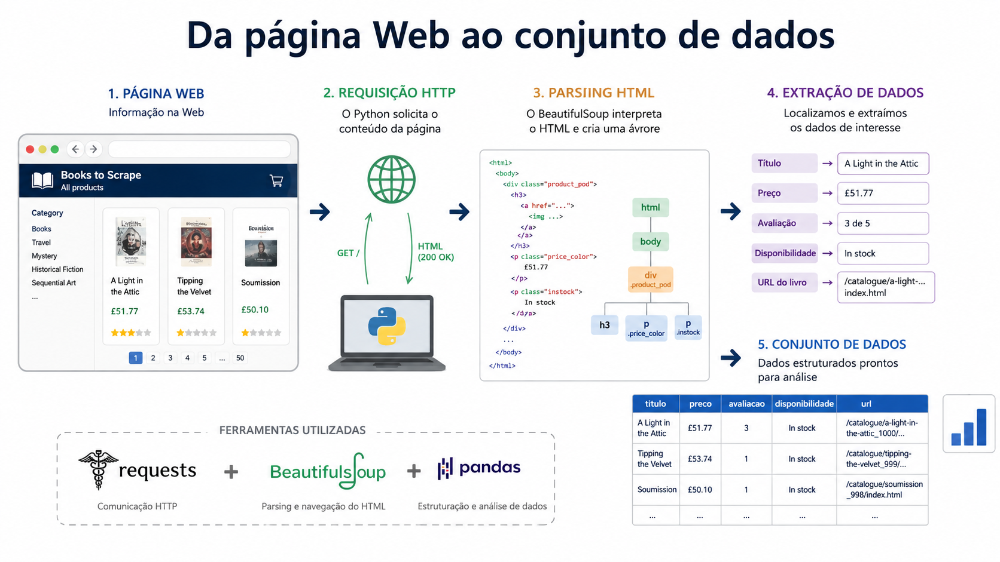

Nesta aula, vamos compreender como informações publicadas em páginas Web podem ser **requisitadas, interpretadas, localizadas, extraídas e estruturadas** com Python.

## 1. O que é Web Scraping?

**Web Scraping** é o processo automatizado de coleta de informações disponíveis em páginas Web.

Em termos computacionais, o processo envolve três operações principais:

1. **Aquisição:** obtenção do conteúdo da página por meio de uma requisição HTTP;
2. **Parsing:** interpretação da estrutura do documento HTML;
3. **Extração:** localização e transformação dos elementos de interesse em dados utilizáveis.

Um fluxo típico pode ser representado como:

```text
URL → Requisição HTTP → HTML → Parser → Elementos → Dados estruturados
```

### Exemplos de aplicação

- monitoramento de preços;
- coleta de notícias e documentos;
- criação de bases para análise de mercado;
- mineração de dados públicos;
- acompanhamento de indicadores;
- construção de datasets para pesquisa.

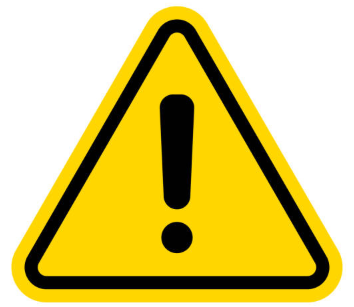
# Atenção - Evite práticas ilegais e antiéticas
#### Respeite as regras contidas do documento **Robots.txt**. 

A disponibilidade pública de uma página não implica autorização irrestrita para coleta automatizada. Termos de uso, limites de requisição, privacidade e legislação aplicável devem ser considerados.

O scraper deve seguir as regras estabelecidas no arquivo **robots.txt** do site e respeitar os termos de uso para evitar práticas ilegais ou antiéticas.

# 2. Fundamentos de HTML

## HTML: HyperText Markup Language

**HTML** é a linguagem de marcação utilizada para representar a estrutura de uma página Web.

- Geralmente contém três componentes
    - Tag de abertura;
    - Conteúdo;
    - Tag de fechamento
    
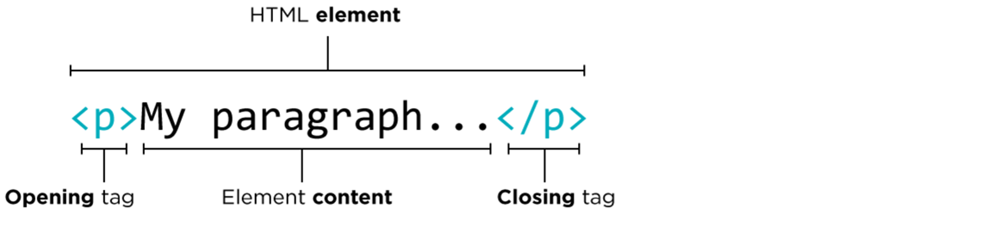

Tags de abertura também podem conter atributos:

```html
<tag atributo="valor">conteúdo</tag>
```

Exemplo:

```html
<p class="preco">R$ 89,90</p>
```

Neste elemento:

| Componente | Valor |
|---|---|
| Tag | `p` |
| Atributo | `class` |
| Valor do atributo | `preco` |
| Conteúdo textual | `R$ 89,90` |

Em tarefas de Web Scraping, esses componentes funcionam como **pistas para localizar a informação desejada**.

## Estrutura básica de um documento HTML

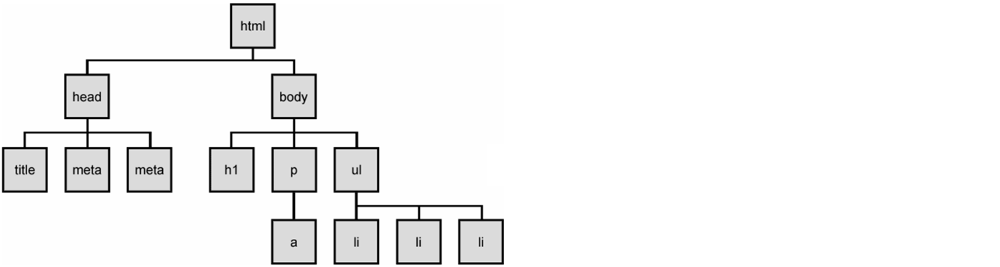

Exemplo codificado:

```html
<!DOCTYPE html>
<html>
    <head>
        <title>Minha página</title>
    </head>

    <body>
        <h1>Título principal</h1>
        <p>Um parágrafo.</p>
        <a href="https://exemplo.com">Um link</a>
    </body>
</html>
```

A estrutura HTML possui natureza **hierárquica**. Por isso, ela pode ser interpretada como uma árvore:

```text
html
├── head
│   └── title
└── body
    ├── h1
    ├── p
    └── a
```

Essa organização será importante quando utilizarmos `BeautifulSoup`.

## Algumas tags HTML frequentes

| Tag | Função típica |
|---|---|
| `<html>` | elemento raiz do documento |
| `<head>` | metadados e configurações |
| `<title>` | título da página |
| `<body>` | conteúdo visível principal |
| `<h1>` ... `<h6>` | títulos e subtítulos |
| `<p>` | parágrafo |
| `<a>` | hiperlink |
| `<img>` | imagem |
| `<div>` | agrupamento genérico |
| `<span>` | agrupamento inline |
| `<ul>` / `<ol>` | listas |
| `<li>` | item de lista |
| `<table>` | tabela |
| `<article>` | conteúdo independente |
| `<nav>` | navegação |

# 3. HTTP: comunicação entre cliente e servidor

**HTTP (Hypertext Transfer Protocol)** é o protocolo utilizado na comunicação entre clientes e servidores Web.

Quando digitamos uma URL no navegador, ocorre, de forma simplificada:

```text
Cliente                          Servidor
   │                                │
   │ -------- HTTP GET -----------> │
   │                                │
   │ <----- HTTP Response --------- │
   │        status + conteúdo       │
```

Em Python, a biblioteca `requests` pode assumir o papel do cliente.

## Métodos HTTP

Alguns métodos HTTP importantes:

| Método | Finalidade geral |
|---|---|
| `GET` | solicitar um recurso |
| `POST` | enviar dados para processamento |
| `PUT` | substituir ou atualizar um recurso |
| `PATCH` | atualizar parcialmente um recurso |
| `DELETE` | solicitar remoção de um recurso |

Nesta aula utilizaremos principalmente **GET**, pois nosso objetivo é solicitar páginas HTML.

## Códigos de status HTTP

Uma resposta HTTP possui um código de status.

| Faixa | Categoria | Exemplo |
|---|---|---|
| `1xx` | Informacional | processamento em andamento |
| `2xx` | Sucesso | `200 OK` |
| `3xx` | Redirecionamento | `301 Moved Permanently` |
| `4xx` | Erro do cliente | `404 Not Found` |
| `5xx` | Erro do servidor | `500 Internal Server Error` |

Para Web Scraping, um `200` normalmente indica que a requisição foi atendida com sucesso.

# 4. Web Scraping não é API

É importante diferenciar duas formas de obter dados de um sistema Web.

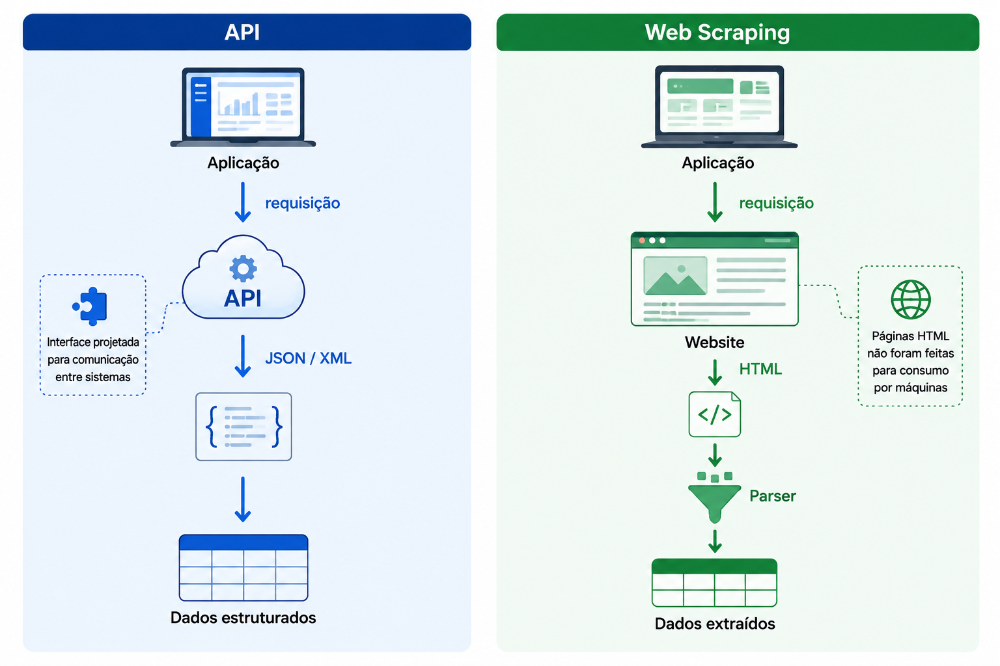

Em tarefas de Web Scraping, os dados precisam ser identificados dentro da estrutura destinada originalmente à apresentação da página.

## Páginas estáticas e páginas dinâmicas

Um ponto fundamental:

```python
requests.get(url)
```

obtém o conteúdo retornado pelo servidor na resposta HTTP.

Entretanto, alguns websites carregam parte dos dados **posteriormente com JavaScript**.

```text
HTML inicial
    │
    ├── conteúdo disponível imediatamente
    │
    └── JavaScript
           │
           └── novas requisições / conteúdo dinâmico
```

Nesses casos, o conteúdo visível no navegador pode não estar presente no HTML obtido diretamente com `requests`.

Ferramentas como **Selenium** e **Playwright** podem ser utilizadas em cenários mais complexos, mas não são necessárias para a prática desta aula.

# 5. Preparando o ambiente

Nesta aula utilizaremos:

- `requests`: comunicação HTTP;
- `BeautifulSoup`: parsing e navegação HTML;
- `re`: expressões regulares;
- `pandas`: estruturação dos dados;
- `urllib.parse`: construção segura de URLs.

In [1]:
# Execute somente se as bibliotecas ainda não estiverem instaladas.
# %pip install requests beautifulsoup4 pandas

In [2]:
import re
import requests
import pandas as pd

from bs4 import BeautifulSoup
from urllib.parse import urljoin

# 6. Primeiro contato com BeautifulSoup: HTML controlado

Antes de trabalhar com um website real, utilizaremos um pequeno documento HTML criado especificamente para a aula.

Essa estratégia permite aprender os comandos do `BeautifulSoup` sem a complexidade adicional de páginas reais.

In [3]:
html = '''
<html>
    <head>
        <title>Livraria Exemplo</title>
    </head>

    <body>
        <h1>Catálogo de livros</h1>

        <div class="produto" data-categoria="programacao">
            <h2>Python para Dados</h2>
            <p class="preco">R$ 89,90</p>
            <p class="estoque">Disponível</p>
            <a href="/python">Detalhes</a>
        </div>

        <div class="produto" data-categoria="ia">
            <h2>Machine Learning</h2>
            <p class="preco">R$ 120,00</p>
            <p class="estoque">Disponível</p>
            <a href="/machine-learning">Detalhes</a>
        </div>
    </body>
</html>
'''

## Realizando o parsing

O **parsing** transforma o texto HTML em uma estrutura que pode ser navegada programaticamente.

In [4]:
soup = BeautifulSoup(html, "html.parser")

In [5]:
print(soup.prettify())

<html>
 <head>
  <title>
   Livraria Exemplo
  </title>
 </head>
 <body>
  <h1>
   Catálogo de livros
  </h1>
  <div class="produto" data-categoria="programacao">
   <h2>
    Python para Dados
   </h2>
   <p class="preco">
    R$ 89,90
   </p>
   <p class="estoque">
    Disponível
   </p>
   <a href="/python">
    Detalhes
   </a>
  </div>
  <div class="produto" data-categoria="ia">
   <h2>
    Machine Learning
   </h2>
   <p class="preco">
    R$ 120,00
   </p>
   <p class="estoque">
    Disponível
   </p>
   <a href="/machine-learning">
    Detalhes
   </a>
  </div>
 </body>
</html>



## 6.1 `find()`: localizar a primeira ocorrência

O método `find()` retorna o **primeiro elemento** que corresponde ao critério informado.

In [6]:
soup.find("h1")

<h1>Catálogo de livros</h1>

In [7]:
titulo = soup.find("h1")
print(titulo.text)

Catálogo de livros


### A propriedade `.text`

O objeto retornado pelo `BeautifulSoup` contém a tag completa.

```html
<h1>Catálogo de livros</h1>
```

Quando queremos apenas seu conteúdo textual:

```python
elemento.text
```

ou, preferencialmente quando há espaços e quebras de linha:

```python
elemento.get_text(strip=True)
```

In [8]:
titulo.get_text(strip=True)

'Catálogo de livros'

## 6.2 `find_all()`: localizar todas as ocorrências

Enquanto `find()` retorna uma ocorrência, `find_all()` retorna uma coleção de elementos.

In [9]:
produtos = soup.find_all("div")
produtos

[<div class="produto" data-categoria="programacao">
 <h2>Python para Dados</h2>
 <p class="preco">R$ 89,90</p>
 <p class="estoque">Disponível</p>
 <a href="/python">Detalhes</a>
 </div>,
 <div class="produto" data-categoria="ia">
 <h2>Machine Learning</h2>
 <p class="preco">R$ 120,00</p>
 <p class="estoque">Disponível</p>
 <a href="/machine-learning">Detalhes</a>
 </div>]

In [10]:
print("Quantidade de produtos:", len(produtos))

Quantidade de produtos: 2


## 6.3 Localizando elementos por classe

O atributo HTML `class` é muito utilizado para identificar grupos de elementos.

No `BeautifulSoup`, podemos utilizar:

```python
class_="nome_da_classe"
```

O caractere `_` é necessário porque `class` é uma palavra reservada da linguagem Python.

In [11]:
precos = soup.find_all("p", class_="preco")

for preco in precos:
    print(preco.get_text(strip=True))

R$ 89,90
R$ 120,00


## 6.4 Localizando elementos por atributos

Também podemos pesquisar elementos por outros atributos.

In [12]:
produto_ia = soup.find(
    "div",
    attrs={"data-categoria": "ia"}
)

produto_ia

<div class="produto" data-categoria="ia">
<h2>Machine Learning</h2>
<p class="preco">R$ 120,00</p>
<p class="estoque">Disponível</p>
<a href="/machine-learning">Detalhes</a>
</div>

## 6.5 Extraindo atributos

Considere:

```html
<a href="/python">Detalhes</a>
```

O texto é `Detalhes`, enquanto o destino do link está no atributo `href`.

In [13]:
link = soup.find("a")

print("Texto:", link.get_text(strip=True))
print("href:", link["href"])

Texto: Detalhes
href: /python


Uma alternativa mais segura para atributos opcionais é utilizar `.get()`:

In [14]:
link.get("href")

'/python'

## 6.6 Localização por texto

Também é possível localizar elementos por conteúdo textual.

In [15]:
soup.find("h2", string="Machine Learning")

<h2>Machine Learning</h2>

Quando não conhecemos exatamente o texto, expressões regulares podem ser úteis.

In [16]:
# Esse trecho introduz expressões regulares (Regular Expressions ou Regex) como critério de busca dentro do BeautifulSoup.
# Encontre a primeira tag <h2> cujo conteúdo textual corresponda ao padrão "machine", ignorando diferenças entre letras maiúsculas e minúsculas.
soup.find("h2", string=re.compile("machine", re.IGNORECASE))

<h2>Machine Learning</h2>

# 7. Navegando pela árvore HTML

Como o HTML possui estrutura hierárquica, um elemento pode ter:

- **pai** (`parent`);
- **filhos** (`children` ou `contents`);
- elementos anteriores e posteriores.

Considere o primeiro produto:

In [17]:
primeiro_produto = soup.find("div", class_="produto")
primeiro_produto

<div class="produto" data-categoria="programacao">
<h2>Python para Dados</h2>
<p class="preco">R$ 89,90</p>
<p class="estoque">Disponível</p>
<a href="/python">Detalhes</a>
</div>

In [18]:
# Elemento pai
primeiro_produto.parent.name

'body'

In [19]:
# contents inclui os filhos imediatos, inclusive nós de texto
primeiro_produto.contents

['\n',
 <h2>Python para Dados</h2>,
 '\n',
 <p class="preco">R$ 89,90</p>,
 '\n',
 <p class="estoque">Disponível</p>,
 '\n',
 <a href="/python">Detalhes</a>,
 '\n']

In [20]:
primeiro_produto.contents[1]

<h2>Python para Dados</h2>

In [21]:
# Filhos diretos
list(primeiro_produto.children)

['\n',
 <h2>Python para Dados</h2>,
 '\n',
 <p class="preco">R$ 89,90</p>,
 '\n',
 <p class="estoque">Disponível</p>,
 '\n',
 <a href="/python">Detalhes</a>,
 '\n']

In [22]:
for filho in primeiro_produto.children:
    print(filho)



<h2>Python para Dados</h2>


<p class="preco">R$ 89,90</p>


<p class="estoque">Disponível</p>


<a href="/python">Detalhes</a>




> **Observação:** `children` e `contents` acessam os filhos imediatos, incluindo tags e nós de texto. A diferença é que contents retorna uma lista, enquanto children fornece um iterador.

# 8. Seletores CSS

O `BeautifulSoup` também permite utilizar seletores CSS.

**CSS (Cascading Style Sheets)** é a linguagem utilizada para definir a **aparência e o layout dos elementos HTML** de uma página, como cores, fontes, tamanhos e posicionamento.

Um seletor **CSS** é uma expressão utilizada para identificar quais **elementos HTML receberão determinado estilo**. Em tarefas de Web Scraping, podemos reutilizar esses seletores para localizar elementos na página.

Essa abordagem é útil porque o mesmo raciocínio empregado no inspetor do navegador pode ser utilizado no Python.

Exemplos:

```css
div.produto
div.produto h2
p.preco
a
```

In [23]:
soup.select("div.produto")

[<div class="produto" data-categoria="programacao">
 <h2>Python para Dados</h2>
 <p class="preco">R$ 89,90</p>
 <p class="estoque">Disponível</p>
 <a href="/python">Detalhes</a>
 </div>,
 <div class="produto" data-categoria="ia">
 <h2>Machine Learning</h2>
 <p class="preco">R$ 120,00</p>
 <p class="estoque">Disponível</p>
 <a href="/machine-learning">Detalhes</a>
 </div>]

In [24]:
soup.select("div.produto h2")

[<h2>Python para Dados</h2>, <h2>Machine Learning</h2>]

In [25]:
# select_one retorna apenas o primeiro
soup.select_one("div.produto h2").get_text(strip=True)

'Python para Dados'

In [26]:
# [0]   # primeiro
# [1]   # segundo
# [-1]  # último
# [-2]  # penúltimo
soup.select("div.produto h2")[-1].get_text(strip=True)

'Machine Learning'

In [27]:
titulos = soup.select("div.produto h2")
for titulo in titulos:
    print(titulo.get_text(strip=True))

Python para Dados
Machine Learning


In [28]:
# Essa estrutura é chamada de List Comprehension
[titulo.get_text(strip=True) for titulo in soup.select("div.produto h2")]

['Python para Dados', 'Machine Learning']

## `find()` ou `select()`?

As duas abordagens podem resolver problemas semelhantes.

| BeautifulSoup | CSS Selector |
|---|---|
| `find("h2")` | `select_one("h2")` |
| `find_all("h2")` | `select("h2")` |
| `find_all("div", class_="produto")` | `select("div.produto")` |

Não existe necessidade de escolher uma única abordagem. O importante é utilizar seletores claros e suficientemente estáveis.

# 9. Mão na massa: um website real

Agora aplicaremos os conceitos em um ambiente criado especificamente para treinamento de Web Scraping:

**Books to Scrape**  
`https://books.toscrape.com/`

O site contém livros fictícios, categorias, preços, avaliações e paginação. Isso permite trabalhar com uma página real, mas com estrutura relativamente previsível.

> O próprio site informa que foi criado para demonstração de Web Scraping.

## 9.1 Realizando a requisição HTTP

Observe a separação de responsabilidades:

```text
requests      → obtém a resposta HTTP
BeautifulSoup → interpreta o HTML
pandas        → estrutura os dados
```

In [29]:
url = "https://books.toscrape.com/"

response = requests.get(url, timeout=10)

print("Status:", response.status_code)
print("URL final:", response.url)
print("Content-Type:", response.headers.get("Content-Type"))

Status: 200
URL final: https://books.toscrape.com/
Content-Type: text/html


## 9.2 `response.text` versus `response.content`

- `response.text`: conteúdo convertido para `str`;
- `response.content`: conteúdo bruto em `bytes`.

Para analisar HTML com `BeautifulSoup`, `response.text` é suficiente na maioria dos exemplos introdutórios.

In [30]:
print(response.text[:1000])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" />
        <meta name="created" content="24th Jun 2016 09:29" />
        <meta name="description" content="" />
        <meta name="viewport" content="width=device-width" />
        <meta name="robots" content="NOARCHIVE,NOCACHE" />

        <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
        <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->

        
            <link rel="shortcut icon" href="static/oscar/favicon.

Evite imprimir todo o HTML de páginas extensas. Mostrar apenas uma amostra facilita a inspeção.

## 9.3 Interpretando o HTML com BeautifulSoup

In [31]:
soup = BeautifulSoup(response.text, "html.parser")

In [32]:
print(soup.prettify()[:2000])

<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!-->
<html class="no-js" lang="en-us">
 <!--<![endif]-->
 <head>
  <title>
   All products | Books to Scrape - Sandbox
  </title>
  <meta content="text/html; charset=utf-8" http-equiv="content-type"/>
  <meta content="24th Jun 2016 09:29" name="created"/>
  <meta content="" name="description"/>
  <meta content="width=device-width" name="viewport"/>
  <meta content="NOARCHIVE,NOCACHE" name="robots"/>
  <!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
  <!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->
  <link href="static/oscar/favicon.ico" rel="shortcut icon"/>
  <link href="static/oscar/css/styles.css" rel="stylesheet" type="tex

## 9.4 Extraindo informações simples

In [33]:
print("Título da página:", soup.title.get_text(strip=True))

Título da página: All products | Books to Scrape - Sandbox


# 10. Identificando a unidade de análise

Ao inspecionar a página, observamos que cada livro está contido em um elemento:

```html
<article class="product_pod">
    ...
</article>
```

Isso é importante porque define nossa **unidade de análise**:

> uma ocorrência de `article.product_pod` corresponde a um livro.

In [34]:
livro = soup.find("article", class_="product_pod")

print(livro.prettify())

<article class="product_pod">
 <div class="image_container">
  <a href="catalogue/a-light-in-the-attic_1000/index.html">
   <img alt="A Light in the Attic" class="thumbnail" src="media/cache/2c/da/2cdad67c44b002e7ead0cc35693c0e8b.jpg"/>
  </a>
 </div>
 <p class="star-rating Three">
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
  <i class="icon-star">
  </i>
 </p>
 <h3>
  <a href="catalogue/a-light-in-the-attic_1000/index.html" title="A Light in the Attic">
   A Light in the ...
  </a>
 </h3>
 <div class="product_price">
  <p class="price_color">
   Â£51.77
  </p>
  <p class="instock availability">
   <i class="icon-ok">
   </i>
   In stock
  </p>
  <form>
   <button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">
    Add to basket
   </button>
  </form>
 </div>
</article>



## 10.1 Extraindo o título de um livro

O título está armazenado no atributo `title` do link interno ao elemento `<h3>`.

In [35]:
link_titulo = livro.find("h3").find("a")

titulo = link_titulo.get("title")

print(titulo)

A Light in the Attic


## 10.2 Extraindo o preço

In [36]:
preco = livro.find("p", class_="price_color").get_text(strip=True)

print(preco)

Â£51.77


## 10.3 Extraindo a disponibilidade

In [37]:
disponibilidade = livro.find("p", class_="instock availability").get_text(strip=True)

print(disponibilidade)

In stock


## 10.4 Extraindo o link

O link apresentado no HTML é relativo. Para obter uma URL completa, utilizaremos `urljoin()`.

In [38]:
href = link_titulo.get("href")

url_livro = urljoin(url, href)

print("href:", href)
print("URL completa:", url_livro)

href: catalogue/a-light-in-the-attic_1000/index.html
URL completa: https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html


## 10.5 Extraindo a avaliação

A avaliação está codificada por meio de classes HTML.

Um elemento pode aparecer, por exemplo, como:

```html
<p class="star-rating Three">
```

Nesse caso, uma das classes indica a quantidade de estrelas.

In [39]:
rating_tag = livro.find("p", class_="star-rating")

print(rating_tag.get("class"))

['star-rating', 'Three']


## 10.6 Reunindo os atributos de um único livro

In [41]:
registro = {
    "titulo": titulo,
    "preco": preco,
    "avaliacao": rating_tag,
    "disponibilidade": disponibilidade,
    "url": url_livro
}

registro

{'titulo': 'A Light in the Attic',
 'preco': 'Â£51.77',
 'avaliacao': <p class="star-rating Three">
 <i class="icon-star"></i>
 <i class="icon-star"></i>
 <i class="icon-star"></i>
 <i class="icon-star"></i>
 <i class="icon-star"></i>
 </p>,
 'disponibilidade': 'In stock',
 'url': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html'}

# 11. De um elemento para vários registros

Agora substituímos:

```python
find(...)
```

por:

```python
find_all(...)
```

para localizar todos os livros da página.

In [42]:
livros = soup.find_all("article", class_="product_pod")

print("Quantidade encontrada:", len(livros))

Quantidade encontrada: 20


## Extraindo todos os livros da página

A estratégia será:

```text
para cada livro:
    localizar título
    localizar preço
    localizar avaliação
    localizar disponibilidade
    localizar URL
    armazenar registro
```

In [44]:
dados = []

mapa_estrelas = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

for livro in livros:
    link_titulo = livro.find("h3").find("a")

    titulo = link_titulo.get("title")
    preco = livro.find("p", class_="price_color").get_text(strip=True)
    disponibilidade = livro.find(
        "p",
        class_="instock availability"
    ).get_text(strip=True)

    href = link_titulo.get("href")
    url_livro = urljoin(url, href)

    rating_tag = livro.find("p", class_="star-rating")
    classes = rating_tag.get("class", [])

    avaliacao = next(
        (mapa_estrelas[c] for c in classes if c in mapa_estrelas),
        None
    )

    dados.append({
        "titulo": titulo,
        "preco": preco,
        "avaliacao": avaliacao,
        "disponibilidade": disponibilidade,
        "url": url_livro
    })

len(dados)

20

# 12. Transformando os dados em um DataFrame

A partir deste ponto deixamos de trabalhar apenas com elementos HTML e passamos a trabalhar com uma estrutura típica de análise de dados.

In [45]:
df = pd.DataFrame(dados)
df

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,Â£22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,Â£52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


In [46]:
df.shape

(20, 5)

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   titulo           20 non-null     object
 1   preco            20 non-null     object
 2   avaliacao        20 non-null     int64 
 3   disponibilidade  20 non-null     object
 4   url              20 non-null     object
dtypes: int64(1), object(4)
memory usage: 932.0+ bytes


## 12.1 Limpeza básica do preço

O preço foi extraído como texto, por exemplo:

```text
£51.77
```

Para análise numérica, removeremos o símbolo monetário e converteremos a coluna para `float`.

In [48]:
df["preco"] = (df["preco"].str.replace(r"[^\d.]", "", regex=True).astype(float))
df

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


Agora já podemos realizar operações analíticas simples.

In [49]:
df["preco"].describe()

count    20.000000
mean     38.048500
std      15.135231
min      13.990000
25%      22.637500
50%      41.380000
75%      51.865000
max      57.250000
Name: preco, dtype: float64

In [50]:
df["avaliacao"].value_counts().sort_index()

avaliacao
1    6
2    3
3    3
4    4
5    4
Name: count, dtype: int64

# 13. Melhorando o código: criando uma função

Quando uma operação será repetida, encapsular a lógica em uma função melhora:

- legibilidade;
- reutilização;
- manutenção;
- testabilidade.

In [51]:
def extrair_livros(soup, url_base):
    mapa_estrelas = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4,
        "Five": 5
    }

    registros = []

    for livro in soup.find_all("article", class_="product_pod"):
        link_titulo = livro.find("h3").find("a")

        titulo = link_titulo.get("title")
        preco = livro.find("p", class_="price_color").get_text(strip=True)
        disponibilidade = livro.find(
            "p",
            class_="instock availability"
        ).get_text(strip=True)

        href = link_titulo.get("href")
        url_livro = urljoin(url_base, href)

        rating_tag = livro.find("p", class_="star-rating")
        classes = rating_tag.get("class", [])

        avaliacao = next(
            (mapa_estrelas[c] for c in classes if c in mapa_estrelas),
            None
        )

        registros.append({
            "titulo": titulo,
            "preco": preco,
            "avaliacao": avaliacao,
            "disponibilidade": disponibilidade,
            "url": url_livro
        })

    return registros

In [52]:
registros = extrair_livros(soup, url)

pd.DataFrame(registros).head()

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


# 14. Tratamento básico de erros

Em aplicações reais, requisições podem falhar por:

- indisponibilidade do servidor;
- timeout;
- problemas de conexão;
- códigos HTTP de erro;
- alterações na estrutura da página.

Evite utilizar `except:` de forma genérica. Capture exceções compatíveis com o problema que está sendo tratado.

In [53]:
def obter_soup(url, timeout=10):
    try:
        response = requests.get(url, timeout=timeout)
        response.raise_for_status()
        return BeautifulSoup(response.text, "html.parser")

    except requests.exceptions.RequestException as erro:
        print(f"Falha ao acessar {url}: {erro}")
        return None

In [54]:
soup_teste = obter_soup("https://books.toscrape.com/")

if soup_teste is not None:
    print(soup_teste.title.get_text(strip=True))

All products | Books to Scrape - Sandbox


# 15. Introdução à paginação

A primeira página contém apenas uma parte do catálogo.

No rodapé da página existe um link para a próxima página.

A lógica de paginação pode ser representada como:

```text
Página 1
   │
   └── next ──► Página 2
                    │
                    └── next ──► Página 3
                                      │
                                      └── ...
```

Uma estratégia robusta é seguir o link `next` até que ele deixe de existir.

In [55]:
proxima = soup.select_one("li.next a")

if proxima is not None:
    print("href:", proxima.get("href"))
    print("URL completa:", urljoin(url, proxima.get("href")))

href: catalogue/page-2.html
URL completa: https://books.toscrape.com/catalogue/page-2.html


## Função para percorrer múltiplas páginas

A célula abaixo demonstra o padrão. Para não realizar dezenas de requisições acidentalmente durante a aula, usamos o parâmetro `max_paginas`.

In [56]:
def coletar_catalogo(url_inicial, max_paginas=3):
    url_atual = url_inicial
    todos_os_registros = []
    pagina = 1

    while url_atual and pagina <= max_paginas:
        print(f"Coletando página {pagina}: {url_atual}")

        soup_pagina = obter_soup(url_atual)

        if soup_pagina is None:
            break

        todos_os_registros.extend(
            extrair_livros(soup_pagina, url_atual)
        )

        link_proxima = soup_pagina.select_one("li.next a")

        if link_proxima is None:
            url_atual = None
        else:
            url_atual = urljoin(
                url_atual,
                link_proxima.get("href")
            )

        pagina += 1

    return pd.DataFrame(todos_os_registros)

In [57]:
# Exemplo: coletar somente as três primeiras páginas.
# Altere max_paginas apenas quando desejar ampliar a coleta.

df_catalogo = coletar_catalogo(
    "https://books.toscrape.com/",
    max_paginas=3
)

df_catalogo.shape

Coletando página 1: https://books.toscrape.com/
Coletando página 2: https://books.toscrape.com/catalogue/page-2.html
Coletando página 3: https://books.toscrape.com/catalogue/page-3.html


(60, 5)

In [58]:
df_catalogo

,titulo,preco,avaliacao,disponibilidade,url
0,A Light in the Attic,Â£51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...
5,The Requiem Red,Â£22.65,1,In stock,https://books.toscrape.com/catalogue/the-requi...
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,4,In stock,https://books.toscrape.com/catalogue/the-dirty...
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,3,In stock,https://books.toscrape.com/catalogue/the-comin...
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,4,In stock,https://books.toscrape.com/catalogue/the-boys-...
9,The Black Maria,Â£52.15,1,In stock,https://books.toscrape.com/catalogue/the-black...


# 16. O que pode dar errado em um Web Scraping?

Um script de scraping não deve ser considerado permanente.

Ele depende da estrutura da página.

Se o website alterar:

```html
<p class="price_color">
```

para:

```html
<span class="product-price">
```

um seletor como:

```python
soup.find("p", class_="price_color")
```

pode deixar de funcionar.

Por isso, uma solução de Web Scraping deve considerar:

- mudanças de layout;
- valores ausentes;
- elementos opcionais;
- códigos HTTP;
- redirecionamentos;
- limites de requisição;
- páginas dinâmicas;
- autenticação;
- bloqueios;
- aspectos legais e éticos.

## Boas práticas introdutórias

1. Verifique se existe uma **API oficial** antes de utilizar scraping.
2. Consulte os **termos de uso** do website.
3. Verifique o arquivo `robots.txt` quando pertinente.
4. Evite uma frequência excessiva de requisições.
5. Utilize `timeout`.
6. Trate falhas HTTP.
7. Não dependa de seletores excessivamente específicos.
8. Valide a quantidade e a qualidade dos dados extraídos.
9. Documente a data, a URL e a estratégia de coleta.
10. Considere que a estrutura do site pode mudar.

# Exemplo com site real

In [61]:
response = requests.get('https://www.cps.sp.gov.br/')

In [62]:
soup = BeautifulSoup(response.content, 'html.parser') # html.parser serve para ler o arquivo HTML que será visualizado em BeautifulSoup

In [63]:
print(soup)
#print(soup.prettify())


<!DOCTYPE html>

<html lang="pt-BR">
<head>
<meta charset="utf-8"/>
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<link href="#" id="dynamicCSS" rel="stylesheet" type="text/css"/>
<meta content="on" http-equiv="x-dns-prefetch-control"/><meta content="index, follow, max-image-preview:large, max-snippet:-1, max-video-preview:-1" name="robots">
<!-- This site is optimized with the Yoast SEO plugin v28.2 - https://yoast.com/product/yoast-seo-wordpress/ -->
<title>Centro Paula Souza | Competência em Educação Pública Profissional</title><link as="image" data-rocket-preload="" fetchpriority="high" href="https://bkpsitecpsnew.blob.core.windows.net/uploadsitecps/sites/1/2026/07/banner-periodo-eleitoral-scaled.jpg" rel="preload"/>
<meta content="Confira as últimas notícias do Centro Paula Souza: projetos criados pelos alunos, vestibular, datas de eventos, premiações e muito mais." name="description">
<link href="https://www.cps.sp.gov.br/" rel="canonical">
<meta content=

In [64]:
print(soup.title)
#print(soup.title.text)

<title>Centro Paula Souza | Competência em Educação Pública Profissional</title>


In [65]:
print(soup.find('title'))
#print(soup.find('title').text)

<title>Centro Paula Souza | Competência em Educação Pública Profissional</title>


In [66]:
print(soup.find('p'))
#print(soup.find('p').text)

<p class="govsp-social">/governosp</p>


In [67]:
# Dica: use o comando inspecionar página (function+F12)
barra_nav = soup.find('nav', attrs={'class': 'main-menu-container menu-mobile-inativo'})
print(barra_nav)

<nav class="main-menu-container menu-mobile-inativo" role="navigation">
<i class="fas fa-times" id="fecha-menu"></i>
<ul class="menu" id="menu-menu-principal"><li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542"><a>Institucional</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80543" id="menu-item-80543"><a>Centro Paula Souza</a><ul class="sub-menu"><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116316" id="menu-item-116316"><a href="https://www.cps.sp.gov.br/institucional/sobre-o-centro-paula-souza/">Funções e Competências</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116323" id="menu-item-116323"><a href="https://www.cps.sp.gov.br/institucional/organograma/">Organograma</a></li><li class="menu-

In [68]:
menu = barra_nav.find('ul', attrs={'class': 'menu'})
print(menu)

<ul class="menu" id="menu-menu-principal"><li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542"><a>Institucional</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80543" id="menu-item-80543"><a>Centro Paula Souza</a><ul class="sub-menu"><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116316" id="menu-item-116316"><a href="https://www.cps.sp.gov.br/institucional/sobre-o-centro-paula-souza/">Funções e Competências</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116323" id="menu-item-116323"><a href="https://www.cps.sp.gov.br/institucional/organograma/">Organograma</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116324" id="menu-item-116324"><a href="https://www.cps.

In [69]:
pos = menu.find('li', attrs={'id': 'menu-item-80637'})
print(pos)

<li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80637" id="menu-item-80637"><a>Pós-Graduação</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80638" id="menu-item-80638"><a>Stricto Sensu</a><ul class="sub-menu"><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80640" id="menu-item-80640"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a></li><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80641" id="menu-item-80641"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/" target="_blank">Mestrado Profissional em Gestão

In [70]:
# Listar links
link = pos.find('a') # O método .find extrai somente o primeiro item
print(link)

<a>Pós-Graduação</a>


In [74]:
links = pos.find_all('a') # O método .find_all extrai todos os itens
print(links)

[<a>Pós-Graduação</a>, <a>Stricto Sensu</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/" target="_blank">Mestrado Profissional em Gestão e Desenvolvimento da Educação Profissional</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/doutorado-profissional-em-gestao-e-desenvolvimento-da-educacao-tecnologica/" target="_blank">Doutorado Profissional em Gestão e Desenvolvimento da Educação Tecnológica</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/aluno-especial-do-mestrado/" target="_blank">Aluno Especial do Mestrado</a>, <a>Lato Sensu</a>, <a href="https://pos.cps.sp.gov.br/cursos-pos/mba-em-gestao-de-projetos-e-processos-organizacionais-mgp/" target="_blank">MBA em Gestão de Projetos e Processos Organizaci

In [75]:
len(links)# Contar quantos links foram listados

11

In [76]:
print(links[2].text)# Podemos visualizar os links pelo índice de armazenamento

Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos


In [77]:
# Visualizar atributos
print(links[2].attrs)

{'target': '_blank', 'href': 'https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/'}


In [78]:
#  Extrair atributos específicos
print(links[2]['href'])

https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/


In [79]:
# Extrair uma lista de atributos
for i in links:
    try:
        print(i['href'])
    except:
        print(i.text)

Pós-Graduação
Stricto Sensu
https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/
https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/
https://pos.cps.sp.gov.br/cursos-pos/doutorado-profissional-em-gestao-e-desenvolvimento-da-educacao-tecnologica/
https://pos.cps.sp.gov.br/cursos-pos/aluno-especial-do-mestrado/
Lato Sensu
https://pos.cps.sp.gov.br/cursos-pos/mba-em-gestao-de-projetos-e-processos-organizacionais-mgp/
https://pos.cps.sp.gov.br/cursos-pos/mba-em-engenharia-e-negocios-mbe/
https://pos.cps.sp.gov.br/cursos-pos/mba-em-tecnologia-e-inovacao-mbt/
https://pos.cps.sp.gov.br/cursos-pos/mba-em-gestao-de-design-mbd/


### Regras para encontrar elemento no BeautifulSoup
Neste exemplo, vamos explorar outras regras para encontrar elementos (.find)
- por classe
- por id
- por atributos
- por textos
- por pedaços de texto

###  Encontrar elemento por atributo
.find(nome do atributo = dados do atributo)

In [80]:
# Encontrar por classe
# Atenção ao atributo class, pois é uma palavra reservado do Python. Neste caso usa-se class_ (com underline)
barra_nav2 = soup.find(class_ = 'main-menu-container menu-mobile-inativo')
print(barra_nav2)

<nav class="main-menu-container menu-mobile-inativo" role="navigation">
<i class="fas fa-times" id="fecha-menu"></i>
<ul class="menu" id="menu-menu-principal"><li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80542" id="menu-item-80542"><a>Institucional</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80543" id="menu-item-80543"><a>Centro Paula Souza</a><ul class="sub-menu"><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116316" id="menu-item-116316"><a href="https://www.cps.sp.gov.br/institucional/sobre-o-centro-paula-souza/">Funções e Competências</a></li><li class="menu-item menu-item-type-post_type menu-item-object-page menu-item-116323" id="menu-item-116323"><a href="https://www.cps.sp.gov.br/institucional/organograma/">Organograma</a></li><li class="menu-

In [81]:
# Encontrar por id
pos2 = soup.find(id = 'menu-item-80637')
print(pos2)

<li class="has-mega-menu mega-menu-institucional menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80637" id="menu-item-80637"><a>Pós-Graduação</a><ul class="sub-menu"><li class="destaque-mega-menu coluna-mega-menu menu-item menu-item-type-custom menu-item-object-custom menu-item-has-children menu-item-80638" id="menu-item-80638"><a>Stricto Sensu</a><ul class="sub-menu"><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80640" id="menu-item-80640"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a></li><li class="menu-item menu-item-type-custom menu-item-object-custom menu-item-80641" id="menu-item-80641"><a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-desenvolvimento-da-educacao-profissional/" target="_blank">Mestrado Profissional em Gestão

In [82]:
# Encontrar por atributos
atr = soup.find('img')
print(atr)

<img alt="Brsãp Governo de São Paulo" class="logo" height="70" src="https://bkpsitecpsnew.blob.core.windows.net/uploadsitecps/sites/1/2026/06/logo-brasao-do-estado-sp.png"/>


In [83]:
# Encontrar por texto 
texto_exato = soup.find(string = 'Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos')
print(texto_exato)

Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos


In [84]:
# Encontrar por partes de texto
import re # regular expressions

parte_do_texto = soup.find_all(string = re.compile('Mestrado'))
print(parte_do_texto)

['Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos', 'Mestrado Profissional em Gestão e Desenvolvimento da Educação Profissional', 'Aluno Especial do Mestrado']


### Encontrar elemento que contém o texto da busca
Neste passo iremos usar as funções parent e contents

In [85]:
# Repita o comando .parent até esgotar a identação da página
parent_texto = texto_exato.parent
print(parent_texto)

<a href="https://pos.cps.sp.gov.br/cursos-pos/mestrado-profissional-em-gestao-e-tecnologia-em-sistemas-produtivos/" target="_blank">Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos</a>


In [86]:
# O conceito do comando contents é analogo ao parent, mas navega na direção contrária
print(parent_texto.contents)

['Mestrado Profissional em Gestão e Tecnologia em Sistemas Produtivos']


# 17 Exercício Prático: Construindo uma Base de Dados de Países

Neste exercício, utilizaremos o site **Scrape This Site**, especificamente a página **Countries of the World**:

https://www.scrapethissite.com/pages/simple/

O objetivo é aplicar os conceitos estudados para construir um conjunto de dados a partir das informações disponíveis na página.

---

## Parte 1: Investigação da Página

Acesse a página pelo navegador e utilize o **Inspetor de Elementos** para investigar sua estrutura HTML.

Identifique como cada país e seus respectivos atributos estão representados na página.

> **Importante:** as tags, classes e seletores necessários para realizar a extração não serão fornecidos. Você deverá identificá-los por meio da inspeção do HTML.

---

## Parte 2: Extração dos Dados

Utilizando **Requests** e **BeautifulSoup**, extraia as informações de todos os países disponíveis na página.

Construa um `DataFrame` contendo as seguintes variáveis:

| Variável | Descrição |
|---|---|
| `pais` | Nome do país |
| `capital` | Capital |
| `populacao` | População |
| `area_km2` | Área territorial em km² |

Ao final da extração:

1. Organize os registros em uma estrutura adequada;
2. Construa um `DataFrame` utilizando o Pandas;
3. Converta `populacao` e `area_km2` para tipos numéricos apropriados.

---

## Parte 3: Validação dos Dados

Realize uma análise inicial do conjunto de dados obtido.

Verifique:

- Quantos países foram extraídos?
- Quais são os tipos das variáveis?
- Existem valores ausentes?
- Existem valores que indiquem possíveis problemas na extração?

Utilize métodos do Pandas apropriados para realizar essas verificações.

---

## Parte 4: Análise dos Dados

Utilizando o conjunto de dados construído, responda:

1. Qual é o país mais populoso?
2. Qual país possui a maior área territorial?
3. Quais são os cinco países com maior densidade demográfica?

Para responder à terceira questão, crie uma nova variável:

$$
\text{densidade demográfica} =
\frac{\text{população}}
{\text{área territorial em km}^2}
$$

A densidade deverá representar o número de habitantes por km².

---

## Desafio

Identifique os **cinco países com menor densidade demográfica**.

Antes de realizar o cálculo, verifique se existem registros cuja população ou área territorial impossibilitem ou comprometam o cálculo da densidade.

---

## Resultado Esperado

Ao final do exercício, seu programa deverá implementar o seguinte pipeline:

    Página Web
        ↓
    Requisição HTTP
        ↓
    HTML
        ↓
    Identificação dos elementos
        ↓
    Extração dos dados
        ↓
    Tratamento e conversão
        ↓
    DataFrame
        ↓
    Validação
        ↓
    Análise dos dados

#### Acessando o site

In [87]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

# URL do exercício
url = "https://www.scrapethissite.com/pages/simple/"

# Requisição
response = requests.get(url, timeout=10)
response.raise_for_status()

# Parsing do HTML
soup = BeautifulSoup(response.text, "html.parser")

# Cada país está em um bloco com classe "country"
paises_html = soup.find_all("div", class_="country")

print("Quantidade de países encontrados:", len(paises_html))

Quantidade de países encontrados: 250


#### Extração dos campos

In [88]:
dados = []

for pais in paises_html:
    
    nome = pais.find("h3", class_="country-name").get_text(strip=True)
    
    capital = pais.find(
        "span",
        class_="country-capital"
    ).get_text(strip=True)
    
    populacao = pais.find(
        "span",
        class_="country-population"
    ).get_text(strip=True)
    
    area = pais.find(
        "span",
        class_="country-area"
    ).get_text(strip=True)

    dados.append({
        "pais": nome,
        "capital": capital,
        "populacao": populacao,
        "area_km2": area
    })

#### Construindo o dataframe

In [89]:
df = pd.DataFrame(dados)

df.head()

,pais,capital,populacao,area_km2
0,Andorra,Andorra la Vella,84000,468.0
1,United Arab Emirates,Abu Dhabi,4975593,82880.0
2,Afghanistan,Kabul,29121286,647500.0
3,Antigua and Barbuda,St. John's,86754,443.0
4,Anguilla,The Valley,13254,102.0


#### Conversão dos tipos

In [90]:
df["populacao"] = pd.to_numeric(
    df["populacao"],
    errors="coerce"
)

df["area_km2"] = pd.to_numeric(
    df["area_km2"],
    errors="coerce"
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pais       250 non-null    object 
 1   capital    250 non-null    object 
 2   populacao  250 non-null    int64  
 3   area_km2   250 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 7.9+ KB


#### Verificando a dimensão do dataframe e dados ausentes

In [91]:
print("Dimensão:", df.shape)

print("\nValores ausentes:")
print(df.isna().sum())

Dimensão: (250, 4)

Valores ausentes:
pais         0
capital      0
populacao    0
area_km2     0
dtype: int64


In [92]:
#### País mais populoso

In [93]:
df.loc[df["populacao"].idxmax()]

#ou
#df.nlargest(1, "populacao")

pais              China
capital         Beijing
populacao    1330044000
area_km2      9596960.0
Name: 47, dtype: object

In [94]:
#### País com maior área

In [95]:
df.nlargest(1, "area_km2")

,pais,capital,populacao,area_km2
190,Russia,Moscow,140702000,17100000.0


In [96]:
#### Densidade demográfica

In [97]:
df["densidade"] = (df["populacao"] / df["area_km2"])
df[["pais", "populacao", "area_km2", "densidade"]].head()

,pais,populacao,area_km2,densidade
0,Andorra,84000,468.0,179.487179
1,United Arab Emirates,4975593,82880.0,60.033699
2,Afghanistan,29121286,647500.0,44.974959
3,Antigua and Barbuda,86754,443.0,195.832957
4,Anguilla,13254,102.0,129.941176


#### Cinco maiores densidades

Sugestão: Excluir áreas nulas ou iguais a zero antes da ordenação:

In [98]:
df_validos = df[
    (df["area_km2"].notna()) &
    (df["area_km2"] > 0) &
    (df["populacao"].notna())
].copy()

df_validos["densidade"] = (
    df_validos["populacao"] /
    df_validos["area_km2"]
)

df_validos.nlargest(
    5,
    "densidade"
)[
    ["pais", "populacao", "area_km2", "densidade"]
]

,pais,populacao,area_km2,densidade
137,Monaco,32965,1.95,16905.128205
197,Singapore,4701069,692.70,6786.587267
94,Hong Kong,6898686,1092.00,6317.478022
82,Gibraltar,27884,6.50,4289.846154
235,Vatican City,921,0.44,2093.181818


#### Cinco menores densidades

Importante: Há um detalhe metodológico que deve ser considerado, pois a página contém territórios com população 0, como Antarctica e Bouvet Island. Se o objetivo for encontrar territórios efetivamente habitados com menor densidade, é necessário excluir também populações iguais a zero:

In [99]:
df_habitados = df_validos[
    df_validos["populacao"] > 0
].copy()

df_habitados.nsmallest(
    5,
    "densidade"
)[
    ["pais", "populacao", "area_km2", "densidade"]
]

,pais,populacao,area_km2,densidade
89,South Georgia and the South Sandwich Islands,30,3903.0,0.007686
215,French Southern Territories,140,7829.0,0.017882
83,Greenland,56375,2166086.0,0.026026
200,Svalbard and Jan Mayen,2550,62049.0,0.041097
71,Falkland Islands,2638,12173.0,0.216709


## 4 Web Scraping Selenium Intro - Pubmed

# Web Scraping com Selenium
Nesta aula iremos criar uma **automação na internet** utilizando a biblioteca Selenium 

#### Passo 1: Instalar biblioteca

In [7]:
# Remova o comentário(#) da linha abaixo caso esteja executando este script pela primeira vez
%pip install --upgrade selenium
%pip install webdriver-manager
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 1.4 MB/s eta 0:00:08
   -- ------------------------------------- 0.8/10.9 MB 1.5 MB/s eta 0:00:07
   --- ------------------------------------ 1.0/10.9 MB 1.5 MB/s eta 0:00:07
   ----- ---------------------------------- 1.6/10.9 MB 1.6 MB/s eta 0:00:06
   ------- -------------------------------- 2.1/10.9 MB 1.8 MB/s eta 0:00:06
   -------- ------------------------------- 2.4/10.9 MB 1.8 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/10.9 MB 1.9 MB/s eta 0:00:05
   ------------- -------------------------- 3.7/10.9 MB 2.1 MB/s eta 0:00:04
   --------------- ------------------------ 4.2/10.9 MB 2.1 MB/s eta 0:00:04
   ----------------- ---------------------- 4.7/10.9 MB 2.1 MB/s eta 0:00:03
   -----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Passo 2: Importar bibliotecas

In [8]:
import pandas as pd

# Módulo que fornece a classe principal para criar e controlar instâncias do navegador
from selenium import webdriver 

# Módulo para gerenciar o serviço do ChromeDriver (processo em segundo plano que controla o Chrome)
# - Iniciar/parar o ChromeDriver
# - Configurar opções de execução
# - Gerenciar portas e processos
# - Definir caminhos do executável
from selenium.webdriver.chrome.service import Service 

# Módulo para gerenciamento do ChromeDriver:
# - Baixa automaticamente a versão correta do ChromeDriver
# - Verifica e atualiza drivers desatualizados
# - Elimina a necessidade de baixar manualmente o driver
# - Gerencia compatibilidade de versões
from webdriver_manager.chrome import ChromeDriverManager 

# Módulo para localização de elementos na página
from selenium.webdriver.common.by import By

# Módulo para simular as teclas
from selenium.webdriver.common.keys import Keys

#### Passo 3: Criar navegador

In [9]:
#driver = webdriver.Chrome(service=Service(ChromeDriverManager().install())) 
driver = webdriver.Chrome()

#### Passo 4: Acessar site

In [10]:
driver.get('https://pubmed.ncbi.nlm.nih.gov/')

#### Passo 5: Fechar navegador

In [11]:
driver.quit()

#### Passo 6: Acessar site e obter elementos elementos html

Para obter os elementos do site existem basicamente dois comandos
- find_element() -> Para acessar apenas um elemento
- find_elements() -> Para acessar vários elementos de uma vez

A partir destes comandos podemos usar vários métodos de seleção, por:
- **tag_name:** Localiza elementos com nome de tag correspondente ao valor de pesquisa
- **id:** Localiza elementos com atributo ID correspondente ao valor de pesquisa
- **class_name:** Localiza elementos com nome de classe que contém o valor de pesquisa (nomes de classe compostos não são permitidos)
- **css_selector:** Localiza elementos que correspondem a um seletor CSS
- **name:** Localiza elementos com atributo NAME correspondente ao valor de pesquisa
- **xpath:** Localiza elementos que correspondem a uma empressão XPath
- **link_text:** Localiza elementos âncora em que o texto visível corresponde ao valor de pesquisa
- **partial link text:** Localiza elementos âncora em que o texto visível contém o valor de pesquisa. Se vários elementos forem correspondentes, apenas o primeiro será selecionado

Após selecionar os elementos podemos executar algumas ações:
- **click():** Simula um clique do mouse em um elemento. Exemplo: elemento.click().
- **send_keys('Text'):** Insira texto em um campo. Exemplo: elemento.send_keys("texto a ser inserido").
- **clear():** Remova o texto existente em um campo de texto. Exemplo: elemento.clear().
- **submit():** Envie um formulário. Exemplo: elemento.submit().
- **select_by_visible_text('Texto'):** Selecione uma opção em uma lista suspensa por texto visível. Exemplo: elemento.select_by_visible_text("Opção Desejada").
- **Keys.ENTER:** Simula a tecla Enter. Pode ser usado em combinação com send_keys()para enviar formulários ou em outras situações que desative a tecla Enter. Exemplo: elemento.send_keys(Keys.ENTER).

#### 6.1: Criar navegador e acessar site

In [12]:
driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))
driver.get('https://pubmed.ncbi.nlm.nih.gov/')

#### 6.2: Selecionar o campo de busca pelo id

In [13]:
campo_busca = driver.find_element(By.ID, 'id_term')

#### 6.3: Escrever um texto no campo de busca

In [14]:
campo_busca.send_keys('Pokemon')

#### 6.4: Clicar no Botão Pesquisar

In [15]:
driver.find_element(By.CLASS_NAME, 'search-btn').click()

#### 6.5: Fechar navegador

In [16]:
driver.quit()

#### Passo 7: Obter elementos dos resultados de busca

In [17]:
# Criar navegador e acessar site
driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))
driver.get('https://pubmed.ncbi.nlm.nih.gov/')

# Selecionar o campo de busca pelo id
campo_busca = driver.find_element(By.ID, 'id_term')

# Escrever um texto no campo de busca + Enter para iniciar busca
campo_busca.send_keys('Irlen Syndrome', Keys.ENTER)

# Listar todos os resultados
resultados = driver.find_elements(By.CLASS_NAME, 'full-docsum') # Atenção para a função find_elements (no plural)
print('Total de resultados:', len(resultados))

Total de resultados: 10


#### 7.1: Listar o título de todos os resultados

In [18]:
lista_de_titulos = []
for i in resultados:
    lista_de_titulos.append(i.find_element(By.CLASS_NAME, 'docsum-title').text)   
lista_de_titulos

['Irlen syndrome: systematic review and level of evidence analysis.',
 'Dyslexia with and without Irlen syndrome: A study of influence on abilities and brain-derived neurotrophic factor level.',
 '[The Irlen syndrome--are there pathophysiologic correlates and scientific evidence for "reading with colors"?].',
 'Dizziness in a Child With Irlen Syndrome: Differentiating Visual and Vestibular Complaints.',
 'Plasma cholesterol levels and Irlen syndrome: preliminary study of 10- to 17-yr.-old students.',
 'Specific visual symptoms and signs of Meares-Irlen syndrome in Korean.',
 'Irlen syndrome: expensive lenses for this ill defined syndrome exploit patients.',
 'Irlen lenses: a critical appraisal.',
 'Irlen colored overlays do not alleviate reading difficulties.',
 'Functional magnetic resonance imaging findings in Meares-Irlen syndrome: a pilot sudy.']

#### 7.2: Listar o link de todos os resultados

In [19]:
lista_de_links = []
for j in resultados:
    link = j.find_element(By.CLASS_NAME, "docsum-title").get_attribute("href")
    lista_de_links.append(link)

lista_de_links

['https://pubmed.ncbi.nlm.nih.gov/30970133/',
 'https://pubmed.ncbi.nlm.nih.gov/37786524/',
 'https://pubmed.ncbi.nlm.nih.gov/14694847/',
 'https://pubmed.ncbi.nlm.nih.gov/31469774/',
 'https://pubmed.ncbi.nlm.nih.gov/14738334/',
 'https://pubmed.ncbi.nlm.nih.gov/24688259/',
 'https://pubmed.ncbi.nlm.nih.gov/25239616/',
 'https://pubmed.ncbi.nlm.nih.gov/2136527/',
 'https://pubmed.ncbi.nlm.nih.gov/21930551/',
 'https://pubmed.ncbi.nlm.nih.gov/25829829/']

#### 7.3: Acessar um dos links

In [20]:
# Por exemplo o link listado na primeira posição da lista_de_links
driver.get(lista_de_links[0])

## Exercício 1
Acesse um dos links da lista e obtenha:

##### 1) Título

In [21]:
driver = webdriver.Chrome(service=Service(ChromeDriverManager().install()))
palavra_chave = "30970133/"
driver.get('https://pubmed.ncbi.nlm.nih.gov/' + palavra_chave)

In [23]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

titulo_elemento = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located(
        (By.CSS_SELECTOR, "h1.heading-title, .docsum-title")
    )
)

titulo = titulo_elemento.text.strip()
print(titulo)

Irlen syndrome: systematic review and level of evidence analysis


##### 2) Autores

In [24]:
autores = driver.find_element(By.CLASS_NAME, 'authors-list').text
autores

'Jordan Da Silva Miyasaka  1 , Raphael V Gonzaga Vieira  1 , Elaine Shizue Novalo-Goto  1 , Erik Montagna  1 , Rubens Wajnsztejn  1'

##### 3) Ano de publicação

In [25]:
ano_publicacao = driver.find_element(By.CLASS_NAME, 'cit').text
ano_publicacao

'2019 Mar;77(3):194-207.'

##### 4) DOI

In [26]:
doi = driver.find_element(By.CLASS_NAME, 'doi').text
doi

'DOI: 10.1590/0004-282X20190014'

##### 5) Tipo de publicação

In [27]:
tipo_publicacao = driver.find_element(By.CLASS_NAME, 'keywords-list').text
tipo_publicacao

'Systematic Review'

##### 6) Resumo

In [28]:
resumo = driver.find_element(By.CLASS_NAME, 'abstract-content').text
resumo

"Background: Scotopic sensitivity syndrome, later called Meares-Irlen syndrome or simply Irlen syndrome (IS) has been described as symptoms of poor reading ability due to poor color matching and distorted graphic images. Individuals with this syndrome are considered slow, ineffective readers with low comprehension and visual fatigue. It is still uncertain whether the disease pathophysiology is an independent entity or part of the dyslexia spectrum. Nevertheless, treatments with lenses and colored filters have been proposed to alleviate the effect of the luminous contrast and improve patients' reading performance. However, no evidence of treatment effectiveness has been achieved.\nObjective: The aim of the present study was to obtain evidence about IS etiology, diagnosis and intervention efficacy.\nMethods: A systematic review was performed covering the available studies on IS, assessing the available data according to their level of evidence, focusing on diagnostic tools, proposed inte

##### 7) Link de acesso (como registro de referência)

In [29]:
link= driver.find_element(By.CLASS_NAME, 'link-item').get_attribute("href")
link

'https://www.scielo.br/scielo.php?script=sci_arttext&pid=S0004-282X2019000300194&lng=en&nrm=iso&tlng=en'

## Exercício 2: Automatizar o processo anterior para todos os links da lista
Extrair as informações abaixo de cada um dos links obtidos

- Título
- Autores
- Ano
- DOI
- Tipo de publicação
- Resumo
- Link

### Armazene todas as informações em um DataFrame

#### 1) Criar tabela para armazenar dados

In [30]:
dados = []

#### 2) Obter dados dos links e armazenar na tabela

In [31]:
dados = []

for link in lista_de_links:
    driver.get(link)
    titulo = driver.find_element(By.CLASS_NAME, 'heading-title').text
    autores = driver.find_element(By.CLASS_NAME, 'authors-list').text
    ano_publicacao = driver.find_element(By.CLASS_NAME, 'cit').text
    try:
        doi = driver.find_element(By.CLASS_NAME, 'doi').text
    except:
        doi = 'Not available'
    try:
        tipo_publicacao = driver.find_element(By.CLASS_NAME, 'keywords-list').text
    except:
        tipo_publicacao = 'Not available'
    elementos_resumo = driver.find_elements(By.CLASS_NAME, 'abstract-content')
    resumo = elementos_resumo[0].text if elementos_resumo else 'Not available'
    link = driver.find_element(By.CLASS_NAME, 'link-item').get_attribute("href")

    dados.append({
        "titulo": titulo,
        "autores": autores,
        "ano_publicacao": ano_publicacao,
        "doi": doi,
        "tipo_publicacao": tipo_publicacao,
        "resumo": resumo,
        "link": link
    })

len(dados)


10

#### 3) Visualizar tabela

In [32]:
df = pd.DataFrame(dados)
df

,titulo,autores,ano_publicacao,doi,tipo_publicacao,resumo,link
0,Irlen syndrome: systematic review and level of...,"Jordan Da Silva Miyasaka 1 , Raphael V Gonzag...",2019 Mar;77(3):194-207.,DOI: 10.1590/0004-282X20190014,Systematic Review,"Background: Scotopic sensitivity syndrome, lat...",https://www.scielo.br/scielo.php?script=sci_ar...
1,Dyslexia with and without Irlen syndrome: A st...,"Ehab R Abdelraouf 1 2 , Ayman Kilany 1 3...",2022 Dec 1;9(1):32-42.,DOI: 10.1002/ibra.12080,Not available,The presence of comorbid Irlen syndrome (IS) i...,https://pmc.ncbi.nlm.nih.gov/articles/pmid/377...
2,[The Irlen syndrome--are there pathophysiologi...,"M Döhnert 1 , E D Englert",2003 Nov;31(4):305-9.,DOI: 10.1024/1422-4917.31.4.305,Review,Not available,https://econtent.hogrefe.com/doi/10.1024/1422-...
3,Dizziness in a Child With Irlen Syndrome: Diff...,"Carrie W Hoppes 1 , Rebecca L Morrell, Laura ...",2019 Oct;31(4):E20-E25.,DOI: 10.1097/PEP.0000000000000652,Case Reports,Purpose: A case study of a 12-year-old boy wit...,https://www.ovid.com/10.1097/PEP.0000000000000652
4,Plasma cholesterol levels and Irlen syndrome: ...,"D L Sparkes 1 , G L Robinson, H Dunstan, T K ...",2003 Dec;97(3 Pt 1):743-52.,DOI: 10.2466/pms.2003.97.3.743,Adolescent\nAttention Deficit Disorder with Hy...,The preliminary study investigated metabolic a...,https://journals.sagepub.com/doi/10.2466/pms.2...
5,Specific visual symptoms and signs of Meares-I...,"Minwook Chang 1 , Seung-Hyun Kim 1 , Joo-You...",2014 Apr;28(2):159-63.,DOI: 10.3341/kjo.2014.28.2.159,"Adolescent\nAdult\nChild\nColor\nDiagnosis, Di...",Purpose: To discriminate the visual symptoms a...,https://ekjo.org/DOIx.php?id=10.3341/kjo.2014....
6,Irlen syndrome: expensive lenses for this ill ...,Gwyn Samuel Williams,2014 Jul 29:349:g4872.,DOI: 10.1136/bmj.g4872,Costs and Cost Analysis\nEyeglasses* / economi...,Not available,https://www.bmj.com/lookup/pmidlookup?view=lon...
7,Irlen lenses: a critical appraisal,"H A Solan 1 , J Richman",1990 Oct;61(10):789-96.,Not available,Review,The purpose of this paper is to assess the cre...,https://pubmed.ncbi.nlm.nih.gov/2136527/#
8,Irlen colored overlays do not alleviate readin...,"Stuart J Ritchie 1 , Sergio Della Sala, Rober...",2011 Oct;128(4):e932-8.,DOI: 10.1542/peds.2011-0314,"Randomized Controlled Trial\nResearch Support,...",Objectives: To test the efficacy of Irlen colo...,https://publications.aap.org/pediatrics/articl...
9,Functional magnetic resonance imaging findings...,"Ji Hyun Kim 1 , Hye-Jin Seo 2 , Suk-Gyu Ha ...",2015 Apr;29(2):121-5.,DOI: 10.3341/kjo.2015.29.2.121,Adolescent\nAdult\nBrain / pathology*\nBrain /...,Purpose: To investigate patterns of functional...,https://ekjo.org/DOIx.php?id=10.3341/kjo.2015....


#### 4) Exportar DataFrame para Excel

In [35]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
df.to_excel('dados_pubmed.xlsx', index=False)
print("Arquivo Excel 'dados_pubmed.xlsx' criado com sucesso!")

Arquivo Excel 'dados_pubmed.xlsx' criado com sucesso!


## 5 Consumo De Apis Parte1

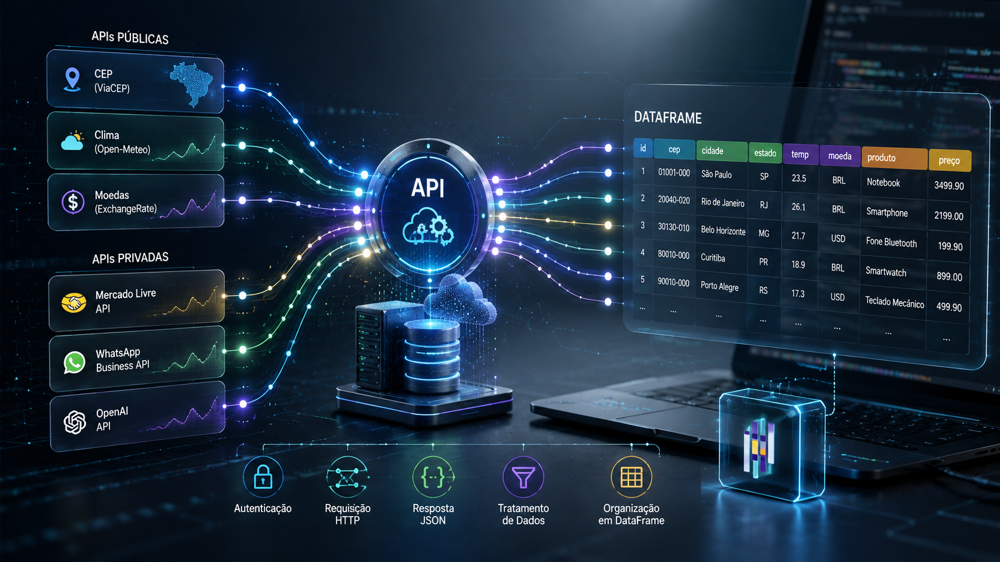

## Consumo de APIs: Obtenção de dados externos e organização em DataFrames

Nesta aula, estudaremos como aplicações em Python podem obter dados de serviços externos por meio de **APIs (Application Programming Interfaces)** e transformar as respostas recebidas em estruturas tabulares com `pandas`.

O foco da aula é o fluxo:

$$
\colorbox{#F1F5F9}{\text{documentação}}\;\longrightarrow\;
\colorbox{#E2E8F0}{\text{requisição HTTP}}\;\longrightarrow\;
\colorbox{#CBD5E1}{\text{resposta}}\;\longrightarrow\;
\colorbox{#B6C3D1}{\text{JSON}}\;\longrightarrow\;
\colorbox{#94A3B8}{\text{seleção de campos}}\;\longrightarrow\;
\colorbox{#718096}{\text{DataFrame}}\;\longrightarrow\;
\colorbox{#526477}{\color{white}{\text{validação}}}
$$

Serão utilizados seis exemplos:

| Tipo de acesso | API | Aplicação |
|---|---|---|
| Sem autenticação | ViaCEP | Consulta de endereços por CEP |
| Sem autenticação | IBGE | Consulta de estados e municípios |
| Sem autenticação | Open-Meteo | Dados meteorológicos |
| Com autenticação | Mercado Livre | OAuth 2.0 e recursos da conta |
| Com autenticação | GitHub | Token de acesso e dados do usuário |
| Com autenticação | OpenWeather | API Key e dados meteorológicos |

**Objetivo principal:** obter dados externos por meio de APIs e organizá-los em `DataFrame` para posterior análise, armazenamento ou integração com outros sistemas.

**Objetivos específicos**


1. explicar o que é uma API e identificar seus principais componentes;
2. interpretar a documentação de uma API REST;
3. diferenciar endpoint, método HTTP, parâmetro, header, payload e resposta;
4. realizar requisições HTTP em Python com a biblioteca `requests`;
5. verificar códigos de status e tratar erros básicos;
6. interpretar respostas em JSON;
7. transformar estruturas JSON em `DataFrame`;
8. consumir APIs sem autenticação;
9. utilizar credenciais em APIs que exigem autenticação;
10. compreender o fluxo OAuth 2.0 utilizado pelo Mercado Livre;
11. evitar a exposição de tokens, chaves e segredos no notebook.

# 1. O que é uma API?

Uma **API**, ou *Application Programming Interface*, define uma interface pela qual dois sistemas de software podem trocar dados ou solicitar operações.

Em uma aplicação web tradicional, uma pessoa utiliza uma interface gráfica. No consumo de uma API, um programa envia uma **requisição** diretamente a outro sistema.

Podemos representar o processo de forma simplificada:


$$\colorbox{#DCEEFF}{\text{Cliente}}\;\longrightarrow\;\colorbox{#FFF0CC}{\text{Requisição HTTP}}\;\longrightarrow\;\colorbox{#DDF4E4}{\text{API}}$$

$$\colorbox{#DCEEFF}{\text{Cliente}}\;\longleftarrow\;\colorbox{#EADFFF}{\text{Resposta HTTP}}\;\longleftarrow\;\colorbox{#DDF4E4}{\text{API}}$$

Nesta aula, o cliente será um programa Python executado no Jupyter Notebook.

## 2 Tipos de APIs

As APIs podem ser classificadas de diferentes formas, dependendo de sua arquitetura, protocolo de comunicação e finalidade. Entre os principais tipos encontrados em sistemas computacionais estão **SOAP, RPC, GraphQL e REST**.

### SOAP

**SOAP (*Simple Object Access Protocol*)** é um protocolo de comunicação baseado em mensagens estruturadas, normalmente utilizando **XML**.

Possui regras mais rígidas para a definição e troca de mensagens, sendo comum em sistemas corporativos que exigem contratos bem definidos, padronização e mecanismos formais de segurança.

**Aplicação:** integração entre sistemas bancários, sistemas governamentais e plataformas empresariais.

$$
\colorbox{#F3DDE3}{\text{Sistema A}}\;\longrightarrow\;\colorbox{#DDE5ED}{\text{mensagem XML}}\;
\longrightarrow\;\colorbox{#E8DFC9}{\text{serviço SOAP}}\;\longrightarrow\;
\colorbox{#DDE5ED}{\text{mensagem XML}}\;\longrightarrow\;
\colorbox{#F3DDE3}{\text{Sistema A}}
$$

### RPC

**RPC (*Remote Procedure Call*)**, ou **Chamada de Procedimento Remoto**, é um modelo de comunicação no qual um sistema **cliente solicita a execução de uma função ou procedimento localizado em um servidor remoto**.

A ideia central da RPC é permitir que uma operação executada em outro sistema seja solicitada de maneira semelhante a uma chamada de função.

Por exemplo, suponha que um servidor disponibilize uma função responsável pelo cálculo do valor de um frete:

```python
def calcular_frete(cep, peso):
    # processamento realizado no servidor
    return valor_frete
```

O cliente pode solicitar a execução dessa operação informando os parâmetros necessários:

```text
calcularFrete("01001000", 2.5)
```

Nesse processo, **a função não é executada no cliente**. O cliente apenas informa ao servidor qual operação deseja executar e quais valores devem ser utilizados como parâmetros.

O fluxo pode ser representado por:

$$
\colorbox{#E6E0F0}{\text{Cliente}}
\;\xrightarrow{\text{função + parâmetros}}\;
\colorbox{#DDEBE3}{\text{Servidor}}
\;\xrightarrow{\text{executa a função}}\;
\colorbox{#F2E3CF}{\text{Resultado}}
\;\longrightarrow\;
\colorbox{#E6E0F0}{\text{Cliente}}
$$

**Aplicação:** RPC é utilizada na comunicação entre sistemas distribuídos e **microsserviços**, especialmente quando diferentes componentes de uma aplicação precisam solicitar operações uns aos outros. Uma tecnologia amplamente utilizada nesse contexto é o **gRPC**, que implementa o paradigma RPC para comunicação entre aplicações.


### GraphQL

**GraphQL** é uma linguagem de consulta para APIs e um ambiente de execução que permite ao **cliente especificar exatamente quais dados deseja receber do servidor**.

Uma das principais características do GraphQL é permitir que diferentes informações relacionadas sejam solicitadas em uma única consulta, selecionando apenas os campos necessários.

Considere, por exemplo, um sistema que armazena informações sobre usuários. Um usuário pode possuir diversos atributos, como:

```text
id
nome
email
telefone
data_nascimento
endereco
pedidos
```

Se uma aplicação precisar apenas do nome e do e-mail de um usuário, poderá realizar uma consulta GraphQL como:

```graphql
query {
    usuario(id: 123) {
        nome
        email
    }
}
```

O servidor processa a consulta e retorna somente os campos solicitados:

```json
{
    "data": {
        "usuario": {
            "nome": "Ana Silva",
            "email": "ana@email.com"
        }
    }
}
```

Portanto, no GraphQL, **o cliente possui maior controle sobre a estrutura dos dados retornados**.

Isso é particularmente útil quando os dados possuem relacionamentos. Por exemplo, podemos solicitar informações do usuário e de seus pedidos na mesma consulta:

```graphql
query {
    usuario(id: 123) {
        nome
        email
        pedidos {
            id
            valor
            data
        }
    }
}
```


**Aplicação:** GraphQL é utilizado em aplicações web e móveis que trabalham com dados relacionados e podem precisar de diferentes conjuntos de atributos em diferentes telas. Uma interface de perfil, por exemplo, pode solicitar apenas `nome` e `foto`, enquanto outra tela pode solicitar `nome`, `email`, `pedidos` e outras informações relacionadas.

Apesar dessa flexibilidade, **REST continua sendo uma das abordagens mais difundidas para construção e consumo de APIs Web**. Como as APIs utilizadas nos exemplos desta aula são predominantemente baseadas em requisições HTTP no estilo REST, aprofundaremos a seguir a organização de **recursos e endpoints em APIs REST**.


### REST

**REST (*Representational State Transfer*)** é um estilo arquitetural amplamente utilizado na construção de APIs Web.

Em uma API REST, os dados são normalmente organizados como **recursos**, identificados por URLs. As operações sobre esses recursos são realizadas utilizando os métodos do protocolo HTTP, como `GET`, `POST`, `PUT`, `PATCH` e `DELETE`.

Por exemplo, considere uma API que disponibiliza informações sobre clientes:

```text
https://api.exemplo.com/clientes
```

O recurso representado nesse endereço é:

```text
clientes
```

Uma consulta a um cliente específico poderia utilizar:

```text
GET https://api.exemplo.com/clientes/123
```

Nesse caso:

* `GET` indica a operação de consulta;
* `clientes` representa o recurso;
* `123` identifica o cliente solicitado.

As APIs REST são particularmente relevantes para esta aula porque grande parte das APIs disponíveis na Web utiliza HTTP para disponibilizar dados, frequentemente retornados no formato **JSON**.

Os exemplos que utilizaremos, como **ViaCEP, IBGE, Open-Meteo, Mercado Livre, GitHub e OpenWeather**, seguem esse tipo de interação baseada em requisições HTTP.

Antes de começarmos a consumir essas APIs em Python, precisamos compreender melhor como uma API REST organiza seus **recursos e endpoints**. Esse será o assunto da próxima seção.


## 2.1 API REST e recursos

Muitas APIs disponíveis na Web seguem princípios associados à arquitetura REST. Nessas APIs, os dados são organizados em **recursos**, acessados por URLs denominadas **endpoints**.

Exemplo conceitual:

```text
https://api.exemplo.com/clientes/123
```

Podemos separar esse endereço em:

- **base URL:** `https://api.exemplo.com`
- **recurso:** `/clientes`
- **identificador:** `/123`

A URL completa utilizada para acessar uma operação específica é denominada **endpoint**.

## 2.2 Métodos HTTP

O método HTTP informa a operação que desejamos realizar.

| Método | Uso frequente |
|---|---|
| `GET` | consultar dados |
| `POST` | criar dados ou enviar informações para processamento |
| `PUT` | substituir um recurso |
| `PATCH` | atualizar parcialmente um recurso |
| `DELETE` | remover um recurso |

O objetivo principal desta aula é **obter dados externos**. Por isso, a maior parte das requisições utilizará `GET`.

## 2.3 Parâmetros, headers e body

Uma requisição HTTP pode transportar informações de diferentes maneiras. A posição de cada informação depende da finalidade do dado e das regras definidas pela API.

Considere uma API fictícia de uma loja virtual disponível em:

```text
https://api.loja.com
```

A partir desse exemplo, podemos identificar os principais componentes de uma requisição.

### Parâmetros de rota

Os **parâmetros de rota** fazem parte do próprio endpoint e normalmente são utilizados para identificar um recurso específico.

Por exemplo:

```text
GET https://api.loja.com/usuarios/123
```

Nesse caso:

* `/usuarios` representa o recurso que queremos consultar;
* `123` é um parâmetro de rota que identifica um usuário específico.

Assim, diferentes valores permitem acessar diferentes recursos:

```text
GET https://api.loja.com/usuarios/123
GET https://api.loja.com/usuarios/456
```

### Query parameters

Os **query parameters**, ou parâmetros de consulta, são utilizados para enviar informações adicionais ao servidor, frequentemente relacionadas a filtros, ordenação, paginação ou configuração da resposta.

Eles aparecem após o caractere `?` na URL:

```text
GET https://api.loja.com/produtos?categoria=notebooks&limite=10
```

Nesse exemplo, temos dois parâmetros:

```text
categoria = notebooks
limite = 10
```

O caractere `&` separa os diferentes parâmetros.

A requisição pode ser interpretada como:

> Consulte os produtos da categoria `notebooks` e retorne no máximo `10` registros.

Em Python, utilizando `requests`, não precisamos construir manualmente a query string. Podemos utilizar um dicionário:

```python
parametros = {
    "categoria": "notebooks",
    "limite": 10
}

resposta = requests.get(
    "https://api.loja.com/produtos",
    params=parametros
)
```

A biblioteca constrói a URL correspondente automaticamente.

### Headers

Os **headers** transportam metadados associados à requisição.

Eles não fazem parte diretamente dos dados que estamos consultando ou enviando. Em vez disso, fornecem informações adicionais sobre a comunicação entre cliente e servidor.

Um uso frequente é o envio de credenciais de autenticação:

```text
Authorization: Bearer TOKEN
```

Por exemplo:

```python
headers = {
    "Authorization": "Bearer TOKEN"
}

resposta = requests.get(
    "https://api.loja.com/usuarios/123",
    headers=headers
)
```

Nesse caso, o token permite que o servidor identifique ou autorize o cliente antes de fornecer o recurso solicitado.

Headers também podem informar o formato dos dados enviados ou esperados, como:

```text
Content-Type: application/json
Accept: application/json
```

### Body

O **body** corresponde ao corpo da requisição e permite enviar dados ao servidor.

É particularmente comum em operações como `POST`, `PUT` e `PATCH`.

Considere, por exemplo, o cadastro de um novo usuário:

```text
POST https://api.loja.com/usuarios
```

Os dados do usuário poderiam ser enviados no body em formato JSON:

```json
{
    "nome": "Ana Silva",
    "email": "ana@email.com",
    "cidade": "São Paulo"
}
```

Em Python:

```python
novo_usuario = {
    "nome": "Ana Silva",
    "email": "ana@email.com",
    "cidade": "São Paulo"
}

resposta = requests.post(
    "https://api.loja.com/usuarios",
    json=novo_usuario
)
```

Nesse caso, os dados contidos em `novo_usuario` são enviados no **body da requisição**.


A **documentação da API** determina quais métodos, parâmetros, headers e dados no body são aceitos ou obrigatórios em cada endpoint.


## 2.4 Códigos de status HTTP

Toda resposta HTTP possui um código de status.

| Faixa | Interpretação geral | Exemplos |
|---|---|---|
| `2xx` | requisição processada | `200 OK`, `201 Created` |
| `3xx` | redirecionamento | `301`, `302` |
| `4xx` | problema associado à requisição | `400`, `401`, `403`, `404`, `429` |
| `5xx` | erro no servidor | `500`, `502`, `503` |

Alguns códigos particularmente importantes no consumo de APIs são:

- `200`: requisição concluída;
- `400`: requisição inválida;
- `401`: autenticação ausente ou inválida;
- `403`: acesso não permitido;
- `404`: recurso não encontrado;
- `429`: limite de requisições excedido.

Não devemos transformar uma resposta em dados analíticos sem verificar se a requisição foi processada corretamente.

## 2.5 JSON

O formato **JSON (JavaScript Object Notation)** é amplamente utilizado por APIs.

Exemplo:

```json
{
    "nome": "Ana",
    "idade": 28,
    "cidade": "São Paulo"
}
```

Ao executar:

```python
dados = resposta.json()
```

a biblioteca `requests` converte o JSON para estruturas Python, normalmente dicionários e listas.

O `pandas` pode então organizar essas estruturas em tabelas.

# 3. Preparação do ambiente

Utilizaremos:

- `requests`: envio de requisições HTTP;
- `pandas`: organização e análise tabular;
- `os`: leitura de variáveis de ambiente;
- `getpass`: entrada temporária de credenciais sem exibi-las na célula;
- `urllib.parse`: apoio à construção de URLs.

In [1]:
import os
from getpass import getpass
from urllib.parse import urlencode

import pandas as pd
import requests

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 50)

## 3.1 Uma função auxiliar para requisições GET

Método básico para fazer uma requisição

```python
resposta = requests.get(url,params,headers,timeout)
```

Praa facilitar as próximas etapas, vamos criar uma função para:

1. enviar a requisição;
2. definir um tempo máximo de espera;
3. verificar o código de status;
4. gerar uma exceção quando a resposta HTTP indicar erro.

O parâmetro `timeout` evita que o notebook aguarde indefinidamente por um servidor que não responde.

In [2]:
def requisicao_get(url, params=None, headers=None, timeout=20):
    resposta = requests.get(
        url,
        params=params,
        headers=headers,
        timeout=timeout
    )

    print("Status HTTP:", resposta.status_code)
    resposta.raise_for_status()

    return resposta

# 4. Como ler a documentação de uma API

Antes de escrever código, localize na documentação pelo menos os seguintes elementos:

| Elemento | Pergunta |
|---|---|
| Base URL | Qual é o domínio da API? |
| Endpoint | Qual recurso será consultado? |
| Método | A operação utiliza `GET`, `POST` ou outro método? |
| Autenticação | É necessário token, API Key ou OAuth? |
| Parâmetros | Quais dados são obrigatórios e opcionais? |
| Headers | Algum cabeçalho deve ser enviado? |
| Body | A operação exige corpo da requisição? |
| Resposta | Qual é a estrutura do JSON retornado? |
| Erros | Quais códigos de status precisam ser tratados? |
| Limites | Existe *rate limit*? |
| Paginação | Como obter resultados além da primeira página? |

Essa leitura deve preceder a implementação. Copiar apenas uma URL de exemplo não é suficiente para compreender a integração.

# 5. APIs sem autenticação

Nesta primeira parte, utilizaremos serviços que permitem executar os exemplos propostos sem criar credenciais.

A ausência de autenticação não significa ausência de regras. Uma API pode impor limites, bloquear uso massivo ou alterar sua política de acesso.

Os três exemplos serão:

1. ViaCEP;
2. IBGE;
3. Open-Meteo.

# 6. Exemplo 1: ViaCEP

O ViaCEP disponibiliza consultas de CEPs brasileiros. A documentação informa que a consulta por CEP utiliza oito dígitos e pode retornar JSON ou XML.

Documentação oficial: https://viacep.com.br/

Estrutura do endpoint JSON:

```text
https://viacep.com.br/ws/{CEP}/json/
```

Utilizaremos o CEP `01001000`, correspondente à região da Praça da Sé, em São Paulo.

In [3]:
cep = "06724170"
url_viacep = f"https://viacep.com.br/ws/{cep}/json/"

resposta = requisicao_get(url_viacep)
print(resposta.json())

Status HTTP: 200
{'cep': '06724-170', 'logradouro': 'Rua Pará de Minas', 'complemento': '', 'unidade': '', 'bairro': 'Ressaca', 'localidade': 'Cotia', 'uf': 'SP', 'estado': 'São Paulo', 'regiao': 'Sudeste', 'ibge': '3513009', 'gia': '2781', 'ddd': '11', 'siafi': '6361'}


## 6.1 Do JSON para o DataFrame

A resposta representa um único endereço e, portanto, é convertida para um dicionário Python.

Para criar um `DataFrame` com uma linha, colocamos esse dicionário dentro de uma lista.

In [4]:
df_cep = pd.DataFrame([resposta])
df_cep

,0,1,2
0,"b'{\n ""cep"": ""06724-170"",\n ""logradouro"": ""R...","b'calidade"": ""Cotia"",\n ""uf"": ""SP"",\n ""estad...","b': ""11"",\n ""siafi"": ""6361""\n}'"


Observe a correspondência:

- cada **chave** do JSON torna-se uma coluna;
- cada **valor** torna-se o conteúdo da célula;
- o endereço consultado torna-se uma linha do `DataFrame`.

Esse padrão é recorrente no consumo de APIs.

## 6.2 Consultando vários CEPs

Uma situação mais próxima de um processo de dados consiste em consultar diversos CEPs e consolidar as respostas.

A função a seguir também verifica o campo `erro`, utilizado pelo ViaCEP quando um CEP possui formato válido, mas não é encontrado.

In [5]:
def consultar_cep(cep):
    cep_limpo = str(cep).replace("-", "").strip()

    if not (cep_limpo.isdigit() and len(cep_limpo) == 8):
        return {
            "cep_consultado": cep,
            "erro_consulta": "Formato inválido"
        }

    url = f"https://viacep.com.br/ws/{cep_limpo}/json/"

    try:
        resposta = requests.get(url, timeout=20)
        resposta.raise_for_status()
        dados = resposta.json()

        if dados.get("erro"):
            return {
                "cep_consultado": cep_limpo,
                "erro_consulta": "CEP não encontrado"
            }

        dados["cep_consultado"] = cep_limpo
        dados["erro_consulta"] = None
        return dados

    except requests.RequestException as erro:
        return {
            "cep_consultado": cep_limpo,
            "erro_consulta": str(erro)
        }

In [6]:
ceps = [
    "01001000",
    "20040002",
    "30140071",
    "99999999"
]

enderecos = [consultar_cep(cep) for cep in ceps]

df_ceps = pd.DataFrame(enderecos)

colunas_endereco = [
    "cep_consultado",
    "cep",
    "logradouro",
    "bairro",
    "localidade",
    "uf",
    "regiao",
    "ddd",
    "erro_consulta"
]

df_ceps = df_ceps.reindex(columns=colunas_endereco)
df_ceps

,cep_consultado,cep,logradouro,bairro,localidade,uf,regiao,ddd,erro_consulta
0,01001000,01001-000,Praça da Sé,Sé,São Paulo,SP,Sudeste,11,NaN
1,20040002,20040-002,Avenida Rio Branco,Centro,Rio de Janeiro,RJ,Sudeste,21,NaN
2,30140071,30140-071,Rua dos Aimorés,Boa Viagem,Belo Horizonte,MG,Sudeste,31,NaN
3,99999999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CEP não encontrado


## 6.3 O que aprendemos com o ViaCEP?

O exemplo introduziu o fluxo essencial:


$$
\colorbox{#F0F5FA}{\text{endpoint}}
\;\longrightarrow\;
\colorbox{#DDEAF4}{\text{GET}}
\;\longrightarrow\;
\colorbox{#C5DCEC}{\text{status}}
\;\longrightarrow\;
\colorbox{#A9CBDF}{\text{JSON}}
\;\longrightarrow\;
\colorbox{#86B5D0}{\text{dicionário}}
\;\longrightarrow\;
\colorbox{#639DBE}{\text{DataFrame}}
$$

Também introduziu uma prática importante: uma base resultante de uma API deve preservar informações sobre consultas que falharam. Excluir silenciosamente esses casos pode produzir uma base aparentemente completa, embora existam registros não obtidos.

# 7. Exemplo 2: API de Localidades do IBGE

Agora consultaremos dados hierárquicos de unidades territoriais.

A API de Localidades do IBGE permite consultar estados, municípios e outras divisões territoriais.

Endpoint utilizado:

```text
https://servicodados.ibge.gov.br/api/v1/localidades/estados/SP/municipios
```

Nesse caso:

- `SP` identifica a unidade federativa;
- `/municipios` especifica o recurso solicitado;
- a resposta contém uma **lista de objetos JSON**.

In [7]:
url_ibge = "https://servicodados.ibge.gov.br/api/v1/localidades/estados/SP/municipios"

resposta_ibge = requisicao_get(url_ibge)
municipios_sp = resposta_ibge.json()
print("Total de estados:", len(municipios_sp))
print(municipios_sp)

Status HTTP: 200
Total de estados: 645
[{'id': 3500105, 'nome': 'Adamantina', 'microrregiao': {'id': 35035, 'nome': 'Adamantina', 'mesorregiao': {'id': 3508, 'nome': 'Presidente Prudente', 'UF': {'id': 35, 'sigla': 'SP', 'nome': 'São Paulo', 'regiao': {'id': 3, 'sigla': 'SE', 'nome': 'Sudeste'}}}}, 'regiao-imediata': {'id': 350019, 'nome': 'Adamantina - Lucélia', 'regiao-intermediaria': {'id': 3505, 'nome': 'Presidente Prudente', 'UF': {'id': 35, 'sigla': 'SP', 'nome': 'São Paulo', 'regiao': {'id': 3, 'sigla': 'SE', 'nome': 'Sudeste'}}}}}, {'id': 3500204, 'nome': 'Adolfo', 'microrregiao': {'id': 35004, 'nome': 'São José do Rio Preto', 'mesorregiao': {'id': 3501, 'nome': 'São José do Rio Preto', 'UF': {'id': 35, 'sigla': 'SP', 'nome': 'São Paulo', 'regiao': {'id': 3, 'sigla': 'SE', 'nome': 'Sudeste'}}}}, 'regiao-imediata': {'id': 350025, 'nome': 'São José do Rio Preto', 'regiao-intermediaria': {'id': 3507, 'nome': 'São José do Rio Preto', 'UF': {'id': 35, 'sigla': 'SP', 'nome': 'São Pau

## 7.1 JSON aninhado

Observe que alguns campos contêm outros objetos. Isso é denominado **estrutura aninhada**.

Quando queremos transformar estruturas aninhadas em formato tabular, `pd.json_normalize()` é particularmente útil.

In [8]:
df_municipios_sp = pd.json_normalize(municipios_sp)

print("Dimensões do DataFrame:", df_municipios_sp.shape)
df_municipios_sp

Dimensões do DataFrame: (645, 22)


,id,nome,microrregiao.id,microrregiao.nome,microrregiao.mesorregiao.id,microrregiao.mesorregiao.nome,...,regiao-imediata.regiao-intermediaria.UF.id,regiao-imediata.regiao-intermediaria.UF.sigla,regiao-imediata.regiao-intermediaria.UF.nome,regiao-imediata.regiao-intermediaria.UF.regiao.id,regiao-imediata.regiao-intermediaria.UF.regiao.sigla,regiao-imediata.regiao-intermediaria.UF.regiao.nome
0,3500105,Adamantina,35035,Adamantina,3508,Presidente Prudente,...,35,SP,São Paulo,3,SE,Sudeste
1,3500204,Adolfo,35004,São José do Rio Preto,3501,São José do Rio Preto,...,35,SP,São Paulo,3,SE,Sudeste
2,3500303,Aguaí,35029,Pirassununga,3507,Campinas,...,35,SP,São Paulo,3,SE,Sudeste
3,3500402,Águas da Prata,35030,São João da Boa Vista,3507,Campinas,...,35,SP,São Paulo,3,SE,Sudeste
4,3500501,Águas de Lindóia,35033,Amparo,3507,Campinas,...,35,SP,São Paulo,3,SE,Sudeste
...,...,...,...,...,...,...,...,...,...,...,...,...,...
640,3557006,Votorantim,35046,Sorocaba,3512,Macro Metropolitana Paulista,...,35,SP,São Paulo,3,SE,Sudeste
641,3557105,Votuporanga,35003,Votuporanga,3501,São José do Rio Preto,...,35,SP,São Paulo,3,SE,Sudeste
642,3557154,Zacarias,35004,São José do Rio Preto,3501,São José do Rio Preto,...,35,SP,São Paulo,3,SE,Sudeste
643,3557204,Chavantes,35040,Ourinhos,3510,Assis,...,35,SP,São Paulo,3,SE,Sudeste


## 7.2 Seleção e renomeação de campos

Nem todos os campos retornados pela API precisam permanecer no conjunto analítico.

Selecionaremos apenas alguns atributos e atribuiremos nomes mais adequados ao contexto da análise.

In [9]:
colunas_ibge = {
    "id": "id_municipio",
    "nome": "municipio",
    "microrregiao.mesorregiao.UF.sigla": "uf",
    "microrregiao.mesorregiao.UF.nome": "estado"
}
df_municipios_resumo = (
    df_municipios_sp[list(colunas_ibge)].rename(columns=colunas_ibge).sort_values("municipio").reset_index(drop=True)
)
df_municipios_resumo.head(10)

,id_municipio,municipio,uf,estado
0,3500105,Adamantina,SP,São Paulo
1,3500204,Adolfo,SP,São Paulo
2,3500303,Aguaí,SP,São Paulo
3,3500709,Agudos,SP,São Paulo
4,3500758,Alambari,SP,São Paulo
5,3500808,Alfredo Marcondes,SP,São Paulo
6,3500907,Altair,SP,São Paulo
7,3501004,Altinópolis,SP,São Paulo
8,3501103,Alto Alegre,SP,São Paulo
9,3501152,Alumínio,SP,São Paulo


Esse passo evidencia uma diferença importante entre **dados recebidos** e **dados analíticos**.

A resposta da API é estruturada de acordo com o contrato do serviço. O `DataFrame` deve ser organizado de acordo com o problema que será analisado.

# 8. Exemplo 3: Open-Meteo

O Open-Meteo disponibiliza dados meteorológicos e, para uso não comercial padrão, permite consultas sem API Key.

Documentação oficial: https://open-meteo.com/en/docs

O endpoint de previsão recebe coordenadas geográficas e as variáveis desejadas.

Consultaremos dados horários para São Paulo, aproximadamente:

- latitude: `-23.55`;
- longitude: `-46.63`.

In [10]:
url_open_meteo = "https://api.open-meteo.com/v1/forecast"

parametros_meteo = {
    "latitude": -23.55,
    "longitude": -46.63,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "forecast_days": 2,
    "timezone": "America/Sao_Paulo"
}

resposta_meteo = requisicao_get(
    url_open_meteo,
    params=parametros_meteo
)

dados_meteo = resposta_meteo.json()

dados_meteo.keys()

Status HTTP: 200


dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])

## 8.1 Identificando o nível correto do JSON

Nem sempre devemos transformar o JSON inteiro diretamente em um `DataFrame`.

A resposta do Open-Meteo contém:

- metadados da consulta;
- unidades;
- coordenadas;
- uma estrutura `hourly` com as observações horárias.

Para uma análise temporal, o objeto de interesse é `hourly`.

In [11]:
dados_horarios = dados_meteo["hourly"]

df_tempo = pd.DataFrame(dados_horarios)
df_tempo["time"]= pd.to_datetime(df_tempo["time"])

df_tempo.head(10)

,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-11-09 00:00:00,14.2,94,0.1
1,2026-11-09 01:00:00,13.9,96,0.0
2,2026-11-09 02:00:00,13.7,94,0.0
3,2026-11-09 03:00:00,13.4,92,0.0
4,2026-11-09 04:00:00,13.1,94,0.0
5,2026-11-09 05:00:00,13.2,93,0.0
6,2026-11-09 06:00:00,13.1,92,0.0
7,2026-11-09 07:00:00,13.8,88,0.0
8,2026-11-09 08:00:00,15.0,81,0.1
9,2026-11-09 09:00:00,15.9,70,0.1


## 8.2 Inspeção do DataFrame

Após importar dados de uma API, devemos verificar pelo menos:

- dimensão;
- nomes das colunas;
- tipos;
- valores ausentes;
- primeiras observações.

In [12]:
print("Dimensões do DataFrame:", df_tempo.shape)
print("\nTipos:")
print(df_tempo.dtypes)

print("\nValores ausentes:")
print(df_tempo.isnull().sum())

df_tempo.head()

Dimensões do DataFrame: (48, 4)

Tipos:
time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
dtype: object

Valores ausentes:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
dtype: int64


,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-11-09 00:00:00,14.2,94,0.1
1,2026-11-09 01:00:00,13.9,96,0.0
2,2026-11-09 02:00:00,13.7,94,0.0
3,2026-11-09 03:00:00,13.4,92,0.0
4,2026-11-09 04:00:00,13.1,94,0.0


# 9. Comparação dos três primeiros exemplos

| API | Entrada principal | Estrutura relevante da resposta | Estratégia tabular |
|---|---|---|---|
| ViaCEP | CEP | objeto JSON | `DataFrame([dicionario])` |
| IBGE | UF/recurso | lista de objetos aninhados | `json_normalize()` |
| Open-Meteo | coordenadas e variáveis | objeto com série em `hourly` | selecionar nível e usar `DataFrame()` |

O principal aprendizado é que **não existe uma única forma de converter JSON em tabela**. Primeiro é necessário compreender a estrutura semântica da resposta.

# 9.1 Atividade prática: consumo de APIs públicas

Nesta atividade, aplicaremos os conceitos estudados até aqui utilizando as três APIs públicas apresentadas anteriormente:

* **ViaCEP**, para consulta de endereços;
* **IBGE**, para consulta de municípios;
* **Open-Meteo**, para obtenção de dados meteorológicos.

O objetivo é praticar o fluxo completo:

```text
requisição HTTP → resposta JSON → seleção dos dados → DataFrame → análise
```
$$
\colorbox{#F3F0F7}{\text{requisição HTTP}}
\;\longrightarrow\;
\colorbox{#E5DDEC}{\text{resposta JSON}}
\;\longrightarrow\;
\colorbox{#D4C5DF}{\text{seleção dos dados}}
\;\longrightarrow\;
\colorbox{#BFA9CF}{\text{DataFrame}}
\;\longrightarrow\;
\colorbox{#A58ABB}{\text{análise}}
$$

A atividade está organizada em três etapas.


## Parte 1: consulta de endereços com ViaCEP

Consulte os seguintes CEPs utilizando a API ViaCEP:

```text
01001000
20040002
30140071
40020000
80010000
```

Construa um único `DataFrame` contendo as seguintes informações:

* CEP;
* logradouro;
* bairro;
* cidade;
* UF;
* região;
* DDD.

Ao final:

1. exiba o `DataFrame`;
2. verifique sua dimensão;
3. identifique se existem valores ausentes;
4. verifique se existem registros duplicados.

In [13]:
#Implementação de consulta de múltiplos CEPs
ceps = [
    "01001000",
    "20040002",
    "30140071",
    "40020000",
    "80010000"
]

enderecos = [consultar_cep(cep) for cep in ceps]

df_ceps = pd.DataFrame(enderecos)

colunas_endereco = [
    "cep",
    "logradouro",
    "bairro",
    "localidade",
    "uf",
    "regiao",
    "ddd"
]

df_ceps = df_ceps.reindex(columns=colunas_endereco)


In [14]:
# Verificação do DataFrame
df_ceps

,cep,logradouro,bairro,localidade,uf,regiao,ddd
0,01001-000,Praça da Sé,Sé,São Paulo,SP,Sudeste,11
1,20040-002,Avenida Rio Branco,Centro,Rio de Janeiro,RJ,Sudeste,21
2,30140-071,Rua dos Aimorés,Boa Viagem,Belo Horizonte,MG,Sudeste,31
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,80010-000,Rua José Loureiro,Centro,Curitiba,PR,Sul,41


## Parte 2: consulta de municípios com a API do IBGE

Utilize a API de Localidades do IBGE para consultar todos os municípios do estado de **Minas Gerais (`MG`)**.

Construa um `DataFrame` contendo apenas:

* código do município;
* nome do município;
* sigla da UF;
* nome do estado.

Depois:

1. informe quantos municípios foram retornados;
2. ordene os municípios alfabeticamente;
3. exiba os 10 primeiros registros.

Endpoint de referência:

```text
https://servicodados.ibge.gov.br/api/v1/localidades/estados/MG/municipios
```



In [15]:
#Implementação IBGE
url_ibge = "https://servicodados.ibge.gov.br/api/v1/localidades/estados/MG/municipios"

resposta_ibge = requisicao_get(url_ibge)
municipios_mg = resposta_ibge.json()

Status HTTP: 200


In [16]:
#Normalização json
df_municipios_mg = pd.json_normalize(municipios_mg)

print("Dimensões do DataFrame:", df_municipios_mg.shape)
df_municipios_mg

Dimensões do DataFrame: (853, 22)


,id,nome,microrregiao.id,microrregiao.nome,microrregiao.mesorregiao.id,microrregiao.mesorregiao.nome,...,regiao-imediata.regiao-intermediaria.UF.id,regiao-imediata.regiao-intermediaria.UF.sigla,regiao-imediata.regiao-intermediaria.UF.nome,regiao-imediata.regiao-intermediaria.UF.regiao.id,regiao-imediata.regiao-intermediaria.UF.regiao.sigla,regiao-imediata.regiao-intermediaria.UF.regiao.nome
0,3100104,Abadia dos Dourados,31019,Patrocínio,3105,Triângulo Mineiro/Alto Paranaíba,...,31,MG,Minas Gerais,3,SE,Sudeste
1,3100203,Abaeté,31024,Três Marias,3106,Central Mineira,...,31,MG,Minas Gerais,3,SE,Sudeste
2,3100302,Abre Campo,31061,Manhuaçu,3112,Zona da Mata,...,31,MG,Minas Gerais,3,SE,Sudeste
3,3100401,Acaiaca,31060,Ponte Nova,3112,Zona da Mata,...,31,MG,Minas Gerais,3,SE,Sudeste
4,3100500,Açucena,31039,Ipatinga,3108,Vale do Rio Doce,...,31,MG,Minas Gerais,3,SE,Sudeste
...,...,...,...,...,...,...,...,...,...,...,...,...,...
848,3171808,Virginópolis,31035,Guanhães,3108,Vale do Rio Doce,...,31,MG,Minas Gerais,3,SE,Sudeste
849,3171907,Virgolândia,31037,Governador Valadares,3108,Vale do Rio Doce,...,31,MG,Minas Gerais,3,SE,Sudeste
850,3172004,Visconde do Rio Branco,31064,Ubá,3112,Zona da Mata,...,31,MG,Minas Gerais,3,SE,Sudeste
851,3172103,Volta Grande,31066,Cataguases,3112,Zona da Mata,...,31,MG,Minas Gerais,3,SE,Sudeste


In [17]:
#Seleção de colunas
colunas_ibge = {
    "id": "id_municipio",
    "nome": "municipio",
    "microrregiao.mesorregiao.UF.sigla": "uf",
    "microrregiao.mesorregiao.UF.nome": "estado"
}
df_municipios_resumo_mg = (
    df_municipios_mg[list(colunas_ibge)].rename(columns=colunas_ibge).sort_values("municipio").reset_index(drop=True)
)

df_municipios_resumo_mg.head(10)

,id_municipio,municipio,uf,estado
0,3100104,Abadia dos Dourados,MG,Minas Gerais
1,3100203,Abaeté,MG,Minas Gerais
2,3100302,Abre Campo,MG,Minas Gerais
3,3100401,Acaiaca,MG,Minas Gerais
4,3100807,Aguanil,MG,Minas Gerais
5,3101102,Aimorés,MG,Minas Gerais
6,3101201,Aiuruoca,MG,Minas Gerais
7,3101300,Alagoa,MG,Minas Gerais
8,3101409,Albertina,MG,Minas Gerais
9,3101607,Alfenas,MG,Minas Gerais


In [18]:
#Quantidade de municípios
print("Quantidade de municípios:", len(df_municipios_resumo_mg))

Quantidade de municípios: 853


## Parte 3: dados meteorológicos com Open-Meteo

Utilize a API Open-Meteo para consultar a previsão meteorológica de **São Paulo** utilizando aproximadamente as coordenadas:

```text
Latitude:  -23.55
Longitude: -46.63
```

Solicite as seguintes variáveis horárias:

* temperatura a 2 metros;
* umidade relativa a 2 metros;
* precipitação.

Utilize:

```text
timezone = America/Sao_Paulo
forecast_days = 1
```

Construa um `DataFrame` contendo as observações horárias.

Depois:

1. converta a coluna de data e hora para `datetime`;
2. exiba as primeiras observações;
3. informe a temperatura mínima;
4. informe a temperatura máxima;
5. calcule a temperatura média do período;
6. identifique o horário em que ocorre a maior temperatura.

In [19]:
#Implementação Open-Mateo
url_open_meteo = "https://api.open-meteo.com/v1/forecast"

parametros_meteo = {
    "latitude": -23.55,
    "longitude": -46.63,
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "forecast_days": 2,
    "timezone": "America/Sao_Paulo"
}

resposta_meteo = requisicao_get(
    url_open_meteo,
    params=parametros_meteo
)

dados_meteo = resposta_meteo.json()

Status HTTP: 200


In [20]:
#Inspeção da resposta
print("Dimensões do DataFrame:", df_tempo.shape)
print("\nTipos:")
print(df_tempo.dtypes)

print("\nValores ausentes:")
print(df_tempo.isnull().sum())

df_tempo.head()

Dimensões do DataFrame: (48, 4)

Tipos:
time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
dtype: object

Valores ausentes:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
dtype: int64


,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-11-09 00:00:00,14.2,94,0.1
1,2026-11-09 01:00:00,13.9,96,0.0
2,2026-11-09 02:00:00,13.7,94,0.0
3,2026-11-09 03:00:00,13.4,92,0.0
4,2026-11-09 04:00:00,13.1,94,0.0


In [21]:
#Construção do DataFrame
df_tempo = pd.DataFrame(dados_horarios)
df_tempo["time"]= pd.to_datetime(df_tempo["time"])

df_tempo.head(10)

,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-11-09 00:00:00,14.2,94,0.1
1,2026-11-09 01:00:00,13.9,96,0.0
2,2026-11-09 02:00:00,13.7,94,0.0
3,2026-11-09 03:00:00,13.4,92,0.0
4,2026-11-09 04:00:00,13.1,94,0.0
5,2026-11-09 05:00:00,13.2,93,0.0
6,2026-11-09 06:00:00,13.1,92,0.0
7,2026-11-09 07:00:00,13.8,88,0.0
8,2026-11-09 08:00:00,15.0,81,0.1
9,2026-11-09 09:00:00,15.9,70,0.1


In [22]:
# Estatísticas da Temperatura  
temp_min = df_tempo["temperature_2m"].min()
temp_max = df_tempo["temperature_2m"].max()
temp_media = df_tempo["temperature_2m"].mean()

print(f"Temperatura mínima: {temp_min:.1f} °C")
print(f"Temperatura máxima: {temp_max:.1f} °C")
print(f"Temperatura média: {temp_media:.2f} °C")

Temperatura mínima: 13.1 °C
Temperatura máxima: 22.1 °C
Temperatura média: 15.79 °C


In [23]:
# Horário da maior temperatura
indice_pico = df_tempo["temperature_2m"].idxmax()
horario_pico = df_tempo.loc[indice_pico, "time"]

print(f"Horário da maior temperatura: {horario_pico}")

Horário da maior temperatura: 2026-11-10 13:00:00


## Questões para análise

Após executar as três consultas, responda:

1. **Qual API retornou um único objeto JSON por consulta?**

    A ViaCEP retornou um único objeto JSON para cada consulta de CEP.

2. **Qual API retornou diretamente uma lista de registros?**

    O IBGE retornou diretamente uma lista de registros.

3. **Em qual API foi necessário selecionar uma parte específica da resposta JSON antes de criar o DataFrame?**

    Na Open-Meteo, foi necessário selecionar a parte hourly da resposta JSON, pois é nela que estão as observações meteorológicas por hora.

4. **Por que pd.json_normalize() foi útil no exemplo do IBGE?**

    Porque ele facilita a transformação de uma estrutura JSON com vários registros em um formato tabular, adequado para criação e análise de um DataFrame.

5. **Qual é a importância de verificar status_code ou utilizar raise_for_status() antes de processar os dados?**

    Para verificar se a requisição foi realizada corretamente. O raise_for_status() identifica erros HTTP e evita que o programa tente processar dados de uma resposta que apresentou erro.

6. **Apesar de todas serem APIs públicas, a estrutura das respostas é igual? Justifique.**

    Não. Cada API pode organizar e retornar seus dados de uma maneira diferente. Como visto entre os estudos, a ViaCEP retorna um objeto JSON, o IBGE retorna uma lista de registros e a Open-Meteo possui uma estrutura com diferentes partes.

# Desafio Extra - Obter dados da API Pokemón

API: https://pokeapi.co/api/v2/pokemon/

Documentação: https://pokeapi.co/docs/v2


#### Requisição GET e consulta inicial 

In [24]:
# Biblioteca para reconhecer código HTML e exibir imagens no df
from IPython.display import HTML, display

In [25]:
def requisicao_get_pokemon(url, params=None, timeout=20):
    resposta = requests.get(
        url,
        params=params,
        timeout=timeout
    )

    print("Status HTTP:", resposta.status_code)
    resposta.raise_for_status()

    return resposta

In [26]:
url = "https://pokeapi.co/api/v2/pokemon/"

parametros = {
    "limit": 50,
    "offset": 0
}

resposta_lista = requisicao_get_pokemon(url, params=parametros)

dados_lista = resposta_lista.json()

print("Quantidade total de Pokémon disponíveis:", dados_lista["count"])
dados_lista["results"][:5]

Status HTTP: 200
Quantidade total de Pokémon disponíveis: 1351


[{'name': 'bulbasaur', 'url': 'https://pokeapi.co/api/v2/pokemon/1/'},
 {'name': 'ivysaur', 'url': 'https://pokeapi.co/api/v2/pokemon/2/'},
 {'name': 'venusaur', 'url': 'https://pokeapi.co/api/v2/pokemon/3/'},
 {'name': 'charmander', 'url': 'https://pokeapi.co/api/v2/pokemon/4/'},
 {'name': 'charmeleon', 'url': 'https://pokeapi.co/api/v2/pokemon/5/'}]

#### Lista em Dataframe 

In [27]:
df_lista_pokemon = pd.DataFrame(dados_lista["results"])

print("Dimensões do DataFrame:", df_lista_pokemon.shape)
df_lista_pokemon.sample(5)

Dimensões do DataFrame: (50, 2)


,name,url
33,nidoking,https://pokeapi.co/api/v2/pokemon/34/
19,raticate,https://pokeapi.co/api/v2/pokemon/20/
44,vileplume,https://pokeapi.co/api/v2/pokemon/45/
12,weedle,https://pokeapi.co/api/v2/pokemon/13/
35,clefable,https://pokeapi.co/api/v2/pokemon/36/


In [28]:
df_lista_pokemon.shape

(50, 2)

In [29]:
df_lista_pokemon.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   name    50 non-null     str  
 1   url     50 non-null     str  
dtypes: str(2)
memory usage: 932.0 bytes


#### Função de consultar vários Pokémons 

In [30]:
resposta_poke = requisicao_get(url)
pokes = resposta_poke.json()

Status HTTP: 200


In [31]:
def consultar_pokemon(pokemon):
    nome = str(pokemon).strip().lower() # Tratativa do nome do Pokémpon 
    url = f"https://pokeapi.co/api/v2/pokemon/{nome}"

    # Utilizando try e expect para evitar erros de requisição 
    try:
        resposta = requests.get(url, timeout=20)
        resposta.raise_for_status()
        dados = resposta.json()

        # Extração de informações relevantes
        tipos = [tipo["type"]["name"] for tipo in dados["types"]]
        habilidades = [habilidade["ability"]["name"] for habilidade in dados["abilities"]]

        return {
            "id": dados["id"],
            "nome": dados["name"],
            "altura": dados["height"],
            "peso": dados["weight"],
            "experiencia_base": dados["base_experience"],
            "imagem": f"<img src='{dados['sprites']['front_default']}' width='100'>",
            "tipos": ", ".join(tipos),
            "habilidades": ", ".join(habilidades)
        }

    except requests.RequestException as erro:
        return {
            "pokemon_consultado": nome,
            "erro_consulta": str(erro)
        }

In [32]:
pokemons = [
    "charmander", "charizard", "vulpix",
    "squirtle", "blastoise", "lapras",
    "bulbasaur", "venusaur", "treecko",
    "pikachu", "raichu", "mareep",
    "jynx", "articuno", "glaceon",
    "machop", "lucario", "machamp",
    "ekans", "koffing", "grimer",
    "geodude", "onix", "tyranitar",
    "diglett", "cubone", "garchomp",
    "pidgey", "zubat", "pidgeot",
    "abra", "alakazam", "mewtwo",
    "caterpie", "scyther", "heracross",
    "gastly", "gengar", "banette",
    "steelix", "scizor", "metagross",
    "eevee", "snorlax", "ditto"
]

dados_pokemons = [consultar_pokemon(pokemon) for pokemon in pokemons]
df_pokemons = pd.DataFrame(dados_pokemons)
df_pokemons

display(HTML(df_pokemons.to_html(escape=False, index=False)))

id,nome,altura,peso,experiencia_base,imagem,tipos,habilidades
4,charmander,6,85,62,,fire,"blaze, solar-power"
6,charizard,17,905,240,,"fire, flying","blaze, solar-power"
37,vulpix,6,99,60,,fire,"flash-fire, drought"
7,squirtle,5,90,63,,water,"torrent, rain-dish"
9,blastoise,16,855,239,,water,"torrent, rain-dish"
131,lapras,25,2200,187,,"water, ice","water-absorb, shell-armor, hydration"
1,bulbasaur,7,69,64,,"grass, poison","overgrow, chlorophyll"
3,venusaur,20,1000,236,,"grass, poison","overgrow, chlorophyll"
252,treecko,5,50,62,,grass,"overgrow, unburden"
25,pikachu,4,60,112,,electric,"static, lightning-rod"


#### Pesquisa de Pokémon

In [33]:
nome_pokemon = input("Digite o nome do Pokémon que deseja consultar: (se for mais de um separe por vírgula) ")
nomes_pokemons = [nome.strip() for nome in nome_pokemon.split(",")]

dados_pokemons = [consultar_pokemon(pokemon) for pokemon in nomes_pokemons]
df_pokemons_consulta = pd.DataFrame(dados_pokemons)

display(HTML(df_pokemons_consulta.to_html(escape=False, index=False)))


id,nome,altura,peso,experiencia_base,imagem,tipos,habilidades
25,pikachu,4,60,112,,electric,"static, lightning-rod"


#### Análise dos pesos

In [34]:
# Mostrar quais pokémons correspondem aos pesos calculados
idx_min = df_pokemons["peso"].idxmin()
idx_max = df_pokemons["peso"].idxmax()

nome_menor = df_pokemons.loc[idx_min, "nome"]
peso_menor = df_pokemons.loc[idx_min, "peso"]

nome_maior = df_pokemons.loc[idx_max, "nome"]
peso_maior = df_pokemons.loc[idx_max, "peso"]

print(f"Pokémon mais leve: {nome_menor} {peso_menor}kg")
print(f"Pokémon mais pesado: {nome_maior} {peso_maior}kg")

Pokémon mais leve: gastly 1kg
Pokémon mais pesado: metagross 5500kg


#### Explorando tipos de Pokémons 

In [35]:
tipos = (
    df_pokemons["tipos"]
    .str.split(", ")
    .explode()
    .value_counts()
)

print("Quantidade de Pokémon por tipo:")
tipos

Quantidade de Pokémon por tipo:


tipos
poison      8
flying      6
ground      6
psychic     5
normal      5
ice         4
fighting    4
steel       4
bug         4
fire        3
water       3
grass       3
electric    3
rock        3
ghost       3
dark        1
dragon      1
Name: count, dtype: int64

## 5 Consumo De Api Parte2

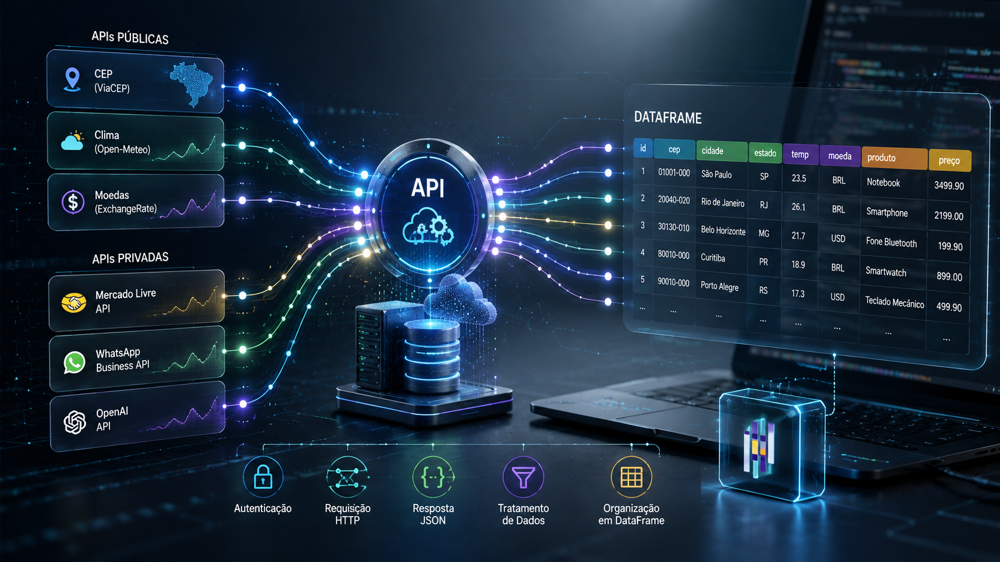

In [1]:
import os
from getpass import getpass
from urllib.parse import urlencode

import pandas as pd
import requests

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 50)

## 1. Uma função auxiliar para requisições GET

Método básico para fazer uma requisição

```python
resposta = requests.get(url,params,headers,timeout)
```

Praa facilitar as próximas etapas, vamos criar uma função para:

1. enviar a requisição;
2. definir um tempo máximo de espera;
3. verificar o código de status;
4. gerar uma exceção quando a resposta HTTP indicar erro.

O parâmetro `timeout` evita que o notebook aguarde indefinidamente por um servidor que não responde.

In [64]:
def requisicao_get(url, params=None, headers=None, timeout=20):
    resposta = requests.get(
        url,
        params=params,
        headers=headers,
        timeout=timeout
    )

    resposta.raise_for_status()

    return resposta

# 2. APIs com autenticação

Agora estudaremos serviços que exigem uma credencial para os exemplos propostos.

Nesta aula, a expressão **API com autenticação** será usada para indicar uma integração em que a requisição depende de uma credencial, como:

- API Key;
- access token;
- OAuth 2.0.

Isso não significa que todos os dados fornecidos pelo serviço sejam necessariamente privados. O ponto central é que o servidor precisa identificar ou autorizar o cliente antes de processar a operação utilizada no exemplo.

## 2.1. Nunca escreva segredos diretamente no notebook

Evite:

```python
TOKEN = "meu_token_real"
```

Um notebook pode ser:

- enviado a outra pessoa;
- publicado no GitHub;
- armazenado em nuvem;
- incluído em backups;
- exibido durante uma aula.

Nesta aula, utilizaremos `getpass()` para digitação temporária. Em projetos reais, prefira mecanismos apropriados de gerenciamento de segredos ou variáveis de ambiente.

# 3. API do Mercado Livre: configuração, OAuth e busca de produtos

Nesta seção, a configuração será feita **na mesma ordem em que o código será construído**. A finalidade é reduzir erros de autenticação e tornar o procedimento reproduzível em sala de aula.

Ao final, faremos uma busca por **Smart TV 70** no catálogo do Mercado Livre e transformaremos os produtos retornados em um `DataFrame`.

Documentação oficial consultada:

- criação da aplicação: https://developers.mercadolivre.com.br/pt_br/crie-uma-aplicacao-no-mercado-livre
- autenticação e autorização: https://developers.mercadolivre.com.br/autenticacao-e-autorizacao
- buscador de produtos: https://developers.mercadolivre.com.br/buscador-de-produtos

> A interface do DevCenter pode mudar. Os nomes exatos dos campos podem sofrer pequenas alterações, mas os conceitos de `Client ID`, `Client Secret`, `Redirect URI`, escopos e OAuth permanecem.


## 3.1. Acesso o DevCenter e clique em Criar nova aplicação

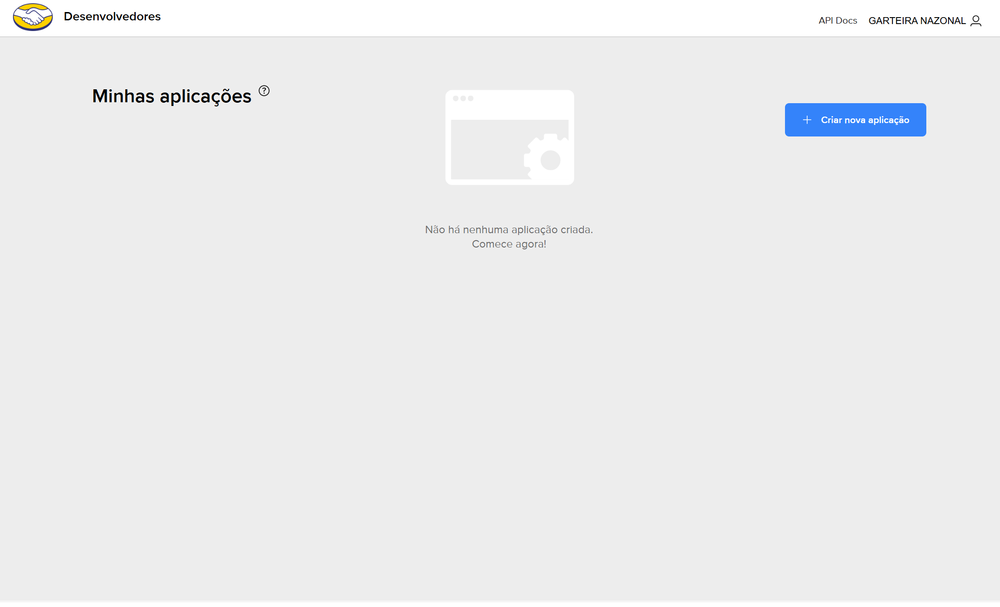

## 3.2. Preencha os dados e insira um logotipo qualquer.

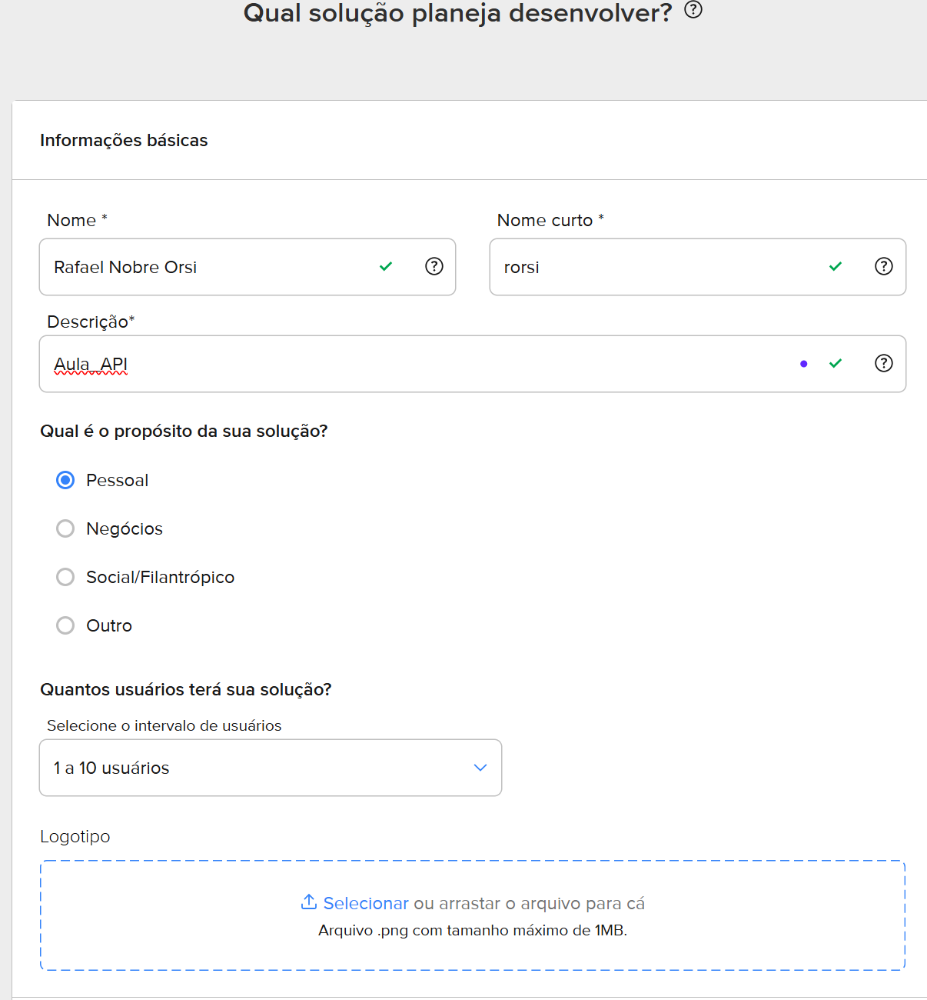

## 3.3. Adicione uma URI

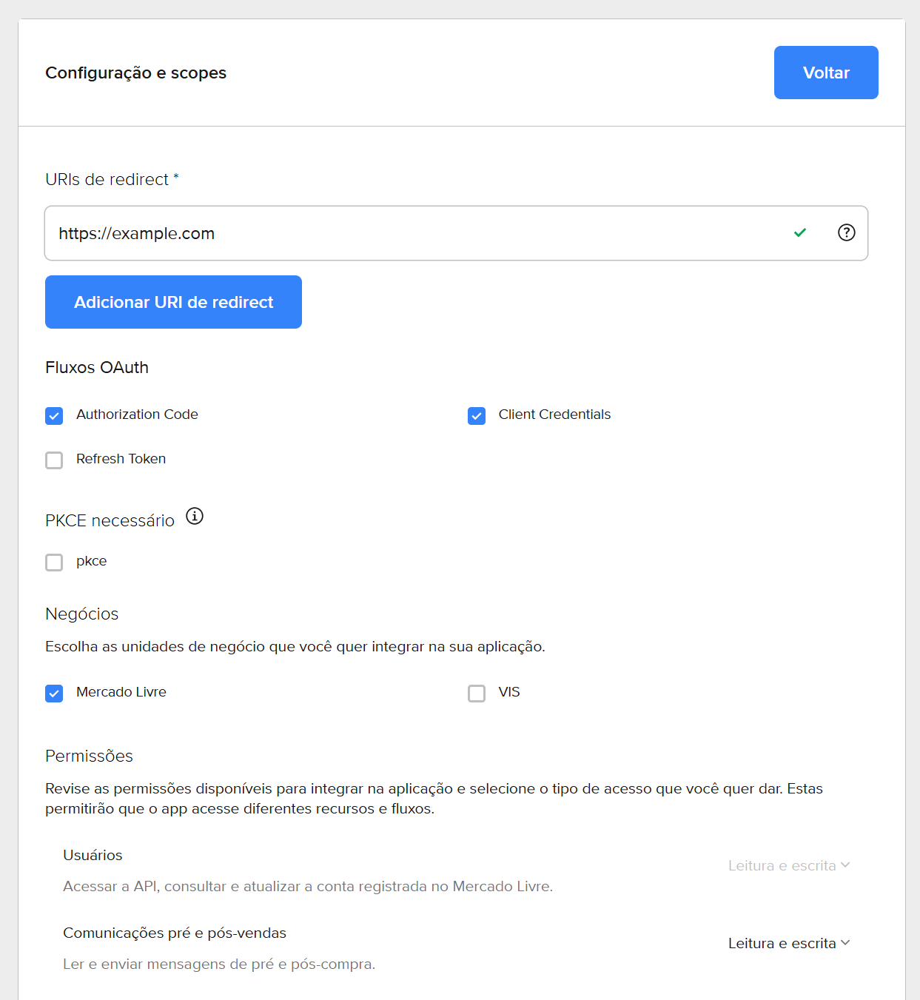

## 3.4. O que será configurado no DevCenter

Para esta aula, configure uma aplicação **somente para leitura**. Não precisamos publicar produtos, alterar anúncios ou receber notificações.

Preencha os campos da aplicação da seguinte forma:

| Campo no Mercado Livre | Configuração didática sugerida | Finalidade |
|---|---|---|
| **Nome** | `Aula API Mercado Livre` | Identificar a aplicação |
| **Nome curto** | um identificador simples e único | Identificação interna/URL da aplicação |
| **Descrição** | `Aplicação didática para consulta de produtos via API` | Texto apresentado no processo de autorização |
| **Logo** | opcional, conforme a interface permitir | Identificação visual |
| **Redirect URI** | `https://example.com` | Receber o retorno com o `code` |
| **PKCE** | desabilitado nesta primeira aula | Evita adicionar uma segunda camada ao fluxo didático |
| **Escopo Leitura** | habilitado | Necessário para chamadas `GET` |
| **Escopo Escrita** | desabilitado | Não será utilizado |
| **Tópicos/Notificações** | nenhum | Não precisamos receber eventos de Orders, Items, Catalog etc. |
| **URL de notificações** | não configurar | Só é necessária quando tópicos são selecionados |

### Por que usar `https://example.com`?

O Mercado Livre exige uma URI de redirecionamento com HTTPS. Para a aula, podemos utilizar uma URL de teste. Depois da autorização, observe a **barra de endereço do navegador**: o Mercado Livre acrescentará o parâmetro `code` à URL.

Exemplo conceitual:

```text
https://example.com/?code=TG-XXXXXXXXXXXX&state=YYYY
```

Mesmo que a página de destino não seja utilizada pela aplicação, o que nos interessa didaticamente é copiar o valor de `code` exibido na URL.

**Regra crítica:** use exatamente a mesma Redirect URI em três lugares:

1. cadastro da aplicação;
2. URL de autorização;
3. requisição que troca o `code` pelo token.

## 3.5. Resultado esperado
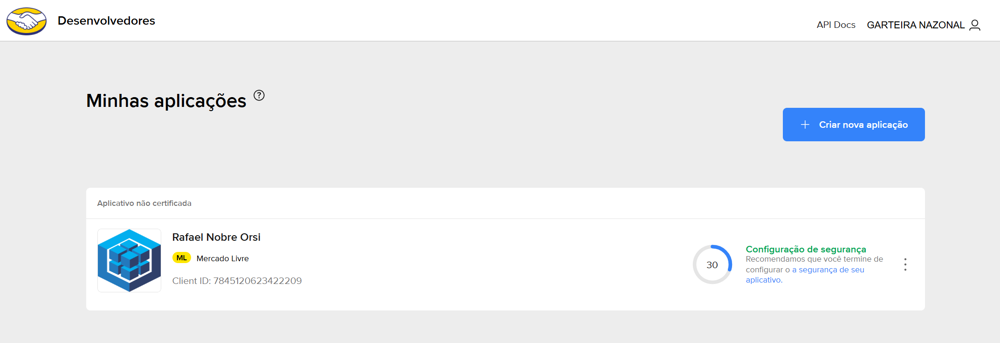

## 3.6. Depois de salvar a aplicação: identifique as credenciais

Após criar a aplicação, localize no DevCenter:

- **Client ID / APP ID**: identifica publicamente sua aplicação;
- **Client Secret / Secret Key**: segredo da aplicação;
- **Redirect URI**: endereço cadastrado anteriormente.

Nesta aula, o `Client Secret` nunca será escrito diretamente no notebook. Ele será solicitado por `getpass()`.

## 4. Construir o a URL de busca
## 4.1. registrar somente o Client ID e a Redirect URI

Começamos com os dois valores que **não são o token**. Nesta etapa ainda não faremos nenhuma requisição à API.


In [68]:
app_id_ml = input("APP ID / Client ID do Mercado Livre: ").strip()
redirect_uri_ml = input("Redirect URI cadastrada [https://leticia.com]: ").strip()

if not redirect_uri_ml: redirect_uri_ml = "https://leticia.com"

print("APP ID informado:", app_id_ml)
print("Redirect URI:", redirect_uri_ml)


APP ID informado: 683130739125478
Redirect URI: https://leticia.com


## 4.2. Etapa 2: construir a URL de autorização

A URL de autorização é formada por um **endpoint fixo** e **parâmetros variáveis**.

Para o Brasil:

```text
https://auth.mercadolivre.com.br/authorization
```

Parâmetros utilizados:

- `response_type=code`: solicita um código de autorização;
- `client_id`: APP ID da aplicação;
- `redirect_uri`: deve coincidir exatamente com o cadastro;
- `state`: valor aleatório usado para associar a resposta à solicitação iniciada.

Em vez de montar a URL manualmente, utilizaremos `urlencode()`. Isso evita erros com caracteres especiais.


In [69]:
import secrets

state_ml = secrets.token_urlsafe(16)

parametros_autorizacao_ml = {
    "response_type": "code",
    "client_id": app_id_ml,
    "redirect_uri": redirect_uri_ml,
    "state": state_ml
}

url_autorizacao_ml = ("https://auth.mercadolivre.com.br/authorization?" + urlencode(parametros_autorizacao_ml))

print("Abra a URL abaixo no navegador:\n")
print(url_autorizacao_ml)
print("\nState gerado:", state_ml)


Abra a URL abaixo no navegador:

https://auth.mercadolivre.com.br/authorization?response_type=code&client_id=683130739125478&redirect_uri=https%3A%2F%2Fleticia.com&state=dMTTz1OqLm3jMCyw3Wo9Rg

State gerado: dMTTz1OqLm3jMCyw3Wo9Rg


## 4.3. Acesse o link gerado e a autorize a aplicação
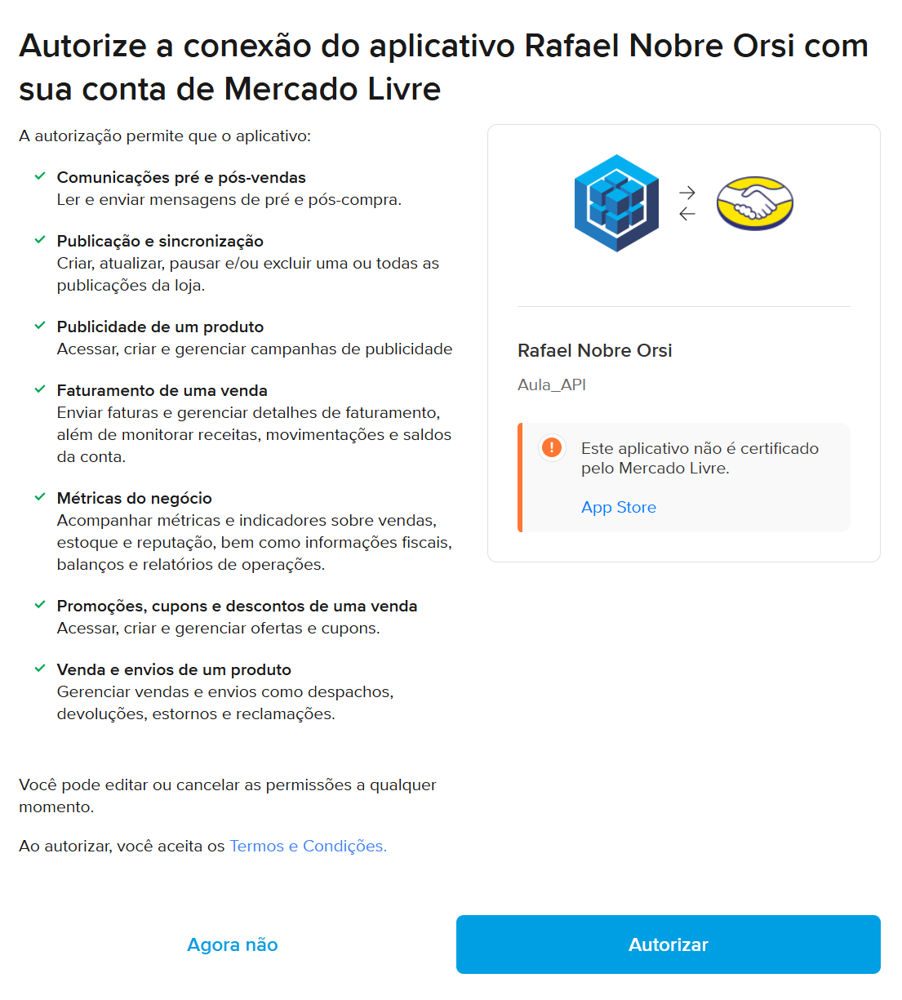

## 4.4. autorizar no navegador e copiar o `code`

Agora o processo sai temporariamente do Python.

1. copie a URL produzida pela célula anterior;
2. abra-a no navegador;
3. faça login com a conta proprietária da aplicação;
4. autorize a aplicação;
5. aguarde o redirecionamento;
6. observe a URL final na barra de endereço;
7. copie somente o valor depois de `code=` e antes de `&state=`.

Exemplo:

```text
https://example.com/?code=TG-ABC123&state=XYZ456
```

Nesse exemplo:

```text
code  = TG-ABC123
state = XYZ456
```

O `code` é temporário e de uso único. Ele **ainda não é o access token**.


## 4.5. Trocar o `code` pelo access token

A troca é feita com uma requisição `POST` para:

```text
https://api.mercadolibre.com/oauth/token
```

Agora precisamos do `Client Secret`, por isso ele será digitado com `getpass()`.

> Se ocorrer `invalid_grant`, verifique primeiro: `code` já utilizado/expirado, Redirect URI diferente da cadastrada ou `code` pertencente a outra tentativa de autorização.


In [70]:
client_secret_ml = getpass("Client Secret do Mercado Livre: ")
authorization_code_ml = getpass("Authorization code recebido: ")

url_token_ml = "https://api.mercadolibre.com/oauth/token"

dados_token_ml = {
    "grant_type": "authorization_code",
    "client_id": app_id_ml,
    "client_secret": client_secret_ml,
    "code": authorization_code_ml,
    "redirect_uri": redirect_uri_ml
}

resposta_token_ml = requests.post(
    url_token_ml,
    data=dados_token_ml,
    headers={
        "accept": "application/json",
        "content-type": "application/x-www-form-urlencoded"
    },
    timeout=20
)

print("Status HTTP:", resposta_token_ml.status_code)
resposta_token_ml.raise_for_status()

token_data_ml = resposta_token_ml.json()

print("Access token recebido:", "access_token" in token_data_ml)
print("Tipo:", token_data_ml.get("token_type"))
print("Expira em segundos:", token_data_ml.get("expires_in"))
print("Escopos:", token_data_ml.get("scope"))


Status HTTP: 200
Access token recebido: True
Tipo: Bearer
Expira em segundos: 21600
Escopos: read urn:global:admin:info:/read-only urn:global:admin:info:/read-write urn:global:admin:oauth:/read-only urn:global:admin:oauth:/read-write urn:global:admin:users:/read-only urn:global:admin:users:/read-write urn:ml:all:comunication:/read-only urn:ml:all:publish-sync:/read-only urn:ml:mktp:ads:/read-only urn:ml:mktp:comunication:/read-only urn:ml:mktp:invoices:/read-only urn:ml:mktp:metrics:/read-only urn:ml:mktp:offers:/read-only urn:ml:mktp:orders-shipments:/read-only urn:ml:mktp:publish-sync:/read-only write


## 4.6. Preparar o header de autenticação

A partir deste ponto, não precisamos colocar o token na URL. O Mercado Livre recomenda enviá-lo no header HTTP:

```text
Authorization: Bearer ACCESS_TOKEN
```

Essa configuração poderá ser reutilizada em todas as próximas chamadas autenticadas.


In [50]:
access_token_ml = token_data_ml["access_token"]

headers_ml = {"Authorization": f"Bearer {access_token_ml}"}

print("Header preparado. O token não será exibido.")


Header preparado. O token não será exibido.


## 5. Teste mínimo de autenticação

Antes de construir uma consulta maior, fazemos uma chamada pequena a `/users/me`.

Objetivo desta célula: responder apenas à pergunta **"o token funciona?"**.


In [12]:
resposta_usuario_ml = requisicao_get("https://api.mercadolibre.com/users/me", headers=headers_ml)

usuario_ml = resposta_usuario_ml.json()

print("Usuário autenticado:", usuario_ml.get("nickname"))
print("Site:", usuario_ml.get("site_id"))
print("ID:", usuario_ml.get("id"))


Status HTTP: 200
Usuário autenticado: LS20260109110419
Site: MLB
ID: 3123013141


## 6. Buscar produtos do catálogo

Agora utilizaremos um endpoint adequado para pesquisa textual de **produtos de catálogo**:

```text
GET https://api.mercadolibre.com/products/search
```

Parâmetros principais:

- `site_id=MLB`: Brasil;
- `status=active`: produtos ativos;
- `q`: texto de busca;
- `limit`: número de resultados;
- `offset`: posição inicial para paginação.

Vamos pesquisar:

```text
Smart TV 70
```

Observe que o retorno não é uma tabela. A resposta possui metadados de paginação e uma lista em `results`.


In [13]:
url_busca_ml = "https://api.mercadolibre.com/products/search"

parametros_busca_ml = {
    "site_id": "MLB",
    "status": "active",
    "q": "Smart TV 70",
    "limit": 20,
    "offset": 0
}

resposta_busca_ml = requisicao_get(
    url_busca_ml,
    params=parametros_busca_ml,
    headers=headers_ml
)

busca_ml = resposta_busca_ml.json()

print("Termo pesquisado:", busca_ml.get("keywords"))
print("Total informado pela API:", busca_ml.get("paging", {}).get("total"))
print("Resultados nesta página:", len(busca_ml.get("results", [])))


Status HTTP: 200
Termo pesquisado: Smart TV 70
Total informado pela API: 10000
Resultados nesta página: 20


## 6.1. Inspecionar a estrutura antes de criar o DataFrame

Antes de usar `pd.json_normalize()`, examine as chaves do primeiro produto. Essa prática evita selecionar colunas que não existem.


In [14]:
resultados_ml = busca_ml.get("results", [])

if resultados_ml:
    print("Campos do primeiro produto:")
    print(list(resultados_ml[0].keys()))
else:
    print("Nenhum produto retornado para a consulta.")


Campos do primeiro produto:
['id', 'catalog_product_id', 'domain_id', 'name', 'parent_id', 'settings', 'children_ids', 'attributes', 'tags', 'status', 'short_description', 'pictures', 'authority_types', 'date_created', 'last_updated', 'quality_type', 'product_standard', 'search_type']


## 6.2. Transformar os resultados em um DataFrame

A lista `results` é a parte da resposta que corresponde ao conjunto de produtos. Como alguns campos são aninhados, utilizaremos `pd.json_normalize()`.

Neste primeiro DataFrame manteremos os atributos de nível principal. Depois criaremos colunas específicas como marca e modelo.


In [15]:
df_produtos_ml = pd.json_normalize(resultados_ml)

print("Dimensão:", df_produtos_ml.shape)
df_produtos_ml.head()


Dimensão: (20, 21)


,id,catalog_product_id,domain_id,name,parent_id,children_ids,...,search_type,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content
0,MLB74613202,MLB74613202,MLB-TV_ANTENNAS,Antena Tdt para Smart TV Smart TV,MLB74613198,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
1,MLB52789883,MLB52789883,MLB-TELEVISIONS,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
2,MLB63066047,MLB63066047,MLB-TELEVISIONS,Smart TV Samsung 75 Qled Q6 Smart TV (2025),NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
3,MLB36185154,MLB36185154,MLB-TELEVISIONS,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,
4,MLB62407410,MLB62407410,MLB-TELEVISIONS,Smart TV Hisense de 70 polegadas,NaN,[],...,KEYWORD,fixed,catalog_required,False,plaintext,


## 6.4. Extrair atributos como marca, modelo e tamanho da tela

No retorno do catálogo, características técnicas costumam aparecer dentro de `attributes`, uma lista de objetos.

Em vez de manter essa lista inteira em uma célula, criaremos uma função para procurar um atributo pelo seu `id`.

IDs frequentemente úteis para televisores incluem `BRAND`, `MODEL` e atributos relacionados ao tamanho da tela. Como a estrutura pode variar entre produtos, o código utiliza uma lista de alternativas para o tamanho.


In [16]:
def valor_atributo(lista_atributos, ids_procurados):
    if not isinstance(lista_atributos, list):
        return None

    ids_procurados = set(ids_procurados)

    for atributo in lista_atributos:
        if atributo.get("id") in ids_procurados:
            return atributo.get("value_name")

    return None

if not df_produtos_ml.empty:
    df_produtos_ml["marca"] = df_produtos_ml["attributes"].apply(
        lambda x: valor_atributo(x, ["BRAND"])
    )
    df_produtos_ml["modelo"] = df_produtos_ml["attributes"].apply(
        lambda x: valor_atributo(x, ["MODEL"])
    )
    df_produtos_ml["tamanho_tela"] = df_produtos_ml["attributes"].apply(
        lambda x: valor_atributo(
            x,
            ["SCREEN_SIZE", "DISPLAY_SIZE", "TV_SIZE"]
        )
    )

    colunas_ml = [
        "id", "name", "status", "domain_id",
        "marca", "modelo", "tamanho_tela"
    ]

    df_produtos_ml_base = df_produtos_ml[
        [c for c in colunas_ml if c in df_produtos_ml.columns]
    ].copy()
else:
    df_produtos_ml_base = pd.DataFrame()

df_produtos_ml_base


,id,name,status,domain_id,marca,modelo,tamanho_tela
0,MLB74613202,Antena Tdt para Smart TV Smart TV,active,MLB-TV_ANTENNAS,Distronik,SB-3002,NaN
1,MLB52789883,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",active,MLB-TELEVISIONS,Motorola,"Motorola Smart TV 50 50""","50 """
2,MLB63066047,Smart TV Samsung 75 Qled Q6 Smart TV (2025),active,MLB-TELEVISIONS,Samsung,Q6,"75 """
3,MLB36185154,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,active,MLB-TELEVISIONS,LG,75UR8750PSA,"75 """
4,MLB62407410,Smart TV Hisense de 70 polegadas,active,MLB-TELEVISIONS,Hisense,70A6,"70 """
5,MLB35086039,Smart TV Led Samsung 70 Un70Cu7000GCfv,active,MLB-TELEVISIONS,Samsung,UN70CU7000GCFV,"70 """
6,MLB62599860,Samsung Smart Tv 85 Uhd 4k + Samsung Smart Tv 50,active,MLB-TELEVISIONS,Samsung,UN85U8100FGXZD,"85 """
7,MLB24658978,"Smart TV Vizio M65q7-j01 Quantum 65"" Smart TV 4K",active,MLB-TELEVISIONS,Vizio,M65Q7-J01,"65 """
8,MLB62868674,Smart TV 5.0 Qled Q7f Vision Ai Smart TV (2025),active,MLB-TELEVISIONS,Samsung,QN50Q7FAAGX,"50 """
9,MLB21558719,Smart TV Hisense 60 4k Uhd Smart TV Hdr Roku T...,active,MLB-TELEVISIONS,Hisense,60R6E,"60 """


## 6.5. Obter detalhes dos produtos encontrados

A busca fornece uma lista resumida. Para aprofundar a coleta, podemos consultar cada `product_id` em:

```text
GET https://api.mercadolibre.com/products/{PRODUCT_ID}
```

O detalhe pode incluir `permalink`, `family_name`, atributos técnicos, imagens e informações da oferta vencedora (`buy_box_winner`) quando disponíveis.

Para não gerar muitas requisições em sala, consultaremos apenas os cinco primeiros produtos.


In [17]:
detalhes_produtos_ml = []

for product_id in df_produtos_ml_base.get("id", pd.Series(dtype=str)).head(5):
    resposta = requisicao_get(
        f"https://api.mercadolibre.com/products/{product_id}",
        headers=headers_ml
    )
    detalhes_produtos_ml.append(resposta.json())

print("Produtos detalhados:", len(detalhes_produtos_ml))


Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Status HTTP: 200
Produtos detalhados: 5


In [ ]:
linhas_detalhes_ml = []

for produto in detalhes_produtos_ml:
    vencedor = produto.get("buy_box_winner") or {}

    linhas_detalhes_ml.append({
        "product_id": produto.get("id"),
        "nome": produto.get("name"),
        "familia": produto.get("family_name"),
        "status": produto.get("status"),
        "dominio": produto.get("domain_id"),
        "preco_oferta_vencedora": vencedor.get("price"),
        "moeda": vencedor.get("currency_id"),
        "frete_gratis": (vencedor.get("shipping") or {}).get("free_shipping"),
        "permalink": produto.get("permalink")
    })

df_detalhes_ml = pd.DataFrame(linhas_detalhes_ml)
df_detalhes_ml


,product_id,nome,familia,status,dominio,preco_oferta_vencedora,moeda,frete_gratis,permalink
0,MLB74613202,Antena Tdt para Smart TV Smart TV,Antena de TV Distronik SB-3002 para interno,active,MLB-TV_ANTENNAS,None,None,None,
1,MLB52789883,"Smart TV de 50"" Motorola Smart TV Motorola Sma...","Smart TV de 50"" Motorola Smart TV Motorola Sma...",active,MLB-TELEVISIONS,None,None,None,
2,MLB63066047,Smart TV Samsung 75 Qled Q6 Smart TV (2025),Smart TV Samsung 75 Qled Q6 Smart TV (2025),active,MLB-TELEVISIONS,None,None,None,
3,MLB36185154,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,active,MLB-TELEVISIONS,None,None,None,
4,MLB62407410,Smart TV Hisense de 70 polegadas,Smart TV Hisense de 70 polegadas,active,MLB-TELEVISIONS,None,None,None,


## 6.6. Paginação da busca

O Mercado Livre utiliza `offset` e `limit` neste recurso. A ideia é deslocar a janela de resultados:

```text
offset=0   → primeira página
offset=20  → segunda página
offset=40  → terceira página
```

A função abaixo reúne várias páginas em um único DataFrame.


In [19]:
def buscar_produtos_ml(termo, paginas=3, limite=20):
    produtos = []

    for pagina in range(paginas):
        params = {
            "site_id": "MLB",
            "status": "active",
            "q": termo,
            "limit": limite,
            "offset": pagina * limite
        }

        resposta = requests.get(
            "https://api.mercadolibre.com/products/search",
            params=params,
            headers=headers_ml,
            timeout=20
        )
        resposta.raise_for_status()

        lote = resposta.json().get("results", [])
        produtos.extend(lote)

        if len(lote) < limite:
            break

    return pd.json_normalize(produtos)


In [20]:
# Exemplo:
df_tv_70_multiplas_paginas = buscar_produtos_ml("Smart TV 70", paginas=3)
df_tv_70_multiplas_paginas.head(30)

,id,catalog_product_id,domain_id,name,parent_id,children_ids,...,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content,enhanced_content_template_id
0,MLB74613202,MLB74613202,MLB-TV_ANTENNAS,Antena Tdt para Smart TV Smart TV,MLB74613198,[],...,fixed,catalog_required,False,plaintext,,NaN
1,MLB52789883,MLB52789883,MLB-TELEVISIONS,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",NaN,[],...,fixed,catalog_required,False,plaintext,,NaN
2,MLB63066047,MLB63066047,MLB-TELEVISIONS,Smart TV Samsung 75 Qled Q6 Smart TV (2025),NaN,[],...,fixed,catalog_required,False,plaintext,,NaN
3,MLB36185154,MLB36185154,MLB-TELEVISIONS,Smart Tv LG Smart Tv 75ur8750psa Uhd 4k 75,NaN,[],...,fixed,catalog_required,False,plaintext,,NaN
4,MLB62407410,MLB62407410,MLB-TELEVISIONS,Smart TV Hisense de 70 polegadas,NaN,[],...,fixed,catalog_required,False,plaintext,,NaN
5,MLB35086039,MLB35086039,MLB-TELEVISIONS,Smart TV Led Samsung 70 Un70Cu7000GCfv,NaN,[],...,fixed,catalog_required,False,plaintext,A Samsung é reconhecida mundialmente como uma ...,NaN
6,MLB62599860,MLB62599860,MLB-TELEVISIONS,Samsung Smart Tv 85 Uhd 4k + Samsung Smart Tv 50,NaN,[],...,fixed,catalog_required,False,plaintext,Descubra a incrível experiência de entretenime...,NaN
7,MLB24658978,MLB24658978,MLB-TELEVISIONS,"Smart TV Vizio M65q7-j01 Quantum 65"" Smart TV 4K",NaN,[],...,fixed,catalog_required,False,plaintext,"Prático e de apenas 65, ele permitirá que você...",NaN
8,MLB62868674,MLB62868674,MLB-TELEVISIONS,Smart TV 5.0 Qled Q7f Vision Ai Smart TV (2025),NaN,[],...,fixed,catalog_required,False,plaintext,,NaN
9,MLB21558719,MLB21558719,MLB-TELEVISIONS,Smart TV Hisense 60 4k Uhd Smart TV Hdr Roku T...,NaN,[],...,fixed,catalog_required,False,plaintext,A Hisense é a marca de televisão número 1 na C...,NaN


## 7. Diagnóstico rápido de erros do Mercado Livre

| Situação | Causa provável | Verificação |
|---|---|---|
| `redirect_uri` inválida | URI diferente entre cadastro e código | compare caractere por caractere |
| `invalid_grant` | `code` expirado, usado ou associado a outra tentativa | gere um novo `code` |
| `invalid_client` | Client ID ou Client Secret incorretos | confira o DevCenter |
| `401` | token ausente, inválido ou expirado | refaça autenticação/renovação |
| `403` | escopo/permissão insuficiente ou restrição da aplicação | revise escopos e conta |
| `429` | excesso de requisições | reduza frequência e implemente espera |


# 8. Exercícios

Os exercícios abaixo devem ser resolvidos reutilizando as células anteriores, sem escrever credenciais diretamente no notebook.

### Nível 1: busca simples

Pesquise `notebook gamer` no catálogo brasileiro e construa um `DataFrame` com pelo menos:

- `id`;
- nome;
- status;
- domínio;
- marca;
- modelo.

### Nível 2: comparação de consultas

Faça três buscas independentes:

```text
Smart TV 55
Smart TV 65
Smart TV 70
```

Crie uma única base contendo uma coluna `termo_busca` que identifique a origem de cada registro. Compare a quantidade de produtos retornados e as marcas mais frequentes.

### Nível 3: paginação

Modifique a função `buscar_produtos_ml()` para coletar até três páginas de resultados para `Smartphone 256 GB`. Verifique duplicidades pelo `id`.

### Nível 4: enriquecimento

Selecione cinco `product_id` e consulte `/products/{PRODUCT_ID}`. Crie uma base com preço da oferta vencedora, moeda, frete grátis e permalink quando esses campos estiverem disponíveis.

### Nível 5: desafio analítico

Escolha duas categorias de produtos de consumo. Construa um pequeno relatório comparando:

- quantidade de produtos encontrados;
- principais marcas;
- disponibilidade de preço no `buy_box_winner`;
- frequência de frete grátis;
- valores ausentes por campo.

Explique quais limitações impedem interpretar o resultado como uma amostra estatisticamente representativa de todo o marketplace.


In [56]:
# Nivel 1
df_notebook = buscar_produtos_ml("notebook gamer", paginas=3)
df_notebook.head(10)

,id,catalog_product_id,domain_id,name,children_ids,attributes,...,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content,parent_id
0,MLB52846446,MLB52846446,MLB-NOTEBOOKS,Notebook gamer Victus preto - AMD,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,NaN
1,MLB25959779,MLB25959779,MLB-HOME_OFFICE_DESKS,Mesa Computador Escrivaninha Notebook Gamer Br...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,"Seja para estudar ou trabalhar, esta mesa Loja...",MLB25602980
2,MLB43639942,MLB43639942,MLB-NOTEBOOKS,"Notebook gamer GF63 15.6"" preto - Intel",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,NaN
3,MLB23208217,MLB23208217,MLB-HOME_OFFICE_DESKS,Escrivaninha Mesa Computador Notebook Gamer Br...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,Escrivaninha Delta 1 Porta 1 Gaveta Benetil Mó...,MLB23208216
4,MLB24565256,MLB24565256,MLB-NOTEBOOKS,Notebook Gamer Dell G3 3579-a10p,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,MLB24565233
5,MLB21172837,MLB21172837,MLB-NOTEBOOKS,Notebook Gamer Alienware Area 51mr2-a20s,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,MLB21172834
6,MLB46616713,MLB46616713,MLB-NOTEBOOKS,Notebook gamer VICTUS - Intel Core i5,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,O HP Victus foi projetado para quem busca alto...,MLB37055283
7,MLB30067277,MLB30067277,MLB-HOME_OFFICE_DESKS,Mesa De Computador Notebook Gamer Escritório L...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,A Mesa Para Computador Lohan é a escolha certa...,MLB30067274
8,MLB32939968,MLB32939968,MLB-NOTEBOOKS,Notebook Gamer Alienware Area 51mr2-a40s Cor P...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,open,False,plaintext,,MLB15297201
9,MLB21504494,MLB21504494,MLB-BACKPACKS,Mochila Para Notebook Gamer Dell 15.6 17.3 Preto,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,fixed,catalog_required,False,plaintext,Divirta-se carregando tudo o que você precisa ...,MLB21504461


In [57]:
# Nivel 2
# Busca dos elementos 
df_tv_55 = buscar_produtos_ml("Smart TV 55", paginas=3)
df_tv_65 = buscar_produtos_ml("Smart TV 65", paginas=3)
df_tv_70 = buscar_produtos_ml("Smart TV 70", paginas=3)

#Criar nova coluna termo_busca
df_tv_55["termo_busca"] = "Smart TV 55"
df_tv_65["termo_busca"] = "Smart TV 65"
df_tv_70["termo_busca"] = "Smart TV 70"

# Concatenando DFs
df_televisoes = pd.concat([df_tv_55, df_tv_65, df_tv_70], ignore_index=True)
df_televisoes.sample(10)


,id,catalog_product_id,domain_id,name,children_ids,attributes,...,settings.exclusive,short_description.type,short_description.content,parent_id,enhanced_content_template_id,termo_busca
77,MLB52789883,MLB52789883,MLB-TELEVISIONS,"Smart TV de 50"" Motorola Smart TV Motorola Sma...",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,,NaN,NaN,Smart TV 65
88,MLB48975854,MLB48975854,MLB-TELEVISIONS,"TV LG Qned TV 65"" 65qned80sera Smart TV 4K UHD",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,,NaN,NaN,Smart TV 65
102,MLB36210702,MLB36210702,MLB-TELEVISIONS,TV Hyundai 65 Anúncios Ips Uhd Smart Tv Hyled4...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,"Com a Smart TV HYLED6509G4KM, você acessará os...",NaN,NaN,Smart TV 65
56,MLB25593021,MLB25593021,MLB-TELEVISIONS,Televisor Smart Tv Top Digital 55 4k,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,"Com a Smart TV KTC-55E1U, você acessará os apl...",NaN,NaN,Smart TV 55
23,MLB63066047,MLB63066047,MLB-TELEVISIONS,Smart TV Samsung 75 Qled Q6 Smart TV (2025),[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,,NaN,NaN,Smart TV 55
177,MLB37164476,MLB37164476,MLB-TELEVISIONS,"TV HD Hyundai 32, Smart TV",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,"Com a Smart TV HYLED-32HD4, você acessará os a...",NaN,NaN,Smart TV 70
168,MLB30396436,MLB30396436,MLB-TELEVISIONS,"Smart TV de 55"" CCE SMART TV 4K CCE CCE-LED55 ...",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,,NaN,NaN,Smart TV 70
64,MLB79317561,MLB79317561,MLB-TELEVISIONS,Samsung Smart Tv 65 4k U8000h + Smart Tv 43 Ql...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,"SamsungSmartTV65""CrystalUHD4KU8000H2026+Samsun...",NaN,NaN,Smart TV 65
91,MLB32403705,MLB32403705,MLB-TELEVISIONS,Televisión Smart Tv De 65'' Ghia Android Tv G6...,[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,Leve seu entretenimento ao limite com a Smart ...,NaN,NaN,Smart TV 65
54,MLB18714885,MLB18714885,MLB-TELEVISIONS,"Smart TV Hisense 55A64GSV LED 4K 55""",[],"[{'id': 'BRAND', 'name': 'Marca', 'value_id': ...",...,False,plaintext,A Hisense é a marca de TV número 1 na China e ...,NaN,NaN,Smart TV 55


In [58]:
# Nivel 3
df_smartphone = buscar_produtos_ml("Smartphone 256 GB", paginas=3)
df_smartphone.head(10)

,id,catalog_product_id,domain_id,name,parent_id,children_ids,...,settings.content,settings.listing_strategy,settings.exclusive,short_description.type,short_description.content,enhanced_content_template_id
0,MLB47543923,MLB47543923,MLB-CELLPHONES,Smartphone Moto G35 5G 256 Gb 8ram vermelho,MLB47317453,[],...,fixed,catalog_required,False,plaintext,"O Motorola Moto G35 tem uma tela FHD+de 6,72 p...",NaN
1,MLB47328442,MLB47328442,MLB-CELLPHONES,Smartphone Moto G35 5G 256 Gb 8ram verde,MLB41540829,[],...,fixed,catalog_required,False,plaintext,"O Motorola Moto G35 tem uma tela FHD+de 6,72 p...",NaN
2,MLB47317457,MLB47317457,MLB-CELLPHONES,Smartphone Moto G35 5G 256 Gb 8ram preto,MLB47317453,[],...,fixed,catalog_required,False,plaintext,"O Motorola Moto G35 tem uma tela FHD+de 6,72 p...",NaN
3,MLB25875149,MLB25875149,MLB-CELLPHONES,Smartphone Samsung Galaxy S23 Plus 256 Gb Verde,MLB21394657,[],...,fixed,catalog_required,False,plaintext,Fotografia profissional no seu bolso\nDescubra...,NaN
4,MLB63947086,MLB63947086,MLB-CELLPHONES,Smartphone Huawei P30 Pro 8 Gb/ 256 Gb Biay,MLB15204052,[],...,fixed,catalog_required,False,plaintext,,NaN
5,MLB63705527,MLB63705527,MLB-CELLPHONES,Smartphone Redmi 14 C Green 8gb/256 Gb Verde,MLB63705526,[],...,fixed,catalog_required,False,plaintext,,NaN
6,MLB34113229,MLB34113229,MLB-CELLPHONES,Smartphone Motorola Moto G54 5G 256 GB Azul 8 ...,MLB29471799,[],...,fixed,catalog_required,False,plaintext,Capacidade e eficiência \nCom seu poderoso pro...,465bfabb-e250-494a-aaef-975ae0020eb6
7,MLB29197843,MLB29197843,MLB-CELLPHONES,"Smartphone Lenovo Thinkphone 5g 6.6, 256 GB, 8...",MLB29197840,[],...,fixed,catalog_required,False,plaintext,ThinkPhone da Motorola \n Modelo: Processador ...,NaN
8,MLB63501595,MLB63501595,MLB-CELLPHONES,Smartphone Motorola Moto G54 5g 256 Gb Verde 8...,MLB63501594,[],...,fixed,catalog_required,False,plaintext,,NaN
9,MLB38357400,MLB38357400,MLB-CELLPHONES,Smartphone Infinix Note 40 5G 256 GB 8 GB RAM ...,MLB38357397,[],...,fixed,catalog_required,False,plaintext,"Infinix Note 40 5G, o smartphone que combina a...",NaN


In [59]:
# Nivel 3- Verificando IDs duplicados
duplicados_ids = df_smartphone["id"].duplicated().sum()
print("Quantidade de IDs duplicados:", duplicados_ids)

Quantidade de IDs duplicados: 0


In [60]:
# Nivel 4
ids_selecionados = df_smartphone["id"].sample(5).tolist()

detalhes_enriquecimento = []

for product_id in ids_selecionados:
    resposta = requisicao_get(
        f"https://api.mercadolibre.com/products/{product_id}",
        headers=headers_ml
    )
    produto = resposta.json()

    vencedor = produto.get("buy_box_winner") or {}
    shipping = vencedor.get("shipping") or {}

    detalhes_enriquecimento.append({
        "product_id": produto.get("id"),
        "nome": produto.get("name"),
        "status": produto.get("status"),
        "dominio": produto.get("domain_id"),
        "preco_oferta_vencedora": vencedor.get("price"),
        "moeda": vencedor.get("currency_id"),
        "frete_gratis": shipping.get("free_shipping"),
        "permalink": produto.get("permalink")
    })

df_enriquecimento_ml = pd.DataFrame(detalhes_enriquecimento)
df_enriquecimento_ml

,product_id,nome,status,dominio,preco_oferta_vencedora,moeda,frete_gratis,permalink
0,MLB67400477,Motorola Moto Edge 70 5g Telefone Dual Sim 256...,active,MLB-CELLPHONES,None,None,None,
1,MLB43098964,Smartphone Realme 13+ 5g Dual Sim 256 Gb 8 Gb ...,active,MLB-CELLPHONES,None,None,None,
2,MLB64576975,"Smartphone Realme C71 de 8 GB e 256 GB, tela d...",active,MLB-CELLPHONES,None,None,None,
3,MLB65998628,Smartphone Xiaomi Redmi Note 14 Pro+ 5g 12 Gb/...,active,MLB-CELLPHONES,None,None,None,
4,MLB34113229,Smartphone Motorola Moto G54 5G 256 GB Azul 8 ...,active,MLB-CELLPHONES,None,None,None,


In [63]:
# Nível 5

categorias = {
    "Notebooks": df_notebook,
    "Smartphone 256 GB": df_smartphone
}

detalhes_categorias_ml = []

for categoria, df_categoria in categorias.items():
    ids = (df_categoria["id"].dropna().drop_duplicates().head(10))

    for product_id in ids:
        resposta = requisicao_get(
            f"https://api.mercadolibre.com/products/{product_id}",
            headers=headers_ml
        )

        produto = resposta.json()
        vencedor = produto.get("buy_box_winner") or {}
        frete = vencedor.get("shipping") or {}

        detalhes_categorias_ml.append({
            "categoria": categoria,
            "product_id": produto.get("id"),
            "nome": produto.get("name"),
            "dominio": produto.get("domain_id"),
            "preco": vencedor.get("price"),
            "moeda": vencedor.get("currency_id"),
            "frete_gratis": frete.get("free_shipping")
        })

df_relatorio= pd.DataFrame(detalhes_categorias_ml)

resumo_categorias = (
    df_relatorio.groupby("categoria")
    .agg(
        produtos_encontrados=("product_id", "nunique"),
        precos_disponiveis=("preco", lambda x: x.notna().sum()),
        frete_gratis=("frete_gratis", lambda x: (x == True).sum()),
        valores_ausentes=("preco", lambda x: x.isna().sum())
    )
    .reset_index()
)

marcas_categoria= pd.DataFrame({
    categoria: df_categoria["attributes"]
        .apply(lambda atributos: valor_atributo(atributos, ["BRAND"])).value_counts().head(5)
    for categoria, df_categoria in categorias.items()
})

print("Resumo comparativo:")
display(resumo_categorias)

print("Principais marcas por categoria:")
display(marcas_categoria)

print("Dados coletados:")
display(df_relatorio)

Resumo comparativo:


,categoria,produtos_encontrados,precos_disponiveis,frete_gratis,valores_ausentes
0,Notebooks,10,0,0,10
1,Smartphone 256 GB,10,0,0,10


Principais marcas por categoria:


,Notebooks,Smartphone 256 GB
attributes,,
Acer,5.0,NaN
Dell,8.0,NaN
HP,5.0,NaN
Infinix,NaN,3.0
Lenovo,5.0,NaN
MSI,4.0,NaN
Motorola,NaN,12.0
Realme,NaN,10.0
Samsung,NaN,11.0


Dados coletados:


,categoria,product_id,nome,dominio,preco,moeda,frete_gratis
0,Notebooks,MLB52846446,Notebook gamer Victus preto - AMD,MLB-NOTEBOOKS,None,None,None
1,Notebooks,MLB25959779,Mesa Computador Escrivaninha Notebook Gamer Br...,MLB-HOME_OFFICE_DESKS,None,None,None
2,Notebooks,MLB43639942,"Notebook gamer GF63 15.6"" preto - Intel",MLB-NOTEBOOKS,None,None,None
3,Notebooks,MLB23208217,Escrivaninha Mesa Computador Notebook Gamer Br...,MLB-HOME_OFFICE_DESKS,None,None,None
4,Notebooks,MLB24565256,Notebook Gamer Dell G3 3579-a10p,MLB-NOTEBOOKS,None,None,None
5,Notebooks,MLB21172837,Notebook Gamer Alienware Area 51mr2-a20s,MLB-NOTEBOOKS,None,None,None
6,Notebooks,MLB46616713,Notebook gamer VICTUS - Intel Core i5,MLB-NOTEBOOKS,None,None,None
7,Notebooks,MLB30067277,Mesa De Computador Notebook Gamer Escritório L...,MLB-HOME_OFFICE_DESKS,None,None,None
8,Notebooks,MLB32939968,Notebook Gamer Alienware Area 51mr2-a40s Cor P...,MLB-NOTEBOOKS,None,None,None
9,Notebooks,MLB21504494,Mochila Para Notebook Gamer Dell 15.6 17.3 Preto,MLB-BACKPACKS,None,None,None


## 6 Sqlite

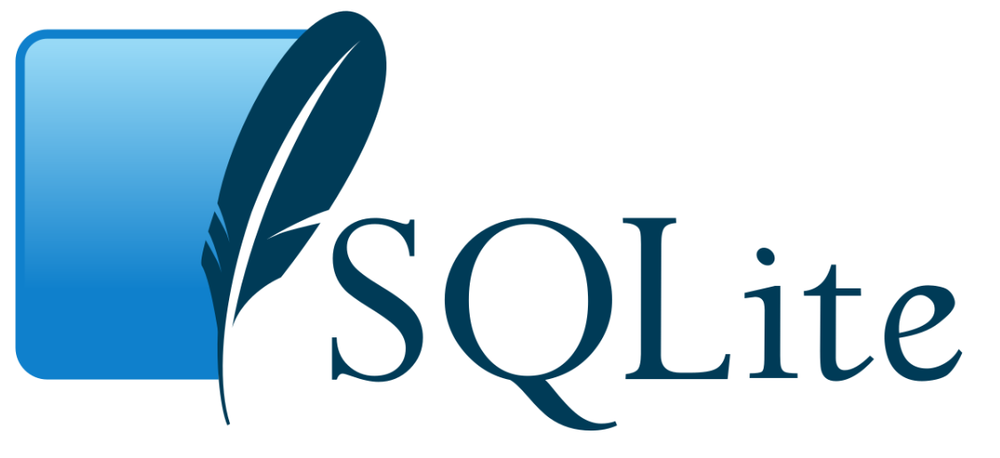

#### Passo 1: Instalar bibliotecas

In [1]:
#!pip install sqlite3 

#### Passo 2: Importar bibliotecas

In [2]:
import sqlite3
import pandas as pd

#### Passo 3: Amostra de dados de entrada

In [3]:
# Exemplo de DataFrame obtido após o scraping
data = {
    "titulo": ["Notebook Dell", "Smartphone Samsung", "Livro Python", "Monitor LG"],
    "preco": [3500.00, 2100.00, 89.90, 899.00],
    "categoria": ["Eletrônicos", "Eletrônicos", "Livros", "Eletrônicos"]
}
df = pd.DataFrame(data)
df

,titulo,preco,categoria
0,Notebook Dell,3500.0,Eletrônicos
1,Smartphone Samsung,2100.0,Eletrônicos
2,Livro Python,89.9,Livros
3,Monitor LG,899.0,Eletrônicos


#### Passo 4: Conexão com banco SQLite

In [4]:
# Conexão com o banco, caso não exista essa tabela ele cria 
conn = sqlite3.connect("produtos.db")

A classe Cursor é uma instância com a qual você pode invocar métodos que executam instruções SQLite e buscam dados dos conjuntos de resultados das consultas. Você pode criar um objeto Cursor usando o método cursor() do objeto/classe Connection.

In [5]:
# Criando o cursor
cursor = conn.cursor()

#### Passo 5: Criando tabela

Nesta etapa utilizaremos a sintaxe: `cursor.execute(""" ... """)`

- O cursor é quem envia comandos SQL para o banco.
- O método execute() executa o SQL que está entre aspas triplas """ ... """.
- Usamos aspas triplas para poder escrever o comando em várias linhas, deixando mais organizado.

In [6]:
# Criando a tabela no banco de dados
cursor.execute('''
    CREATE TABLE IF NOT EXISTS produtos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        titulo TEXT NOT NULL,
        preco REAL NOT NULL,
        categoria TEXT NOT NULL
    );
''')

### Vamos entender cada comando que foi utilizado aqui:

1) `CREATE TABLE IF NOT EXISTS produtos`
- `CREATE TABLE`  cria uma nova tabela no banco.
- `IF NOT EXISTS`  evita erro caso a tabela já exista (sem isso, o comando falharia).
- `produtos`  é o nome da tabela.

2) `id INTEGER PRIMARY KEY AUTOINCREMENT,`
- `id`  nome da coluna.
- `INTEGER`  tipo de dado (número inteiro).
- `PRIMARY KEY`  define que essa coluna é a chave primária da tabela (identificador único de cada linha).
- `AUTOINCREMENT`  cada novo registro recebe automaticamente um valor de ID (1, 2, 3, …).

3) `titulo TEXT NOT NULL,`
- `titulo` → nome da coluna.
- `TEXT` → tipo de dado (texto de tamanho variável).
- `NOT NULL` → esse campo não pode ficar vazio

4) `preco REAL NOT NULL,`
- `preco` nome da coluna.
- `REAL` tipo de dado para números decimais (preço pode ter vírgula/ponto).
- `NOT NULL` não pode ficar em branco.

5) `categoria TEXT NOT NULL`
- `categoria` → nome da coluna.
- `TEXT` → tipo de dado (texto).
- `NOT NULL` → obrigatório.

#### Passo 6: Inserindo dados do DataFrame no banco

In [7]:
for _, row in df.iterrows():
    cursor.execute('''
        INSERT INTO produtos (titulo, preco, categoria)
        VALUES (?, ?, ?)
    ''', (row['titulo'], row['preco'], row['categoria']))

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


### Novamente, vamos entender cada comando
1) `for _, row in df.iterrows():`
- O método `iterrows()` do **Pandas** serve para **percorrer um DataFrame linha por linha**
- Esse método devolve, a cada iteração, um **par** (índice, linha):
- Usando `for _, row` é possível ignorar o índice substituindo o nome da variável por `_`
    - `index, row`  pegaria os dois.
    - `_, row` ignora o índice e pega só a linha

2) `INSERT INTO produtos (titulo, preco, categoria) VALUES (?, ?, ?)", (row["titulo"], row["preco"], row["categoria"])`
- Esse comando SQL insere uma nova linha na tabela produtos
- `INSERT INTO produtos (titulo, preco, categoria)` indica em quais colunas você vai inserir dados.`
- `VALUES (?, ?, ?)`  são **placeholders** (marcadores) para os valores reais.
    - `?` significa "substitua aqui por um valor passado no Python".
- `(row["titulo"], row["preco"], row["categoria"])` é uma tupla com os valores da linha do DataFrame que vão substituir os `?`

#### Passo 7: Consulta SQL

##### Ex 1: Selecionar produtos abaixo de 1000 reais

In [8]:
for row in cursor.execute("SELECT * FROM produtos WHERE preco < 1000"):
    print(row)

(3, 'Livro Python', 89.9, 'Livros')
(4, 'Monitor LG', 899.0, 'Eletrônicos')


- `SELECT *`  busca todas as colunas da tabela.
- `FROM produtos` consulta a tabela produtos.
- `WHERE preco < 1000` aplica um filtro: só traz os produtos cujo preço seja menor que 1000.

##### Ex 2: Top 2 produtos mais caros

In [9]:
for row in cursor.execute("SELECT * FROM produtos ORDER BY preco DESC LIMIT 3"):
    print(row)

(1, 'Notebook Dell', 3500.0, 'Eletrônicos')
(2, 'Smartphone Samsung', 2100.0, 'Eletrônicos')
(4, 'Monitor LG', 899.0, 'Eletrônicos')


1) `SELECT titulo, preco` Pede ao banco apenas as colunas titulo e preco (não traz todas as colunas como no `*`
2) `ORDER BY preco DESC` Ordena os resultados pelo preço (preco) em ordem decrescente (DESC) - (ASC seria crescente, padrão do SQL)
3) `LIMIT 2` Limita o número de registros retornados a 2 linhas apenas

##### Ex 3: Contagem por categorias

In [10]:
for row in cursor.execute("SELECT categoria, COUNT(*) FROM produtos GROUP BY categoria;"):
    print(row)

('Eletrônicos', 3)
('Livros', 1)


1) `SELECT categoria` Seleciona a coluna "categoria"
2) `COUNT(*)` Conta o número de registros
3) `FROM produtos` Da tabela "produtos"
4) `GROUP BY categoria` Agrupa os resultados por categoria

#### Passo 8: Encerra conexão com banco de dados

In [11]:
conn.close()

## 7 Webscraping Sqlite

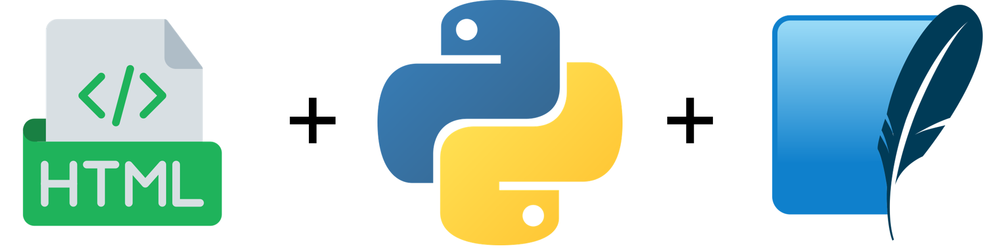

#### Passo 1: Instalar bibliotecas

In [2]:
#!pip install requests
#!pip install beautifulsoup4
#!pip install sqlite3 
#!pip install pandas

#### Passo 2: Importar bibliotecas

In [3]:
import requests
from bs4 import BeautifulSoup
import sqlite3
import pandas as pd

#### Passo 3: Fromatar link de busca

Neste exemplo utilizaremos um site público de testes de scraping

http://books.toscrape.com (feito exatamente para treinar scraping).

In [4]:
# URL base
url = "https://books.toscrape.com/catalogue/category/books_1/page-1.html"

#### Passo 4: Determinar variáveis que para armazenamento
Neste exemplo, iremos utilizar:
- Título
- Preços
- Estoque

In [5]:
titulos, precos, estoque = [], [], []

#### Passo 5: Obter informações do link

In [6]:
response = requests.get(url)
soup = BeautifulSoup(response.text, "html.parser")

#### Passo 5.1: Obter informações dos produtos

In [7]:
# Cada produto está dentro de article.product_pod
livros = soup.find_all("article", class_="product_pod")

In [8]:
livros[0].h3.a['title']

'A Light in the Attic'

In [9]:
# Preço
livros[0].find("p", class_="price_color").text.replace("Â£", "")

'51.77'

In [10]:
# Estoque
livros[0].find("p", class_="instock availability").text.strip() 
# A função strip()em Python serve para remover espaços em branco ou caracteres específicos do início e/ou fim de uma string

'In stock'

#### Passo 6: Coletar dados em escala
Neste exemplo, vamos coletar dados das 5 primeiras páginas

In [11]:
for page in range(1, 5):
    response = requests.get(f"https://books.toscrape.com/catalogue/category/books_1/page-{page}.html")
    soup = BeautifulSoup(response.text, "html.parser")
    
    # Cada produto está dentro de article.product_pod
    livros = soup.find_all("article", class_="product_pod")
    
    for livro in livros:
        # Título
        titulo = livro.h3.a["title"]
        titulos.append(titulo)
        
        # Preço
        preco = livro.find("p", class_="price_color").text.replace("Â£", "")
        precos.append(preco)
        
        # Estoque
        estoque_info = livro.find("p", class_="instock availability").text.strip()
        estoque.append(estoque_info)

print("Coleta concluída!")

Coleta concluída!


#### Passo 7: Criar DataFrame

In [12]:
df = pd.DataFrame({"titulo": titulos, "preco": precos, "estoque": estoque})
df.head()

,titulo,preco,estoque
0,A Light in the Attic,51.77,In stock
1,Tipping the Velvet,53.74,In stock
2,Soumission,50.10,In stock
3,Sharp Objects,47.82,In stock
4,Sapiens: A Brief History of Humankind,54.23,In stock


#### Passo 8: Criar Banco de Dados

In [13]:
conn = sqlite3.connect("livros.db")
cursor = conn.cursor()

#### Passo 9: DDL – Data Definition Language
DDL serve para **definir a estrutura do banco de dados**: criar, alterar e excluir tabelas.

- `CREATE` → cria tabelas e estruturas  
- `ALTER` → modifica a estrutura de tabelas  
- `DROP` → apaga tabelas ou bancos de dados  


In [14]:
cursor.execute('''
    CREATE TABLE IF NOT EXISTS livro (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        titulo TEXT NOT NULL,
        preco REAL NOT NULL,
        estoque TEXT NOT NULL
    );
    ''')
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


##### 9.1: Listar todas tabelas do banco
Neste exemplo iremos utilizaremos a sintaxe `SELECT name FROM sqlite_master;`

- `sqlite_master` é uma tabela especial **interna** do SQLite que guarda **metadados** sobre o banco de dados: tabelas, índices, views e triggers
- `SELECT name` seleciona apenas o nome (`name`) dos objetos armazenados no `sqlite_master`

In [15]:
cursor.execute(''' SELECT name FROM sqlite_master;''')
print(cursor.fetchall()) # Recupera todos os dados da última consulta feita com o cursor 

[('livro',), ('sqlite_sequence',), ('vendas',)]


Como pegar os resultados usando o método `fetch` (buscar)
- `fetchone()` Retorna apenas uma linha do resultado (a próxima disponível). Se não houver mais nada, retorna `None`
- `fetchmany(n)` Retorna as próximas n linhas do resultado.
- `fetchall()` Retorna todas as linhas restantes do resultado em uma lista de tuplas.

##### 9.2: Verificar o esquema da tabela (estrutura das colunas)

In [16]:
cursor.execute('''PRAGMA table_info(livro);''')
for row in cursor.fetchall():
    print(row)


(0, 'id', 'INTEGER', 0, None, 1)
(1, 'titulo', 'TEXT', 1, None, 0)
(2, 'preco', 'REAL', 1, None, 0)
(3, 'estoque', 'TEXT', 1, None, 0)


##### 9.3: Alterar tabela
Nesta etapa utilizaremos o comando `ALTER TABLE` informar a alteração da tabela e o comando `ADD COLUMN` para especificar a alteração

In [17]:
cursor.execute('''ALTER TABLE livro ADD COLUMN categoria TEXT;''')
conn.commit() # Salva as alterações no banco de dados
print("Coluna categoria adicionada com sucesso!")

Coluna categoria adicionada com sucesso!


##### 9.4: Verifica o equema da tabela após incluir coluna coluna

In [18]:
cursor.execute('''PRAGMA table_info(livro);''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'titulo', 'TEXT', 1, None, 0)
(2, 'preco', 'REAL', 1, None, 0)
(3, 'estoque', 'TEXT', 1, None, 0)
(4, 'categoria', 'TEXT', 0, None, 0)


##### 9.5: Remover uma coluna 
Nesta etapa utilizaremos o comando `ALTER TABLE` informar a alteração da tabela e o comando `DROP COLUMN` para especificar a alteração

In [19]:
cursor.execute('''ALTER TABLE livro DROP COLUMN categoria;''')
conn.commit() # Salva as alterações no banco de dados
print("Coluna categoria removida com sucesso!")

Coluna categoria removida com sucesso!


##### 9.6: Verifica o equema da tabela após incluir coluna coluna

In [20]:
cursor.execute('''PRAGMA table_info(livro);''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'titulo', 'TEXT', 1, None, 0)
(2, 'preco', 'REAL', 1, None, 0)
(3, 'estoque', 'TEXT', 1, None, 0)


##### 9.7: Excluir tabela
Primeiro vamos criar uma tabela adicional

In [21]:
cursor.execute('''
    CREATE TABLE IF NOT EXISTS produtos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        titulo TEXT NOT NULL,
        preco REAL NOT NULL,
        estoque TEXT NOT NULL
    );
    ''')
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


##### Listar todas tabelas do banco

In [22]:
cursor.execute(''' SELECT name FROM sqlite_master;''')
print(cursor.fetchall()) # Recupera todos os dados da última consulta feita com o cursor 

[('livro',), ('sqlite_sequence',), ('vendas',), ('produtos',)]


##### Remover tabela do banco

In [23]:
cursor.execute('''DROP TABLE produtos;''')
conn.commit()
print("Tabela produtos removida com sucesso!")

Tabela produtos removida com sucesso!


##### Listar todas tabelas do banco

In [24]:
cursor.execute(''' SELECT name FROM sqlite_master;''')
print(cursor.fetchall()) # Recupera todos os dados da última consulta feita com o cursor 

[('livro',), ('sqlite_sequence',), ('vendas',)]


#### Passo 10: DML – Data Manipulation Language

DML serve para **manipular os dados** dentro das tabelas:

- `INSERT` → inserir registros  
- `UPDATE` → atualizar registros  
- `DELETE` → excluir registros



##### 10.1 `INSERT` (inserir dados)

In [25]:
for _, row in df.iterrows():
    cursor.execute('''
        INSERT INTO livro (titulo, preco, estoque) VALUES (?, ?, ?)
    ''', (row['titulo'], row['preco'], row['estoque']))
conn.commit()

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


##### Verifica quantos registros foram inseridos

In [26]:
cursor.execute(''' SELECT COUNT(*) FROM livro;''')
cursor.fetchone()

(170,)

##### Verifica uma amostra dos registros inseridos

In [27]:
cursor.execute('''SELECT * FROM livro;''')
cursor.fetchmany(5)

[(1, 'A Light in the Attic', 49.0, 'In stock'),
 (2, 'Tipping the Velvet', 53.74, 'In stock'),
 (3, 'Soumission', 50.1, 'In stock'),
 (4, 'Sharp Objects', 47.82, 'In stock'),
 (5, 'Sapiens: A Brief History of Humankind', 54.23, 'In stock')]

##### 10.2: `UPDATE` (atualizar dados)

In [28]:
cursor.execute("UPDATE livro SET preco= 49.00 WHERE titulo= 'A Light in the Attic';")
conn.commit()
print("Valor do livro atualizado")

Valor do livro atualizado


##### Verifica uma amostra dos registros inseridos

In [29]:
cursor.execute('''SELECT * FROM livro;''')
cursor.fetchmany(5)

[(1, 'A Light in the Attic', 49.0, 'In stock'),
 (2, 'Tipping the Velvet', 53.74, 'In stock'),
 (3, 'Soumission', 50.1, 'In stock'),
 (4, 'Sharp Objects', 47.82, 'In stock'),
 (5, 'Sapiens: A Brief History of Humankind', 54.23, 'In stock')]

##### 10.3: Inserir um novo registro no banco

In [30]:
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Python for data analysis', 99.99,'In stock')")
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Python for data science', 89.90,'In stock')")
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Python for data database', 40.45,'In stock')")
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Python for data big data', 79.90,'In stock')")
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Python for data artificial', 150.99,'In stock')")

print("Registros armazenados no banco")

Registros armazenados no banco


##### Verifica quantos registros existem no banco

In [31]:
cursor.execute('''SELECT COUNT(*) FROM livro;''')
cursor.fetchone()

(175,)

##### Verifica uma amostra dos últimos registros inseridos

In [32]:
cursor.execute('''SELECT * FROM livro ORDER BY id DESC;''')
cursor.fetchmany(5)

[(176, 'Python for data artificial', 150.99, 'In stock'),
 (175, 'Python for data big data', 79.9, 'In stock'),
 (174, 'Python for data database', 40.45, 'In stock'),
 (173, 'Python for data science', 89.9, 'In stock'),
 (172, 'Python for data analysis', 99.99, 'In stock')]

##### 10.4: `DELETE` (exclui registros)

In [33]:
cursor.execute("DELETE FROM livro WHERE titulo='Python for data analysis';")
conn.commit()
print("Registro removido")

Registro removido


##### Verifica uma amostra dos últimos registros inseridos

In [34]:
cursor.execute('''SELECT * FROM livro ORDER BY id DESC;''')
cursor.fetchmany(5)

[(176, 'Python for data artificial', 150.99, 'In stock'),
 (175, 'Python for data big data', 79.9, 'In stock'),
 (174, 'Python for data database', 40.45, 'In stock'),
 (173, 'Python for data science', 89.9, 'In stock'),
 (171,
  'Rat Queens, Vol. 3: Demons (Rat Queens (Collected Editions) #11-15)',
  50.4,
  'In stock')]

#### Passo 11: DQL serve para **consultar dados** no banco:

- `SELECT`  
- `WHERE`  
- `ORDER BY`  
- `GROUP BY`  
- Funções de agregação (`COUNT`, `AVG`, `MAX`, `MIN`, `SUM`) 

##### Consulta simples com `fetchone`

In [35]:
cursor.execute("SELECT * FROM livro;")
cursor.fetchone()

(1, 'A Light in the Attic', 49.0, 'In stock')

##### Consulta simples com `fetchmany()`

In [36]:
cursor.execute("SELECT * FROM livro;")
cursor.fetchmany(5)

[(1, 'A Light in the Attic', 49.0, 'In stock'),
 (2, 'Tipping the Velvet', 53.74, 'In stock'),
 (3, 'Soumission', 50.1, 'In stock'),
 (4, 'Sharp Objects', 47.82, 'In stock'),
 (5, 'Sapiens: A Brief History of Humankind', 54.23, 'In stock')]

##### Consulta simples com `fetchall()`

In [37]:
cursor.execute("SELECT * FROM livro;")
cursor.fetchall()

[(1, 'A Light in the Attic', 49.0, 'In stock'),
 (2, 'Tipping the Velvet', 53.74, 'In stock'),
 (3, 'Soumission', 50.1, 'In stock'),
 (4, 'Sharp Objects', 47.82, 'In stock'),
 (5, 'Sapiens: A Brief History of Humankind', 54.23, 'In stock'),
 (6, 'The Requiem Red', 22.65, 'In stock'),
 (7, 'The Dirty Little Secrets of Getting Your Dream Job', 33.34, 'In stock'),
 (8,
  'The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  17.93,
  'In stock'),
 (9,
  'The Boys in the Boat: Nine Americans and Their Epic Quest for Gold at the 1936 Berlin Olympics',
  22.6,
  'In stock'),
 (10, 'The Black Maria', 52.15, 'In stock'),
 (11, 'Starving Hearts (Triangular Trade Trilogy, #1)', 13.99, 'In stock'),
 (12, "Shakespeare's Sonnets", 20.66, 'In stock'),
 (13, 'Set Me Free', 17.46, 'In stock'),
 (14,
  "Scott Pilgrim's Precious Little Life (Scott Pilgrim #1)",
  52.29,
  'In stock'),
 (15, 'Rip it Up and Start Again', 35.02, 'In stock'),
 (16,
  'Our Band Could Be 

#### `WHERE`
##### Consulta com filtro: Livros com preço abaixo de 20 

In [38]:
cursor.execute("SELECT titulo,preco FROM livro WHERE preco < 20;")
cursor.fetchall()

[('The Coming Woman: A Novel Based on the Life of the Infamous Feminist, Victoria Woodhull',
  17.93),
 ('Starving Hearts (Triangular Trade Trilogy, #1)', 13.99),
 ('Set Me Free', 17.46),
 ('In Her Wake', 12.84),
 ('The Four Agreements: A Practical Guide to Personal Freedom', 17.66),
 ("Sophie's World", 15.94),
 ('Maude (1883-1993):She Grew Up with the country', 18.02),
 ('In a Dark, Dark Wood', 19.63),
 ('Untitled Collection: Sabbath Poems 2014', 14.27),
 ('Unicorn Tracks', 18.78),
 ('Tsubasa: WoRLD CHRoNiCLE 2 (Tsubasa WoRLD CHRoNiCLE #2)', 16.28),
 ('This One Summer', 19.49),
 ('Thirst', 17.27),
 ('The Torch Is Passed: A Harding Family Story', 19.09),
 ('The Life-Changing Magic of Tidying Up: The Japanese Art of Decluttering and Organizing',
  16.77),
 ('The Age of Genius: The Seventeenth Century and the Birth of the Modern Mind',
  19.73),
 ('Reskilling America: Learning to Labor in the Twenty-First Century', 19.83),
 ('The Coming Woman: A Novel Based on the Life of the Infamous Fe

#### `ORDER BY`
##### Consulta com ordenação: Top 5 livros mais caros 

In [39]:
cursor.execute("SELECT * FROM livro ORDER BY preco DESC limit 5;")
cursor.fetchall()

[(85, 'Python for data artificial', 150.99, 'In stock'),
 (176, 'Python for data artificial', 150.99, 'In stock'),
 (86, 'Livro 1', 99.99, 'Out of stock'),
 (89, 'Livro 1', 99.99, 'Out of stock'),
 (82, 'Python for data science', 89.9, 'In stock')]

#### `GROUP BY`
##### Consulta com agregação: Quantidade de livros por situação de estoque 

In [40]:
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Livro 1', 99.99,'Out of stock')")
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Livro 2', 89.90,'Out of stock')")
cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Livro 3', 40.45,'Out of stock')")


In [41]:
cursor.execute("SELECT estoque, COUNT(*)FROM livro GROUP BY estoque;")
cursor.fetchall()

[('In stock', 168), ('Out of stock', 8), ('Out of stockk', 1)]

#### `DISTINCT`
##### Consulta com filtro: Contagem de dados distintos

In [42]:
cursor.execute("SELECT COUNT(DISTINCT preco) FROM livro;")
cursor.fetchall()

[(84,)]

In [43]:
cursor.execute("SELECT COUNT(*) FROM livro;")
cursor.fetchall()

[(177,)]

#### `HAVING COUNT(*)`
##### Consulta com filtro: Contagem de dados repetidos

In [44]:
cursor.execute("SELECT preco FROM livro GROUP BY preco HAVING COUNT(*) > 1;")
cursor.fetchall()

[(12.84,),
 (13.99,),
 (14.27,),
 (15.94,),
 (16.28,),
 (16.77,),
 (17.27,),
 (17.46,),
 (17.66,),
 (17.93,),
 (18.02,),
 (18.78,),
 (19.09,),
 (19.49,),
 (19.63,),
 (19.73,),
 (19.83,),
 (20.59,),
 (20.66,),
 (22.5,),
 (22.6,),
 (22.65,),
 (23.11,),
 (23.82,),
 (23.88,),
 (23.89,),
 (25.02,),
 (25.27,),
 (25.52,),
 (26.41,),
 (30.52,),
 (31.05,),
 (31.12,),
 (31.77,),
 (32.24,),
 (33.29,),
 (33.34,),
 (33.63,),
 (34.53,),
 (35.02,),
 (36.89,),
 (37.13,),
 (37.32,),
 (37.59,),
 (38.16,),
 (39.25,),
 (39.58,),
 (40.3,),
 (40.45,),
 (40.76,),
 (41.83,),
 (42.96,),
 (44.18,),
 (45.07,),
 (45.17,),
 (45.22,),
 (47.61,),
 (47.82,),
 (49.0,),
 (49.05,),
 (50.1,),
 (50.27,),
 (50.4,),
 (51.04,),
 (51.33,),
 (52.15,),
 (52.22,),
 (52.29,),
 (53.13,),
 (53.74,),
 (54.11,),
 (54.23,),
 (54.64,),
 (56.06,),
 (56.13,),
 (56.41,),
 (56.5,),
 (57.25,),
 (57.31,),
 (58.11,),
 (79.9,),
 (89.9,),
 (99.99,),
 (150.99,)]

In [45]:
cursor.execute("SELECT estoque FROM livro GROUP BY estoque HAVING COUNT(*) > 1;")
cursor.fetchall()

[('In stock',), ('Out of stock',)]

#### `AVG`
##### Consulta com agregação: Valor médio dos livros 

In [46]:
cursor.execute("SELECT AVG(preco) FROM livro;")
cursor.fetchone()

(40.233333333333334,)

##### Consulta com agregação: Valor médio dos livros  (com arredondamento)

In [47]:
cursor.execute("SELECT ROUND(AVG(preco),2) FROM livro;")
cursor.fetchone()

(40.23,)

#### `MAX`
##### Consulta com agregação: Maior valor entre os livros `MAX`

In [48]:
cursor.execute("SELECT MAX(preco) FROM livro;")
cursor.fetchone()

(150.99,)

#### `MIN`
##### Consulta com agregação: Menor valor entre os livros 

In [49]:
cursor.execute("SELECT MIN(preco) FROM livro;")
cursor.fetchone()

(12.84,)

#### `SUM`
##### Consulta com agregação: Soma do valor dos livros

In [50]:
cursor.execute("SELECT SUM(preco) FROM livro;")
cursor.fetchone()

(7121.3,)

##### Consulta com agregação: Soma do valor dos livros em estoque

In [51]:
cursor.execute("SELECT SUM(preco) FROM livro WHERE estoque= 'In stock';")
cursor.fetchone()

(6430.28,)

##### Consulta com agregação: Soma do valor dos livros sem estoque

In [52]:
cursor.execute("SELECT SUM(preco) FROM livro WHERE estoque= 'Out of stock';")
cursor.fetchone()

(601.12,)

##### Consulta de multiplos valores: Valor Máximo, Medio e Mínimo

In [53]:
cursor.execute("SELECT MAX(preco), MIN(preco), ROUND(AVG(preco),2) FROM livro;")
max, min, med = cursor.fetchone()
print(f"Maior preço: {max}\nMenor preço: {min}\nMédia de preço: {med}")

Maior preço: 150.99
Menor preço: 12.84
Média de preço: 40.23


##### Consulta com Ranking por Preço

In [54]:
cursor.execute("SELECT RANK() OVER (ORDER BY preco DESC) AS rank, titulo, preco FROM livro;")
cursor.fetchall()

[(1, 'Python for data artificial', 150.99),
 (1, 'Python for data artificial', 150.99),
 (3, 'Livro 1', 99.99),
 (3, 'Livro 1', 99.99),
 (3, 'Livro 1', 99.99),
 (6, 'Python for data science', 89.9),
 (6, 'Livro 2', 89.9),
 (6, 'Livro 2', 89.9),
 (6, 'Python for data science', 89.9),
 (6, 'Livro 2', 89.9),
 (11, 'Python for data big data', 79.9),
 (11, 'Python for data big data', 79.9),
 (13, 'The Death of Humanity: and the Case for Life', 58.11),
 (13, 'The Death of Humanity: and the Case for Life', 58.11),
 (15, 'Slow States of Collapse: Poems', 57.31),
 (15, 'Slow States of Collapse: Poems', 57.31),
 (17,
  'Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991',
  57.25),
 (17,
  'Our Band Could Be Your Life: Scenes from the American Indie Underground, 1981-1991',
  57.25),
 (19, 'The Past Never Ends', 56.5),
 (19, 'The Past Never Ends', 56.5),
 (21,
  'The Pioneer Woman Cooks: Dinnertime: Comfort Classics, Freezer Food, 16-Minute Meals, and Other Delici

#### 12: JOINS – Relacionando tabelas

JOINS permitem **combinar dados de várias tabelas**.  
Vamos criar outras tabelas para exemplificar.

##### 12.1 Criar tabela de vendas

In [55]:
cursor.execute('''
    CREATE TABLE IF NOT EXISTS vendas (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        livro_id INTEGER,
        data_venda DATE,
        quantidade INTEGER,
        valor_total REAL,
        cliente TEXT,
    FOREIGN KEY (livro_id) REFERENCES livros(id)
);
''')
conn.commit()
print("Tabela criadas com sucesso!")

Tabela criadas com sucesso!


##### Verifica o esquema da tabela (estrutura das colunas)

In [56]:
cursor.execute('''PRAGMA table_info(vendas);''')
for row in cursor.fetchall():
    print(row)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'livro_id', 'INTEGER', 0, None, 0)
(2, 'data_venda', 'DATE', 0, None, 0)
(3, 'quantidade', 'INTEGER', 0, None, 0)
(4, 'valor_total', 'REAL', 0, None, 0)
(5, 'cliente', 'TEXT', 0, None, 0)


##### 12.2: Inserir dados de exemplo

In [57]:
vendas_exemplo = [
    (1, '2025-01-15', 2, 'João Silva'),
    (5, '2025-01-16', 1, 'Maria Santos'),
    (10, '2025-01-17', 3, 'Pedro Costa'),
    (15, '2025-01-18', 1, 'Ana Oliveira'),
    (20, '2025-01-19', 2, 'Carlos Lima'),
    (25, '2025-01-20', 1, 'Juliana Pereira'),
    (30, '2025-01-21', 2, 'Roberto Alves'),
    (35, '2025-01-22', 1, 'Fernanda Dias'),
    (40, '2025-01-23', 3, 'Ricardo Martins'),
    (45, '2025-01-24', 1, 'Patrícia Souza')
]

for livro_id, data, quantidade, cliente in vendas_exemplo:
    # Buscar preço
    cursor.execute("SELECT preco FROM livro WHERE id = ?", (livro_id,))
    resultado = cursor.fetchone()
    valor_total = round(resultado[0] * quantidade,2)

    cursor.execute('''
        INSERT INTO vendas (livro_id, data_venda, quantidade, valor_total, cliente) 
        VALUES (?, ?, ?, ?, ?)
        ''', (livro_id, data, quantidade, valor_total, cliente))

conn.commit()
print(f"{len(vendas_exemplo)} vendas inseridas com sucesso!")

10 vendas inseridas com sucesso!


##### Verifica dados inseridos 

In [58]:
cursor.execute("SELECT * FROM vendas;")
cursor.fetchall()

[(1, 1, '2025-01-15', 2, 98.0, 'João Silva'),
 (2, 5, '2025-01-16', 1, 54.23, 'Maria Santos'),
 (3, 10, '2025-01-17', 3, 156.45, 'Pedro Costa'),
 (4, 15, '2025-01-18', 1, 35.02, 'Ana Oliveira'),
 (5, 20, '2025-01-19', 2, 90.34, 'Carlos Lima'),
 (6, 25, '2025-01-20', 1, 34.53, 'Juliana Pereira'),
 (7, 30, '2025-01-21', 2, 88.36, 'Roberto Alves'),
 (8, 35, '2025-01-22', 1, 15.94, 'Fernanda Dias'),
 (9, 40, '2025-01-23', 3, 100.89, 'Ricardo Martins'),
 (10, 45, '2025-01-24', 1, 45.07, 'Patrícia Souza'),
 (11, 1, '2025-01-15', 2, 98.0, 'João Silva'),
 (12, 5, '2025-01-16', 1, 54.23, 'Maria Santos'),
 (13, 10, '2025-01-17', 3, 156.45, 'Pedro Costa'),
 (14, 15, '2025-01-18', 1, 35.02, 'Ana Oliveira'),
 (15, 20, '2025-01-19', 2, 90.34, 'Carlos Lima'),
 (16, 25, '2025-01-20', 1, 34.53, 'Juliana Pereira'),
 (17, 30, '2025-01-21', 2, 88.36, 'Roberto Alves'),
 (18, 35, '2025-01-22', 1, 15.94, 'Fernanda Dias'),
 (19, 40, '2025-01-23', 3, 100.89, 'Ricardo Martins'),
 (20, 45, '2025-01-24', 1, 45.07

##### 12.3: Exemplos de JOINs com a tabela existente

In [59]:
print("INNER JOIN entre livro e vendas:")

cursor.execute('''
    SELECT l.titulo, l.preco, v.quantidade, v.valor_total, v.cliente
    FROM livro l
    INNER JOIN vendas v ON v.livro_id = l.id
    ORDER BY v.valor_total DESC;
''')

for row in cursor.fetchall():
    print(f"Título: {row[0]}\nPreço: {row[1]}\nQuantidade: {row[2]}\nValor Total: {row[3]}\nCliente: {row[4]}\n\n")

INNER JOIN entre livro e vendas:
Título: The Black Maria
Preço: 52.15
Quantidade: 3
Valor Total: 156.45
Cliente: Pedro Costa


Título: The Black Maria
Preço: 52.15
Quantidade: 3
Valor Total: 156.45
Cliente: Pedro Costa


Título: You can't bury them all: Poems
Preço: 33.63
Quantidade: 3
Valor Total: 100.89
Cliente: Ricardo Martins


Título: You can't bury them all: Poems
Preço: 33.63
Quantidade: 3
Valor Total: 100.89
Cliente: Ricardo Martins


Título: A Light in the Attic
Preço: 49.0
Quantidade: 2
Valor Total: 98.0
Cliente: João Silva


Título: A Light in the Attic
Preço: 49.0
Quantidade: 2
Valor Total: 98.0
Cliente: João Silva


Título: It's Only the Himalayas
Preço: 45.17
Quantidade: 2
Valor Total: 90.34
Cliente: Carlos Lima


Título: It's Only the Himalayas
Preço: 45.17
Quantidade: 2
Valor Total: 90.34
Cliente: Carlos Lima


Título: Wall and Piece
Preço: 44.18
Quantidade: 2
Valor Total: 88.36
Cliente: Roberto Alves


Título: Wall and Piece
Preço: 44.18
Quantidade: 2
Valor Total: 88.3

In [63]:
# LEFT JOIN - Todos os livros, mesmo os não vendidos
# COALESCE substitui os valores nulos por outro valor
print("LEFT JOIN - Todos os Livros (com vendas):")

cursor.execute('''
    SELECT 
        livro.titulo,
        livro.preco,
        livro.estoque,
        COALESCE(vendas.quantidade, 0) AS quantidade_vendida,
        COALESCE(vendas.valor_total, 0) AS total_vendido
    FROM livro
    LEFT JOIN vendas ON livro.id = vendas.livro_id
    ORDER BY total_vendido DESC;
''')

for row in cursor.fetchall():
    status_venda = "Vendido" if row[3] > 0 else " Não vendido"
    print(f"{row[0]:<80} | R$ {row[1]:6.2f} | {row[2]:<12} | {status_venda}")

LEFT JOIN - Todos os Livros (com vendas):
The Black Maria                                                                  | R$  52.15 | In stock     | Vendido
The Black Maria                                                                  | R$  52.15 | In stock     | Vendido
You can't bury them all: Poems                                                   | R$  33.63 | In stock     | Vendido
You can't bury them all: Poems                                                   | R$  33.63 | In stock     | Vendido
A Light in the Attic                                                             | R$  49.00 | In stock     | Vendido
A Light in the Attic                                                             | R$  49.00 | In stock     | Vendido
It's Only the Himalayas                                                          | R$  45.17 | In stock     | Vendido
It's Only the Himalayas                                                          | R$  45.17 | In stock     | Vendido
Wall and Piece

In [67]:
# 3. JOIN com agregação - Total de vendas por livro
print("JOIN com Agregação - Resumo de Vendas:")

cursor.execute('''
    SELECT 
        livro.titulo,
        livro.preco,
        COUNT(vendas.id) as total_vendas,
        SUM(vendas.quantidade) as total_unidades,
        SUM(vendas.valor_total) as valor_total
    FROM livro
    LEFT JOIN vendas ON livro.rowid = vendas.livro_id
    GROUP BY livro.rowid
    ORDER BY valor_total DESC NULLS LAST;
''')

for row in cursor.fetchall():
    print(f"Título: {row[0]:<40}")
    print(f"Preço: R$ {row[1]:6.2f}")
    print(f" Vendas: {row[2]} transações")
    print(f"Unidades: {row[3] or 0}")
    print(f"Total: R$ {row[4] or 0:.2f}")
    print()   

JOIN com Agregação - Resumo de Vendas:
Título: The Black Maria                         
Preço: R$  52.15
 Vendas: 2 transações
Unidades: 6
Total: R$ 312.90

Título: You can't bury them all: Poems          
Preço: R$  33.63
 Vendas: 2 transações
Unidades: 6
Total: R$ 201.78

Título: A Light in the Attic                    
Preço: R$  49.00
 Vendas: 2 transações
Unidades: 4
Total: R$ 196.00

Título: It's Only the Himalayas                 
Preço: R$  45.17
 Vendas: 2 transações
Unidades: 4
Total: R$ 180.68

Título: Wall and Piece                          
Preço: R$  44.18
 Vendas: 2 transações
Unidades: 4
Total: R$ 176.72

Título: Sapiens: A Brief History of Humankind   
Preço: R$  54.23
 Vendas: 2 transações
Unidades: 2
Total: R$ 108.46

Título: Without Borders (Wanderlove #1)         
Preço: R$  45.07
 Vendas: 2 transações
Unidades: 2
Total: R$ 90.14

Título: Rip it Up and Start Again               
Preço: R$  35.02
 Vendas: 2 transações
Unidades: 2
Total: R$ 70.04

Título: Black Dust 

In [68]:
# 4. JOIN com filtro WHERE
print("JOIN com Filtro - Livros em Estoque com Vendas:")

cursor.execute('''
    SELECT 
        livro.titulo,
        livro.estoque,
        vendas.quantidade,
        vendas.data_venda,
        vendas.cliente
    FROM livro
    INNER JOIN vendas ON livro.rowid = vendas.livro_id
    WHERE livro.estoque = 'In stock'
    ORDER BY vendas.data_venda DESC;
''')

for row in cursor.fetchall():
    print(f"Título: {row[0]}")
    print(f"Estoque: {row[1]}")
    print(f"Quantidade: {row[2]}")
    print(f"Data: {row[3]}")
    print(f"Cliente: {row[4]}")
    print()


JOIN com Filtro - Livros em Estoque com Vendas:
Título: Without Borders (Wanderlove #1)
Estoque: In stock
Quantidade: 1
Data: 2025-01-24
Cliente: Patrícia Souza

Título: Without Borders (Wanderlove #1)
Estoque: In stock
Quantidade: 1
Data: 2025-01-24
Cliente: Patrícia Souza

Título: You can't bury them all: Poems
Estoque: In stock
Quantidade: 3
Data: 2025-01-23
Cliente: Ricardo Martins

Título: You can't bury them all: Poems
Estoque: In stock
Quantidade: 3
Data: 2025-01-23
Cliente: Ricardo Martins

Título: Sophie's World
Estoque: In stock
Quantidade: 1
Data: 2025-01-22
Cliente: Fernanda Dias

Título: Sophie's World
Estoque: In stock
Quantidade: 1
Data: 2025-01-22
Cliente: Fernanda Dias

Título: Wall and Piece
Estoque: In stock
Quantidade: 2
Data: 2025-01-21
Cliente: Roberto Alves

Título: Wall and Piece
Estoque: In stock
Quantidade: 2
Data: 2025-01-21
Cliente: Roberto Alves

Título: Black Dust
Estoque: In stock
Quantidade: 1
Data: 2025-01-20
Cliente: Juliana Pereira

Título: Black Dust

In [70]:
# 5. Múltiplos JOINS (se tivesse outras tabelas)
print("Estatísticas Gerais:")

# Total de livros
cursor.execute("SELECT COUNT(*) FROM livro")
total_livros = cursor.fetchone()[0]

# Livros com vendas
cursor.execute("SELECT COUNT(DISTINCT livro_id) FROM vendas")
livros_com_vendas = cursor.fetchone()[0]

# Total arrecadado
cursor.execute("SELECT SUM(valor_total) FROM vendas")
total_arrecadado = cursor.fetchone()[0] or 0

print(f"Total de livros: {total_livros}")
print(f"Livros com vendas: {livros_com_vendas}")
print(f"Total arrecadado: R$ {total_arrecadado:.2f}")
print(f"Percentual vendido: {(livros_com_vendas/total_livros)*100:.1f}%")

Estatísticas Gerais:
Total de livros: 177
Livros com vendas: 10
Total arrecadado: R$ 1437.66
Percentual vendido: 5.6%


#### 13: Transações – BEGIN, COMMIT e ROLLBACK

Uma transação é um conjunto de operações que devem ser executadas juntas.  

- `BEGIN` → inicia a transação  
- `COMMIT` → confirma as alterações  
- `ROLLBACK` → desfaz as alterações (caso de erro)  

In [71]:
try:
    conn.execute("BEGIN;")
    cursor.execute("INSERT INTO livro (titulo, preco, estoque) VALUES ('Livro Teste', 29.99, 'In stock')") # Novo registro 
    raise Exception("Erro proposital para teste de rollback")  # Simula um erro
    conn.commit()   
except:
    conn.rollback()
    print("Transação revertida devido a erro.")

Transação revertida devido a erro.


#### Passo 13: Encerra conexão com banco de dados

In [72]:
cursor.close()
conn.close()
print("Conexão com o banco de dados encerrada.")

Conexão com o banco de dados encerrada.


## 8 Exercicio Sqlite

## Exercícios de Python e SQLite

* Nome: Letícia Souza Almeida
* Matéria: LABD
* Professor: Rafael Orsi 
* Data: 21/09/26


### <font color ="lightgreen">Importando Bibliotecas </font>

In [1]:
import requests
from bs4 import BeautifulSoup
import sqlite3
import pandas as pd

### <font color ="lightgreen">Parte 1: Configuração do Banco de Dados </font>

#### Criando o Banco de Dados

In [2]:
conn = sqlite3.connect('empresa.db')
cursor = conn.cursor()
print("Conexão com o banco de dados estabelecida.")

Conexão com o banco de dados estabelecida.


#### Criando Tabela e Verificação

Crie uma tabela chamada funcionários com as seguintes colunas:

* id(INTEGER,
* chave primária, incremento automático)
* nome(TEXTO, não nulo)
* cargo(TEXTO, não nulo)
* salario(REAL)
* data_contratacao(TEXT, não nulo)

In [3]:
# Criando a tabela no banco de dados
cursor.execute('''
    CREATE TABLE IF NOT EXISTS funcionarios (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome TEXT NOT NULL,
        cargo TEXT NOT NULL,
        salario REAL NOT NULL,
        data_contratacao TEXT NOT NULL
    );
''')

In [4]:
# Verificando a estrutura da tabela funcionarios
estrutura = cursor.execute("PRAGMA table_info(funcionarios);").fetchall()

for coluna in estrutura:
    print(coluna)

(0, 'id', 'INTEGER', 0, None, 1)
(1, 'nome', 'TEXT', 1, None, 0)
(2, 'cargo', 'TEXT', 1, None, 0)
(3, 'salario', 'REAL', 1, None, 0)
(4, 'data_contratacao', 'TEXT', 1, None, 0)


### <font color ="lightgreen">Parte 2: Manipulação de Dados (DML)</font>

#### Inserindo Dados 

In [5]:
cursor.execute(''' 
    INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) 
    VALUES 
        ('João Silva', 'Analista de Sistemas', 5000.00, '2022-01-15'),
        ('Maria Oliveira', 'Gerente de Projetos', 7500.00, '2021-03-10'),
        ('Carlos Souza', 'Desenvolvedor Front-end', 4500.00, '2023-06-01'),
        ('Ana Costa', 'Designer UX/UI', 4800.00, '2022-11-20'),
        ('Pedro Lima', 'Engenheiro de Dados', 7000.00, '2021-08-05');
''')

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


#### Consultando os Dados 

In [6]:
for row in cursor.execute("SELECT * FROM funcionarios"):
    print(row)

(1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15')
(2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10')
(3, 'Carlos Souza', 'Desenvolvedor Front-end', 4500.0, '2023-06-01')
(4, 'Ana Costa', 'Designer UX/UI', 4800.0, '2022-11-20')
(5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05')


#### Filtros com WHERE 

* Selecione apenas os funcionários com salário superior a R$ 5.000.
* Selecione os funcionários que trabalham como 'Gerente'.

In [7]:
print("Funcionários com salário superior a 5000:\n")
for row in cursor.execute("SELECT * FROM funcionarios WHERE salario > 5000"):
    print(row)

Funcionários com salário superior a 5000:

(2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10')
(5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05')


In [8]:
print("Funcionários que trabalham como Gerente:\n")
# LIKE faz com que pesquise tudo o que tenha gerente, não preciando ser exatamente o texto
for row in cursor.execute("SELECT * FROM funcionarios WHERE cargo LIKE '%Gerente%'"):
    print(row)

Funcionários que trabalham como Gerente:

(2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10')


#### Atualização de Dados 

Aumentando o salário da Ana Costa em 10%

In [26]:
# 1.1 -> representa o aumento de 10% no salário atual
cursor.execute("UPDATE funcionarios SET salario= (salario * 1.1) WHERE nome= 'Ana Costa';")
conn.commit() # Precisa salvar as alterações 
print("Valor do salário da Ana Costa atualizado")

Valor do salário da Ana Costa atualizado


#### Exclusão de Dados 

In [10]:
cursor.execute("DELETE FROM funcionarios WHERE nome='Carlos Souza';")
conn.commit()
print("Registro removido")

Registro removido


#### Contando o número de funcionários 

In [11]:
cursor.execute("SELECT COUNT(*) FROM funcionarios;")
cursor.fetchone()

(4,)

### <font color ="lightgreen">Parte 3: Agregação e Ordenação</font>

#### Funções de agregação ( SUM, AVG, MAX, MIN):

In [12]:
max_salario= cursor.execute("SELECT MAX(salario) FROM funcionarios;").fetchone()

min_salario= cursor.execute("SELECT MIN(salario) FROM funcionarios;").fetchone()

soma_salarios= cursor.execute("SELECT SUM(salario) FROM funcionarios;").fetchone()

media_salarios= cursor.execute("SELECT ROUND(AVG(salario),2) FROM funcionarios;").fetchone()

print("Funções de agregação:\n")
print(f"Salário máximo: {max_salario}")
print(f"Salário mínimo: {min_salario}")
print(f"Soma dos salários: {soma_salarios}")
print(f"Média dos salários: {media_salarios}")

Funções de agregação:

Salário máximo: (7500.0,)
Salário mínimo: (5000.0,)
Soma dos salários: (24780.0,)
Média dos salários: (6195.0,)


#### Agrupamento de dados ( GROUP BY):

* Calcule um salário médio para cada cargo.
* Conte quantos funcionários existem em cada cargo.

In [13]:
# Criando novos funcionários para demonstrar a função GROUP BY
cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Bruno Martins', 'Analista de Sistemas', 5200.00, '2024-02-12')"),
cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Juliana Rocha', 'Gerente de Projetos', 8200.00, '2023-09-18')"),
cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Rafael Mendes', 'Engenheiro de Dados', 6800.00, '2024-01-25')")

In [14]:
cursor.execute("SELECT cargo, ROUND(AVG(salario), 2) FROM funcionarios GROUP BY cargo;")
cursor.fetchall()

[('Analista de Sistemas', 5100.0),
 ('Designer UX/UI', 5280.0),
 ('Engenheiro de Dados', 6900.0),
 ('Gerente de Projetos', 7850.0)]

In [15]:
cursor.execute("SELECT cargo, COUNT(*) FROM funcionarios GROUP BY cargo;")
cursor.fetchall()

[('Analista de Sistemas', 2),
 ('Designer UX/UI', 1),
 ('Engenheiro de Dados', 2),
 ('Gerente de Projetos', 2)]

#### Ordenação (ORDER BY):

* Selecione todos os funcionários e ordens de maior para o menor salário.
* Selecione todos os funcionários e ordene-os por nome em ordem alfabética.

In [16]:
cursor.execute("SELECT RANK() OVER (ORDER BY salario DESC) AS rank, nome, salario FROM funcionarios;")
cursor.fetchall()

[(1, 'Juliana Rocha', 8200.0),
 (2, 'Maria Oliveira', 7500.0),
 (3, 'Pedro Lima', 7000.0),
 (4, 'Rafael Mendes', 6800.0),
 (5, 'Ana Costa', 5280.0),
 (6, 'Bruno Martins', 5200.0),
 (7, 'João Silva', 5000.0)]

In [17]:
cursor.execute("SELECT * FROM funcionarios ORDER BY funcionarios.nome ASC;")
cursor.fetchall()

[(4, 'Ana Costa', 'Designer UX/UI', 5280.0, '2022-11-20'),
 (6, 'Bruno Martins', 'Analista de Sistemas', 5200.0, '2024-02-12'),
 (1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15'),
 (7, 'Juliana Rocha', 'Gerente de Projetos', 8200.0, '2023-09-18'),
 (2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10'),
 (5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05'),
 (8, 'Rafael Mendes', 'Engenheiro de Dados', 6800.0, '2024-01-25')]

### <font color ="lightgreen">Parte 4: Transações e RollBack</font>

#### Simulação de transação:

* Iniciar uma transação.
* Insira um novo funcionário na tabela.
* Simule um erro (por exemplo, dividindo por zero ou forçando um erro) para acionar o except.
* Utilize conn.rollback()para reverter a transação e garantir que o novo funcionário não seja salvo no banco de dados.

In [19]:
try:
    conn.execute("BEGIN;")
    cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Victor Lapa', 'Analista', 5000.00, '2023-01-01')") # Novo registro
    raise Exception("Erro proposital para teste de rollback")  # Simula um erro
    conn.commit()   
except:
    conn.rollback()
    print("Transação revertida devido a erro.")

Transação revertida devido a erro.


#### Transação com COMMIT:

* Inicie uma nova transação.
* Insira um novo funcionário.
* Não force o erro e use conn.commit()para salvar a operação permanentemente.
* Verifique se o novo funcionário agora faz parte da tabela.

In [20]:
try:
    conn.execute("BEGIN;")
    cursor.execute("INSERT INTO funcionarios (nome, cargo, salario, data_contratacao) VALUES ('Victor Lapa', 'Analista', 5000.00, '2023-01-01')") # Novo registro
    conn.commit() 
except:
    conn.rollback()
    print("Transação revertida devido a erro.")

In [22]:
cursor.execute("SELECT * FROM funcionarios;")
cursor.fetchall()

[(1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15'),
 (2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10'),
 (4, 'Ana Costa', 'Designer UX/UI', 5280.0, '2022-11-20'),
 (5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05'),
 (6, 'Victor Lapa', 'Analista', 5000.0, '2023-01-01')]

### <font color ="lightgreen">Parte 5: Joins e Múltiplas Tabelas</font>

#### Criação de uma segunda tabela:
Crie uma nova tabela chamada departamentos com as colunas:
* id(INTEGER, chave primária, incremento automático)
* nome_departamento(TEXTO, não nulo)
* localizacao(TEXTO)

In [23]:
cursor.execute('''
    CREATE TABLE IF NOT EXISTS departamentos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome_departamento TEXT NOT NULL,
        localizacao TEXT  
    );
    ''')
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


In [25]:
cursor.execute(''' 
    INSERT INTO departamentos (nome_departamento, localizacao) 
    VALUES 
        ("Desenvolvimento Software", "São Paulo"),
        ("Diretores", "Rio de Janeiro"),
        ("Dados", "Belo Horizonte");
''')

print("Dados inseridos com sucesso!")

Dados inseridos com sucesso!


##### Alterando Tabela e Atualizando Dados

In [29]:
cursor.execute("""
    ALTER TABLE funcionarios
    ADD COLUMN departamento_id INTEGER
    REFERENCES departamentos(id);
""")

conn.commit()
print("Coluna departamento_id adicionada com sucesso!")

Coluna departamento_id adicionada com sucesso!
Coluna departamento_id adicionada com sucesso!


In [30]:
# Relacionando os Funcionários ao seu departamento
cursor.execute("""
    UPDATE funcionarios
    SET departamento_id = (
        SELECT id
        FROM departamentos
        WHERE nome_departamento =
            CASE
                WHEN cargo LIKE '%Gerente%' THEN 'Diretores'
                WHEN cargo LIKE '%Dados%' THEN 'Dados'
                ELSE 'Desenvolvimento Software'
            END
    );
""")

conn.commit()
print("Funcionários associados aos departamentos com sucesso!")

Funcionários associados aos departamentos com sucesso!


In [32]:
cursor.execute("SELECT * FROM funcionarios;")
cursor.fetchall()

[(1, 'João Silva', 'Analista de Sistemas', 5000.0, '2022-01-15', 1),
 (2, 'Maria Oliveira', 'Gerente de Projetos', 7500.0, '2021-03-10', 2),
 (4, 'Ana Costa', 'Designer UX/UI', 5808.000000000001, '2022-11-20', 1),
 (5, 'Pedro Lima', 'Engenheiro de Dados', 7000.0, '2021-08-05', 3),
 (6, 'Victor Lapa', 'Analista', 5000.0, '2023-01-01', 1)]

#### Inner Join:

Crie uma consulta que combine as tabelas funcionarios e departamentos para exibir o nome de cada funcionário junto com o nome do seu departamento.

In [33]:
print("INNER JOIN entre Funcionários e Departamentos:")

cursor.execute('''
    SELECT f.nome, f.cargo, f.salario, d.nome_departamento
    FROM funcionarios f
    INNER JOIN departamentos d ON f.departamento_id = d.id;
''')

for row in cursor.fetchall():
    print(f"Nome: {row[0]}\nCargo: {row[1]}\nSalário: {row[2]}\nDepartamento: {row[3]}\n\n")

INNER JOIN entre Funcionários e Departamentos:
Nome: João Silva
Cargo: Analista de Sistemas
Salário: 5000.0
Departamento: Desenvolvimento Software


Nome: Maria Oliveira
Cargo: Gerente de Projetos
Salário: 7500.0
Departamento: Diretores


Nome: Ana Costa
Cargo: Designer UX/UI
Salário: 5808.000000000001
Departamento: Desenvolvimento Software


Nome: Pedro Lima
Cargo: Engenheiro de Dados
Salário: 7000.0
Departamento: Dados


Nome: Victor Lapa
Cargo: Analista
Salário: 5000.0
Departamento: Desenvolvimento Software




#### Left Join:

1. Crie uma nova tabela chamada projetos com as colunas id e nome_projeto.

2. Crie uma tabela de particular funcionarios_projetos com funcionario_id e projeto_id para representar a relação de N para N.

3. Use um LEFT JOIN para listar todos os funcionários e, se houver, o nome do projeto em que estão.

In [34]:
# Criando a tabela projetos
cursor.execute("""
    CREATE TABLE IF NOT EXISTS projetos (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        nome_projeto TEXT NOT NULL
    );
""")

conn.commit()
print("Tabela projetos criada com sucesso!")

Tabela projetos criada com sucesso!


In [35]:
# Inserindo valores na tabela projetos 
cursor.execute("""
    INSERT INTO projetos (nome_projeto)
    VALUES 
        ("Sistema de Vendas"),
        ("Aplicativo Mobile"),
        ("Plataforma de Dados"),
        ("Redesign do Site");
""")

conn.commit()
print("Projetos inseridos com sucesso!")

Projetos inseridos com sucesso!


In [37]:
# Verificando os projetos inseridos
cursor.execute("SELECT * FROM projetos;")
cursor.fetchall()

[(1, 'Sistema de Vendas'),
 (2, 'Aplicativo Mobile'),
 (3, 'Plataforma de Dados'),
 (4, 'Redesign do Site')]

In [38]:
# Criando a tabela associativa para a relação N:N
cursor.execute("""
    CREATE TABLE IF NOT EXISTS funcionarios_projetos (
        funcionario_id INTEGER NOT NULL,
        projeto_id INTEGER NOT NULL,
        PRIMARY KEY (funcionario_id, projeto_id),
        FOREIGN KEY (funcionario_id) REFERENCES funcionarios(id),
        FOREIGN KEY (projeto_id) REFERENCES projetos(id)
    );
""")

conn.commit()
print("Tabela funcionarios_projetos criada com sucesso!")

Tabela funcionarios_projetos criada com sucesso!


In [39]:
# Inserindo relações entre funcionários e projetos
cursor.execute("""
    INSERT INTO funcionarios_projetos (funcionario_id, projeto_id)
    VALUES
        (1, 1),
        (1, 2),
        (2, 3),
        (4, 4),
        (5, 3),
        (7, 1),
        (7, 2);
""")

conn.commit()
print("Relações entre funcionários e projetos inseridas com sucesso!")

Relações entre funcionários e projetos inseridas com sucesso!


In [49]:
# Left Join entre funcionários e projetos
print("LEFT JOIN entre Funcionários e Projetos:\n")

cursor.execute('''
    SELECT 
        f.nome,
        f.cargo,
        p.nome_projeto
    FROM funcionarios f
    LEFT JOIN funcionarios_projetos fp
        ON f.id = fp.funcionario_id
    LEFT JOIN projetos p
        ON fp.projeto_id = p.id;
''')

for row in cursor.fetchall():
    print(f"Nome: {row[0]:<40}")
    print(f"Cargo: {row[1]:<30}")
    print(f"Projeto: {row[2] or 'Sem projeto':<40}")
    print()   

LEFT JOIN entre Funcionários e Projetos:

Nome: João Silva                              
Cargo: Analista de Sistemas          
Projeto: Sistema de Vendas                       

Nome: João Silva                              
Cargo: Analista de Sistemas          
Projeto: Aplicativo Mobile                       

Nome: Maria Oliveira                          
Cargo: Gerente de Projetos           
Projeto: Plataforma de Dados                     

Nome: Ana Costa                               
Cargo: Designer UX/UI                
Projeto: Redesign do Site                        

Nome: Pedro Lima                              
Cargo: Engenheiro de Dados           
Projeto: Plataforma de Dados                     

Nome: Victor Lapa                             
Cargo: Analista                      
Projeto: Sem projeto                             



In [50]:
# Fechando a conexão 
conn.close()

### <font color ="lightgreen">Parte 6: DCL (Controle de Dados)</font>

No seu notebook, explique em markdown a diferença entre DDL, DML, DQL e DCL,
focando em para que o DCL seja usado.

* **DDL:** (Data Definition Language) Definir e alterar estrutura do banco de dados (Create, Alter, Drop, Truncade)
* **DML:** (Data Manipulation Language) São os comandos que interagem com os dados dentro das tabelas. (Insert, Update, Delete)
* **DQL:** (Data Query Languag) São os comandos de consulta. (Select)
* **DCL:** (Data Control Language) São os comandos para controlar a parte de segurança do banco de dados, permissões. (Grant, Revoke)
* **DTL:** (Data Transaction Language) São os comandos para controle de transação. (Begin, Commit, Rollback)

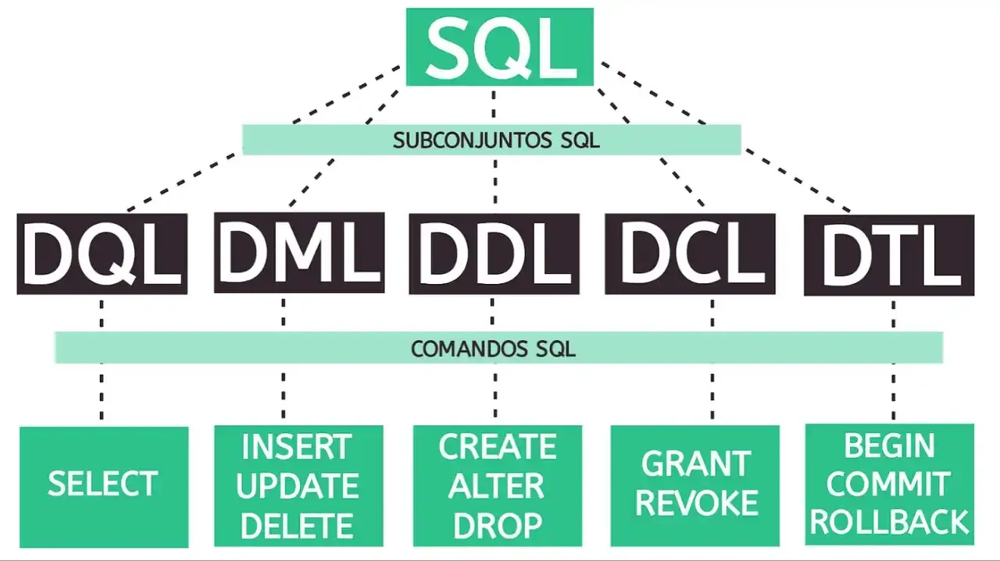

## 8 Join

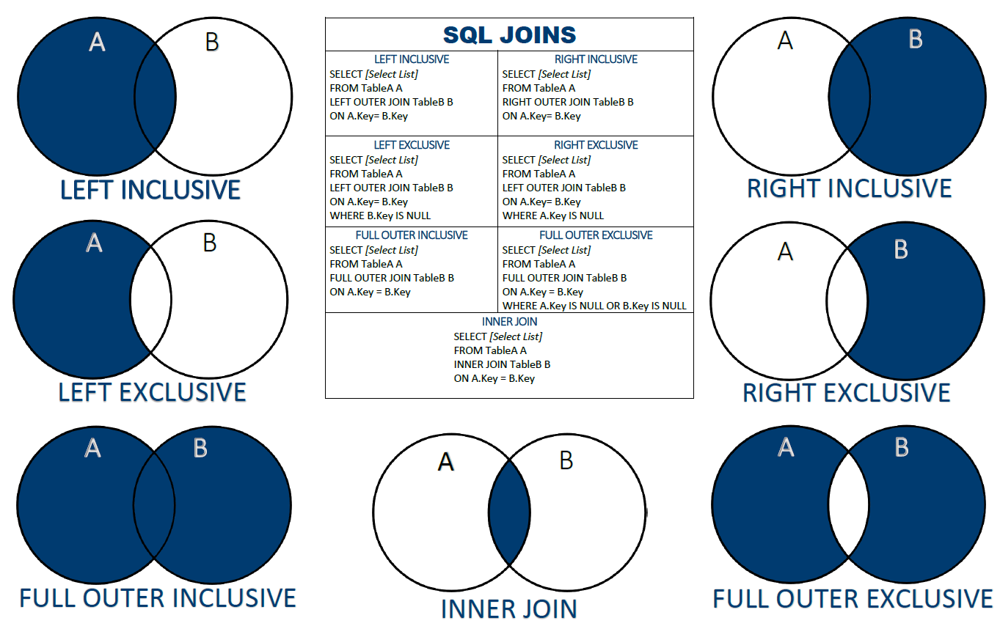

#### 1. Importar Bibliotecas

In [1]:
import sqlite3
import pandas as pd

#### 2. Criar conexão com banco de dados em memória

In [2]:
conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

#### 3. Criar tabelas

In [3]:
# Tabela 1: Funcionarios
cursor.execute("""
CREATE TABLE Funcionarios (
id INTEGER PRIMARY KEY,
nome TEXT,
dep_id INTEGER
);
""")

# Tabela 2: Departamentos
cursor.execute("""
CREATE TABLE Departamentos (
id INTEGER PRIMARY KEY,
departamento TEXT
);
""")

#### 4. Inserir dados nas tabelas

In [4]:
# Inserir dados em Funcionarios
cursor.executemany("INSERT INTO Funcionarios VALUES (?, ?, ?)", [
(1, 'Ana', 10),
(2, 'Bruno', 20),
(3, 'Carla', None),
(4, 'Daniel', 30)
])

# Inserir dados em Departamentos
cursor.executemany("INSERT INTO Departamentos VALUES (?, ?)", [
(10, 'RH'),
(20, 'TI'),
(40, 'Marketing')
])

conn.commit()

#### 5. Visualizar tabelas

In [5]:
cursor.execute("SELECT * FROM funcionarios;")
pd.DataFrame(cursor.fetchall(), columns = ['id','nome','dep_id'])

,id,nome,dep_id
0,1,Ana,10.0
1,2,Bruno,20.0
2,3,Carla,NaN
3,4,Daniel,30.0


In [6]:
cursor.execute("SELECT * FROM departamentos;")
pd.DataFrame(cursor.fetchall(), columns = ['id','departamento'])

,id,departamento
0,10,RH
1,20,TI
2,40,Marketing


### INNER JOIN:

`INNER JOIN` é um formato comum de join, que retorna dados apenas quando as duas tabelas tem chaves correspondentes na cláusula ON do join.

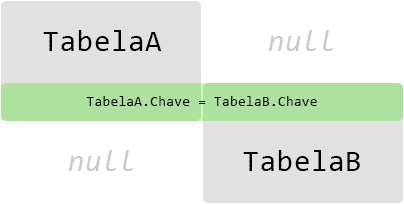

In [ ]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
INNER JOIN Departamentos d
ON f.dep_id = d.id;
''')
inner_join_result = cursor.fetchall()
pd.DataFrame(inner_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI


### LEFT JOIN

`LEFT OUTER JOIN` ou simplesmente `LEFT JOIN` é um dos formatos mais usados de join, que retorna a Tabela A inteira e apenas os registros que coincidirem com a igualdade do join na Tabela B (ou campos nulos para os campos sem correspondência).

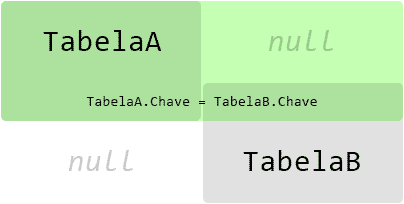

In [8]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
LEFT JOIN Departamentos d
ON f.dep_id = d.id;
''')
left_join_result = cursor.fetchall()
pd.DataFrame(left_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI
2,Carla,NaN
3,Daniel,NaN


### RIGHT JOIN

`RIGHT OUTER JOIN` ou simplesmente `RIGHT JOIN` segue o mesmo raciocínio do LEFT JOIN, mas se aplicando à tabela B em vez da A:

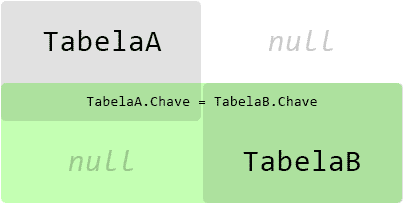

In [12]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
RIGHT JOIN Departamentos d
ON f.dep_id = d.id;
''')
right_join_result = cursor.fetchall()
pd.DataFrame(right_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI
2,NaN,Marketing


### FULL JOIN 

Conhecida como `OUTER JOIN` ou simplesmente `FULL JOIN`, este retorna todos os registros de ambas as tabelas.

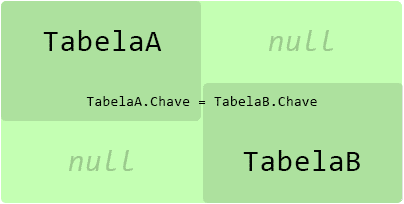

Obs: SQLite não suporta FULL JOIN diretamente. Então simulamos com UNION de LEFT JOIN e RIGHT JOIN.

In [13]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
FULL OUTER JOIN Departamentos d
    ON f.dep_id = d.id;
''')

full_join_result = cursor.fetchall()
pd.DataFrame(full_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Bruno,TI
2,Carla,NaN
3,Daniel,NaN
4,NaN,Marketing


### CROSS JOIN: retorna o produto cartesiano entre as duas tabelas.

Basicamente é o produto cartesiano entre as duas tabelas. Para cada linha de Tabela A, são retornadas todas as linhas de Tabela B.

É mais fácil entender o CROSS JOIN como um "Join sem cláusula ON", ou seja, todas as combinações de linhas de A e B são devolvidas. Inclusive, se você fizer um CROSS JOIN com cláusula ON, ele "vira" um mero INNER JOIN.

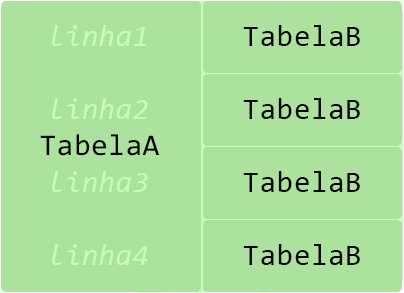

In [11]:
cursor.execute('''
SELECT f.nome, d.departamento
FROM Funcionarios f
CROSS JOIN Departamentos d;
''')
cross_join_result = cursor.fetchall()
pd.DataFrame(cross_join_result, columns=["nome", "departamento"])

,nome,departamento
0,Ana,RH
1,Ana,TI
2,Ana,Marketing
3,Bruno,RH
4,Bruno,TI
5,Bruno,Marketing
6,Carla,RH
7,Carla,TI
8,Carla,Marketing
9,Daniel,RH


## 9 Forma Normal Fn

# Normalização de Banco de Dados (1FN a 6FN)
Este notebook demonstra passo a passo a normalização de um conjunto de dados fictício de pedidos, clientes e produtos.

Vamos evoluir desde uma tabela não normalizada até a 6ª Forma Normal (6FN), mostrando exemplos práticos em Python com pandas.

In [1]:
import pandas as pd
import numpy as np

def show(title, df):
    print(f"\n=== {title} ===")
    display(df)

## Tabela inicial (não normalizada)
A tabela possui múltiplos produtos em colunas (`produto1`, `produto2`), bem como telefones e e-mails em formato de lista separada por ponto e vírgula.

In [2]:

pedidos_raw = pd.DataFrame([
    {
        "pedido_id": 1,
        "data_pedido": "2025-09-20",
        "cliente_nome": "Ana Silva",
        "cliente_endereco": "Rua A, 123",
        "cidade": "São Paulo",
        "estado": "SP",
        "telefones": "11-99999-0001;11-99999-0002",
        "emails": "ana@example.com;ana.silva@empresa.com",
        "produto1": "Lápis",
        "preco1": 1.50,
        "produto2": "Caderno",
        "preco2": 10.00
    },
    {
        "pedido_id": 2,
        "data_pedido": "2025-09-21",
        "cliente_nome": "João Souza",
        "cliente_endereco": "Av. B, 456",
        "cidade": "Campinas",
        "estado": "SP",
        "telefones": "19-98888-1111",
        "emails": "joao@example.com",
        "produto1": "Caneta",
        "preco1": 2.00,
        "produto2": "Caderno",
        "preco2": 10.00
    },
    {
        "pedido_id": 3,
        "data_pedido": "2025-09-22",
        "cliente_nome": "Maria Costa",
        "cliente_endereco": "Rua C, 789",
        "cidade": "São Paulo",
        "estado": "SP",
        "telefones": "11-97777-3333;11-96666-4444",
        "emails": "maria@example.com",
        "produto1": "Borracha",
        "preco1": 0.75,
        "produto2": None,
        "preco2": None
    }
])
show("Tabela inicial (não normalizada)", pedidos_raw)


=== Tabela inicial (não normalizada) ===


,pedido_id,data_pedido,cliente_nome,cliente_endereco,cidade,estado,telefones,emails,produto1,preco1,produto2,preco2
0,1,2025-09-20,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com,Lápis,1.50,Caderno,10.0
1,2,2025-09-21,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com,Caneta,2.00,Caderno,10.0
2,3,2025-09-22,Maria Costa,"Rua C, 789",São Paulo,SP,11-97777-3333;11-96666-4444,maria@example.com,Borracha,0.75,NaN,NaN


## Primeira Forma Normal (1FN)
- Remove grupos repetidos (produto1, produto2)
- Cria uma linha por produto do pedido

In [3]:
rows = []
product_pairs = [(1, 'produto1', 'preco1'), (2, 'produto2', 'preco2')]
for _, r in pedidos_raw.iterrows():
    for _, produto_col, preco_col in product_pairs:
        produto = r[produto_col]
        preco = r[preco_col]
        if pd.notna(produto):
            rows.append({
                "pedido_id": r["pedido_id"],
                "data_pedido": r["data_pedido"],
                "cliente_nome": r["cliente_nome"],
                "cliente_endereco": r["cliente_endereco"],
                "cidade": r["cidade"],
                "estado": r["estado"],
                "telefones": r["telefones"],
                "emails": r["emails"],
                "produto": produto,
                "preco": preco
            })
pedidos_1fn = pd.DataFrame(rows)
show("Pedidos (1FN)", pedidos_1fn)


=== Pedidos (1FN) ===


,pedido_id,data_pedido,cliente_nome,cliente_endereco,cidade,estado,telefones,emails,produto,preco
0,1,2025-09-20,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com,Lápis,1.50
1,1,2025-09-20,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com,Caderno,10.00
2,2,2025-09-21,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com,Caneta,2.00
3,2,2025-09-21,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com,Caderno,10.00
4,3,2025-09-22,Maria Costa,"Rua C, 789",São Paulo,SP,11-97777-3333;11-96666-4444,maria@example.com,Borracha,0.75


## Segunda Forma Normal (2FN)
- Elimina dependência parcial da chave composta (pedido_id, produto).
- Criamos tabelas: `Clientes`, `Pedidos`, `Itens_Pedido`. 

In [4]:
clientes = pedidos_1fn[["cliente_nome","cliente_endereco","cidade","estado","telefones","emails"]].drop_duplicates().reset_index(drop=True)
clientes = clientes.reset_index().rename(columns={"index":"cliente_id"})
clientes["cliente_id"] = clientes["cliente_id"] + 1
clientes = clientes[["cliente_id","cliente_nome","cliente_endereco","cidade","estado","telefones","emails"]]
show("Clientes (2FN)", clientes)

pedidos = pedidos_1fn[["pedido_id","data_pedido","cliente_nome","cliente_endereco"]].drop_duplicates().reset_index(drop=True)
pedidos = pedidos.merge(clientes[["cliente_id","cliente_nome","cliente_endereco"]], on=["cliente_nome","cliente_endereco"], how="left")
pedidos = pedidos[["pedido_id","data_pedido","cliente_id"]]
show("Pedidos (2FN)", pedidos)

itens_pedido = pedidos_1fn[["pedido_id","produto","preco"]].reset_index(drop=True)
show("Itens_Pedido (2FN)", itens_pedido)


=== Clientes (2FN) ===


,cliente_id,cliente_nome,cliente_endereco,cidade,estado,telefones,emails
0,1,Ana Silva,"Rua A, 123",São Paulo,SP,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com
1,2,João Souza,"Av. B, 456",Campinas,SP,19-98888-1111,joao@example.com
2,3,Maria Costa,"Rua C, 789",São Paulo,SP,11-97777-3333;11-96666-4444,maria@example.com



=== Pedidos (2FN) ===


,pedido_id,data_pedido,cliente_id
0,1,2025-09-20,1
1,2,2025-09-21,2
2,3,2025-09-22,3



=== Itens_Pedido (2FN) ===


,pedido_id,produto,preco
0,1,Lápis,1.50
1,1,Caderno,10.00
2,2,Caneta,2.00
3,2,Caderno,10.00
4,3,Borracha,0.75


## Terceira Forma Normal (3FN)
- Remove dependências transitivas (`cidade → estado`).
- Criamos tabela `Cidades` e referenciamos por `cidade_id`. 

In [5]:
cidades = clientes[["cidade","estado"]].drop_duplicates().reset_index(drop=True)
cidades = cidades.reset_index().rename(columns={"index":"cidade_id"})
cidades["cidade_id"] = cidades["cidade_id"] + 1
cidades = cidades[["cidade_id","cidade","estado"]]
show("Cidades (3FN)", cidades)

clientes_3fn = clientes.merge(cidades, on=["cidade","estado"], how="left")
clientes_3fn = clientes_3fn[["cliente_id","cliente_nome","cliente_endereco","cidade_id","telefones","emails"]]
show("Clientes (após 3FN)", clientes_3fn)


=== Cidades (3FN) ===


,cidade_id,cidade,estado
0,1,São Paulo,SP
1,2,Campinas,SP



=== Clientes (após 3FN) ===


,cliente_id,cliente_nome,cliente_endereco,cidade_id,telefones,emails
0,1,Ana Silva,"Rua A, 123",1,11-99999-0001;11-99999-0002,ana@example.com;ana.silva@empresa.com
1,2,João Souza,"Av. B, 456",2,19-98888-1111,joao@example.com
2,3,Maria Costa,"Rua C, 789",1,11-97777-3333;11-96666-4444,maria@example.com


## Forma Normal de Boyce-Codd (BCNF)
- Elimina dependências funcionais anômalas.
- Exemplo: `produto → preco`. Criamos tabela `Produtos`. 

In [6]:
produtos = itens_pedido[["produto","preco"]].drop_duplicates().reset_index(drop=True)
produtos = produtos.reset_index().rename(columns={"index":"produto_id"})
produtos["produto_id"] = produtos["produto_id"] + 1
produtos = produtos[["produto_id","produto","preco"]].rename(columns={"preco":"preco_unitario"})
show("Produtos (BCNF)", produtos)

itens_pedido_bcnf = itens_pedido.merge(produtos[["produto_id","produto"]], on="produto", how="left")
itens_pedido_bcnf = itens_pedido_bcnf[["pedido_id","produto_id"]]
show("Itens_Pedido (após BCNF)", itens_pedido_bcnf)


=== Produtos (BCNF) ===


,produto_id,produto,preco_unitario
0,1,Lápis,1.50
1,2,Caderno,10.00
2,3,Caneta,2.00
3,4,Borracha,0.75



=== Itens_Pedido (após BCNF) ===


,pedido_id,produto_id
0,1,1
1,1,2
2,2,3
3,2,2
4,3,4


## Quarta Forma Normal (4FN)
- Elimina dependências multivaloradas.
- Telefones e Emails de clientes são separados em tabelas próprias. 

In [7]:
telefones_rows = []
for _, r in clientes_3fn.iterrows():
    cliente_id = r["cliente_id"]
    telefones_raw = r["telefones"]
    if pd.notna(telefones_raw):
        for t in str(telefones_raw).split(";"):
            t = t.strip()
            if t:
                telefones_rows.append({"cliente_id": cliente_id, "telefone": t})
telefones = pd.DataFrame(telefones_rows)
show("Telefones (4FN)", telefones)

emails_rows = []
for _, r in clientes_3fn.iterrows():
    cliente_id = r["cliente_id"]
    emails_raw = r["emails"]
    if pd.notna(emails_raw):
        for e in str(emails_raw).split(";"):
            e = e.strip()
            if e:
                emails_rows.append({"cliente_id": cliente_id, "email": e})
emails = pd.DataFrame(emails_rows)
show("Emails (4FN)", emails)

clientes_4fn = clientes_3fn[["cliente_id","cliente_nome","cliente_endereco","cidade_id"]]
show("Clientes (após 4FN)", clientes_4fn)


=== Telefones (4FN) ===


,cliente_id,telefone
0,1,11-99999-0001
1,1,11-99999-0002
2,2,19-98888-1111
3,3,11-97777-3333
4,3,11-96666-4444



=== Emails (4FN) ===


,cliente_id,email
0,1,ana@example.com
1,1,ana.silva@empresa.com
2,2,joao@example.com
3,3,maria@example.com



=== Clientes (após 4FN) ===


,cliente_id,cliente_nome,cliente_endereco,cidade_id
0,1,Ana Silva,"Rua A, 123",1
1,2,João Souza,"Av. B, 456",2
2,3,Maria Costa,"Rua C, 789",1


## Quinta Forma Normal (5FN)
- Elimina dependências de junção.
- Exemplo com relação ternária (Fornecedor, Produto, Região). 

In [8]:
fornece = pd.DataFrame([
    {"fornecedor":"F1","produto":"P1","regiao":"Norte"},
    {"fornecedor":"F1","produto":"P2","regiao":"Norte"},
    {"fornecedor":"F2","produto":"P1","regiao":"Sul"},
    {"fornecedor":"F2","produto":"P2","regiao":"Sul"},
])
show("R - Fornece (tripla)", fornece)

fornece_fp = fornece[["fornecedor","produto"]].drop_duplicates().reset_index(drop=True)
fornece_fr = fornece[["fornecedor","regiao"]].drop_duplicates().reset_index(drop=True)
fornece_pr = fornece[["produto","regiao"]].drop_duplicates().reset_index(drop=True)
show("Fornece_FP", fornece_fp)
show("Fornece_FR", fornece_fr)
show("Fornece_PR", fornece_pr)

# Reconstrução por junção
temp = fornece_fp.merge(fornece_pr, on="produto")
recon = temp.merge(fornece_fr, on="fornecedor", how="left", suffixes=('_pr','_fr'))
reg_cols = [c for c in recon.columns if 'regiao' in c]
if reg_cols:
    recon['regiao'] = recon[reg_cols[0]]
recon = recon[['fornecedor','produto','regiao']].drop_duplicates().reset_index(drop=True)
show("Reconstrução de R", recon)


=== R - Fornece (tripla) ===


,fornecedor,produto,regiao
0,F1,P1,Norte
1,F1,P2,Norte
2,F2,P1,Sul
3,F2,P2,Sul



=== Fornece_FP ===


,fornecedor,produto
0,F1,P1
1,F1,P2
2,F2,P1
3,F2,P2



=== Fornece_FR ===


,fornecedor,regiao
0,F1,Norte
1,F2,Sul



=== Fornece_PR ===


,produto,regiao
0,P1,Norte
1,P2,Norte
2,P1,Sul
3,P2,Sul



=== Reconstrução de R ===


,fornecedor,produto,regiao
0,F1,P1,Norte
1,F1,P1,Sul
2,F1,P2,Norte
3,F1,P2,Sul
4,F2,P1,Norte
5,F2,P1,Sul
6,F2,P2,Norte
7,F2,P2,Sul


## Sexta Forma Normal (6FN)
- Decomposição extrema, geralmente usada em cenários temporais.
- Exemplo: histórico de preços de produtos em períodos distintos.

In [9]:
prod_precos = pd.DataFrame([
    {"produto_id": 1, "start":"2025-01-01", "end":"2025-06-30", "preco": 1.40},
    {"produto_id": 1, "start":"2025-07-01", "end": None,       "preco": 1.50},
    {"produto_id": 2, "start":"2025-01-01", "end": None,       "preco": 10.00},
])
show("Produto_Precos (6FN - temporal)", prod_precos)


=== Produto_Precos (6FN - temporal) ===


,produto_id,start,end,preco
0,1,2025-01-01,2025-06-30,1.4
1,1,2025-07-01,NaN,1.5
2,2,2025-01-01,NaN,10.0


## Resumo
- **1FN** → remove grupos repetidos
- **2FN** → remove dependência parcial
- **3FN** → remove dependência transitiva
- **BCNF** → remove dependências funcionais anômalas
- **4FN** → remove dependências multivaloradas
- **5FN** → remove dependências de junção
- **6FN** → granularidade máxima (ex.: temporal)

## 10 Introduçãomysql

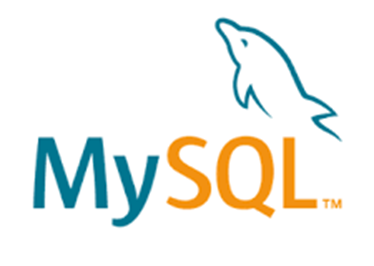

# Introdução ao MySQL com Python

#### Passo 1: Instalar bibliotecas

In [30]:
%pip install pymysql

Note: you may need to restart the kernel to use updated packages.


#### Passo 2: Importar bibliotecas

In [31]:
import pymysql

#### Passo 3: Conectar no MySQL

In [32]:
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

#### Passo 4:  Criar banco

In [33]:
cursor.execute("CREATE DATABASE IF NOT EXISTS meubanco")
print("Banco criado com sucesso!")

Banco criado com sucesso!


#### Passo 5: Conferir no Workbench
- Abra o **MySQL Workbench**
- No painel esquerdo (Schemas), clique em Refresh
- Você deve ver o banco `meubanco`

#### Passo 6: Verificar conexão

In [34]:
# Encerrar conexão com banco de dados
conn.close()

In [35]:
# Testa se a conexão está ativa
if conn.open:
    print("Conexão ativa!")
else:
    print('Banco de dados desconectado')

Banco de dados desconectado


In [36]:
# Criar conexão 
if not conn.open:
    conn.ping(reconnect=True)

C:\Users\48694260808\AppData\Local\Temp\ipykernel_23924\628939375.py:3: DeprecationWarning: The 'reconnect' argument is deprecated. Create a new connection if you want to reconnect.
  conn.ping(reconnect=True)


In [37]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

(None,)

In [38]:
# Verificar bancos existentes
cursor.execute("SHOW DATABASES;")
cursor.fetchall()

(('information_schema',),
 ('meubanco',),
 ('mysql',),
 ('performance_schema',),
 ('sakila',),
 ('sys',),
 ('techburguer',),
 ('techdelivery',),
 ('world',))

In [39]:
# Conectar ao banco existente
cursor.execute("USE meubanco")

0

In [40]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('meubanco',)

In [41]:
# Encerrar conexão com banco de dados
conn.close()

In [42]:
# Forma completa para conectar
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="meubanco"  
)
cursor = conn.cursor()

In [43]:
# Verificar em qual banco está conectado
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('meubanco',)

#### Passo 7: Criar tabela

In [44]:
# Conecta com banco de dados
cursor = conn.cursor()

# Cria Tabela
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(255),
    preco DECIMAL(10,2),
    categoria VARCHAR(100)
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


#### Passo 8: Inserir dados

In [45]:
dados = [
    ("Notebook Dell", 3500.00, "Eletrônicos"),
    ("Smartphone Samsung", 2100.00, "Eletrônicos"),
    ("Livro Python", 89.90, "Livros"),
    ("Monitor LG", 899.00, "Eletrônicos")
]
cursor.executemany("INSERT INTO produtos (titulo, preco, categoria) VALUES (%s, %s, %s)", dados)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [46]:
# Encerrar conexão com banco de dados
conn.close()

#### Passo 9: Visualizar no Workbench
- Clique em `meubanco` → abra a aba de queries.

Rode: `SELECT * FROM produtos;`

#### Passo 9: inserindo novos dados pelo Workbench
Ainda no Workbench, rode:

`INSERT INTO produtos (titulo, preco, categoria)`

`VALUES ("Mouse Gamer", 199.90, "Eletrônicos");`

#### Passo 10: Consulta de teste no Python

In [47]:
# Conecta com Banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root",
    database="meubanco"  
)
cursor = conn.cursor()

In [48]:
cursor.execute("SELECT * FROM produtos")
for row in cursor.fetchall():
    print(row)

(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Monitor LG', Decimal('899.00'), 'Eletrônicos')


# Neste exercício exploramos Python e Workbench no mesmo banco MySQL
- O banco é o mesmo: Python e Workbench são apenas **duas portas de acesso**.
- Você pode **criar, inserir e consultar** dados em um ambiente e ver os resultados no outro.
- Isso mostra a importância de **separar a camada de aplicação (Python) da camada de dados (MySQL).**

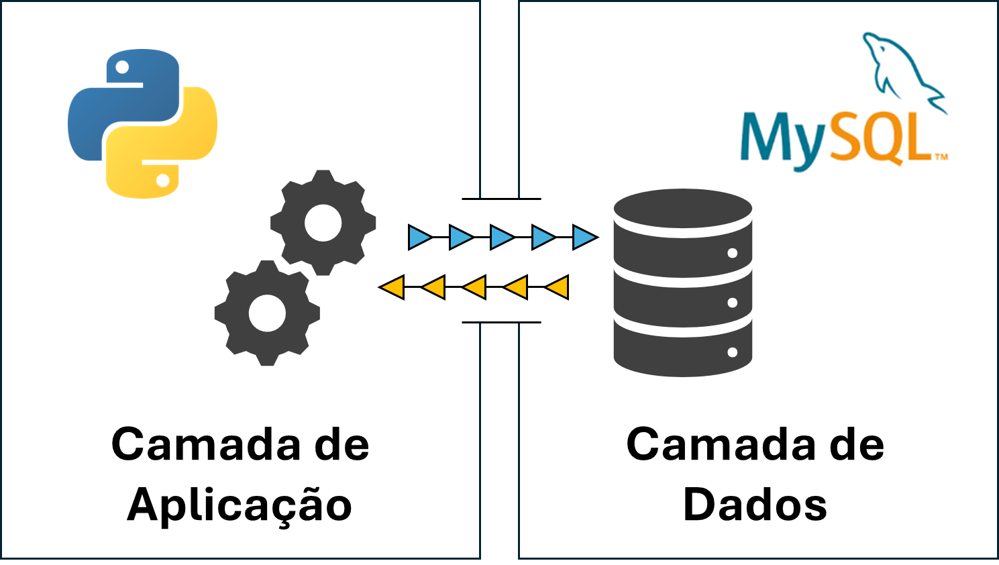

### Onde o banco de dados fica salvo? 

- Diferente do **SQLite** em que o banco é criado como **um arquivo** `.db` **no diretório atual** (mesma pasta do notebook/script)
- O **MySQL guarda os bancos em uma pasta interna do servido**. Geralmente em:
 
  `C:\ProgramData\MySQL\MySQL Server 8.0\Data\`
  
 **Atenção:** 
 - Essa pasta é oculta, tem que habilitar **Mostrar arquivos ocultos**
 - Você **não manipula diretamente esses arquivos**, sempre acessa via o servidor MySQL (Workbench, Python, terminal).

### Apagar o banco de dados

- Atenção! Esse comando apaga todo o banco de dados (tabelas, dados, índices, etc.).

- **Não há undo** – depois de rodar, não tem como recuperar a não ser que você tenha backup.

In [49]:
# Exclui banco de dados
cursor.execute("DROP DATABASE IF EXISTS meubanco")

# Salvar. commit() grava de forma definitiva as alterações feitas no banco de dados na transação atual
conn.commit()

# Fecha o canal de envio de comandos
cursor.close()

# Encerrar conexão com banco de dados
conn.close()

---
# Exercícios de fixação

> **Orientação:** execute cada exercício em sequência. Quando necessário, confira o resultado também no MySQL Workbench.


## Exercício 1: Conexão com o MySQL

Crie uma conexão com o servidor MySQL utilizando `pymysql.connect()`. Depois:

1. crie um cursor;
2. execute `SELECT DATABASE();`;
3. imprima o resultado;
4. verifique se a conexão está ativa.

**Objetivo:** praticar conexão, cursor e execução de uma consulta simples.


In [81]:
# Escreva sua solução aqui
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

In [29]:
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

(None,)

In [51]:
if conn.open:
    print("Conexão ativa!")
else:
    print('Banco de dados desconectado')

Conexão ativa!


## Exercício 2: Criando um banco para os exercícios

Crie um banco de dados chamado `loja_treinamento`, caso ele ainda não exista. Em seguida, selecione esse banco com o comando `USE` e confirme, por meio de `SELECT DATABASE();`, que ele está ativo.

**Objetivo:** praticar `CREATE DATABASE`, `USE` e verificação do banco selecionado.


In [52]:
# Escreva sua solução aqui
cursor.execute("create database if not exists loja_treinamento")
cursor.execute("use loja_treinamento")
print("Banco criado e conectado com sucesso!")


Banco criado e conectado com sucesso!


In [53]:
cursor.execute("SELECT DATABASE();")
cursor.fetchone()

('loja_treinamento',)

## Exercício 3: Criando uma tabela

No banco `loja_treinamento`, crie uma tabela chamada `clientes` com a seguinte estrutura:

| Campo | Tipo | Regra |
|---|---|---|
| `id` | INT | chave primária e `AUTO_INCREMENT` |
| `nome` | VARCHAR(150) | nome do cliente |
| `cidade` | VARCHAR(100) | cidade do cliente |
| `idade` | INT | idade do cliente |

Utilize `CREATE TABLE IF NOT EXISTS`.

**Objetivo:** praticar criação de tabelas e definição de campos.


In [54]:
# Escreva sua solução aqui
cursor.execute("""
CREATE TABLE IF NOT EXISTS clientes (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(150),
    cidade VARCHAR(100),
    idade int
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


## Exercício 4: Inserindo vários registros

Insira **pelo menos cinco clientes** na tabela `clientes`. Utilize uma lista de tuplas em Python e o método `executemany()`. Ao final, confirme a transação com `conn.commit()`.

Exemplo de estrutura dos dados:

```python
dados = [
    ("Ana", "São Paulo", 28),
    ("Carlos", "Campinas", 35)
]
```

Acrescente pelo menos três registros diferentes dos apresentados no exemplo.

**Objetivo:** praticar inserção em lote e persistência com `commit()`.


In [56]:
# Escreva sua solução aqui
dados = [
    ("Ana", "São Paulo", 28),
    ("Carlos", "Campinas", 35),
    ("Letícia", "São Paulo", 19),
    ("Lapa", "Rio de Janeiro", 21),
    ("Kauan", "Belo Horizonte", 12)
]
cursor.executemany("INSERT INTO clientes (nome, cidade, idade) VALUES (%s, %s, %s)", dados)
conn.commit()
print("Dados inseridos!")



Dados inseridos!


## Exercício 5: Consultando os dados

Faça uma consulta que retorne **todos os registros** da tabela `clientes`. Utilize `fetchall()` e um laço `for` para imprimir cada linha separadamente.

Depois, responda observando a saída:

1. Quantos clientes foram cadastrados?
2. Qual informação aparece na primeira posição de cada tupla retornada?

**Objetivo:** praticar `SELECT`, `fetchall()` e leitura do resultado no Python.


In [59]:
# Escreva sua solução aqui
cursor.execute("SELECT * FROM clientes")
clientes = cursor.fetchall()

print(f"Clientes cadastrados: {len(clientes)}")
for row in clientes:
    print(row)

Clientes cadastrados: 5
(1, 'Ana', 'São Paulo', 28)
(2, 'Carlos', 'Campinas', 35)
(3, 'Letícia', 'São Paulo', 19)
(4, 'Lapa', 'Rio de Janeiro', 21)
(5, 'Kauan', 'Belo Horizonte', 12)


## Exercício 6: Consultas com filtros

Realize as seguintes consultas na tabela `clientes`:

1. exiba apenas os clientes com idade maior que 30 anos;
2. exiba apenas os clientes de uma cidade escolhida por você;
3. exiba somente as colunas `nome` e `cidade`.

Imprima os resultados de cada consulta.

**Objetivo:** praticar consultas `SELECT` com seleção de colunas e filtros.


In [67]:
# Consulta 1
print("Consulta 1")
cursor.execute("select * from clientes where idade > 30;")
filtro_idade = cursor.fetchall()
print(filtro_idade)
print("-" * 30)

# Consulta 2
print("Consulta 2")
cursor.execute("select * from clientes where cidade = 'São Paulo';")
filtro_cidade = cursor.fetchall()
print(filtro_cidade)
print("-" * 30)

# Consulta 3
print("Consulta 3")
cursor.execute("select nome, cidade from clientes;")
filtro_nome = cursor.fetchall()
print(filtro_nome)
print("-" * 30)



Consulta 1
((2, 'Carlos', 'Campinas', 35),)
------------------------------
Consulta 2
((1, 'Ana', 'São Paulo', 28), (3, 'Letícia', 'São Paulo', 19))
------------------------------
Consulta 3
(('Ana', 'São Paulo'), ('Carlos', 'Campinas'), ('Letícia', 'São Paulo'), ('Lapa', 'Rio de Janeiro'), ('Kauan', 'Belo Horizonte'))
------------------------------


## Exercício 7: Cadastro de produtos

Crie uma tabela chamada `produtos_treinamento` com os campos `id`, `titulo`, `preco` e `categoria`, seguindo a estrutura utilizada anteriormente no notebook. Depois:

1. cadastre pelo menos seis produtos de duas ou mais categorias;
2. confirme os dados com `commit()`;
3. consulte todos os produtos;
4. mostre apenas os produtos de uma categoria escolhida por você.

**Objetivo:** integrar criação de tabela, inserção e consulta em uma única atividade.


In [68]:
# Escreva sua solução aqui
cursor.execute("""
CREATE TABLE IF NOT EXISTS produtos_treinamento (
    id INT AUTO_INCREMENT PRIMARY KEY,
    titulo VARCHAR(255),
    preco DECIMAL(10,2),
    categoria VARCHAR(100)
)
""")
print("Tabela criada com sucesso!")


Tabela criada com sucesso!


In [69]:
dados = [
    ("Notebook Dell", 3500.00, "Eletrônicos"),
    ("Smartphone Samsung", 2100.00, "Eletrônicos"),
    ("Livro Python", 89.90, "Livros"),
    ("Mouse Gamer", 109.00, "Eletrônicos"),
    ("Livro Data Science", 70.00, "Livros"),
    ("Luminária Noturna", 299.90, "Decoração")
]
cursor.executemany("INSERT INTO produtos_treinamento (titulo, preco, categoria) VALUES (%s, %s, %s)", dados)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [71]:
cursor.execute("SELECT * FROM produtos_treinamento")
for row in cursor.fetchall():
    print(row)

(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Mouse Gamer', Decimal('109.00'), 'Eletrônicos')
(5, 'Livro Data Science', Decimal('70.00'), 'Livros')
(6, 'Luminária Noturna', Decimal('299.90'), 'Decoração')


In [72]:
cursor.execute("SELECT * FROM produtos_treinamento where categoria = 'Livros';")
for row in cursor.fetchall():
    print(row)

(3, 'Livro Python', Decimal('89.90'), 'Livros')
(5, 'Livro Data Science', Decimal('70.00'), 'Livros')


## Exercício 8: Python e Workbench no mesmo banco

Este exercício deve ser realizado utilizando os dois ambientes.

1. Pelo **Python**, insira um novo produto em `produtos_treinamento`.
2. No **MySQL Workbench**, execute uma consulta e verifique se o produto aparece.
3. Pelo **Workbench**, insira outro produto.
4. Volte ao **Python**, execute novamente o `SELECT` e confirme se o novo registro aparece.

Ao final, explique em poucas linhas por que Python e Workbench conseguem visualizar os mesmos dados.

**Objetivo:** consolidar a diferença entre o banco de dados MySQL e as ferramentas utilizadas para acessá-lo.


In [73]:
# Use esta célula para inserir/consultar os dados pelo Python
cursor.execute("INSERT INTO produtos_treinamento (titulo, preco, categoria) VALUES ('Quadro Van Gogh', 490.00, 'Decoração')")
conn.commit()
print("Dados inseridos!")

cursor.execute("SELECT * FROM produtos_treinamento")
for row in cursor.fetchall():
    print(row)


Dados inseridos!
(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Mouse Gamer', Decimal('109.00'), 'Eletrônicos')
(5, 'Livro Data Science', Decimal('70.00'), 'Livros')
(6, 'Luminária Noturna', Decimal('299.90'), 'Decoração')
(7, 'Quadro Van Gogh', Decimal('490.00'), 'Decoração')


In [83]:
cursor.execute("SELECT * FROM produtos_treinamento")
for row in cursor.fetchall():
    print(row)

(1, 'Notebook Dell', Decimal('3500.00'), 'Eletrônicos')
(2, 'Smartphone Samsung', Decimal('2100.00'), 'Eletrônicos')
(3, 'Livro Python', Decimal('89.90'), 'Livros')
(4, 'Mouse Gamer', Decimal('109.00'), 'Eletrônicos')
(5, 'Livro Data Science', Decimal('70.00'), 'Livros')
(6, 'Luminária Noturna', Decimal('299.90'), 'Decoração')
(7, 'Quadro Van Gogh', Decimal('490.00'), 'Decoração')
(8, 'Kindle', Decimal('699.90'), 'Eletrônicos')


**Resposta conceitual:**

Escreva aqui sua explicação.


## Desafio final

Sem copiar diretamente os exemplos anteriores, desenvolva um pequeno cadastro para um contexto de sua escolha, como **livros, alunos, filmes, veículos ou funcionários**. Sua solução deve:

1. criar uma nova tabela;
2. possuir uma chave primária com `AUTO_INCREMENT`;
3. possuir pelo menos três atributos além do `id`;
4. inserir pelo menos cinco registros com `executemany()`;
5. executar uma consulta que mostre todos os registros;
6. executar pelo menos uma consulta com filtro;
7. utilizar `commit()` após as inserções;
8. fechar o cursor e a conexão ao final.

**Objetivo:** aplicar de forma integrada os conceitos trabalhados no notebook.


In [84]:
# Desenvolva aqui sua solução completa
cursor.execute("""
create table if not exists funcionarios_treinamento (
    id int auto_increment primary key,
    nome varchar(100),
    cargo varchar(100),
    salario decimal(10,2)
)
""")
print("Tabela criada com sucesso!")

Tabela criada com sucesso!


In [85]:
funcionarios = [
    ("Marcos", "TI", 5500.00),
    ("Cauã", "Analista de Dados", 4500.00),
    ("Leo", "Designer", 4000.00),
    ("Pedro", "TI", 2600.00),
    ("Luiz", "Gerente", 7000.00)
]
cursor.executemany("INSERT INTO funcionarios_treinamento (nome, cargo, salario) VALUES (%s, %s, %s)", funcionarios)
conn.commit()
print("Dados inseridos!")

Dados inseridos!


In [86]:
cursor.execute("select * from funcionarios_treinamento;")
for row in cursor.fetchall():
    print(row)

(1, 'Marcos', 'TI', Decimal('5500.00'))
(2, 'Cauã', 'Analista de Dados', Decimal('4500.00'))
(3, 'Leo', 'Designer', Decimal('4000.00'))
(4, 'Pedro', 'TI', Decimal('2600.00'))
(5, 'Luiz', 'Gerente', Decimal('7000.00'))


In [87]:
cursor.execute("select * from funcionarios_treinamento where cargo = 'TI';")
print("Funcionários com cargo de TI:")
for row in cursor.fetchall():
    print(row)

Funcionários com cargo de TI:
(1, 'Marcos', 'TI', Decimal('5500.00'))
(4, 'Pedro', 'TI', Decimal('2600.00'))


In [89]:
cursor.execute("select * from funcionarios_treinamento where salario > 4000.00;")
print("Funcionários com salário acima de 4000.00:")
for row in cursor.fetchall():
    print(row)

Funcionários com salário acima de 4000.00:
(1, 'Marcos', 'TI', Decimal('5500.00'))
(2, 'Cauã', 'Analista de Dados', Decimal('4500.00'))
(5, 'Luiz', 'Gerente', Decimal('7000.00'))


In [90]:
# Fecha o canal de envio de comandos
cursor.close()

# Encerrar conexão com banco de dados
conn.close()

## 11 Procedures Functions Triggers

# Procedures, Functions e Triggers
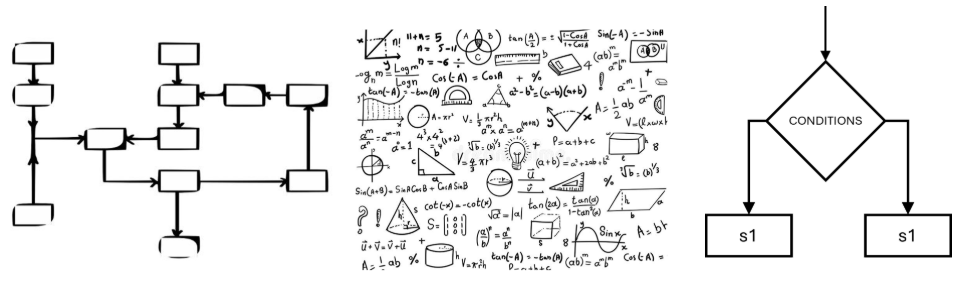

## Objetivos
- Criar e usar **Stored Procedures**, **Functions** e **Triggers** no **MySQL**.
- Conectar ao MySQL usando **PyMySQL** a partir do **Python**.
- Registrar e analisar **auditoria** de alterações (triggers).
- Visualizar resultados com **pandas** e **matplotlib**.

#### Passo 1: Importar bibliotecas

In [4]:
%pip install pymysql
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------  9.4/9.5 MB 84.2 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 32.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 42.4 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 74.0 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- -------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pymysql
import pandas as pd
import matplotlib.pyplot as plt

#### Passo 2: Conexão ao MySQL (criando `conn` e `cursor`)

In [6]:
# 1. Criar conexão com o servidor MySQL (sem selecionar banco ainda)
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root", 
    autocommit=False  # manteremos controle explícito de commit
)
cursor = conn.cursor()
print("Conexão criada com sucesso!")

Conexão criada com sucesso!


#### Passo 3: Criar o banco de dados e selecioná-lo
**O que faremos agora:**  
1. Criar o banco `empresa_dados` (se não existir).  
2. Selecionar o banco com `USE`.  
3. Conferir qual banco está em uso.

In [7]:
cursor.execute('DROP DATABASE IF EXISTS pft') # Remove banco das aulas passadas
cursor.execute('CREATE DATABASE IF NOT EXISTS pft')
print('Banco criado')

Banco criado


In [8]:
cursor.execute('USE pft')

0

#### Passo 4: Criar tabelas

#### 4.1) Tabela `departamentos`
Campos principais:  
- `id` (chave primária)  
- `nome` (nome do departamento)

In [9]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS departamentos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL
);
""")
conn.commit()
print("Tabela 'departamentos' criada com sucesso!")

Tabela 'departamentos' criada com sucesso!


#### 4.2) Tabela `funcionarios`
Campos principais:  
- `id`, `nome`, `salario`, `dept_id` (chave estrangeira para `departamentos`).

In [10]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS funcionarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    salario DECIMAL(10,2) NOT NULL,
    dept_id INT,
    FOREIGN KEY (dept_id) REFERENCES departamentos(id)
);
""")
conn.commit()
print("Tabela 'funcionarios' criada com sucesso!")

Tabela 'funcionarios' criada com sucesso!


#### 4.3) Tabela `auditoria_salarios`
Finalidade: armazenar o **histórico** de alterações de salário para cada funcionário.

In [11]:
#cursor.execute('DROP 
cursor.execute("""
CREATE TABLE IF NOT EXISTS auditoria_salarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    funcionario_id INT,
    salario_antigo DECIMAL(10,2),
    salario_novo DECIMAL(10,2),
    data_alteracao TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);
""")
conn.commit()
print("Tabela 'auditoria_salarios' criada com sucesso!")

Tabela 'auditoria_salarios' criada com sucesso!



## 5) Inserir dados de exemplo
**O que faremos agora:**  
- Inserir alguns departamentos e funcionários para podermos testar nossas rotinas.


In [12]:
departamentos = [("Dados",),("TI",),("Financeiro",),("RH",)]
cursor.executemany('INSERT INTO departamentos (nome) VALUES (%s)',departamentos)
conn.commit()

In [13]:
funcionarios = [
    ("Sandro", 15000, 1),
    ("Ramon", 7500, 2),
    ("Matheus", 9000, 3),
    ("Rafael", 2500, 1),
    ("Arnon", 25000, 4)
]
cursor.executemany('INSERT INTO funcionarios (nome, salario, dept_id) VALUES (%s,%s,%s)',funcionarios)
conn.commit()


### 5.1) Visualizar os dados atuais dos funcionários
**O que faremos agora:**  
- Executar um `SELECT` e visualizar o resultado em um DataFrame do `pandas`.


In [14]:
cursor.execute('SELECT * FROM funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])

,id,Nome,Salário,dept_id
0,1,Sandro,15000.00,1
1,2,Ramon,7500.00,2
2,3,Matheus,9000.00,3
3,4,Rafael,2500.00,1
4,5,Arnon,25000.00,4



## 6) Stored Procedures — exemplos práticos
As **procedures** são rotinas armazenadas que executam tarefas no servidor MySQL.



### 6.1) Procedure `listar_funcionarios()`
**Objetivo:** retornar todos os funcionários.  
> **Importante:** no MySQL Workbench usa-se `DELIMITER`, mas aqui estamos executando via driver Python, que aceita o bloco diretamente.


In [15]:
cursor.execute('DROP PROCEDURE IF EXISTS listar_funcionarios;')
cursor.execute("""
CREATE PROCEDURE listar_funcionarios()
BEGIN
    SELECT * FROM funcionarios ORDER BY id;
END;
""")
conn.commit()              

In [16]:
cursor.callproc('listar_funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])

,id,Nome,Salário,dept_id
0,1,Sandro,15000.00,1
1,2,Ramon,7500.00,2
2,3,Matheus,9000.00,3
3,4,Rafael,2500.00,1
4,5,Arnon,25000.00,4



### 6.2) Procedure `funcionarios_por_departamento(IN p_dept INT)`
**Objetivo:** listar funcionários de um departamento específico, com nome do departamento.


In [17]:
cursor.execute("""
CREATE PROCEDURE funcionarios_por_departamentos(IN p_dept INT)
BEGIN
    SELECT f.id, f.nome, f.salario, d.nome AS departamento
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    WHERE f.dept_id = p_dept
    ORDER BY f.salario DESC;
END;
""")
conn.commit()

In [18]:
args = (4,)
cursor.callproc('funcionarios_por_departamentos',args)
cursor.fetchall()

((5, 'Arnon', Decimal('25000.00'), 'RH'),)


### 6.3) Procedure `reajuste_salario(IN p_fator DECIMAL)`
**Objetivo:** multiplicar os salários pelo fator informado (ex.: `1.10` = +10%).


In [19]:
cursor.execute('DROP PROCEDURE IF EXISTS reajuste_salario;')
cursor.execute("""
CREATE PROCEDURE reajuste_salario(IN p_fator DECIMAL(5,4))
BEGIN
    UPDATE funcionarios SET salario = ROUND(salario * p_fator, 2);
END;
""")
conn.commit()

In [20]:
base = (1.10,)
cursor.callproc('reajuste_salario', base)
conn.commit()

In [21]:
cursor.callproc('listar_funcionarios')
pd.DataFrame(cursor.fetchall(), columns = ['id','Nome', 'Salário','dept_id'])

,id,Nome,Salário,dept_id
0,1,Sandro,16500.00,1
1,2,Ramon,8250.00,2
2,3,Matheus,9900.00,3
3,4,Rafael,2750.00,1
4,5,Arnon,27500.00,4



## 7) Functions — cálculos reutilizáveis
As **functions** retornam **um valor** e podem ser usadas em `SELECT`, `WHERE`, `ORDER BY` etc.



### 7.1) Função `calcular_bonus(p_salario)`
**Objetivo:** retornar 15% do salário.


In [22]:
cursor.execute('DROP FUNCTION IF EXISTS calcular_bonus;')
cursor.execute("""
CREATE FUNCTION calcular_bonus(p_salario DECIMAL(10,2)) RETURNS DECIMAL(10,2)
DETERMINISTIC
BEGIN
    DECLARE v_bonus DECIMAL(10,2);
    SET v_bonus = ROUND(p_salario * 0.15, 2);
    RETURN v_bonus;
END;
""")
conn.commit()

In [23]:
cursor.execute("""SELECT nome, salario, calcular_bonus(salario)
AS bonus FROM funcionarios ORDER BY salario DESC;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Bônus'])

,Nome,Salário,Bônus
0,Arnon,27500.00,4125.00
1,Sandro,16500.00,2475.00
2,Matheus,9900.00,1485.00
3,Ramon,8250.00,1237.50
4,Rafael,2750.00,412.50



### 7.2) Função `classificar_salario(p_valor)`
**Objetivo:** classificar em **Baixo**, **Médio** ou **Alto**.


In [24]:
cursor.execute('DROP FUNCTION IF EXISTS classificar_salario;')
cursor.execute("""
CREATE FUNCTION classificar_salario(p_valor DECIMAL(10,2)) RETURNS VARCHAR(20)
DETERMINISTIC
BEGIN
    DECLARE v_cat VARCHAR(20);
    IF p_valor < 3000 THEN
        SET v_cat = 'Baixo';
    ELSEIF p_valor BETWEEN 3000 AND 15000 THEN
        SET v_cat = 'Médio';
    ELSE 
        SET v_cat = 'Alto';
    END IF;
    RETURN v_cat;
END;
""")
conn.commit()

In [25]:
cursor.execute("""SELECT nome, salario, classificar_salario(salario)
AS faixa FROM funcionarios ORDER BY salario;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Faixa'])

,Nome,Salário,Faixa
0,Rafael,2750.00,Baixo
1,Ramon,8250.00,Médio
2,Matheus,9900.00,Médio
3,Sandro,16500.00,Alto
4,Arnon,27500.00,Alto



## 8) Triggers — auditoria e validação
As **triggers** reagem automaticamente a eventos (INSERT/UPDATE/DELETE).



### 8.1) Trigger de auditoria (após UPDATE)
**Objetivo:** quando o salário mudar, registrar no log `auditoria_salarios`.


In [26]:
cursor.execute('DROP TRIGGER IF EXISTS trg_auditar_salario')
cursor.execute("""
CREATE TRIGGER trg_auditar_salario
AFTER UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF OLD.salario <> NEW.salario THEN
        INSERT INTO auditoria_salarios(funcionario_id, salario_antigo, salario_novo)
        VALUES (OLD.id, OLD.salario, NEW.salario);
    END IF;
END;
""")
conn.commit()


### 8.2) Trigger de validação (antes do UPDATE)
**Objetivo:** bloquear aumentos **maiores que 50%**.


In [27]:
# SIGNAL SQLSTATE '45000' lança erro manualmente
# 45000 é um código genérico usado para indicar que ocorreu um erro definido pelo usuário
cursor.execute('DROP TRIGGER IF EXISTS trg_validar_reajuste;')
cursor.execute("""
CREATE TRIGGER trg_validar_reajuste
BEFORE UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF NEW.salario > OLD.salario * 1.5 THEN
        SIGNAL SQLSTATE '45000' SET MESSAGE_TEXT = 'Aumento acima de 50% - não permitido';
    END IF;
END;
""")
conn.commit()


## 9) Testes dos mecanismos (reajuste + auditoria + validação)
**O que faremos agora:**  
1. Aplicar um reajuste **de 5%** usando a procedure.  
2. Conferir os registros de **auditoria**.  
3. Testar um aumento proibido (**> 50%**) e ver a mensagem de erro.


In [28]:
base = (1.05,)
cursor.callproc('reajuste_salario', base)
conn.commit()

In [29]:
cursor.execute('SELECT * FROM auditoria_salarios ORDER BY id;')
columns= ['id','funcionario_id', 'salario_antigo', 'salario_novo','Data da modificação']
pd.DataFrame(cursor.fetchall(), columns= columns)

,id,funcionario_id,salario_antigo,salario_novo,Data da modificação
0,1,1,16500.00,17325.00,2026-11-09 21:59:30
1,2,2,8250.00,8662.50,2026-11-09 21:59:30
2,3,3,9900.00,10395.00,2026-11-09 21:59:30
3,4,4,2750.00,2887.50,2026-11-09 21:59:30
4,5,5,27500.00,28875.00,2026-11-09 21:59:30


In [30]:
try:
    cursor.execute('UPDATE funcionarios SET salario = salario * 1.40 WHERE id = 2;')
    conn.commit()
    print('Atualização aplicada com sucesso')
except Exception as e:
    conn.rollback()
    print('Erro esperado  da Trigger:', e)

Atualização aplicada com sucesso



## 10) Visualizações com `pandas` + `matplotlib`
Vamos criar três gráficos simples para comunicar resultados:
1. **Barras:** alterações por funcionário.  
2. **Linha:** alterações por dia.  
3. **Barras:** média salarial por departamento.


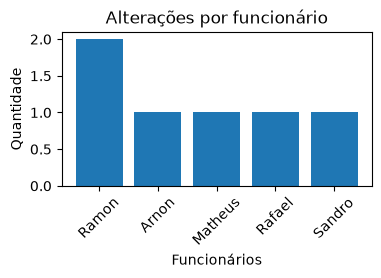

In [31]:
cursor.execute("""
    SELECT f.nome, COUNT(a.id) AS qtd
    FROM funcionarios f
    LEFT JOIN auditoria_salarios a ON a.funcionario_id = f.id
    GROUP BY f.id, f.nome
    ORDER BY qtd DESC, f.nome
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['nome','qtd'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['nome'], df_qtd['qtd'])
plt.title('Alterações por funcionário')
plt.xlabel('Funcionários')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

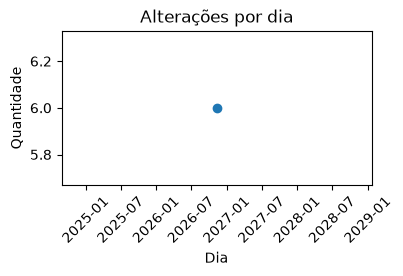

In [32]:
cursor.execute("""
    SELECT DATE(data_alteracao) AS dia, COUNT(*) AS qtd
    FROM auditoria_salarios
    GROUP BY DATE(data_alteracao)
    ORDER BY dia
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['dia','qtd'])

plt.figure(figsize=(4,2))
plt.plot(df_qtd['dia'], df_qtd['qtd'], marker = 'o')
plt.title('Alterações por dia')
plt.xlabel('Dia')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

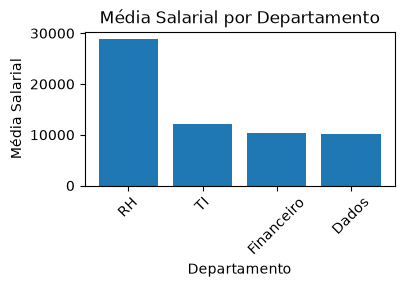

In [33]:
cursor.execute("""
    SELECT d.nome AS departamento, ROUND(AVG(f.salario),2) AS media
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    GROUP BY d.id, d.nome
    ORDER BY media DESC
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['departamento','media'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['departamento'], df_qtd['media'])
plt.title('Média Salarial por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Média Salarial')
plt.xticks(rotation = 45)
plt.show()


## 11) Exercícios propostos
1. **Procedure** `add_funcionario(IN p_nome, IN p_salario, IN p_dept)` que insere e emite `SELECT LAST_INSERT_ID()` para retornar o novo `id` ao Python.  
2. **Function** `calc_imposto(p_salario)` (10%) e consulta com salário líquido.  
3. **Trigger** que bloqueia **redução** maior que 30% do salário.  
4. **Relatório**: `nome, departamento, salario, bonus, faixa` ordenado por `bonus` (use as funções).


### Exercício 1 — Procedure add_funcionario

Crie uma procedure chamada add_funcionario que receba como entrada:
- `p_nome` (nome do funcionário)
- `p_salario` (valor do salário)
- `p_dept` (departamento)

E retorne via **OUT** o `ID` do **funcionário recém-inserido**.

In [34]:
cursor.execute('DROP PROCEDURE IF EXISTS add_funcionario')
cursor.execute("""
CREATE PROCEDURE add_funcionario(
    IN p_nome VARCHAR(100),
    IN p_salario DECIMAL(10,2),
    IN p_dept INT
)
BEGIN
    INSERT INTO funcionarios (nome, salario, dept_id)
    VALUES (p_nome, p_salario, p_dept);
    
    SELECT LAST_INSERT_ID() AS novo_id;
END
""")
conn.commit()

In [35]:
args = ["Samanta", 15000, 2]
cursor.callproc('add_funcionario',args)
conn.commit()
cursor.fetchone()

(6,)

### Exercício 2 — Function calc_imposto

Crie uma função chamada `calc_imposto(p_salario)` que retorne o valor do **salário líquido**, descontando **10% de imposto**.

In [36]:
cursor.execute('DROP FUNCTION IF EXISTS calc_imposto;')
cursor.execute("""
CREATE FUNCTION calc_imposto(p_salario DECIMAL(10,2)) RETURNS DECIMAL(10,2)
DETERMINISTIC
BEGIN
    DECLARE salario_liquido DECIMAL(10,2);
    SET salario_liquido = ROUND(p_salario - (p_salario * 0.1), 2);
    RETURN salario_liquido;
END;
""")
conn.commit()

In [37]:
cursor.execute("""SELECT nome, salario, calc_imposto(salario)
AS salario_liquido FROM funcionarios ORDER BY salario DESC;""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Salário Líquido'])

,Nome,Salário,Salário Líquido
0,Arnon,28875.00,25987.50
1,Sandro,17325.00,15592.50
2,Samanta,15000.00,13500.00
3,Ramon,12127.50,10914.75
4,Matheus,10395.00,9355.50
5,Rafael,2887.50,2598.75


### Exercício 3 — Trigger trg_validar_reducao

Crie uma trigger chamada `trg_validar_reducao` que impede reduções maiores que 30% no salário de um funcionário.

In [38]:
cursor.execute('DROP TRIGGER IF EXISTS trg_validar_reducao;')
cursor.execute("""
CREATE TRIGGER trg_validar_reducao
BEFORE UPDATE ON funcionarios
FOR EACH ROW
BEGIN
    IF NEW.salario < OLD.salario * 0.7 THEN
        SIGNAL SQLSTATE '45000' SET MESSAGE_TEXT = 'Redução de salário maior que 30%, não permitida.';
    END IF;
END;
""")
conn.commit()

In [39]:
try:
    cursor.execute('UPDATE funcionarios SET salario = salario - (salario * 0.4) WHERE id = 2;')
    conn.commit()
    print('Atualização aplicada com sucesso')
except Exception as e:
    conn.rollback()
    print('Erro esperado  da Trigger:', e)

Erro esperado  da Trigger: (1644, 'Redução de salário maior que 30%, não permitida.')


### Exercício 4 — Relatório combinado

Crie uma consulta que mostre:
- `nome`, `departamento`, `salario`,
- `bonus` (usando `calcular_bonus`),
- `faixa` (usando `classificar_salario`),
- `salario_liquido` (usando `calc_imposto`)

In [40]:
cursor.execute("""
SELECT
    f.nome AS Nome,
    f.salario AS Salario,
    d.nome AS Departamento,
    calcular_bonus(f.salario) AS Bônus,
    classificar_salario(f.salario) AS Classificacao,
    calc_imposto(f.salario) AS Salario_Liquido
FROM funcionarios f
JOIN departamentos d ON f.dept_id = d.id
ORDER BY f.salario DESC;
""")
pd.DataFrame(cursor.fetchall(), columns = ['Nome','Salário','Departamento', 'Bônus', 'Classificação','Salário Líquido'])

,Nome,Salário,Departamento,Bônus,Classificação,Salário Líquido
0,Arnon,28875.00,RH,4331.25,Alto,25987.50
1,Sandro,17325.00,Dados,2598.75,Alto,15592.50
2,Samanta,15000.00,TI,2250.00,Médio,13500.00
3,Ramon,12127.50,TI,1819.13,Médio,10914.75
4,Matheus,10395.00,Financeiro,1559.25,Médio,9355.50
5,Rafael,2887.50,Dados,433.13,Baixo,2598.75


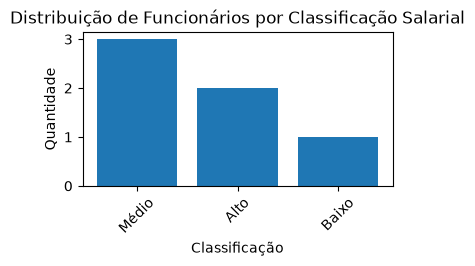

In [41]:
cursor.execute("""
    SELECT classificar_salario(f.salario) AS classificacao, COUNT(*) AS contador
    FROM funcionarios f
    GROUP BY classificacao
    ORDER BY contador DESC
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['classificacao','contador'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['classificacao'], df_qtd['contador'])
plt.title('Distribuição de Funcionários por Classificação Salarial')
plt.xlabel('Classificação')
plt.ylabel('Quantidade')
plt.xticks(rotation = 45)
plt.show()

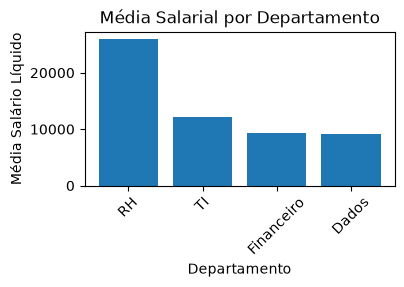

In [42]:
cursor.execute("""
    SELECT  d.nome AS departamento, ROUND(AVG(calc_imposto(f.salario)),2) AS media
    FROM funcionarios f
    LEFT JOIN departamentos d ON d.id = f.dept_id
    GROUP BY d.id, d.nome
    ORDER BY media DESC
""")
df_qtd = pd.DataFrame(cursor.fetchall(), columns = ['departamento','media'])
plt.figure(figsize=(4,2))
plt.bar(df_qtd['departamento'], df_qtd['media'])
plt.title('Média Salarial por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Média Salário Líquido')
plt.xticks(rotation = 45)
plt.show()


## 12) Encerrar a conexão
**O que faremos agora:**  
- Fechar `cursor` e `conn` ao final do notebook.


In [43]:
cursor.close()
conn.close()

## 12 Mysql Grant Revoke

# GRANT e REVOKE
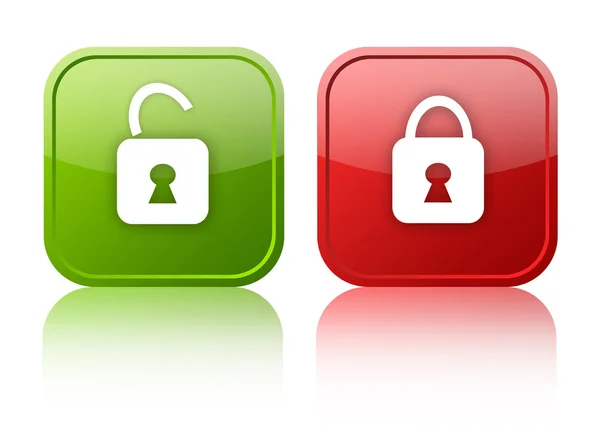

## MySQL: Gerenciamento de Permissões 

Nesta aula, vamos explorar como gerenciar permissões de usuários no MySQL usando Python, focando nas funções GRANT e REVOKE.

#### Passo 1: Instalar bibliotecas

In [1]:
#%pip install mysql
#%pip install --upgrade pandas

#### Passo 2: Importar bibliotecas

In [2]:
import pymysql
import pandas as pd

#### Passo 3: Configurações do banco de dados

In [3]:
# Cria conexão com banco de dados
conn = pymysql.connect(
    host="localhost",
    user="root",
    password="root"
)
cursor = conn.cursor()

#### Passo 4: Criar Banco de Dados

In [4]:
cursor.execute("DROP DATABASE IF EXISTS sistema_empresa") # Remove banco de dados da aula passada
cursor.execute("CREATE DATABASE IF NOT EXISTS sistema_empresa")
cursor.execute("USE sistema_empresa")
print('Banco criado com sucesso!')

Banco criado com sucesso!


#### Passo 5: Criar Tabelas

In [5]:
# Tabela 1: Funcionários (dados sensíveis)
cursor.execute("""
CREATE TABLE funcionarios (
    id INT PRIMARY KEY AUTO_INCREMENT,
    nome VARCHAR(100) NOT NULL,
    email VARCHAR(100),
    cargo VARCHAR(50),
    salario DECIMAL(10,2),
    data_admissao DATE,
    departamento VARCHAR(50)
)
""")
# Tabela 2: Projetos (dados menos sensíveis)
cursor.execute("""
CREATE TABLE projetos (
    id INT PRIMARY KEY AUTO_INCREMENT,
    nome_projeto VARCHAR(100) NOT NULL,
    descricao TEXT,
    orcamento DECIMAL(12,2),
    data_inicio DATE,
    data_termino DATE,
    status VARCHAR(20)
)
""")
        
# Tabela 3: Departamentos (dados públicos)
cursor.execute("""
    CREATE TABLE departamentos (
    id INT PRIMARY KEY AUTO_INCREMENT,
    nome_departamento VARCHAR(100) NOT NULL,
    gerente VARCHAR(100),
    orcamento_anual DECIMAL(12,2),
    telefone VARCHAR(20)
)
""")

print("Tabelas criadas com sucesso")

Tabelas criadas com sucesso


#### Passo 6: Inserir dados

In [6]:
# Funcionários
funcionarios = [
    ('João Silva', 'joao.silva@empresa.com', 'Gerente de TI', 15000.00, '2020-01-15', 'TI'),
    ('Maria Santos', 'maria.santos@empresa.com', 'Analista RH', 8000.00, '2021-03-20', 'RH'),
    ('Pedro Oliveira', 'pedro.oliveira@empresa.com', 'Desenvolvedor', 12000.00, '2019-11-10', 'TI'),
    ('Ana Costa', 'ana.costa@empresa.com', 'Assistente Admin', 4500.00, '2022-06-01', 'Administrativo')
]
        
cursor.executemany(""" INSERT INTO funcionarios (nome, email, cargo, salario, data_admissao, departamento) 
VALUES (%s, %s, %s, %s, %s, %s)""", funcionarios)
        
# Projetos
projetos = [
    ('Sistema ERP', 'Desenvolvimento do sistema integrado', 500000.00, '2023-01-01', '2024-12-31', 'Em Andamento'),
    ('Site Corporativo', 'Redesign do site da empresa', 120000.00, '2023-03-15', '2023-09-30', 'Concluído'),
    ('App Mobile', 'Desenvolvimento do aplicativo', 300000.00, '2023-06-01', '2024-06-30', 'Planejamento')
]
        
cursor.executemany(""" INSERT INTO projetos (nome_projeto, descricao, orcamento, data_inicio, data_termino, status)
VALUES (%s, %s, %s, %s, %s, %s)""", projetos)
        
# Departamentos
departamentos = [
    ('TI', 'João Silva', 1000000.00, '(11) 9999-8888'),
    ('RH', 'Maria Santos', 500000.00, '(11) 9999-7777'),
    ('Administrativo', 'Carlos Souza', 300000.00, '(11) 9999-6666')
]

cursor.executemany(""" INSERT INTO departamentos (nome_departamento, gerente, orcamento_anual, telefone)
VALUES (%s, %s, %s, %s)""", departamentos)

conn.commit()

print('Dados inseridos com sucesso!')

Dados inseridos com sucesso!


#### Passo 7: Visualizar dados

In [7]:
cursor.execute('SELECT * FROM funcionarios;')
display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))

,id,nome,email,cargo,salario,data_admissao,departamento
0,1,João Silva,joao.silva@empresa.com,Gerente de TI,15000.00,2020-01-15,TI
1,2,Maria Santos,maria.santos@empresa.com,Analista RH,8000.00,2021-03-20,RH
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,Desenvolvedor,12000.00,2019-11-10,TI
3,4,Ana Costa,ana.costa@empresa.com,Assistente Admin,4500.00,2022-06-01,Administrativo


In [8]:
cursor.execute('SELECT * FROM departamentos;')
display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))

,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666


In [9]:
cursor.execute('SELECT * FROM projetos;')
display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))

,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento


#### Passo 8: Criando Usuários

In [10]:
# Perfil 1: Administrador (acesso total)

# Usuário e senha
adm = ("admin_empresa", "admin123")

cursor.execute(f"DROP USER IF EXISTS '{adm[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{adm[0]}'@'localhost' IDENTIFIED BY '{adm[1]}'")

print("Administrador criado")

Administrador criado


In [11]:
# Perfil 2: Gerente (acesso a quase tudo, exceto salários)

# Usuário e senha
ger = ('gerente_geral','gerente123')

cursor.execute(f"DROP USER IF EXISTS '{ger[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{ger[0]}'@'localhost' IDENTIFIED BY '{ger[1]}'")

print("Gerente criado")

Gerente criado


In [12]:
# Perfil 3: Analista de RH (acesso limitado a funcionários)

# Usuário e senha
rh = ('analista_rh','rh123')

cursor.execute(f"DROP USER IF EXISTS '{rh[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{rh[0]}'@'localhost' IDENTIFIED BY '{rh[1]}'")

print("Analista RH criado")

Analista RH criado


In [13]:
# Perfil 4: Desenvolvedor (acesso apenas a projetos)

# Usuário e senha
dev = ('dev_ti','dev123')

cursor.execute(f"DROP USER IF EXISTS '{dev[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{dev[0]}'@'localhost' IDENTIFIED BY '{dev[1]}'")

print("Desenvolvedor criado")

Desenvolvedor criado


In [14]:
# Perfil 5: Estagiário (apenas leitura em dados não sensíveis)

# Usuário e senha
est = ('estagiario','estagio123')

cursor.execute(f"DROP USER IF EXISTS '{est[0]}'@'localhost'")
cursor.execute(f"CREATE USER '{est[0]}'@'localhost' IDENTIFIED BY '{est[1]}'")

print("Estagiário criado")

Estagiário criado


In [15]:
# Verifica todos os perfis criados
cursor.execute("SELECT user, host FROM mysql.user WHERE user NOT LIKE 'mysql%'")
cursor.fetchall()

(('admin_empresa', 'localhost'),
 ('analista_rh', 'localhost'),
 ('atendente', 'localhost'),
 ('comunicacao', 'localhost'),
 ('dev_ti', 'localhost'),
 ('diretoria', 'localhost'),
 ('estagiario', 'localhost'),
 ('gerente_geral', 'localhost'),
 ('root', 'localhost'))

#### Passo 9: GRANT - Concedendo permissões

In [16]:
# Perfil 1: Administrador (acesso total)
cursor.execute(f"GRANT ALL PRIVILEGES ON sistema_empresa.* TO '{adm[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [17]:
# Perfil 2: Gerente (acesso a quase tudo, exceto salários)
# Permissões para gerente
cursor.execute(f"GRANT SELECT, INSERT, UPDATE, DELETE ON sistema_empresa.projetos TO '{ger[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT, INSERT, UPDATE, DELETE ON sistema_empresa.departamentos TO '{ger[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT (id, nome, email, cargo, data_admissao, departamento) ON sistema_empresa.funcionarios TO '{ger[0]}'@'localhost'")

print('Permissão configurada')

Permissão configurada


In [18]:
# Perfil 3: Analista de RH (acesso limitado a funcionários)
# Permissões para rh
cursor.execute(f"GRANT SELECT (id, nome, email, cargo, data_admissao, departamento) ON sistema_empresa.funcionarios TO '{rh[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT ON sistema_empresa.departamentos TO '{rh[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [19]:
# Perfil 4: Desenvolvedor (acesso apenas a projetos)
cursor.execute(f"GRANT SELECT ON sistema_empresa.projetos TO '{dev[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [20]:
# Perfil 5: Estagiário (apenas leitura em dados não sensíveis)
cursor.execute(f"GRANT SELECT ON sistema_empresa.departamentos TO '{est[0]}'@'localhost'")
cursor.execute(f"GRANT SELECT (nome_projeto, descricao, status) ON sistema_empresa.projetos TO '{est[0]}'@'localhost'")
print('Permissão configurada')

Permissão configurada


In [21]:
# Aplicar todas as permissões
cursor.execute("FLUSH PRIVILEGES")
print('Permissões aplicadas com sucesso')

Permissões aplicadas com sucesso


#### Passo 10: Testando as permissões de cada usuário

In [22]:
# Encerrar conexão com banco de dados
conn.close()

In [23]:
def conectar_usuario(usuario, senha, banco='sistema_empresa'):
    conn = pymysql.connect(
        host="localhost",
        user=usuario,
        password=senha,
        database=banco
    )
    cursor = conn.cursor()
    print(f"Conectado como: {usuario}")
    return conn, cursor

In [24]:
usuario = ger
conn, cursor = conectar_usuario(*(usuario))

Conectado como: gerente_geral


In [25]:
# Tentar SELECT básico
cursor.execute("SELECT DATABASE(), USER()")
cursor.fetchone()

('sistema_empresa', 'gerente_geral@localhost')

#### Teste: CRUD (Create, Read, Upadate, Delete)
- **SELECT:** Responsabilidade nível 1
- **INSERT:** Responsabilidade nível 2
- **UPDATE:** Responsabilidade nível 3
- **DELETE:** Responsabilidade nível 4

In [26]:
try:
    cursor.execute(f"DESCRIBE funcionarios")
    colunas = ",".join([desc[0] for desc in cursor.fetchall()])
    cursor.execute(f"SELECT {colunas} FROM funcionarios;")
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para acessar a tabela funcionarios')

,id,nome,email,cargo,data_admissao,departamento
0,1,João Silva,joao.silva@empresa.com,Gerente de TI,2020-01-15,TI
1,2,Maria Santos,maria.santos@empresa.com,Analista RH,2021-03-20,RH
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,Desenvolvedor,2019-11-10,TI
3,4,Ana Costa,ana.costa@empresa.com,Assistente Admin,2022-06-01,Administrativo


In [27]:
try:
    dados = ('Rafael Orsi', 'rafael.orsi@empresa.com', 'Desenvolvedor', 12000, '2025-01-01', 'TI')
    cursor.execute(""" INSERT INTO funcionarios (nome, email, cargo, salario, data_admissao, departamento) 
    VALUES (%s, %s, %s, %s, %s, %s)""", dados)
    print('Novo registro')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para inserir dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para inserir dados da tabela funcionarios


In [28]:
try:
    cursor.execute("UPDATE funcionarios SET email = %s WHERE nome = %s", ('rafael.orsi25@empresa.com', 'Rafael Orsi'))
    print('Registro modificado')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para modificar dados da tabela funcionarios


In [29]:
try:
    cursor.execute("UPDATE funcionarios SET email = %s WHERE nome = %s", ('rafael.orsi25@empresa.com', 'Rafael Orsi'))
    print('Registro modificado')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para modificar dados da tabela funcionarios


In [30]:
try:
    cursor.execute("DELETE FROM funcionarios WHERE nome = %s", 'Rafael Orsi')
    print('Registro excluído')
    cursor.execute('SELECT * FROM funcionarios;')
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para excluir dados da tabela funcionarios')

Usuário gerente_geral não tem permissão para excluir dados da tabela funcionarios


C:\Users\48694260808\AppData\Local\Temp\ipykernel_34048\3170298994.py:2: DeprecationWarning: single argument is deprecated and will be removed in the next version.
  cursor.execute("DELETE FROM funcionarios WHERE nome = %s", 'Rafael Orsi')


#### Faça o mesmo pra as tabelas projetos e departamentos

In [31]:
try:
    cursor.execute(f"DESCRIBE projetos")
    colunas = ",".join([desc[0] for desc in cursor.fetchall()])
    cursor.execute(f"SELECT {colunas} FROM projetos;")
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    try:
        dados = ('Banco de Dados', 'Modelagem', 15000.00, '2025-01-01', '2026-12-31', 'Em Andamento')
        cursor.execute(""" INSERT INTO projetos (nome_projeto, descricao, orcamento, data_inicio, data_termino, status) 
        VALUES (%s, %s, %s, %s, %s, %s)""", dados)
        print('Novo registro')
        cursor.execute('SELECT * FROM projetos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para inserir dados da tabela projetos')
    try:
        cursor.execute("UPDATE projetos SET nome_projeto = %s WHERE nome_projeto = %s", ('Cloud', 'Banco de Dados'))
        print('Registro modificado')
        cursor.execute('SELECT * FROM projetos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela projetos')
    try:
        cursor.execute("DELETE FROM projetos WHERE nome_projeto = %s", 'Cloud')
        print('Registro excluído')
        cursor.execute('SELECT * FROM projetos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para excluir dados da tabela projetos')
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para acessar a tabela projetos')

,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento


Novo registro


,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento
3,4,Banco de Dados,Modelagem,15000.00,2025-01-01,2026-12-31,Em Andamento


Registro modificado


,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento
3,4,Cloud,Modelagem,15000.00,2025-01-01,2026-12-31,Em Andamento


Registro excluído


C:\Users\48694260808\AppData\Local\Temp\ipykernel_34048\2712152683.py:23: DeprecationWarning: single argument is deprecated and will be removed in the next version.
  cursor.execute("DELETE FROM projetos WHERE nome_projeto = %s", 'Cloud')


,id,nome_projeto,descricao,orcamento,data_inicio,data_termino,status
0,1,Sistema ERP,Desenvolvimento do sistema integrado,500000.00,2023-01-01,2024-12-31,Em Andamento
1,2,Site Corporativo,Redesign do site da empresa,120000.00,2023-03-15,2023-09-30,Concluído
2,3,App Mobile,Desenvolvimento do aplicativo,300000.00,2023-06-01,2024-06-30,Planejamento


In [32]:
try:
    cursor.execute(f"DESCRIBE departamentos")
    colunas = ",".join([desc[0] for desc in cursor.fetchall()])
    cursor.execute(f"SELECT {colunas} FROM departamentos;")
    display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    try:
        dados = ('Vendas', 'Miguel', 1500000, '(11) 9111-1111')
        cursor.execute(""" INSERT INTO departamentos (nome_departamento, gerente, orcamento_anual, telefone) 
        VALUES (%s, %s, %s, %s)""", dados)
        print('Novo registro')
        cursor.execute('SELECT * FROM departamentos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para inserir dados da tabela departamentos')
    try:
        cursor.execute("UPDATE departamentos SET nome_departamento = %s WHERE nome_departamento = %s", ('Manutenção', 'Vendas'))
        print('Registro modificado')
        cursor.execute('SELECT * FROM departamentos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para modificar dados da tabela departamentos')
    try:
        cursor.execute("DELETE FROM departamentos WHERE nome_departamento = %s", 'Manutenção')
        print('Registro excluído')
        cursor.execute('SELECT * FROM departamentos;')
        display(pd.DataFrame(cursor.fetchall(), columns = [desc[0] for desc in cursor.description]))
    except:
        print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para excluir dados da tabela departamentos')
except:
    print(f'Usuário \033[1m{usuario[0]}\033[0m não tem permissão para acessar a tabela departamentos')

,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666


Novo registro


,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666
3,4,Vendas,Miguel,1500000.00,(11) 9111-1111


Registro modificado


,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666
3,4,Manutenção,Miguel,1500000.00,(11) 9111-1111


Registro excluído


C:\Users\48694260808\AppData\Local\Temp\ipykernel_34048\1518540012.py:23: DeprecationWarning: single argument is deprecated and will be removed in the next version.
  cursor.execute("DELETE FROM departamentos WHERE nome_departamento = %s", 'Manutenção')


,id,nome_departamento,gerente,orcamento_anual,telefone
0,1,TI,João Silva,1000000.00,(11) 9999-8888
1,2,RH,Maria Santos,500000.00,(11) 9999-7777
2,3,Administrativo,Carlos Souza,300000.00,(11) 9999-6666


#### Passo 11: REVOKE - Revogando permissões
- A função REVOKE só pode ser utilizada pelo super usuário (root)
- A função REVOKE deve ser utilizada para remover a permissão da tabela inteira.
- Caso queira remover a permissão em apenas uma coluna, deverá fazer o REVOKE da tabela inteira e depois fazer o GRANT explícito das colunas com permissão.

Sintaxe: `cursor.execute("REVOKE privilegios ON database.tabela FROM 'usuario'@'host'")`

In [33]:
# Cria conexão com banco de dados usando o super usuário
conn, cursor = conectar_usuario('root','root')

Conectado como: root


In [34]:
# Remover multiplos privilégios
# cursor.execute("REVOKE UPDATE, DELETE ON sistema_empresa.funcionarios FROM 'gerente_geral'@'localhost'")
# cursor.execute("FLUSH PRIVILEGES")
print('Privilégios Revogados')

Privilégios Revogados


In [35]:
# Remover todos os privilégios (recomendado
# cursor.execute("REVOKE ALL PRIVILEGES ON sistema_empresa.funcionarios FROM 'gerente_geral'@'localhost'")
# cursor.execute("FLUSH PRIVILEGES")
print('Privilégios revogados')

Privilégios revogados


#### Passo 12: Mostrar Privilégios

In [36]:
cursor.execute("SHOW GRANTS FOR 'gerente_geral'@'localhost'")
cursor.fetchall()

(('GRANT USAGE ON *.* TO `gerente_geral`@`localhost`',),
 ('GRANT SELECT, INSERT, UPDATE, DELETE ON `sistema_empresa`.`departamentos` TO `gerente_geral`@`localhost`',),
 ('GRANT SELECT (`cargo`, `data_admissao`, `departamento`, `email`, `id`, `nome`) ON `sistema_empresa`.`funcionarios` TO `gerente_geral`@`localhost`',),
 ('GRANT SELECT, INSERT, UPDATE, DELETE ON `sistema_empresa`.`projetos` TO `gerente_geral`@`localhost`',))

In [37]:
cursor.execute("SELECT user, host FROM mysql.user WHERE user NOT LIKE 'mysql%'")

print('====== PRIVILÉGIOS DOS USUÁRIOS =======')
for user, host in cursor.fetchall():
    print(f"\n Usuário: {user}@{host}")
        
    # Ver privilégios globais
    cursor.execute(f"SHOW GRANTS FOR '{user}'@'{host}'")       
    for grant in cursor.fetchall():
        print(f"{grant[0]}")

====== PRIVILÉGIOS DOS USUÁRIOS =======

 Usuário: admin_empresa@localhost
GRANT USAGE ON *.* TO `admin_empresa`@`localhost`
GRANT ALL PRIVILEGES ON `sistema_empresa`.* TO `admin_empresa`@`localhost`

 Usuário: analista_rh@localhost
GRANT USAGE ON *.* TO `analista_rh`@`localhost`
GRANT SELECT ON `sistema_empresa`.`departamentos` TO `analista_rh`@`localhost`
GRANT SELECT (`cargo`, `data_admissao`, `departamento`, `email`, `id`, `nome`) ON `sistema_empresa`.`funcionarios` TO `analista_rh`@`localhost`

 Usuário: atendente@localhost
GRANT USAGE ON *.* TO `atendente`@`localhost`

 Usuário: comunicacao@localhost
GRANT USAGE ON *.* TO `comunicacao`@`localhost`

 Usuário: dev_ti@localhost
GRANT USAGE ON *.* TO `dev_ti`@`localhost`
GRANT SELECT ON `sistema_empresa`.`projetos` TO `dev_ti`@`localhost`

 Usuário: diretoria@localhost
GRANT USAGE ON *.* TO `diretoria`@`localhost`

 Usuário: estagiario@localhost
GRANT USAGE ON *.* TO `estagiario`@`localhost`
GRANT SELECT ON `sistema_empresa`.`departa

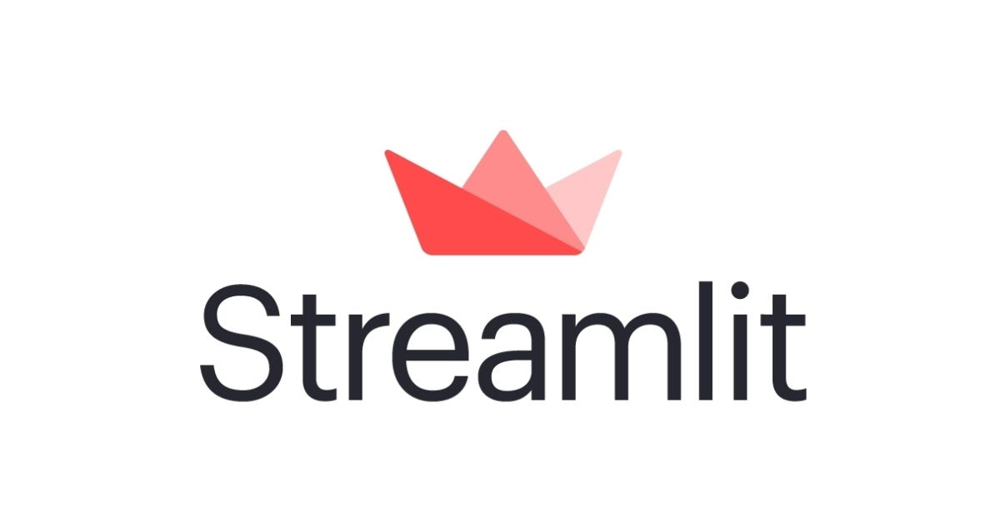
## Interface WEb para Demonstrar GRANT e REVOKE

Nesta seção, vamos construir uma interface web em **Python (Streamlit)** que permitirá:

1. Fazer **login** no banco com diferentes usuários.
2. Executar comandos SQL (SELECT, INSERT, UPDATE, DELETE).
3. Visualizar os resultados em uma tabela.
4. Demonstrar na prática as permissões concedidas ou revogadas com **GRANT** e **REVOKE**.

#### Passo a passo (resumido) para criar uma interface web com Streamlit
1. Crie o arquivo .py
2. Escrever o código com elementos do Streamlit
3. Salve o arquivo
4. Execute no terminal: streamlit run seu_arquivo.py
5. Acesse no navegador: http://localhost:8501

In [38]:
%pip install streamlit

   ---------------------------------------- 0.0/11.2 MB ? eta -:--:--
   ------------------------ --------------- 6.8/11.2 MB 34.5 MB/s eta 0:00:01
   ---------------------------------------- 11.2/11.2 MB 30.6 MB/s  0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 11.3 MB/s  0:00:00
   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   --------- ------------------------------ 7.1/29.8 MB 34.7 MB/s eta 0:00:01
   ------------------ --------------------- 13.9/29.8 MB 34.4 MB/s eta 0:00:01
   --------------------------- ------------ 20.7/29.8 MB 34.2 MB/s eta 0:00:01
   ------------------------------------ --- 27.5/29.8 MB 33.9 MB/s eta 0:00:01
   ---------------------------------------  29.6/29.8 MB 33.9 MB/s eta 0:00:01
   ---------------------------------------- 29.8/29.8 MB 25.5 MB/s  0:00:01
   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
def gerar_codigo_streamlit():
    import streamlit as st
    import pymysql
    import pandas as pd
    import time

    st.set_page_config(page_title="GRANT / REVOKE", layout="centered")
    st.title("GRANT / REVOKE - Banco de Dados")

    # Função de conexão
    def conectar(usuario, senha):
        try:
            conn = pymysql.connect(
                host="localhost",
                user=usuario,
                password=senha,
                database="sistema_empresa"  # ajuste conforme seu banco
            )
            return conn
        except pymysql.MySQLError as err:
            st.error(f"Erro de conexão: {err}")
            return None

    # Estado da sessão
    if "logged_in" not in st.session_state:
        st.session_state.logged_in = False
    if "conn" not in st.session_state:
        st.session_state.conn = None
    if "user" not in st.session_state:
        st.session_state.user = None

    # Interface de Login
    if not st.session_state.logged_in:
        user = st.text_input("Usuário")
        password = st.text_input("Senha", type="password")

        if st.button("Entrar"):
            conn = conectar(user, password)
            if conn:
                st.session_state.logged_in = True
                st.session_state.conn = conn
                st.session_state.user = user
                st.success(f"Usuário {user} conectado com sucesso!")
                time.sleep(1.5)
                st.rerun() 

    # Interface principal
    else:
        st.write(f"Usuário conectado: **{st.session_state.user}**")

        query = st.text_area("Digite um comando SQL:")

        if st.button("Executar Query"):
            try:
                cursor = st.session_state.conn.cursor()
                cursor.execute(query)

                if query.strip().lower().startswith("select"):
                    rows = cursor.fetchall()
                    cols = [desc[0] for desc in cursor.description]
                    df = pd.DataFrame(rows, columns=cols)
                    st.dataframe(df)
                else:
                    st.session_state.conn.commit()
                    st.success("Operação realizada com sucesso!")
                cursor.close()
            except pymysql.MySQLError as err:
                st.error(f"Erro SQL: {err}")

        if st.button("Sair"):
            if st.session_state.conn:
                st.session_state.conn.close()
            st.session_state.logged_in = False
            st.session_state.conn = None
            st.success("Logout realizado com sucesso.")

In [40]:
import inspect, textwrap

# Extrai o código da função e salva no arquivo .py 
codigo_streamlit = textwrap.dedent(inspect.getsource(gerar_codigo_streamlit))

# remove a primeira linha "def gerar_codigo_streamlit():" e o recuo
codigo_streamlit = "\n".join(codigo_streamlit.splitlines()[1:])
codigo_streamlit = textwrap.dedent(codigo_streamlit)

# Mostra o código que será salvo como .py
codigo_streamlit

'import streamlit as st\nimport pymysql\nimport pandas as pd\nimport time\n\nst.set_page_config(page_title="GRANT / REVOKE", layout="centered")\nst.title("GRANT / REVOKE - Banco de Dados")\n\n# Função de conexão\ndef conectar(usuario, senha):\n    try:\n        conn = pymysql.connect(\n            host="localhost",\n            user=usuario,\n            password=senha,\n            database="sistema_empresa"  # ajuste conforme seu banco\n        )\n        return conn\n    except pymysql.MySQLError as err:\n        st.error(f"Erro de conexão: {err}")\n        return None\n\n# Estado da sessão\nif "logged_in" not in st.session_state:\n    st.session_state.logged_in = False\nif "conn" not in st.session_state:\n    st.session_state.conn = None\nif "user" not in st.session_state:\n    st.session_state.user = None\n\n# Interface de Login\nif not st.session_state.logged_in:\n    user = st.text_input("Usuário")\n    password = st.text_input("Senha", type="password")\n\n    if st.button("Entr

In [41]:
with open("app_streamlit.py", "w", encoding="utf-8") as f:
    f.write(codigo_streamlit)

print("Arquivo 'app_streamlit.py' criado com sucesso!")

Arquivo 'app_streamlit.py' criado com sucesso!


### Execute o seu app_streamlit a partir do Jupyter

In [42]:
!streamlit run app_streamlit.py

'streamlit' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.


### Execute o seu app_streamlit como subprocess controlado

In [45]:
from pathlib import Path
import subprocess
import sys

app = Path.cwd() / "app_streamlit.py"

if not app.is_file():
    raise FileNotFoundError(f"Não encontrei o app em: {app}")

process = subprocess.Popen([
    sys.executable, "-m", "streamlit", "run", str(app)
])

In [46]:
process.terminate() # Encerra o processo

### Você também pode executar o app_streamlit informando o local onde está armazenado
- O comando abaixo pode ser executar aqui no Jupyter ou via terminal (cmd)

In [56]:
#!cd /d seu_diretorio && streamlit run app_streamlit.py
!cmd /c "cd /d C:\Users\48694260808\Documents\GitHub\LABD\notebooks && python -m streamlit run app_streamlit.py"

^C


## 13 Mysql Views

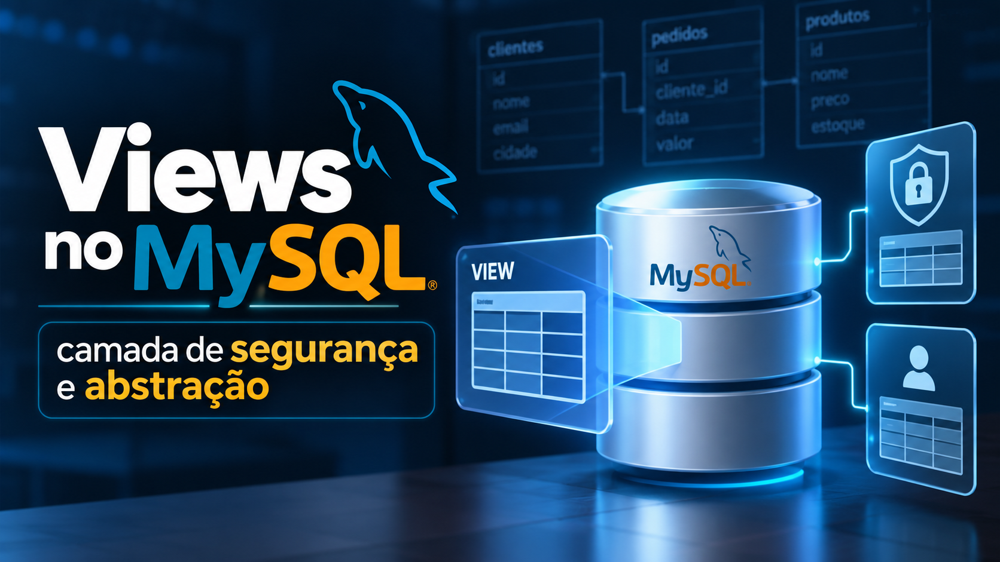

Nas aulas anteriores aprendemos a criar bancos e tabelas, a automatizar regras com **procedures, functions e triggers** e a controlar o acesso com **GRANT e REVOKE**.

Na aula 12 vimos que é possível liberar colunas específicas para um usuário (`GRANT SELECT (nome, email) ON ...`). Isso funciona, mas tem limites: não dá para esconder **linhas**, não dá para **mascarar** um dado e não dá para entregar um **resultado já calculado**.

Nesta aula vamos conhecer as **Views**, uma das ferramentas mais usadas no dia a dia para resolver exatamente esses problemas.

## O que é uma View?

Uma **View** (visão) é uma **consulta `SELECT` salva no banco de dados com um nome**.

Depois de criada, ela pode ser consultada como se fosse uma tabela:

```sql
SELECT * FROM nome_da_view;
```

Mas atenção: **a view não guarda dados**. Cada vez que você consulta a view, o MySQL executa o `SELECT` que está por trás dela e busca os dados nas tabelas originais. Por isso dizemos que a view é uma **tabela virtual**.

| | Tabela | View |
|---|---|---|
| Guarda dados? | Sim | Não, guarda apenas a consulta |
| Ocupa espaço com registros? | Sim | Não |
| Fica atualizada sozinha? | É a própria fonte | Sim, sempre reflete as tabelas |
| Pode receber `GRANT`? | Sim | Sim |

### Para que servem as views?

- **Segurança**: mostrar só algumas colunas ou linhas de uma tabela
- **Abstração**: esconder um `JOIN` complicado atrás de um nome simples
- **Padronização**: todos usam o mesmo cálculo (exemplo: média salarial por departamento)
- **Proteção contra mudanças**: se a tabela mudar, ajustamos só a view e os sistemas continuam funcionando

### Sintaxe básica

```sql
CREATE VIEW nome_da_view AS
SELECT colunas
FROM tabela
WHERE condicao;
```

## Preparando o ambiente

Vamos começar como nas aulas anteriores: importar as bibliotecas, conectar como `root` e criar o banco de dados que usaremos durante a aula.

#### Passo 1: Importar as bibliotecas

In [67]:
%pip install pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [68]:
import pymysql
import pandas as pd

#### Passo 2: Conectar ao MySQL como administrador

**O que faremos agora:** abrir uma conexão com o usuário `root`. Ele é o administrador e será o responsável por criar as tabelas, as views e os usuários.

In [69]:
conn = pymysql.connect(host="localhost", user="root", password="root")
cursor = conn.cursor()

#### Passo 3: Criar o banco de dados

In [70]:
cursor.execute("DROP DATABASE IF EXISTS sistema_empresas")
cursor.execute("CREATE DATABASE sistema_empresas")
cursor.execute("USE sistema_empresas")

0

#### Passo 4: Criar a tabela `departamentos`

**O que faremos agora:** criar a tabela de departamentos. Cada departamento tem um nome e um orçamento anual.

In [71]:
cursor.execute("""
CREATE TABLE departamentos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(50) NOT NULL,
    orcamento DECIMAL(12,2)
)
""")

0

#### Passo 5: Criar a tabela `funcionarios`

**O que faremos agora:** criar a tabela de funcionários. Repare que ela tem **dados sensíveis**: `cpf` e `salario`. Esses são os dados que vamos proteger com as views.

A coluna `departamento_id` é uma **chave estrangeira** que liga o funcionário ao seu departamento.

In [72]:
cursor.execute("""
CREATE TABLE funcionarios (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    email VARCHAR(100),
    cpf CHAR(11),
    cargo VARCHAR(50),
    salario DECIMAL(10,2),
    data_admissao DATE,
    departamento_id INT,
    FOREIGN KEY (departamento_id) REFERENCES departamentos(id)
)
""")

0

#### Passo 6: Criar a tabela `projetos`

**O que faremos agora:** criar a tabela de projetos. Cada projeto pertence a um departamento e tem um orçamento e um status.

In [73]:
cursor.execute("""
CREATE TABLE projetos (
    id INT AUTO_INCREMENT PRIMARY KEY,
    nome VARCHAR(100) NOT NULL,
    orcamento DECIMAL(12,2),
    status VARCHAR(20),
    departamento_id INT,
    FOREIGN KEY (departamento_id) REFERENCES departamentos(id)
)
""")

0

#### Passo 7: Inserir os departamentos

**O que faremos agora:** cadastrar três departamentos. Usamos `executemany` para inserir várias linhas com um único comando.

In [74]:
departamentos = [
    ("TI", 500000.00),
    ("RH", 200000.00),
    ("Administrativo", 300000.00)
]

cursor.executemany("INSERT INTO departamentos (nome, orcamento) VALUES (%s, %s)",departamentos)

3

#### Passo 8: Inserir os funcionários

**O que faremos agora:** cadastrar os funcionários. Os quatro primeiros são os mesmos da aula 12; adicionamos mais alguns para que os resultados agrupados fiquem mais interessantes.

Lembre-se: `departamento_id` 1 = TI, 2 = RH, 3 = Administrativo.

In [75]:
funcionarios = [
    ("João Silva",     "joao.silva@empresa.com",     "12345678901", "Desenvolvedor",  8500.00, "2020-03-15", 1),
    ("Maria Santos",   "maria.santos@empresa.com",   "23456789012", "Analista de RH", 6200.00, "2019-07-01", 2),
    ("Pedro Oliveira", "pedro.oliveira@empresa.com", "34567890123", "Gerente",       12000.00, "2018-01-10", 3),
    ("Ana Costa",      "ana.costa@empresa.com",      "45678901234", "Desenvolvedora", 9100.00, "2021-05-20", 1),
    ("Lucas Pereira",  "lucas.pereira@empresa.com",  "56789012345", "Suporte",        4300.00, "2022-02-01", 1),
    ("Carla Mendes",   "carla.mendes@empresa.com",   "67890123456", "Recrutadora",    5100.00, "2021-09-13", 2),
]

cursor.executemany(
    """INSERT INTO funcionarios
       (nome, email, cpf, cargo, salario, data_admissao, departamento_id)
       VALUES (%s, %s, %s, %s, %s, %s, %s)""",
    funcionarios
)

6

#### Passo 9: Inserir os projetos

**O que faremos agora:** cadastrar os projetos da empresa.

In [76]:
projetos = [
    ("Sistema ERP",         250000.00, "Em andamento", 1),
    ("Site Corporativo",     40000.00, "Concluído",    1),
    ("App Mobile",          120000.00, "Em andamento", 1),
    ("Programa de Trainee",  30000.00, "Planejado",    2),
]

cursor.executemany(
    "INSERT INTO projetos (nome, orcamento, status, departamento_id) VALUES (%s, %s, %s, %s)", projetos)

conn.commit()

#### Passo 10: Conferir a tabela `funcionarios`

**O que faremos agora:** olhar a tabela completa. Para exibir o resultado em forma de tabela, usamos o mesmo padrão das aulas anteriores:

- `cursor.fetchall()` traz todas as linhas do resultado
- `cursor.description` guarda os nomes das colunas, que usamos como cabeçalho do DataFrame

Repare que **qualquer pessoa** com acesso a essa tabela consegue ver CPF e salário de todos. Esse é o problema que vamos resolver.

In [77]:
cursor.execute("SELECT * FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,email,cpf,cargo,salario,data_admissao,departamento_id
0,1,João Silva,joao.silva@empresa.com,12345678901,Desenvolvedor,8500.00,2020-03-15,1
1,2,Maria Santos,maria.santos@empresa.com,23456789012,Analista de RH,6200.00,2019-07-01,2
2,3,Pedro Oliveira,pedro.oliveira@empresa.com,34567890123,Gerente,12000.00,2018-01-10,3
3,4,Ana Costa,ana.costa@empresa.com,45678901234,Desenvolvedora,9100.00,2021-05-20,1
4,5,Lucas Pereira,lucas.pereira@empresa.com,56789012345,Suporte,4300.00,2022-02-01,1
5,6,Carla Mendes,carla.mendes@empresa.com,67890123456,Recrutadora,5100.00,2021-09-13,2


## Parte 1: Criando a primeira View

Imagine que o time de comunicação precisa de uma lista de funcionários para montar o organograma da empresa. Eles precisam de **nome, cargo e e-mail**, mas **não** devem ver CPF nem salário.

Em vez de dar acesso à tabela inteira, vamos criar uma view só com as colunas necessárias.

#### Passo 11: Escrever o SELECT que a view vai guardar

**O que faremos agora:** antes de criar uma view, é uma boa prática **testar a consulta** sozinha. Se o `SELECT` funcionar, a view também vai funcionar.

In [78]:
cursor.execute("SELECT id, nome, cargo, email FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com
4,5,Lucas Pereira,Suporte,lucas.pereira@empresa.com
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com


#### Passo 12: Transformar o SELECT em uma View

**O que faremos agora:** basta colocar `CREATE VIEW nome AS` na frente da consulta que acabamos de testar.

Por convenção, vamos usar o prefixo `vw_` no nome das views. Assim fica fácil diferenciar uma view de uma tabela.

In [79]:
cursor.execute("CREATE VIEW vw_funcionarios_publico AS SELECT id, nome, cargo, email FROM funcionarios")

0

#### Passo 13: Consultar a View

**O que faremos agora:** consultar a view exatamente como consultamos uma tabela. Note que **não aparecem** as colunas `cpf` e `salario`.

In [80]:
cursor.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com
4,5,Lucas Pereira,Suporte,lucas.pereira@empresa.com
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com


#### Passo 14: Usar WHERE e ORDER BY na View

**O que faremos agora:** mostrar que a view aceita os mesmos recursos de uma tabela. Vamos filtrar só os desenvolvedores e ordenar por nome.

In [81]:
cursor.execute("SELECT nome, cargo FROM vw_funcionarios_publico WHERE cargo LIKE 'Desenvolvedor%' ORDER BY nome")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo
0,Ana Costa,Desenvolvedora
1,João Silva,Desenvolvedor


#### Passo 15: Provar que a View não guarda dados

**O que faremos agora:** vamos alterar o cargo do Lucas **na tabela original** e depois consultar a **view**. Se a view guardasse uma cópia dos dados, a mudança não apareceria.

In [82]:
cursor.execute("UPDATE funcionarios SET cargo = 'Analista de Suporte' WHERE nome = 'Lucas Pereira'")
conn.commit()

In [83]:
cursor.execute("SELECT * FROM vw_funcionarios_publico WHERE nome = 'Lucas Pereira'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email
0,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com


> A view mostrou o cargo novo imediatamente. Isso confirma que ela **executa a consulta toda vez** que é chamada, buscando os dados direto da tabela `funcionarios`.

## Parte 2: Onde as Views ficam guardadas?

As views são objetos do banco, assim como as tabelas. Vamos aprender a listá-las e ver como foram criadas.

#### Passo 17: Listar tabelas e views juntas

**O que faremos agora:** o comando `SHOW FULL TABLES` lista tudo o que existe no banco e informa o tipo de cada objeto na coluna `Table_type`:

- `BASE TABLE` = tabela de verdade
- `VIEW` = view

In [84]:
cursor.execute("SHOW FULL TABLES")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresas,Table_type
0,departamentos,BASE TABLE
1,funcionarios,BASE TABLE
2,projetos,BASE TABLE
3,vw_funcionarios_publico,VIEW


#### Passo 18: Listar somente as views

**O que faremos agora:** filtrar o resultado para mostrar apenas os objetos do tipo `VIEW`.

In [85]:
cursor.execute("SHOW FULL TABLES WHERE Table_type = 'VIEW'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresas,Table_type
0,vw_funcionarios_publico,VIEW


#### Passo 19: Ver o código de uma View

**O que faremos agora:** o comando `SHOW CREATE VIEW` mostra o SQL completo que o MySQL guardou para a view. Isso é útil quando você encontra uma view criada por outra pessoa e quer entender o que ela faz.

In [86]:
cursor.execute("SHOW CREATE VIEW vw_funcionarios_publico")
resultado = cursor.fetchone()
print(resultado[1])

CREATE ALGORITHM=UNDEFINED DEFINER=`root`@`localhost` SQL SECURITY DEFINER VIEW `vw_funcionarios_publico` AS select `funcionarios`.`id` AS `id`,`funcionarios`.`nome` AS `nome`,`funcionarios`.`cargo` AS `cargo`,`funcionarios`.`email` AS `email` from `funcionarios`


> Repare em dois detalhes que o MySQL acrescentou sozinho:
> - `DEFINER=root@localhost`: quem criou a view
> - `SQL SECURITY DEFINER`: a view roda **com as permissões de quem a criou**. Vamos ver por que isso é tão importante na parte de segurança.

#### Passo 20: Consultar o dicionário de dados

**O que faremos agora:** o MySQL guarda informações sobre todas as views na tabela `information_schema.VIEWS`. Vamos consultar algumas colunas dela.

In [87]:
cursor.execute("""
SELECT TABLE_NAME, DEFINER, SECURITY_TYPE, IS_UPDATABLE
FROM information_schema.VIEWS
WHERE TABLE_SCHEMA = 'sistema_empresa'
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,TABLE_NAME,DEFINER,SECURITY_TYPE,IS_UPDATABLE


## Parte 3: Views para simplificar consultas (abstração)

Agora vamos usar views para **esconder a complexidade**. Uma consulta com `JOIN` pode ser difícil para quem está começando ou para um analista que só quer gerar um relatório. Com uma view, essa pessoa só precisa saber o nome da view.

#### Passo 21: Lembrando o problema

**O que faremos agora:** a tabela `funcionarios` só guarda o **número** do departamento (`departamento_id`). Para ver o **nome** do departamento, precisamos de um `JOIN`. Veja primeiro como a tabela aparece sem ele.

In [88]:
cursor.execute("SELECT nome, cargo, departamento_id FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo,departamento_id
0,João Silva,Desenvolvedor,1
1,Maria Santos,Analista de RH,2
2,Pedro Oliveira,Gerente,3
3,Ana Costa,Desenvolvedora,1
4,Lucas Pereira,Analista de Suporte,1
5,Carla Mendes,Recrutadora,2


#### Passo 22: Testar a consulta com JOIN

**O que faremos agora:** juntar `funcionarios` com `departamentos` para trazer o nome do departamento. Usamos apelidos (`f` e `d`) para deixar o código mais curto.

In [89]:
cursor.execute("""
SELECT f.nome, f.cargo, d.nome AS departamento
FROM funcionarios f
JOIN departamentos d ON f.departamento_id = d.id
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo,departamento
0,João Silva,Desenvolvedor,TI
1,Ana Costa,Desenvolvedora,TI
2,Lucas Pereira,Analista de Suporte,TI
3,Maria Santos,Analista de RH,RH
4,Carla Mendes,Recrutadora,RH
5,Pedro Oliveira,Gerente,Administrativo


#### Passo 23: Guardar o JOIN em uma View

**O que faremos agora:** criar a view `vw_funcionarios_departamento`. Também vamos incluir a data de admissão, mas **sem o salário e sem o CPF**.

In [90]:
cursor.execute("""
CREATE VIEW vw_funcionarios_departamento AS
SELECT f.id,
       f.nome,
       f.cargo,
       d.nome AS departamento,
       f.data_admissao
FROM funcionarios f
JOIN departamentos d ON f.departamento_id = d.id
""")

0

#### Passo 24: Consultar a View com JOIN

**O que faremos agora:** quem usar essa view não precisa saber nada de `JOIN`. É só um `SELECT` simples.

In [91]:
cursor.execute("SELECT * FROM vw_funcionarios_departamento")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,departamento,data_admissao
0,1,João Silva,Desenvolvedor,TI,2020-03-15
1,4,Ana Costa,Desenvolvedora,TI,2021-05-20
2,5,Lucas Pereira,Analista de Suporte,TI,2022-02-01
3,2,Maria Santos,Analista de RH,RH,2019-07-01
4,6,Carla Mendes,Recrutadora,RH,2021-09-13
5,3,Pedro Oliveira,Gerente,Administrativo,2018-01-10


#### Passo 25: Filtrar pela coluna que veio do JOIN

**O que faremos agora:** filtrar pelos funcionários de TI usando o **nome** do departamento, algo que não era possível direto na tabela `funcionarios`.

In [92]:
cursor.execute("SELECT nome, cargo FROM vw_funcionarios_departamento WHERE departamento = 'TI'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,cargo
0,João Silva,Desenvolvedor
1,Ana Costa,Desenvolvedora
2,Lucas Pereira,Analista de Suporte


#### Passo 26: Testar uma consulta com agregação

**O que faremos agora:** a diretoria quer um resumo por departamento: **quantidade de funcionários**, **média salarial** e **soma da folha de pagamento**. Ela **não** quer (e não deve) ver o salário de cada pessoa individualmente.

Vamos testar a consulta com `COUNT`, `AVG`, `SUM` e `GROUP BY`.

In [93]:
cursor.execute("""
SELECT d.nome AS departamento,
       COUNT(f.id) AS qtd_funcionarios,
       ROUND(AVG(f.salario), 2) AS media_salarial,
       SUM(f.salario) AS folha_total
FROM departamentos d
JOIN funcionarios f ON f.departamento_id = d.id
GROUP BY d.nome
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,3,7300.00,21900.00
1,RH,2,5650.00,11300.00
2,Administrativo,1,12000.00,12000.00


#### Passo 27: Criar a View de resumo

**O que faremos agora:** guardar essa consulta como a view `vw_resumo_departamentos`.

Isso também resolve um problema de **padronização**: se cada analista escrevesse a própria consulta, alguém poderia esquecer o `ROUND` ou calcular a média de outro jeito. Com a view, todos usam o mesmo cálculo.

In [94]:
cursor.execute("""
CREATE VIEW vw_resumo_departamentos AS
SELECT d.nome AS departamento,
       COUNT(f.id) AS qtd_funcionarios,
       ROUND(AVG(f.salario), 2) AS media_salarial,
       SUM(f.salario) AS folha_total
FROM departamentos d
JOIN funcionarios f ON f.departamento_id = d.id
GROUP BY d.nome
""")

0

#### Passo 28: Consultar a View de resumo

**O que faremos agora:** consultar a view ordenando pela folha de pagamento, do maior para o menor.

In [95]:
cursor.execute("SELECT * FROM vw_resumo_departamentos ORDER BY folha_total DESC")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,3,7300.00,21900.00
1,Administrativo,1,12000.00,12000.00
2,RH,2,5650.00,11300.00


#### Passo 29: Uma View que usa outra View

**O que faremos agora:** uma view pode ser construída em cima de outra view. Vamos criar `vw_departamentos_acima_media`, que mostra apenas os departamentos com média salarial acima de R$ 7.000, usando a view do passo anterior.

In [96]:
cursor.execute("""
CREATE VIEW vw_departamentos_acima_media AS
SELECT departamento, media_salarial
FROM vw_resumo_departamentos
WHERE media_salarial > 7000
""")

0

In [97]:
cursor.execute("SELECT * FROM vw_departamentos_acima_media")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,departamento,media_salarial
0,TI,7300.00
1,Administrativo,12000.00


> **Cuidado:** empilhar muitas views (view de view de view) deixa o sistema difícil de entender e pode deixar as consultas mais lentas. Use com moderação.

## Parte 4: Mascaramento de dados

Às vezes um usuário precisa **saber que o dado existe**, mas não precisa vê-lo inteiro. Um exemplo comum é o atendimento: o atendente confirma "seu e-mail é jo\*\*\*@empresa.com?" sem enxergar o endereço completo.

O `GRANT` por coluna (aula 12) **não consegue fazer isso**: ou o usuário vê a coluna inteira, ou não vê nada. Com uma view, podemos **transformar** o dado antes de entregá-lo.

#### Passo 30: Conhecer as funções de texto que vamos usar

**O que faremos agora:** testar as funções que vão montar a máscara:

- `LEFT(texto, n)`: pega os `n` primeiros caracteres
- `RIGHT(texto, n)`: pega os `n` últimos caracteres
- `LOCATE('@', texto)`: diz em qual posição está o `@`
- `SUBSTRING(texto, posicao)`: pega o texto a partir de uma posição
- `CONCAT(...)`: junta vários textos

In [98]:
cursor.execute("""
SELECT email,
       LEFT(email, 2)                      AS dois_primeiros,
       LOCATE('@', email)                  AS posicao_arroba,
       SUBSTRING(email, LOCATE('@', email)) AS dominio
FROM funcionarios
LIMIT 2
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,email,dois_primeiros,posicao_arroba,dominio
0,joao.silva@empresa.com,jo,11,@empresa.com
1,maria.santos@empresa.com,ma,13,@empresa.com


#### Passo 31: Montar o e-mail mascarado

**O que faremos agora:** juntar as partes: dois primeiros caracteres + `***` + domínio.

In [99]:
cursor.execute("SELECT email, CONCAT(LEFT(email, 2), '***', SUBSTRING(email, LOCATE('@', email))) AS email_mascarado FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,email,email_mascarado
0,joao.silva@empresa.com,jo***@empresa.com
1,maria.santos@empresa.com,ma***@empresa.com
2,pedro.oliveira@empresa.com,pe***@empresa.com
3,ana.costa@empresa.com,an***@empresa.com
4,lucas.pereira@empresa.com,lu***@empresa.com
5,carla.mendes@empresa.com,ca***@empresa.com


#### Passo 32: Montar o CPF mascarado

**O que faremos agora:** fazer o mesmo com o CPF, mostrando apenas os **dois últimos dígitos**. É o formato que muitos sistemas usam: `***.***.***-01`.

In [100]:
cursor.execute("SELECT cpf, CONCAT('***.***.***-', RIGHT(cpf, 2)) AS cpf_mascarado FROM funcionarios")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,cpf,cpf_mascarado
0,12345678901,***.***.***-01
1,23456789012,***.***.***-12
2,34567890123,***.***.***-23
3,45678901234,***.***.***-34
4,56789012345,***.***.***-45
5,67890123456,***.***.***-56


#### Passo 33: Criar a View de atendimento com dados mascarados

**O que faremos agora:** criar a view `vw_funcionarios_atendimento`, que entrega nome, e-mail mascarado e CPF mascarado.

In [101]:
cursor.execute("""
CREATE VIEW vw_funcionarios_atendimento AS
SELECT nome,
       CONCAT(LEFT(email, 2), '***', SUBSTRING(email, LOCATE('@', email))) AS email,
       CONCAT('***.***.***-', RIGHT(cpf, 2)) AS cpf
FROM funcionarios
""")

0

In [102]:
cursor.execute("SELECT * FROM vw_funcionarios_atendimento")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,email,cpf
0,João Silva,jo***@empresa.com,***.***.***-01
1,Maria Santos,ma***@empresa.com,***.***.***-12
2,Pedro Oliveira,pe***@empresa.com,***.***.***-23
3,Ana Costa,an***@empresa.com,***.***.***-34
4,Lucas Pereira,lu***@empresa.com,***.***.***-45
5,Carla Mendes,ca***@empresa.com,***.***.***-56


> Repare que na view as colunas mascaradas continuam com os nomes `email` e `cpf`. Para quem consulta, parece uma tabela normal, mas o dado real nunca sai do banco.

## Parte 5: Alterando e removendo Views

Requisitos mudam. Vamos ver como ajustar uma view que já existe.

#### Passo 34: Tentar criar uma View que já existe

**O que faremos agora:** a equipe pediu para incluir a **data de admissão** na `vw_funcionarios_publico`. Se usarmos `CREATE VIEW` de novo, o MySQL vai reclamar que a view já existe. Vamos ver o erro usando `try/except`.

In [103]:
try:
    cursor.execute("""
    CREATE VIEW vw_funcionarios_publico AS
    SELECT id, nome, cargo, email, data_admissao
    FROM funcionarios
    """)
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1050, "Table 'vw_funcionarios_publico' already exists")


#### Passo 35: Usar CREATE OR REPLACE VIEW

**O que faremos agora:** o comando `CREATE OR REPLACE VIEW` cria a view se ela não existir ou **substitui** a definição se ela já existir. É a forma mais comum de alterar uma view.

> Existe também o comando `ALTER VIEW`, que tem o mesmo efeito, mas só funciona se a view já existir.

In [104]:
cursor.execute("CREATE OR REPLACE VIEW vw_funcionarios_publico AS SELECT id, nome, cargo, email, data_admissao FROM funcionarios")

0

In [105]:
cursor.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,email,data_admissao
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com,2020-03-15
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com,2019-07-01
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com,2018-01-10
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com,2021-05-20
4,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com,2022-02-01
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com,2021-09-13


#### Passo 36: Remover uma View

**O que faremos agora:** a view `vw_departamentos_acima_media` não será mais usada. Vamos removê-la com `DROP VIEW IF EXISTS`.

> **Importante:** remover uma view **não apaga nenhum dado**, porque a view não guarda dados. As tabelas continuam intactas.

In [106]:
cursor.execute("DROP VIEW IF EXISTS vw_departamentos_acima_media")

0

In [107]:
cursor.execute("SHOW FULL TABLES WHERE Table_type = 'VIEW'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,Tables_in_sistema_empresas,Table_type
0,vw_funcionarios_atendimento,VIEW
1,vw_funcionarios_departamento,VIEW
2,vw_funcionarios_publico,VIEW
3,vw_resumo_departamentos,VIEW


## Parte 6: Views atualizáveis e WITH CHECK OPTION

Até aqui só fizemos `SELECT` nas views. Mas em alguns casos é possível fazer `INSERT`, `UPDATE` e `DELETE` **através de uma view**, e a alteração vai parar na tabela original.

Uma view é **atualizável** quando o MySQL consegue saber exatamente qual linha da tabela original corresponde a cada linha da view. Por isso, a view **não** pode ter:

- Funções de agregação (`SUM`, `AVG`, `COUNT`...)
- `GROUP BY` ou `HAVING`
- `DISTINCT`
- `UNION`
- Subconsultas no `SELECT`

#### Passo 37: Verificar quais views são atualizáveis

**O que faremos agora:** consultar de novo a coluna `IS_UPDATABLE` do `information_schema`. Repare que a view de resumo (que tem `GROUP BY`) **não** é atualizável.

In [108]:
cursor.execute("""
SELECT TABLE_NAME, IS_UPDATABLE
FROM information_schema.VIEWS
WHERE TABLE_SCHEMA = 'sistema_empresa'
""")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,TABLE_NAME,IS_UPDATABLE


#### Passo 38: Criar uma View para o departamento de TI

**O que faremos agora:** criar a view `vw_funcionarios_ti`, que mostra apenas os funcionários do departamento 1 (TI). Ela é simples, sem agregação, então será atualizável.

In [109]:
cursor.execute("""
CREATE VIEW vw_funcionarios_ti AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 1
""")

0

In [110]:
cursor.execute("SELECT * FROM vw_funcionarios_ti")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,1,João Silva,Desenvolvedor,8500.00,1
1,4,Ana Costa,Desenvolvedora,9100.00,1
2,5,Lucas Pereira,Analista de Suporte,4300.00,1


#### Passo 39: Fazer um UPDATE através da View

**O que faremos agora:** dar um aumento para o Lucas **usando a view**. Depois vamos conferir na **tabela original**.

In [111]:
cursor.execute("UPDATE vw_funcionarios_ti SET salario = 4800.00 WHERE nome = 'Lucas Pereira'")
conn.commit()

In [112]:
cursor.execute("SELECT nome, salario FROM funcionarios WHERE nome = 'Lucas Pereira'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,salario
0,Lucas Pereira,4800.00


> O salário mudou na tabela `funcionarios`. A view funcionou como uma "janela" para a tabela original.

#### Passo 40: Tentar fazer UPDATE em uma View não atualizável

**O que faremos agora:** tentar alterar a `vw_resumo_departamentos`. Como ela tem `GROUP BY` e `AVG`, o MySQL não sabe qual salário mudar e vai recusar.

In [113]:
try:
    cursor.execute("UPDATE vw_resumo_departamentos SET media_salarial = 10000 WHERE departamento = 'TI'")
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1288, 'The target table vw_resumo_departamentos of the UPDATE is not updatable')


#### Passo 41: O problema da linha que "some"

**O que faremos agora:** a view `vw_funcionarios_ti` deveria mostrar só gente de TI. Mas veja o que acontece se, **através dela**, mudarmos o departamento de alguém para RH (`departamento_id = 2`).

In [114]:
cursor.execute("UPDATE vw_funcionarios_ti SET departamento_id = 2 WHERE nome = 'Lucas Pereira'")
conn.commit()

In [115]:
cursor.execute("SELECT * FROM vw_funcionarios_ti")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,1,João Silva,Desenvolvedor,8500.00,1
1,4,Ana Costa,Desenvolvedora,9100.00,1


> O Lucas **sumiu** da view! O MySQL aceitou a alteração, mas o registro saiu do filtro `WHERE departamento_id = 1`.
>
> Imagine que essa view fosse usada pelo gerente de TI: ele conseguiria "transferir" funcionários para outros departamentos, mesmo que só devesse enxergar o próprio time. Isso é uma **falha de segurança**.

#### Passo 42: Desfazer a alteração

**O que faremos agora:** devolver o Lucas para o departamento de TI, agora direto na tabela original.

In [116]:
cursor.execute("UPDATE funcionarios SET departamento_id = 1 WHERE nome = 'Lucas Pereira'")
conn.commit()

#### Passo 43: Recriar a View com WITH CHECK OPTION

**O que faremos agora:** a cláusula `WITH CHECK OPTION` diz ao MySQL: **"só aceite `INSERT` ou `UPDATE` se a linha continuar visível na view depois da alteração"**.

Vamos recriar a view com essa proteção.

In [117]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_funcionarios_ti AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 1
WITH CHECK OPTION
""")

0

#### Passo 44: Tentar mover alguém para fora da View

**O que faremos agora:** repetir a mesma alteração do passo 41. Agora o MySQL deve **bloquear**.

In [118]:
try:
    cursor.execute("UPDATE vw_funcionarios_ti SET departamento_id = 2 WHERE nome = 'Lucas Pereira'")
    conn.commit()
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1369, "CHECK OPTION failed 'sistema_empresas.vw_funcionarios_ti'")


#### Passo 45: Tentar inserir alguém de outro departamento pela View

**O que faremos agora:** o `WITH CHECK OPTION` também vale para `INSERT`. Vamos tentar cadastrar uma pessoa do Administrativo (`departamento_id = 3`) usando a view de TI.

In [119]:
try:
    cursor.execute("""
    INSERT INTO vw_funcionarios_ti (nome, cargo, salario, departamento_id)
    VALUES ('Rafael Lima', 'Assistente', 3500.00, 3)
    """)
    conn.commit()
except pymysql.MySQLError as e:
    print("Erro:", e)

Erro: (1369, "CHECK OPTION failed 'sistema_empresas.vw_funcionarios_ti'")


#### Passo 46: Inserir alguém de TI pela View

**O que faremos agora:** agora um cadastro válido, com `departamento_id = 1`. O MySQL deve aceitar.

> As colunas que não estão na view (`email`, `cpf`, `data_admissao`) ficarão como `NULL` na tabela.

In [120]:
cursor.execute("""
INSERT INTO vw_funcionarios_ti (nome, cargo, salario, departamento_id)
VALUES ('Rafael Lima', 'Estagiário de TI', 2000.00, 1)
""")
conn.commit()

In [121]:
cursor.execute("SELECT * FROM funcionarios WHERE nome = 'Rafael Lima'")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,email,cpf,cargo,salario,data_admissao,departamento_id
0,7,Rafael Lima,None,None,Estagiário de TI,2000.00,None,1


## Parte 7: Views + GRANT = segurança de verdade

Agora vamos juntar o que aprendemos nesta aula com o que vimos na aula 12.

A ideia é simples:

1. O `root` cria as views
2. Cada usuário recebe `GRANT SELECT` **somente na view** que precisa
3. O usuário **não** recebe nenhuma permissão nas tabelas originais

### Mas como o usuário lê a view sem ter acesso à tabela?

Lembra do `SQL SECURITY DEFINER` que apareceu no `SHOW CREATE VIEW`? Ele significa que a view é executada **com as permissões de quem a criou** (o `root`), e não de quem está consultando.

Então o usuário só precisa de permissão na **view**. A view, por sua vez, "pega emprestada" a permissão do `root` para ler a tabela.

| Usuário | Precisa de | Vai acessar |
|---|---|---|
| `comunicacao` | Lista de funcionários sem dados sensíveis | `vw_funcionarios_publico` |
| `diretoria` | Números agregados por departamento | `vw_resumo_departamentos` |
| `atendente` | Confirmar e-mail e CPF sem ver o dado completo | `vw_funcionarios_atendimento` |

#### Passo 47: Criar os usuários

**O que faremos agora:** criar os três usuários. Assim como na aula 12, primeiro removemos o usuário caso ele já exista.

In [122]:
usuarios = [
    ("comunicacao", "senha_com123"),
    ("diretoria",   "senha_dir123"),
    ("atendente",   "senha_ate123"),
]

for u in usuarios:
    cursor.execute(f"DROP USER IF EXISTS '{u[0]}'@'localhost'")
    cursor.execute(f"CREATE USER '{u[0]}'@'localhost' IDENTIFIED BY '{u[1]}'")

#### Passo 48: Dar permissão ao usuário `comunicacao`

**O que faremos agora:** liberar `SELECT` **apenas** na view `vw_funcionarios_publico`. Repare que o comando é igual ao `GRANT` de uma tabela: para o MySQL, a view é um objeto como outro qualquer.

In [133]:
cursor.execute("GRANT SELECT ON sistema_empresas.vw_funcionarios_publico TO 'comunicacao'@'localhost'")

0

#### Passo 49: Dar permissão ao usuário `diretoria`

**O que faremos agora:** liberar `SELECT` apenas na view de resumo.

In [135]:
cursor.execute("GRANT SELECT ON sistema_empresas.vw_resumo_departamentos TO 'diretoria'@'localhost'")

0

#### Passo 50: Dar permissão ao usuário `atendente`

**O que faremos agora:** liberar `SELECT` apenas na view com dados mascarados.

In [136]:
cursor.execute("GRANT SELECT ON sistema_empresas.vw_funcionarios_atendimento TO 'atendente'@'localhost'")

0

#### Passo 51: Aplicar as permissões

**O que faremos agora:** recarregar as permissões com `FLUSH PRIVILEGES`.

In [137]:
cursor.execute("FLUSH PRIVILEGES")

0

#### Passo 52: Conferir as permissões de cada usuário

**O que faremos agora:** usar `SHOW GRANTS` para confirmar que cada usuário tem acesso **somente** à sua view.

> A linha `GRANT USAGE ON *.*` significa apenas "pode se conectar". Ela não dá acesso a nenhum dado.

In [138]:
for u in usuarios:
    cursor.execute(f"SHOW GRANTS FOR '{u[0]}'@'localhost'")
    print(f"\n\033[1m{u[0]}\033[0m")
    for g in cursor.fetchall():
        print("  ", g[0])


comunicacao
   GRANT USAGE ON *.* TO `comunicacao`@`localhost`
   GRANT SELECT ON `sistema_empresas`.`vw_funcionarios_publico` TO `comunicacao`@`localhost`

diretoria
   GRANT USAGE ON *.* TO `diretoria`@`localhost`
   GRANT SELECT ON `sistema_empresas`.`vw_resumo_departamentos` TO `diretoria`@`localhost`

atendente
   GRANT USAGE ON *.* TO `atendente`@`localhost`
   GRANT SELECT ON `sistema_empresas`.`vw_funcionarios_atendimento` TO `atendente`@`localhost`


#### Passo 53: Criar a função para conectar como outro usuário

**O que faremos agora:** reaproveitar a função da aula 12 que abre uma conexão com um usuário específico. Ela devolve a conexão e o cursor.

In [141]:
def conectar_usuario(usuario, senha, banco='sistema_empresas'):
    conn = pymysql.connect(host="localhost", user=usuario, password=senha, database=banco)
    cursor = conn.cursor()
    return conn, cursor

### Testando o usuário `comunicacao`

#### Passo 54: Conectar como `comunicacao`

**O que faremos agora:** abrir uma conexão com o usuário `comunicacao`.

In [142]:
conn_com, cursor_com = conectar_usuario("comunicacao", "senha_com123")

#### Passo 55: Consultar a View liberada

**O que faremos agora:** consultar a view. Deve funcionar normalmente.

In [143]:
cursor_com.execute("SELECT * FROM vw_funcionarios_publico")
pd.DataFrame(cursor_com.fetchall(), columns=[desc[0] for desc in cursor_com.description])

,id,nome,cargo,email,data_admissao
0,1,João Silva,Desenvolvedor,joao.silva@empresa.com,2020-03-15
1,2,Maria Santos,Analista de RH,maria.santos@empresa.com,2019-07-01
2,3,Pedro Oliveira,Gerente,pedro.oliveira@empresa.com,2018-01-10
3,4,Ana Costa,Desenvolvedora,ana.costa@empresa.com,2021-05-20
4,5,Lucas Pereira,Analista de Suporte,lucas.pereira@empresa.com,2022-02-01
5,6,Carla Mendes,Recrutadora,carla.mendes@empresa.com,2021-09-13
6,7,Rafael Lima,Estagiário de TI,NaN,None


#### Passo 56: Tentar acessar a tabela original

**O que faremos agora:** tentar ler direto da tabela `funcionarios`. Como o usuário não tem permissão nela, o MySQL deve recusar.

In [144]:
try:
    cursor_com.execute("SELECT nome, salario FROM funcionarios")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mcomunicacao\033[0m não tem permissão para acessar a tabela funcionarios.")
    print("Erro:", e)

Usuário comunicacao não tem permissão para acessar a tabela funcionarios.
Erro: (1142, "SELECT command denied to user 'comunicacao'@'localhost' for table 'funcionarios'")


#### Passo 57: Ver o que o usuário enxerga no banco

**O que faremos agora:** listar os objetos do banco **com a conexão do usuário**. Ele só enxerga aquilo em que tem permissão: as tabelas originais nem aparecem.

In [145]:
cursor_com.execute("SHOW FULL TABLES")
pd.DataFrame(cursor_com.fetchall(), columns=[desc[0] for desc in cursor_com.description])

,Tables_in_sistema_empresas,Table_type
0,vw_funcionarios_publico,VIEW


#### Passo 58: Tentar alterar dados pela View

**O que faremos agora:** a view `vw_funcionarios_publico` é atualizável, mas o usuário só recebeu `SELECT`. Então um `UPDATE` deve ser bloqueado.

> Isso mostra que **o GRANT continua valendo**: a view não dá mais poder ao usuário do que aquilo que foi liberado para ele.

In [146]:
try:
    cursor_com.execute("UPDATE vw_funcionarios_publico SET cargo = 'Diretor' WHERE nome = 'João Silva'")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mcomunicacao\033[0m não tem permissão para alterar a view.")
    print("Erro:", e)

Usuário comunicacao não tem permissão para alterar a view.
Erro: (1142, "UPDATE command denied to user 'comunicacao'@'localhost' for table 'vw_funcionarios_publico'")


#### Passo 59: Encerrar a conexão do usuário `comunicacao`

In [147]:
cursor_com.close()
conn_com.close()

### Testando o usuário `diretoria`

#### Passo 60: Conectar como `diretoria` e consultar o resumo

**O que faremos agora:** conectar com o usuário `diretoria` e consultar a view de resumo. Ele vê os totais, mas não o salário individual de ninguém.

In [148]:
conn_dir, cursor_dir = conectar_usuario("diretoria", "senha_dir123")
cursor_dir.execute("SELECT * FROM vw_resumo_departamentos")
pd.DataFrame(cursor_dir.fetchall(), columns=[desc[0] for desc in cursor_dir.description])

,departamento,qtd_funcionarios,media_salarial,folha_total
0,TI,4,6100.00,24400.00
1,RH,2,5650.00,11300.00
2,Administrativo,1,12000.00,12000.00


#### Passo 61: Tentar acessar uma View que não foi liberada

**O que faremos agora:** a diretoria tem acesso à view de resumo, mas **não** à `vw_funcionarios_ti` (que mostra salários individuais). Vamos confirmar que o acesso é negado.

In [149]:
try:
    cursor_dir.execute("SELECT * FROM vw_funcionarios_ti")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1mdiretoria\033[0m não tem permissão para acessar vw_funcionarios_ti.")
    print("Erro:", e)

Usuário diretoria não tem permissão para acessar vw_funcionarios_ti.
Erro: (1142, "SELECT command denied to user 'diretoria'@'localhost' for table 'vw_funcionarios_ti'")


In [150]:
cursor_dir.close()
conn_dir.close()

### Testando o usuário `atendente`

#### Passo 62: Conectar como `atendente` e consultar os dados mascarados

**O que faremos agora:** o atendente vê o nome, o e-mail e o CPF mascarados. Não existe nenhuma forma de ele descobrir o dado completo, porque o dado real nunca sai do banco.

In [151]:
conn_ate, cursor_ate = conectar_usuario("atendente", "senha_ate123")
cursor_ate.execute("SELECT * FROM vw_funcionarios_atendimento")
pd.DataFrame(cursor_ate.fetchall(), columns=[desc[0] for desc in cursor_ate.description])

,nome,email,cpf
0,João Silva,jo***@empresa.com,***.***.***-01
1,Maria Santos,ma***@empresa.com,***.***.***-12
2,Pedro Oliveira,pe***@empresa.com,***.***.***-23
3,Ana Costa,an***@empresa.com,***.***.***-34
4,Lucas Pereira,lu***@empresa.com,***.***.***-45
5,Carla Mendes,ca***@empresa.com,***.***.***-56
6,Rafael Lima,NaN,NaN


#### Passo 63: Tentar descobrir o e-mail completo

**O que faremos agora:** o atendente tenta ler o e-mail direto na tabela. Deve ser bloqueado.

In [152]:
try:
    cursor_ate.execute("SELECT nome, email, cpf FROM funcionarios")
except pymysql.MySQLError as e:
    print(f"Usuário \033[1matendente\033[0m não tem permissão para acessar a tabela funcionarios.")
    print("Erro:", e)

Usuário atendente não tem permissão para acessar a tabela funcionarios.
Erro: (1142, "SELECT command denied to user 'atendente'@'localhost' for table 'funcionarios'")


In [153]:
cursor_ate.close()
conn_ate.close()

## Parte 8: SQL SECURITY DEFINER x INVOKER

Vimos que, por padrão, a view roda com as permissões de quem a **criou** (`DEFINER`). Existe outra opção: `SQL SECURITY INVOKER`, em que a view roda com as permissões de quem a está **chamando**.

| Opção | A view roda com permissão de... | Quando usar |
|---|---|---|
| `SQL SECURITY DEFINER` (padrão) | Quem criou a view | Quando a view é a "porta de entrada" segura para os dados |
| `SQL SECURITY INVOKER` | Quem está consultando | Quando a view serve só para simplificar e o usuário já deveria ter acesso às tabelas |

Vamos ver a diferença na prática.

#### Passo 64: Criar uma View com SQL SECURITY INVOKER

**O que faremos agora:** criar a view `vw_publico_invoker`, igual à `vw_funcionarios_publico`, mas com `SQL SECURITY INVOKER`.

In [154]:
cursor.execute("""
CREATE SQL SECURITY INVOKER VIEW vw_publico_invoker AS
SELECT id, nome, cargo, email
FROM funcionarios
""")

0

#### Passo 65: Liberar a nova View para o usuário `comunicacao`

**O que faremos agora:** dar `SELECT` na view para o mesmo usuário `comunicacao`, que **não** tem acesso à tabela `funcionarios`.

In [156]:
cursor.execute("GRANT SELECT ON sistema_empresas.vw_publico_invoker TO 'comunicacao'@'localhost'")
cursor.execute("FLUSH PRIVILEGES")

0

#### Passo 66: Testar a View INVOKER com o usuário `comunicacao`

**O que faremos agora:** consultar a view. Como agora a view roda com as permissões do **usuário** (que não pode ler `funcionarios`), a consulta deve falhar.

In [157]:
conn_com, cursor_com = conectar_usuario("comunicacao", "senha_com123")

try:
    cursor_com.execute("SELECT * FROM vw_publico_invoker")
except pymysql.MySQLError as e:
    print("A view INVOKER usou as permissões do próprio usuário, que não tem acesso à tabela.")
    print("Erro:", e)

A view INVOKER usou as permissões do próprio usuário, que não tem acesso à tabela.
Erro: (1356, "View 'sistema_empresas.vw_publico_invoker' references invalid table(s) or column(s) or function(s) or definer/invoker of view lack rights to use them")


In [158]:
cursor_com.close()
conn_com.close()

> **Conclusão:** para usar a view como **camada de segurança**, ela precisa ser `SQL SECURITY DEFINER` (o padrão). Com `INVOKER`, a view serve apenas para simplificar consultas de quem já tem acesso às tabelas.

#### Passo 67: Remover a View INVOKER

**O que faremos agora:** essa view foi só para demonstração. Vamos removê-la.

In [159]:
cursor.execute("DROP VIEW IF EXISTS vw_publico_invoker")

0

## Parte 9: GRANT por coluna x View

Na aula 12 protegemos colunas assim:

```sql
GRANT SELECT (nome, email) ON sistema_empresa.funcionarios TO 'usuario'@'localhost';
```

Agora conhecemos uma segunda forma. Qual usar?

| Necessidade | GRANT por coluna | View |
|---|---|---|
| Esconder colunas | Sim | Sim |
| Esconder linhas (ex.: só funcionários de TI) | Não | Sim |
| Mascarar dados (ex.: `jo***@empresa.com`) | Não | Sim |
| Entregar dados já calculados (média, soma) | Não | Sim |
| Juntar várias tabelas em um só objeto | Não | Sim |
| `SELECT *` funciona para o usuário | Não (dá erro) | Sim |
| Não criar nenhum objeto novo no banco | Sim | Não |

**Resumo:** o GRANT por coluna é rápido para casos simples. A view é mais flexível e é a escolha mais comum em sistemas reais.

## Boas práticas com Views

1. **Use um prefixo** como `vw_` para identificar views facilmente.
2. **Teste o SELECT antes** de transformá-lo em view.
3. **Evite `SELECT *` dentro da view.** Liste as colunas: assim, se alguém adicionar uma coluna sensível na tabela, ela não aparece na view sem querer.
4. **Use `WITH CHECK OPTION`** em views com `WHERE` que permitem alterações.
5. **Dê GRANT na view, nunca na tabela**, para usuários que só precisam de parte dos dados.
6. **Não empilhe views demais.** View de view de view fica difícil de manter.
7. **Lembre que a view não deixa nada mais rápido**: ela executa a consulta toda vez. Para desempenho, o caminho são os índices (tema de uma próxima aula).

## Limpeza do ambiente

#### Passo 68: Remover os usuários criados na aula

**O que faremos agora:** apagar os usuários de teste para não deixar contas sobrando no servidor.

In [160]:
for u in usuarios:
    cursor.execute(f"DROP USER IF EXISTS '{u[0]}'@'localhost'")

#### Passo 69: Encerrar a conexão do administrador

**O que faremos agora:** fechar o cursor e a conexão do `root`.

> O banco `sistema_empresa` e as views continuam existindo. Você vai usá-los nos exercícios abaixo; para isso, rode novamente os Passos 1 e 2 para reconectar.

In [161]:
cursor.close()
conn.close()

# Exercícios de fixação

Para os exercícios, reconecte como `root` (Passos 1 e 2) e use o banco `sistema_empresa`.

## Exercício 1:

**Objetivo:** Criar uma view chamada `vw_projetos_ativos` que mostre **nome do projeto**, **status** e **nome do departamento** responsável, apenas para os projetos com status `'Em andamento'`.

*Dica: você vai precisar de um `JOIN` entre `projetos` e `departamentos`.*

In [172]:
conn = pymysql.connect(host="localhost", user="root", password="root")
cursor = conn.cursor()
cursor.execute("USE sistema_empresas")

0

In [173]:
# Escreva sua solução aqui
cursor.execute("""
CREATE OR REPLACE VIEW vw_projetos_ativos AS
SELECT p.nome AS nome_projeto,
    p.status,
    d.nome AS nome_departamento
FROM projetos AS p
JOIN departamentos AS d
    ON p.departamento_id = d.id
WHERE p.status = 'Em andamento'
""")
conn.commit()

In [174]:
cursor.execute("SELECT * FROM vw_projetos_ativos")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome_projeto,status,nome_departamento
0,Sistema ERP,Em andamento,TI
1,App Mobile,Em andamento,TI


## Exercício 2:

**Objetivo:** Criar uma view chamada `vw_tempo_empresa` que mostre o **nome** do funcionário, a **data de admissão** e há **quantos anos** ele está na empresa.

*Dica: use `TIMESTAMPDIFF(YEAR, data_admissao, CURDATE())`.*

In [176]:
# Escreva sua solução aqui
cursor.execute("""
CREATE OR REPLACE VIEW vw_tempo_empresa AS
SELECT
    nome,
    data_admissao,
    TIMESTAMPDIFF(YEAR, data_admissao, CURDATE()) AS anos_na_empresa
FROM funcionarios
""")
conn.commit()

In [177]:
cursor.execute("SELECT * FROM vw_tempo_empresa")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,data_admissao,anos_na_empresa
0,João Silva,2020-03-15,6.0
1,Maria Santos,2019-07-01,7.0
2,Pedro Oliveira,2018-01-10,8.0
3,Ana Costa,2021-05-20,5.0
4,Lucas Pereira,2022-02-01,4.0
5,Carla Mendes,2021-09-13,5.0
6,Rafael Lima,None,NaN


## Exercício 3:

**Objetivo:** Criar uma view chamada `vw_funcionarios_rh` que mostre apenas os funcionários do departamento de RH (`departamento_id = 2`) **com** `WITH CHECK OPTION`. Depois:

1. Faça um `UPDATE` válido pela view (exemplo: mudar o cargo da Carla)
2. Tente mover alguém para outro departamento pela view e mostre o erro com `try/except`

In [164]:
# Escreva sua solução aqui

In [179]:
cursor.execute("""
CREATE OR REPLACE VIEW vw_funcionarios_rh AS
SELECT id, nome, cargo, salario, departamento_id
FROM funcionarios
WHERE departamento_id = 2
WITH CHECK OPTION
""")

# UPDATE válido: alterar o cargo da Carla
cursor.execute("""
UPDATE vw_funcionarios_rh
SET cargo = 'Analista de RH'
WHERE nome = 'Carla Mendes'
""")
conn.commit()

In [180]:
cursor.execute("SELECT * FROM vw_funcionarios_rh")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,id,nome,cargo,salario,departamento_id
0,2,Maria Santos,Analista de RH,6200.00,2
1,6,Carla Mendes,Analista de RH,5100.00,2


In [181]:
# UPDATE inválido: tentar mover Carla para outro departamento
try:
    cursor.execute("""
    UPDATE vw_funcionarios_rh
    SET departamento_id = 1
    WHERE nome = 'Carla Mendes'
    """)
    conn.commit()
except pymysql.MySQLError as e:
    conn.rollback()
    print("O MySQL bloqueou a alteração pelo WITH CHECK OPTION.")
    print("Erro:", e)

O MySQL bloqueou a alteração pelo WITH CHECK OPTION.
Erro: (1369, "CHECK OPTION failed 'sistema_empresas.vw_funcionarios_rh'")


## Exercício 4:

**Objetivo:** Criar uma view chamada `vw_faixa_salarial` que **não mostre o salário**, mas sim uma classificação:

- `'Até 5 mil'` para salários até 5000
- `'De 5 a 10 mil'` para salários entre 5000,01 e 10000
- `'Acima de 10 mil'` para salários maiores que 10000

*Dica: use `CASE WHEN ... THEN ... ELSE ... END`.*

In [182]:
# Escreva sua solução aqui
cursor.execute("""
CREATE OR REPLACE VIEW vw_faixa_salarial AS
SELECT
    nome,
    CASE
        WHEN salario <= 5000 THEN 'Até 5 mil'
        WHEN salario <= 10000 THEN 'De 5 a 10 mil'
        ELSE 'Acima de 10 mil'
    END AS faixa_salarial
FROM funcionarios
""")
conn.commit()

In [183]:
cursor.execute("SELECT * FROM vw_faixa_salarial")
pd.DataFrame(cursor.fetchall(), columns=[desc[0] for desc in cursor.description])

,nome,faixa_salarial
0,João Silva,De 5 a 10 mil
1,Maria Santos,De 5 a 10 mil
2,Pedro Oliveira,Acima de 10 mil
3,Ana Costa,De 5 a 10 mil
4,Lucas Pereira,Até 5 mil
5,Carla Mendes,De 5 a 10 mil
6,Rafael Lima,Até 5 mil


## Exercício 5:

**Objetivo:** Criar um usuário `analista_projetos` com senha `senha_proj123` e dar a ele acesso **somente** à view `vw_projetos_ativos` (Exercício 1). Depois, conecte com esse usuário e mostre que:

1. Ele consegue consultar a view
2. Ele **não** consegue consultar a tabela `projetos`
3. Ele **não** consegue consultar a tabela `departamentos`

In [184]:
# Escreva sua solução aqui
# Criar o usuário e liberar acesso somente à view
cursor.execute("DROP USER IF EXISTS 'analista_projetos'@'localhost'")
cursor.execute("CREATE USER 'analista_projetos'@'localhost' IDENTIFIED BY 'senha_proj123'")
cursor.execute("GRANT SELECT ON sistema_empresas.vw_projetos_ativos TO 'analista_projetos'@'localhost'")

0

In [192]:
cursor.execute("FLUSH PRIVILEGES")

0

In [202]:
from IPython.display import display

conn_proj, cursor_proj = conectar_usuario("analista_projetos", "senha_proj123")

try:
    cursor_proj.execute("SELECT * FROM vw_projetos_ativos")
    df_projetos = pd.DataFrame(
        cursor_proj.fetchall(),
        columns=[desc[0] for desc in cursor_proj.description]
    )
    display(df_projetos)
finally:
    cursor_proj.close()
    conn_proj.close()

,nome_projeto,status,nome_departamento
0,Sistema ERP,Em andamento,TI
1,App Mobile,Em andamento,TI


In [203]:
# Confirmar que o usuário não pode consultar as tabelas originais
conn_proj, cursor_proj = conectar_usuario("analista_projetos", "senha_proj123")

for tabela in ("projetos", "departamentos"):
    try:
        cursor_proj.execute(f"SELECT * FROM {tabela}")
        print(f"ERRO: o acesso à tabela {tabela} foi permitido.")
    except pymysql.MySQLError as e:
        print(f"Acesso à tabela {tabela} negado: {e}")

cursor_proj.close()
conn_proj.close()

Acesso à tabela projetos negado: (1142, "SELECT command denied to user 'analista_projetos'@'localhost' for table 'projetos'")
Acesso à tabela departamentos negado: (1142, "SELECT command denied to user 'analista_projetos'@'localhost' for table 'departamentos'")


## Desafio final

**Objetivo:** A empresa vai contratar uma consultoria externa para analisar a distribuição de custos. A consultoria **não** pode ver nomes, CPFs, e-mails ou salários individuais de ninguém.

Crie uma solução completa que:

1. Tenha uma view `vw_custos_departamento` com, para cada departamento: **nome do departamento**, **orçamento do departamento**, **folha salarial total**, **soma do orçamento dos projetos** e **percentual do orçamento comprometido com a folha** (`folha / orçamento * 100`, arredondado com 2 casas)
2. Crie o usuário `consultoria` com acesso **apenas** a essa view
3. Teste com `conectar_usuario` mostrando o que a consultoria consegue e o que não consegue acessar
4. Ao final, remova o usuário `consultoria`

*Dica: cuidado ao juntar funcionários e projetos no mesmo `JOIN`, pois as linhas se multiplicam e a soma sai errada. Uma saída é calcular cada soma em uma subconsulta ou em views separadas e depois juntar.*

In [197]:
# A view agrega funcionários e projetos separadamente para evitar multiplicar as somas.
cursor.execute("""
CREATE OR REPLACE VIEW vw_custos_departamento AS
SELECT
    d.nome AS nome_departamento,
    d.orcamento AS orcamento_departamento,
    COALESCE(f.folha_salarial_total, 0) AS folha_salarial_total,
    COALESCE(p.orcamento_projetos, 0) AS orcamento_projetos,
    ROUND(
        COALESCE(f.folha_salarial_total, 0) / NULLIF(d.orcamento, 0) * 100,
        2
    ) AS percentual_orcamento_folha
FROM departamentos AS d
LEFT JOIN (
    SELECT departamento_id, SUM(salario) AS folha_salarial_total
    FROM funcionarios
    GROUP BY departamento_id
) AS f ON f.departamento_id = d.id
LEFT JOIN (
    SELECT departamento_id, SUM(orcamento) AS orcamento_projetos
    FROM projetos
    GROUP BY departamento_id
) AS p ON p.departamento_id = d.id
""")
conn.commit()

In [198]:
# Escreva sua solução aqui
# Recriar a conta garante que ela não mantenha permissões anteriores.
cursor.execute("DROP USER IF EXISTS 'consultoria'@'localhost'")
cursor.execute("CREATE USER 'consultoria'@'localhost' IDENTIFIED BY 'senha_consultoria123'")
cursor.execute("""
GRANT SELECT ON sistema_empresas.vw_custos_departamento
TO 'consultoria'@'localhost'
""")

0

In [199]:
conn_consultoria, cursor_consultoria = conectar_usuario(
    "consultoria", "senha_consultoria123"
)

try:
    cursor_consultoria.execute("SELECT * FROM vw_custos_departamento")
    df_consultoria = pd.DataFrame(
        cursor_consultoria.fetchall(),
        columns=[desc[0] for desc in cursor_consultoria.description]
    )
    display(df_consultoria)

    # A conta não deve conseguir consultar as tabelas originais.
    for tabela in ("funcionarios", "projetos", "departamentos"):
        try:
            cursor_consultoria.execute(f"SELECT * FROM {tabela}")
            print(f"ERRO: acesso à tabela {tabela} foi permitido.")
        except pymysql.MySQLError as e:
            print(f"Acesso à tabela {tabela} negado: {e}")
finally:
    cursor_consultoria.close()
    conn_consultoria.close()

    cursor.execute("DROP USER IF EXISTS 'consultoria'@'localhost'")
    print("Usuário 'consultoria' removido.")

,nome_departamento,orcamento_departamento,folha_salarial_total,orcamento_projetos,percentual_orcamento_folha
0,TI,500000.00,24400.00,410000.00,4.88
1,RH,200000.00,11300.00,30000.00,5.65
2,Administrativo,300000.00,12000.00,0.00,4.00


Acesso à tabela funcionarios negado: (1142, "SELECT command denied to user 'consultoria'@'localhost' for table 'funcionarios'")
Acesso à tabela projetos negado: (1142, "SELECT command denied to user 'consultoria'@'localhost' for table 'projetos'")
Acesso à tabela departamentos negado: (1142, "SELECT command denied to user 'consultoria'@'localhost' for table 'departamentos'")
Usuário 'consultoria' removido.


## Aula Extra Consumo Api Compras Governamentais

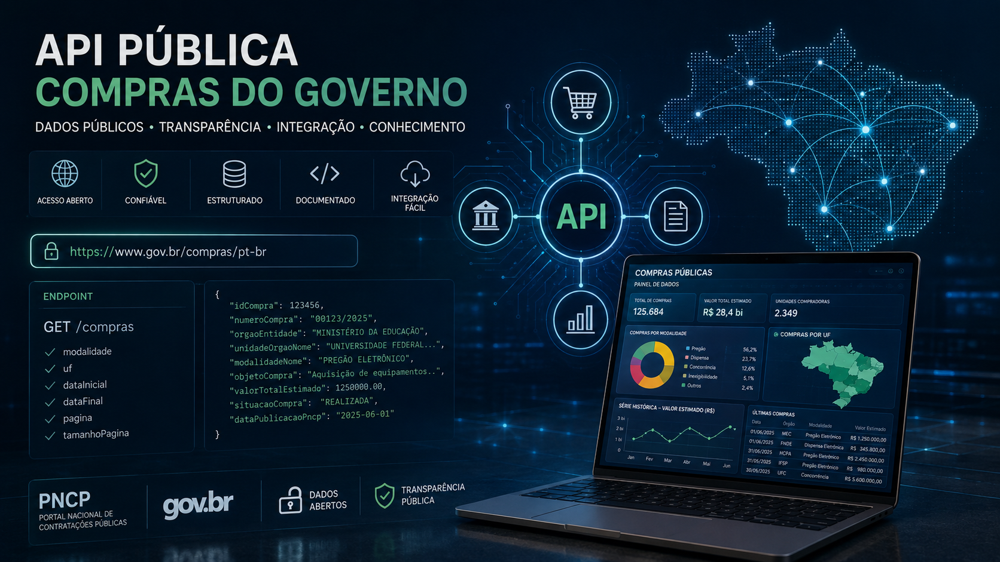

# Consumo da API de Compras Governamentais

## Dados abertos do Compras.gov.br com Python

Nesta atividade, utilizaremos a **API pública de Dados Abertos do Compras.gov.br** para consultar contratações governamentais e organizar os resultados em `DataFrames`.

Documentação oficial:

- Swagger: https://dadosabertos.compras.gov.br/swagger-ui/index.html
- Portal de dados abertos: https://dados.gov.br/dados/conjuntos-dados/compras-publicas-do-governo-federal

A atividade está organizada em duas partes:

1. **prática guiada**, para compreender o consumo da API;
2. **desafio investigativo em duplas**, voltado à exploração dos dados, identificação de padrões e geração de evidências com potencial para produzir novos conhecimentos.

> Os dados são obtidos diretamente de uma API externa. Portanto, disponibilidade, tempo de resposta, quantidade de registros e estrutura de alguns campos podem sofrer alterações ao longo do tempo.


## 1. Objetivos da aula

Ao final da atividade, espera-se que seja possível:

- interpretar a documentação de uma API pública;
- construir requisições HTTP com `requests`;
- utilizar parâmetros de consulta;
- verificar códigos de status HTTP;
- interpretar respostas JSON;
- transformar dados JSON em `DataFrame`;
- tratar paginação;
- realizar análises exploratórias iniciais;
- formular perguntas de pesquisa a partir de dados públicos reais.


## 2. Bibliotecas

Utilizaremos principalmente:

- `requests` para realizar as requisições HTTP;
- `pandas` para organizar e analisar os dados;
- `matplotlib` para visualizações simples.


In [56]:
#%pip install requests pandas matplotlib -q

In [57]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

## 3. Conhecendo a API

A API do Compras.gov.br possui diferentes módulos.

Alguns exemplos:

```text
Catálogo de materiais
Catálogo de serviços
Pesquisa de preços
Contratações
Atas de Registro de Preços
Contratos
Fornecedores
```

Nesta prática utilizaremos principalmente o endpoint:

```text
GET /modulo-contratacoes/1_consultarContratacoes_PNCP_14133
```

Esse serviço consulta contratações realizadas no contexto da Lei nº 14.133/2021. Esta Lei estabelece normas gerais de licitação e contratação para as Administrações Públicas diretas, autárquicas e fundacionais da União, dos Estados, do Distrito Federal e dos Municípios

A URL base será:


In [58]:
BASE_URL = "https://dadosabertos.compras.gov.br"

ENDPOINT_CONTRATACOES = "/modulo-contratacoes/1_consultarContratacoes_PNCP_14133"

url = BASE_URL + ENDPOINT_CONTRATACOES

print(url)

https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133


## 4. Parâmetros da consulta

O endpoint permite utilizar parâmetros para restringir a consulta.

Nesta atividade utilizaremos:

- `pagina`: página desejada;
- `tamanhoPagina`: número de registros por página;
- `dataPublicacaoPncpInicial`: data inicial;
- `dataPublicacaoPncpFinal`: data final;
- `codigoModalidade`: código da modalidade;
- `unidadeOrgaoUfSigla`: UF da unidade compradora, quando desejado.

Para evitar consultas excessivamente grandes durante a aula, começaremos com **10 registros**.

O exemplo abaixo utiliza um intervalo histórico fixo, o que melhora a reprodutibilidade da atividade.


In [59]:
params = {
    "pagina": 1,
    "tamanhoPagina": 10,
    "dataPublicacaoPncpInicial": "2025-05-01",
    "dataPublicacaoPncpFinal": "2025-05-15",
    "codigoModalidade": 5
}

params

{'pagina': 1,
 'tamanhoPagina': 10,
 'dataPublicacaoPncpInicial': '2025-05-01',
 'dataPublicacaoPncpFinal': '2025-05-15',
 'codigoModalidade': 5}

## 5. Primeira requisição

A função `requests.get()` realizará uma requisição HTTP utilizando o método `GET`.

Os parâmetros serão enviados por meio de `params`.


In [60]:
resposta = requests.get(
    url,
    params=params,
    timeout=60
)

print("Status HTTP:", resposta.status_code)
print("URL consultada:", resposta.url)

Status HTTP: 200
URL consultada: https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133?pagina=1&tamanhoPagina=10&dataPublicacaoPncpInicial=2025-05-01&dataPublicacaoPncpFinal=2025-05-15&codigoModalidade=5


## 6. Convertendo a resposta para JSON

A resposta recebida pode ser convertida para um objeto Python utilizando:

```python
resposta.json()
```

In [61]:
dados = resposta.json()

## 7. Localizando os registros retornados

A API normalmente retorna os registros dentro de uma estrutura de paginação.

A função abaixo procura algumas chaves usuais e torna o notebook mais tolerante a pequenas mudanças na estrutura da resposta.


In [62]:
def extrair_registros(json_resposta):
    if isinstance(json_resposta, list):
        return json_resposta

    if not isinstance(json_resposta, dict):
        return []

    for chave in ["resultado", "resultados", "data", "content"]:
        if chave in json_resposta and isinstance(json_resposta[chave], list):
            return json_resposta[chave]

    return []


registros = extrair_registros(dados)

print("Quantidade de registros encontrados:", len(registros))

Quantidade de registros encontrados: 10


## 8. Transformando JSON em DataFrame

O `pd.json_normalize()` é útil quando o JSON possui campos aninhados.

Ele transforma os registros retornados pela API em uma estrutura tabular.


In [63]:
df = pd.json_normalize(registros)

print("Dimensão:", df.shape)

df.head()

Dimensão: (10, 52)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,orgaoSubrogadoEsferaId,orgaoEntidadePoderId,orgaoSubrogadoPoderId,unidadeOrgaoCodigoUnidade,unidadeSubrogadaCodigoUnidade,unidadeOrgaoNomeUnidade,unidadeSubrogadaNomeUnidade,unidadeOrgaoUfSigla,unidadeSubrogadaUfSigla,unidadeOrgaoMunicipioNome,unidadeSubrogadaMunicipioNome,unidadeOrgaoCodigoIbge,unidadeSubrogadaCodigoIbge,numeroCompra,modalidadeIdPncp,codigoModalidade,modalidadeNome,srp,modoDisputaIdPncp,codigoModoDisputa,amparoLegalCodigoPncp,amparoLegalNome,amparoLegalDescricao,informacaoComplementar,processo,objetoCompra,existeResultado,orcamentoSigilosoCodigo,orcamentoSigilosoDescricao,situacaoCompraIdPncp,situacaoCompraNomePncp,tipoInstrumentoConvocatorioCodigoPncp,tipoInstrumentoConvocatorioNome,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida
0,92648305900402025,03643856000173-1-000032/2025,2025,32,03643856000173,None,97067,SERVICO SOCIAL DO COMERCIO - ADMINISTRACAO REGIONAL NO ESTADO DE MINAS GERAIS,None,N,None,N,None,926483,None,SERVICO SOCIAL DO COMERCIO - SESC AR/MG,None,MG,None,BELO HORIZONTE,None,3106200,None,90040,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,004001-07686,Contratação de empresa especializada para serviços de fornecimento e instalação de piso esportivo na quadra poliespo...,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,179474.46,134994.42,2025-05-02T07:15:29,2025-05-02T07:15:29,2025-05-02T07:15:29,2025-05-02T08:00:00,2025-05-16T09:00:00,False
1,51018005900032025,29979036000140-1-000100/2025,2025,100,29979036000140,None,26661,INSTITUTO NACIONAL DO SEGURO SOCIAL,None,F,None,E,None,510180,None,SUPERINTENDENCIA REGIONAL SUDESTE II,None,MG,None,BELO HORIZONTE,None,3106200,None,90003,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,35014096253202481,"Contratação de serviços terceirizados nas áreas administrativas para os postos de Assistente Administrativo, Recepci...",False,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,0.00,NaN,2025-05-02T07:15:34,2025-05-02T07:15:34,2025-05-02T07:15:34,2025-05-02T09:00:00,2025-05-21T10:00:00,False
2,93008805900012025,19481436000178-1-000006/2025,2025,6,19481436000178,None,72415,AGENCIA ESTADUAL DE RECURSOS HIDRICOS - AGERH,None,E,None,E,None,930088,None,EES - AGENCIA ESTADUAL DE RECURSOS HIDRICOS,None,ES,None,VITÓRIA,None,3205309,None,90001,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,2024-5ZHFJ,"Contratação de Serviço de Copeiragem, Conservação e Manutenção Predial com fornecimento de equipamentos e ferramentas.",False,1,Compra sem sigilo,4,Suspensa,1,Edital,Aberto,10131.09,NaN,2025-05-02T07:15:38,2025-05-22T08:55:28,2025-05-02T07:15:38,2025-05-02T08:00:00,2025-05-21T10:00:00,False
3,92670305900802025,26981455000129-1-000078/2025,2025,78,26981455000129,None,23517,AGENCIA MUNICIPAL DE REGULACAO DE SERVICOS DELEGADOS- ARSER,None,M,None,E,None,926703,None,"AG. DE LICIT., CONT. E CONV. DE MACEIO",None,AL,None,MACEIÓ,None,2704302,None,90080,6,5,Pregão - Eletrônico,True,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens

## 9. Conhecendo as variáveis disponíveis

Antes de analisar os dados, precisamos conhecer as colunas retornadas.


In [64]:
for coluna in df.columns:
    print(coluna)

idCompra
numeroControlePNCP
anoCompraPncp
sequencialCompraPncp
orgaoEntidadeCnpj
orgaoSubrogadoCnpj
codigoOrgao
orgaoEntidadeRazaoSocial
orgaoSubrogadoRazaoSocial
orgaoEntidadeEsferaId
orgaoSubrogadoEsferaId
orgaoEntidadePoderId
orgaoSubrogadoPoderId
unidadeOrgaoCodigoUnidade
unidadeSubrogadaCodigoUnidade
unidadeOrgaoNomeUnidade
unidadeSubrogadaNomeUnidade
unidadeOrgaoUfSigla
unidadeSubrogadaUfSigla
unidadeOrgaoMunicipioNome
unidadeSubrogadaMunicipioNome
unidadeOrgaoCodigoIbge
unidadeSubrogadaCodigoIbge
numeroCompra
modalidadeIdPncp
codigoModalidade
modalidadeNome
srp
modoDisputaIdPncp
codigoModoDisputa
amparoLegalCodigoPncp
amparoLegalNome
amparoLegalDescricao
informacaoComplementar
processo
objetoCompra
existeResultado
orcamentoSigilosoCodigo
orcamentoSigilosoDescricao
situacaoCompraIdPncp
situacaoCompraNomePncp
tipoInstrumentoConvocatorioCodigoPncp
tipoInstrumentoConvocatorioNome
modoDisputaNomePncp
valorTotalEstimado
valorTotalHomologado
dataInclusaoPncp
dataAtualizacaoPncp
dataPub

Também é importante conhecer os tipos de dados identificados pelo pandas.


In [65]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 52 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   idCompra                               10 non-null     str    
 1   numeroControlePNCP                     10 non-null     str    
 2   anoCompraPncp                          10 non-null     int64  
 3   sequencialCompraPncp                   10 non-null     int64  
 4   orgaoEntidadeCnpj                      10 non-null     str    
 5   orgaoSubrogadoCnpj                     0 non-null      object 
 6   codigoOrgao                            10 non-null     int64  
 7   orgaoEntidadeRazaoSocial               10 non-null     str    
 8   orgaoSubrogadoRazaoSocial              0 non-null      object 
 9   orgaoEntidadeEsferaId                  10 non-null     str    
 10  orgaoSubrogadoEsferaId                 0 non-null      object 
 11  orgaoEntidadePoderId

## 10. Selecionando algumas informações

Como a API pode receber atualizações, não assumiremos antecipadamente que todas as colunas estarão disponíveis.

A célula abaixo procura campos comuns relacionados à contratação e mostra apenas aqueles encontrados na resposta.


In [66]:
colunas_interesse = [
    "idCompra",
    "numeroCompra",
    "anoCompra",
    "modalidadeNome",
    "modalidadeIdPncp",
    "unidadeOrgao.ufSigla",
    "unidadeOrgao.nomeUnidade",
    "orgaoEntidade.razaoSocial",
    "objetoCompra",
    "valorTotalEstimado",
    "valorTotalHomologado",
    "dataPublicacaoPncp",
    "srp"
]

colunas_existentes = [c for c in colunas_interesse if c in df.columns]

print("Colunas encontradas:")
print(colunas_existentes)

df[colunas_existentes].head() if colunas_existentes else df.head()

Colunas encontradas:
['idCompra', 'numeroCompra', 'modalidadeNome', 'modalidadeIdPncp', 'objetoCompra', 'valorTotalEstimado', 'valorTotalHomologado', 'dataPublicacaoPncp', 'srp']


,idCompra,numeroCompra,modalidadeNome,modalidadeIdPncp,objetoCompra,valorTotalEstimado,valorTotalHomologado,dataPublicacaoPncp,srp
0,92648305900402025,90040,Pregão - Eletrônico,6,Contratação de empresa especializada para serviços de fornecimento e instalação de piso esportivo na quadra poliespo...,179474.46,134994.42,2025-05-02T07:15:29,False
1,51018005900032025,90003,Pregão - Eletrônico,6,"Contratação de serviços terceirizados nas áreas administrativas para os postos de Assistente Administrativo, Recepci...",0.00,NaN,2025-05-02T07:15:34,False
2,93008805900012025,90001,Pregão - Eletrônico,6,"Contratação de Serviço de Copeiragem, Conservação e Manutenção Predial com fornecimento de equipamentos e ferramentas.",10131.09,NaN,2025-05-02T07:15:38,False
3,92670305900802025,90080,Pregão - Eletrônico,6,Registro preços fornecimento utensílios e produtos de limpeza e higienização I (frac PE 90020/2025).,1885845.73,864056.09,2025-05-02T07:15:42,True
4,98013905900422025,90042,Pregão - Eletrônico,6,"Aquisição de material de consumo de água mineral em garrafão de 20L, Gelo em barra, Água mineral em garrafa pet cont...",79607.20,43476.20,2025-05-02T07:15:46,True


## 11. Consultando uma Unidade da Federação

Os parâmetros permitem fazer consultas direcionadas.

Vamos repetir a busca restringindo a consulta ao estado de São Paulo.


In [67]:
params_sp = {
    "pagina": 1,
    "tamanhoPagina": 20,
    "dataPublicacaoPncpInicial": "2025-05-01",
    "dataPublicacaoPncpFinal": "2025-05-15",
    "codigoModalidade": 5,
    "unidadeOrgaoUfSigla": "SP"
}

resposta_sp = requests.get(
    url,
    params=params_sp,
    timeout=60
)

print("Status HTTP:", resposta_sp.status_code)

resposta_sp.raise_for_status()

dados_sp = resposta_sp.json()
registros_sp = extrair_registros(dados_sp)
df_sp = pd.json_normalize(registros_sp)

print("Dimensão:", df_sp.shape)

df_sp.head()

Status HTTP: 200
Dimensão: (20, 52)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,orgaoSubrogadoEsferaId,orgaoEntidadePoderId,orgaoSubrogadoPoderId,unidadeOrgaoCodigoUnidade,unidadeSubrogadaCodigoUnidade,unidadeOrgaoNomeUnidade,unidadeSubrogadaNomeUnidade,unidadeOrgaoUfSigla,unidadeSubrogadaUfSigla,unidadeOrgaoMunicipioNome,unidadeSubrogadaMunicipioNome,unidadeOrgaoCodigoIbge,unidadeSubrogadaCodigoIbge,numeroCompra,modalidadeIdPncp,codigoModalidade,modalidadeNome,srp,modoDisputaIdPncp,codigoModoDisputa,amparoLegalCodigoPncp,amparoLegalNome,amparoLegalDescricao,informacaoComplementar,processo,objetoCompra,existeResultado,orcamentoSigilosoCodigo,orcamentoSigilosoDescricao,situacaoCompraIdPncp,situacaoCompraNomePncp,tipoInstrumentoConvocatorioCodigoPncp,tipoInstrumentoConvocatorioNome,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida
0,92967905900012025,48198725000162-1-000052/2025,2025,52,48198725000162,None,83589,CAMARA MUNICIPAL DE MOGI GUACU,None,M,None,L,None,929679,None,CAMARA MUNICIPAL DE MOJI-GUACU - SP,None,SP,None,MOGI GUAÇU,None,3530706,None,90001,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,De acordo com o Termo de Referência (Anexo I do Edital) Para as respostas de esclarecimentos e impugnações deste edi...,12/2025,Aquisição de microcomputadores para a Câmara Municipal de Mogi Guaçu.,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,293237.06,288069.0,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T08:00:00,2025-05-16T08:30:00,False
1,09013305900682025,46374500000194-1-003439/2025,2025,3439,46374500000194,None,34952,SECRETARIA DE ESTADO DA SAUDE,None,E,None,E,None,090133,None,ESP-DEPTO.REG.SAUDE - DRS-XIV SJBOA VISTA,None,SP,None,SÃO JOÃO DA BOA VISTA,None,3549102,None,90068,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,024.00168997/2024,Insumos Judicial Exclusiva,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,91698.92,7525.4,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T08:00:00,2025-05-16T09:35:00,False
2,18015805900142025,46377800000127-1-001783/2025,2025,1783,46377800000127,None,35311,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,None,E,None,E,None,180158,None,ESP-COM.POL.INT.3(CPI-3-CEL.PAULO M.SERRAT FI,None,SP,None,RIBEIRÃO PRETO,None,3543402,None,90014,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,20250309607,Serviço de manutenção e reparos da sede da 4ª Companhia do Trigésimo Terceiro Batalhão de Polícia Militar do Interio...,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,52245.06,44000.0,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T08:00:00,2025-05-21T09:00:00,False
3,53210105907532025,60747318000162-1-000718/2025,2025,718,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PUBLICO ESTADUAL,None,E,None,E,None,532101,None,ESP-INST. ASSIST. MEDICA SERV. PUB. ESTADUAL,None,SP,None,SÃO PAULO,None,3550308,None,90753,6,5,Pregão - Eletrônico,False,3,3,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,14700002949202528,Contra

## 12. Comparando duas consultas

Agora podemos realizar a mesma consulta para outra UF e comparar a quantidade de registros retornados na amostra.

> Esta comparação ainda **não representa o total de contratações**, pois estamos trabalhando com uma única página da API. Ela serve apenas para praticar consultas parametrizadas.


In [68]:
def consultar_contratacoes_uf(uf, tamanho=20):
    parametros = {
        "pagina": 1,
        "tamanhoPagina": tamanho,
        "dataPublicacaoPncpInicial": "2025-05-01",
        "dataPublicacaoPncpFinal": "2025-05-15",
        "codigoModalidade": 5,
        "unidadeOrgaoUfSigla": uf
    }

    r = requests.get(
        url,
        params=parametros,
        timeout=60
    )

    r.raise_for_status()

    registros = extrair_registros(r.json())

    return pd.json_normalize(registros)


df_rj = consultar_contratacoes_uf("RJ")

print("SP:", len(df_sp))
print("RJ:", len(df_rj))

SP: 20
RJ: 20


## 13. Paginação

Uma consulta pode possuir mais registros do que cabem em uma única resposta.

Nesse caso, precisamos consultar:

```text
página 1
página 2
página 3
...
```

A função abaixo permite coletar um número definido de páginas.

Para preservar os recursos da API durante a aula, utilizaremos poucas páginas.


In [69]:
def coletar_paginas(endpoint, parametros, numero_paginas=3):
    todos = []

    for pagina in range(1, numero_paginas + 1):

        params_pagina = parametros.copy()
        params_pagina["pagina"] = pagina

        resposta = requests.get(
            BASE_URL + endpoint,
            params=params_pagina,
            timeout=60
        )

        resposta.raise_for_status()

        registros = extrair_registros(resposta.json())

        print(f"Página {pagina}: {len(registros)} registros")

        if len(registros) == 0:
            break

        todos.extend(registros)

    return pd.json_normalize(todos)

Vamos coletar três páginas, com 20 registros por página.


In [70]:
params_coleta = {
    "tamanhoPagina": 20,
    "dataPublicacaoPncpInicial": "2025-05-01",
    "dataPublicacaoPncpFinal": "2025-05-15",
    "codigoModalidade": 5,
    "unidadeOrgaoUfSigla": "SP"
}

df_coleta = coletar_paginas(
    ENDPOINT_CONTRATACOES,
    params_coleta,
    numero_paginas=3
)

print("Dimensão final:", df_coleta.shape)

df_coleta.head()

Página 1: 20 registros
Página 2: 20 registros
Página 3: 20 registros
Dimensão final: (60, 52)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,orgaoSubrogadoEsferaId,orgaoEntidadePoderId,orgaoSubrogadoPoderId,unidadeOrgaoCodigoUnidade,unidadeSubrogadaCodigoUnidade,unidadeOrgaoNomeUnidade,unidadeSubrogadaNomeUnidade,unidadeOrgaoUfSigla,unidadeSubrogadaUfSigla,unidadeOrgaoMunicipioNome,unidadeSubrogadaMunicipioNome,unidadeOrgaoCodigoIbge,unidadeSubrogadaCodigoIbge,numeroCompra,modalidadeIdPncp,codigoModalidade,modalidadeNome,srp,modoDisputaIdPncp,codigoModoDisputa,amparoLegalCodigoPncp,amparoLegalNome,amparoLegalDescricao,informacaoComplementar,processo,objetoCompra,existeResultado,orcamentoSigilosoCodigo,orcamentoSigilosoDescricao,situacaoCompraIdPncp,situacaoCompraNomePncp,tipoInstrumentoConvocatorioCodigoPncp,tipoInstrumentoConvocatorioNome,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida
0,92967905900012025,48198725000162-1-000052/2025,2025,52,48198725000162,None,83589,CAMARA MUNICIPAL DE MOGI GUACU,None,M,None,L,None,929679,None,CAMARA MUNICIPAL DE MOJI-GUACU - SP,None,SP,None,MOGI GUAÇU,None,3530706,None,90001,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,De acordo com o Termo de Referência (Anexo I do Edital) Para as respostas de esclarecimentos e impugnações deste edi...,12/2025,Aquisição de microcomputadores para a Câmara Municipal de Mogi Guaçu.,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,293237.06,288069.0,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T08:00:00,2025-05-16T08:30:00,False
1,09013305900682025,46374500000194-1-003439/2025,2025,3439,46374500000194,None,34952,SECRETARIA DE ESTADO DA SAUDE,None,E,None,E,None,090133,None,ESP-DEPTO.REG.SAUDE - DRS-XIV SJBOA VISTA,None,SP,None,SÃO JOÃO DA BOA VISTA,None,3549102,None,90068,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,024.00168997/2024,Insumos Judicial Exclusiva,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,91698.92,7525.4,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T08:00:00,2025-05-16T09:35:00,False
2,18015805900142025,46377800000127-1-001783/2025,2025,1783,46377800000127,None,35311,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,None,E,None,E,None,180158,None,ESP-COM.POL.INT.3(CPI-3-CEL.PAULO M.SERRAT FI,None,SP,None,RIBEIRÃO PRETO,None,3543402,None,90014,6,5,Pregão - Eletrônico,False,1,1,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,20250309607,Serviço de manutenção e reparos da sede da 4ª Companhia do Trigésimo Terceiro Batalhão de Polícia Militar do Interio...,True,1,Compra sem sigilo,1,Divulgada no PNCP,1,Edital,Aberto,52245.06,44000.0,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T08:00:00,2025-05-21T09:00:00,False
3,53210105907532025,60747318000162-1-000718/2025,2025,718,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PUBLICO ESTADUAL,None,E,None,E,None,532101,None,ESP-INST. ASSIST. MEDICA SERV. PUB. ESTADUAL,None,SP,None,SÃO PAULO,None,3550308,None,90753,6,5,Pregão - Eletrônico,False,3,3,1,"Lei 14.133/2021, Art. 28, I",pregão: modalidade de licitação obrigatória para aquisição de bens e serviços comuns,Para as respostas de esclarecimentos e impugnações deste edital acesse o link: https://cnetmobile.estaleiro.serpro....,14700002949202528,Contra

## 14. Verificando duplicidades

Dados obtidos de sistemas reais devem ser avaliados antes da análise.

Uma das primeiras verificações é identificar possíveis duplicidades.


In [71]:
print("Linhas duplicadas completas:", df_coleta.duplicated().sum())

if "idCompra" in df_coleta.columns:
    print("IDs de compra duplicados:", df_coleta["idCompra"].duplicated().sum())

Linhas duplicadas completas: 0
IDs de compra duplicados: 0


## 15. Valores ausentes

Também podemos verificar a presença de dados ausentes.


In [72]:
percentual_ausentes = (
    df_coleta.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

percentual_ausentes.head(15)

orgaoSubrogadoPoderId            100.000000
orgaoSubrogadoEsferaId           100.000000
orgaoSubrogadoRazaoSocial        100.000000
orgaoSubrogadoCnpj               100.000000
unidadeSubrogadaNomeUnidade      100.000000
unidadeSubrogadaUfSigla          100.000000
unidadeSubrogadaCodigoUnidade    100.000000
unidadeSubrogadaMunicipioNome    100.000000
unidadeSubrogadaCodigoIbge       100.000000
valorTotalHomologado              11.666667
sequencialCompraPncp               0.000000
idCompra                           0.000000
orgaoEntidadePoderId               0.000000
orgaoEntidadeEsferaId              0.000000
codigoOrgao                        0.000000
dtype: float64

## 16. Estatística descritiva

Vamos identificar automaticamente as colunas numéricas disponíveis.


In [73]:
colunas_numericas = df_coleta.select_dtypes(include="number").columns.tolist()

print(colunas_numericas)

if colunas_numericas:
    display(df_coleta[colunas_numericas].describe().T)

['anoCompraPncp', 'sequencialCompraPncp', 'codigoOrgao', 'unidadeOrgaoCodigoIbge', 'modalidadeIdPncp', 'codigoModalidade', 'modoDisputaIdPncp', 'codigoModoDisputa', 'amparoLegalCodigoPncp', 'orcamentoSigilosoCodigo', 'situacaoCompraIdPncp', 'tipoInstrumentoConvocatorioCodigoPncp', 'valorTotalEstimado', 'valorTotalHomologado']


,count,mean,std,min,25%,50%,75%,max
anoCompraPncp,60.0,2.025000e+03,0.000000e+00,2025.0,2025.00,2025.00,2.025000e+03,2025.0
sequencialCompraPncp,60.0,1.538767e+03,1.274049e+03,8.0,264.75,1784.50,1.846250e+03,3654.0
codigoOrgao,60.0,5.047618e+04,2.071273e+04,34433.0,34952.00,42434.00,6.985600e+04,96060.0
unidadeOrgaoCodigoIbge,60.0,3.539079e+06,1.719103e+04,3501608.0,3530280.75,3549904.00,3.550308e+06,3556305.0
modalidadeIdPncp,60.0,6.000000e+00,0.000000e+00,6.0,6.00,6.00,6.000000e+00,6.0
codigoModalidade,60.0,5.000000e+00,0.000000e+00,5.0,5.00,5.00,5.000000e+00,5.0
modoDisputaIdPncp,60.0,1.600000e+00,9.242496e-01,1.0,1.00,1.00,3.000000e+00,3.0
codigoModoDisputa,60.0,1.600000e+00,9.242496e-01,1.0,1.00,1.00,3.000000e+00,3.0
amparoLegalCodigoPncp,60.0,1.000000e+00,0.000000e+00,1.0,1.00,1.00,1.000000e+00,1.0
orcamentoSigilosoCodigo,60.0,1.000000e+00,0.000000e+00,1.0,1.00,1.00,1.000000e+00,1.0


## 17. Explorando modalidades ou órgãos

Se a coluna estiver disponível, podemos calcular frequências.


In [74]:
possiveis_categorias = [
    "modalidadeNome",
    "unidadeOrgao.ufSigla",
    "unidadeOrgao.nomeUnidade",
    "orgaoEntidade.razaoSocial"
]

for coluna in possiveis_categorias:
    if coluna in df_coleta.columns:
        print(f"\n{coluna}")
        display(df_coleta[coluna].value_counts(dropna=False).head(10))


modalidadeNome


modalidadeNome
Pregão - Eletrônico    60
Name: count, dtype: int64

## 18. Visualização simples

O exemplo abaixo cria um gráfico somente se uma coluna categórica adequada estiver disponível.


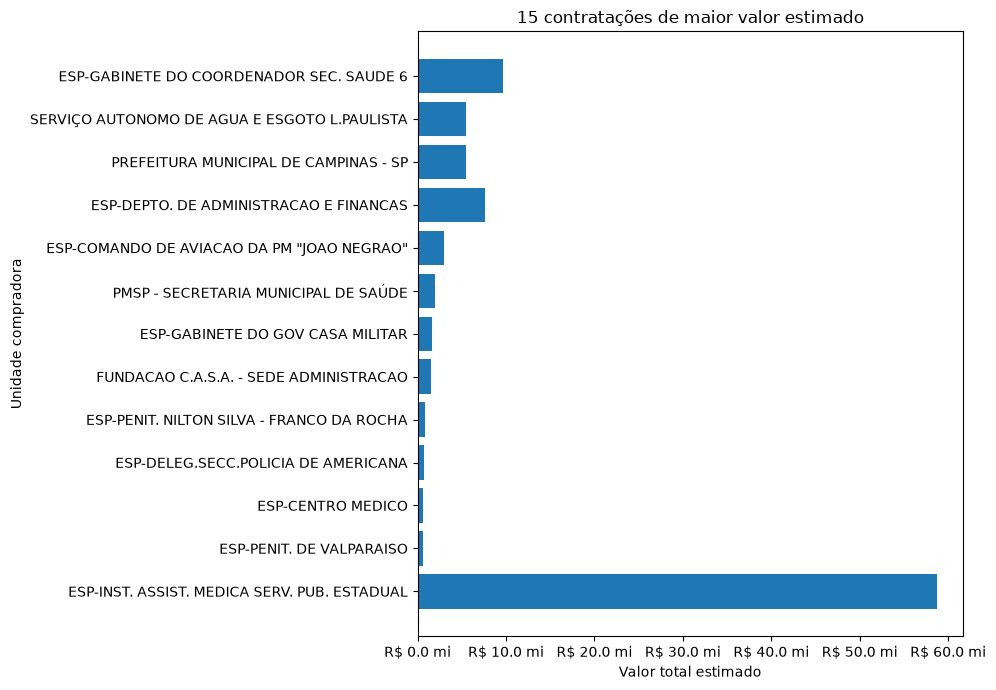

In [75]:
from matplotlib.ticker import FuncFormatter

# Seleciona as colunas necessárias
df_grafico = df_coleta[
    ["unidadeOrgaoNomeUnidade", "valorTotalEstimado"]
].copy()

# Converte o valor estimado para formato numérico
df_grafico["valorTotalEstimado"] = pd.to_numeric(
    df_grafico["valorTotalEstimado"],
    errors="coerce"
)

# Remove valores ausentes
df_grafico = df_grafico.dropna()

# Mantém apenas contratações com valor positivo
df_grafico = df_grafico[
    df_grafico["valorTotalEstimado"] > 0
]

# Seleciona as 15 contratações de maior valor
df_grafico = df_grafico.nlargest(
    15,
    "valorTotalEstimado"
)

# Ordena para melhorar a visualização
df_grafico = df_grafico.sort_values(
    "valorTotalEstimado"
)

# Cria o gráfico
plt.figure(figsize=(10, 7))

plt.barh(
    df_grafico["unidadeOrgaoNomeUnidade"],
    df_grafico["valorTotalEstimado"]
)

# Formata o eixo em milhões de reais
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"R$ {x/1_000_000:.1f} mi")
)

plt.xlabel("Valor total estimado")
plt.ylabel("Unidade compradora")
plt.title("15 contratações de maior valor estimado")

plt.tight_layout()
plt.show()

# 19. Pesquisa de preços de materiais

Outro módulo relevante da API é a **Pesquisa de Preços**.

Endpoint:

```text
GET /modulo-pesquisa-preco/1_consultarMaterial
```

Esse módulo permite estudar preços praticados nas compras públicas para itens do catálogo CATMAT.

A documentação da API deve ser consultada antes da execução, pois a assinatura desse endpoint pode sofrer alterações.

Uma aplicação possível é comparar:

```text
preços entre estados
preços entre órgãos
dispersão de preços
evolução temporal
fornecedores
quantidades adquiridas
```

Um código CATMAT pode ser localizado utilizando o Catálogo de Compras:

https://catalogo.compras.gov.br/cnbs-web/busca


## 20. Função auxiliar para inspeção de qualquer endpoint

Antes de construir uma análise, é recomendável executar uma pequena consulta e inspecionar a resposta.

A função abaixo recebe um endpoint e seus parâmetros.


In [76]:
def consultar_api(endpoint, params=None):
    resposta = requests.get(
        BASE_URL + endpoint,
        params=params,
        timeout=60
    )

    print("Status HTTP:", resposta.status_code)
    print("URL:", resposta.url)

    resposta.raise_for_status()

    dados = resposta.json()
    registros = extrair_registros(dados)

    print("Registros encontrados:", len(registros))

    return dados, pd.json_normalize(registros)

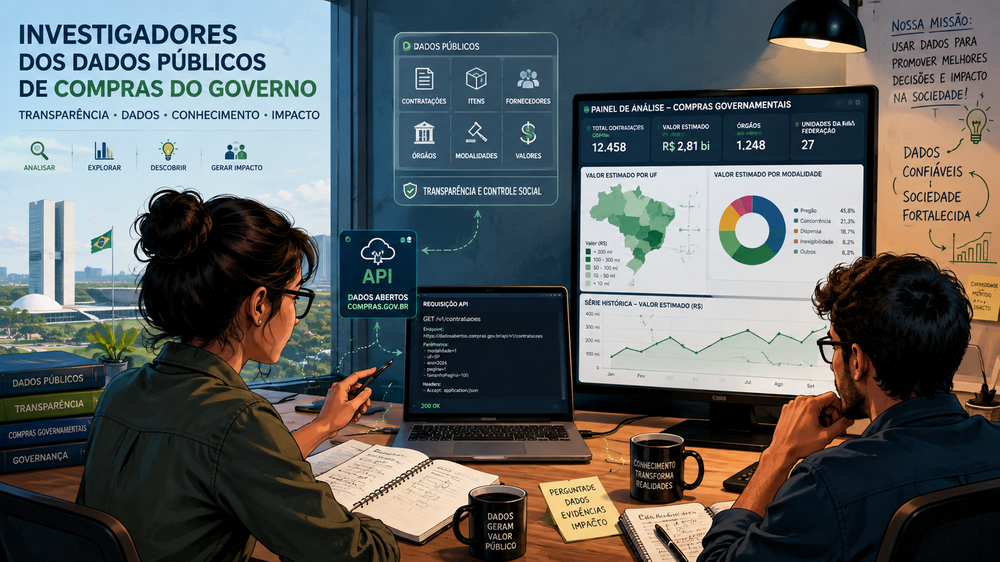
# Desafio em duplas: 


Cada dupla deverá escolher **um dos desafios** abaixo.

O objetivo não é apenas produzir gráficos. A dupla deverá transformar o tema escolhido em uma **investigação estruturada**, documentando:

1. pergunta de pesquisa;
2. justificativa;
3. hipótese ou expectativa inicial;
4. período analisado;
5. filtros utilizados na API;
6. variáveis selecionadas;
7. critérios de limpeza dos dados;
8. análise descritiva;
9. pelo menos uma comparação quantitativa;
10. interpretação dos resultados;
11. limitações;
12. conclusão.

A coleta deve ser **reprodutível**: os parâmetros utilizados na API precisam estar registrados no notebook.


## Desafio A — Compras públicas e diferenças regionais

### Problema

A distribuição das contratações públicas apresenta diferenças entre as Unidades da Federação?

### Possíveis perguntas

- A quantidade de contratações difere entre estados?
- Os valores das contratações apresentam distribuições diferentes?
- Existem estados com maior concentração de determinadas modalidades?

### Estratégia sugerida

Escolher de 3 a 5 UFs, manter o mesmo período e a mesma modalidade e comparar os resultados.

### Possíveis análises

- frequências;
- mediana e média;
- boxplots;
- coeficiente de variação;
- teste de Kruskal-Wallis ou ANOVA, quando os pressupostos forem adequados.


## Desafio B — Evolução temporal das contratações

### Problema

Existe variação temporal no volume ou no valor das contratações governamentais?

### Possíveis perguntas

- Determinados meses apresentam maior quantidade de contratações?
- Existe tendência de aumento ou redução ao longo do período?
- Há sazonalidade próxima ao final do exercício?

### Estratégia sugerida

Coletar dados de vários meses utilizando janelas temporais equivalentes.

### Possíveis análises

- série temporal;
- agregação mensal;
- média móvel;
- comparação entre meses;
- tendência linear exploratória.


## Desafio C — Modalidades de contratação

### Problema

As características das compras diferem entre modalidades de contratação?

### Possíveis perguntas

- Os valores estimados diferem entre modalidades?
- Algumas modalidades apresentam maior frequência em determinados órgãos?
- Existe associação entre modalidade e utilização de Sistema de Registro de Preços?

### Possíveis análises

- tabelas de contingência;
- proporções;
- teste qui-quadrado;
- comparação de distribuições de valores.


## Desafio D — Sistema de Registro de Preços

### Problema

Quais características diferenciam contratações realizadas com e sem Sistema de Registro de Preços?

### Possíveis perguntas

- O SRP é mais frequente em determinados tipos de contratação?
- Existem diferenças nos valores das contratações?
- Determinados órgãos utilizam SRP proporcionalmente mais do que outros?

### Variável de interesse

Quando disponível:

```text
srp
```

### Possíveis análises

- proporções;
- tabelas cruzadas;
- comparação de valores;
- teste qui-quadrado.


## Desafio E — Concentração das compras por órgão

### Problema

As contratações estão distribuídas entre muitos órgãos ou concentradas em poucos compradores?

### Possíveis perguntas

- Quais órgãos concentram maior quantidade de contratações?
- Qual percentual das compras está associado aos dez principais órgãos?
- A concentração muda entre períodos?

### Possíveis análises

- ranking;
- participação percentual;
- curva de Pareto;
- índice de concentração;
- comparação temporal.


## Desafio F — Análise textual dos objetos das contratações

### Problema

Quais temas aparecem com maior frequência nas descrições dos objetos das compras governamentais?

### Campo de interesse

Quando disponível:

```text
objetoCompra
```

### Possíveis análises

- frequência de palavras;
- bigramas;
- categorias definidas pela dupla;
- comparação entre órgãos ou períodos;
- identificação de temas recorrentes.

> O tratamento textual deve documentar remoção de pontuação, normalização, stopwords e demais decisões de pré-processamento.


## Desafio G — Dispersão de preços de um mesmo material

### Problema

Um mesmo material apresenta diferenças relevantes de preço nas compras governamentais?

### Estratégia

1. escolher um item no catálogo CATMAT;
2. identificar seu código;
3. utilizar o módulo de Pesquisa de Preços;
4. coletar compras comparáveis;
5. analisar a distribuição dos preços unitários.

### Possíveis perguntas

- O preço varia entre estados?
- Existem valores extremos?
- O preço apresenta relação com a quantidade comprada?
- Há diferença de preço entre períodos?

### Possíveis análises

- média;
- mediana;
- desvio padrão;
- intervalo interquartil;
- boxplot;
- correlação entre quantidade e preço;
- regressão exploratória.


## Desafio H — Fornecedores e concentração de mercado

### Problema

As compras de determinado item ou conjunto de contratações estão concentradas em poucos fornecedores?

### Estratégia

Utilizar os módulos de resultados de itens, fornecedores ou pesquisa de preços, conforme os campos disponíveis.

### Possíveis perguntas

- Quantos fornecedores participam do conjunto analisado?
- Qual a participação dos principais fornecedores?
- Existe concentração elevada?

### Possíveis análises

- ranking de fornecedores;
- participação percentual;
- curva de Pareto;
- índice Herfindahl-Hirschman (HHI), quando houver uma variável adequada de participação.

> A dupla deverá verificar na documentação quais endpoints fornecem as informações necessárias antes de definir definitivamente o desenho do estudo.


# Critérios para escolha do desafio

Antes de iniciar a coleta completa, a dupla deverá executar uma **consulta piloto**.

A consulta piloto deve responder:

- o endpoint está disponível?
- os campos necessários estão presentes?
- existe quantidade suficiente de registros?
- há muitos valores ausentes?
- a unidade de análise está clara?
- é possível reproduzir a consulta?

Somente depois dessa verificação a coleta principal deve ser realizada.


# Estrutura mínima do notebook da dupla

O notebook entregue deverá possuir:

```text
1. Título provisório
2. Problema de pesquisa
3. Pergunta de pesquisa
4. Hipótese
5. Fonte dos dados
6. Endpoint(s) utilizado(s)
7. Parâmetros da API
8. Período analisado
9. Código de coleta
10. Construção do DataFrame
11. Avaliação da qualidade dos dados
12. Limpeza
13. Estatística descritiva
14. Visualizações
15. Comparação quantitativa
16. Discussão
17. Limitações
18. Conclusão
```


# Proposta de estrutura para o artigo científico

A análise desenvolvida poderá ser transformada em um artigo curto.

## Título

Deve comunicar claramente:

```text
fenômeno + população/contexto + abordagem
```

## Introdução

Apresentar:

- contexto das compras públicas;
- problema;
- relevância;
- lacuna ou questão investigada;
- objetivo do estudo.

## Metodologia

Descrever:

- fonte dos dados;
- API e endpoints;
- data da coleta;
- período analisado;
- filtros;
- critérios de inclusão e exclusão;
- tratamento dos dados;
- métodos estatísticos.

## Resultados

Apresentar:

- tamanho da amostra;
- estatísticas descritivas;
- tabelas;
- gráficos;
- comparações.

## Discussão

Interpretar os resultados e relacioná-los ao problema proposto.

## Limitações

Discutir, por exemplo:

- cobertura da API;
- dados ausentes;
- alterações na base;
- duplicidades;
- diferenças de cadastramento;
- impossibilidade de inferir causalidade em estudos observacionais.

## Conclusão

Responder diretamente à pergunta de pesquisa.


# Checklist metodológico

Antes de considerar a análise concluída, verifique:

- [ ] A pergunta de pesquisa está claramente definida?
- [ ] O endpoint utilizado está registrado?
- [ ] Todos os parâmetros da API foram documentados?
- [ ] A data da coleta foi registrada?
- [ ] A unidade de análise está definida?
- [ ] Foram verificadas duplicidades?
- [ ] Foram avaliados valores ausentes?
- [ ] Variáveis numéricas foram convertidas corretamente?
- [ ] Datas foram convertidas para `datetime`?
- [ ] Valores extremos foram investigados?
- [ ] As comparações possuem justificativa?
- [ ] As conclusões são compatíveis com os dados?
- [ ] As limitações foram explicitadas?


# Cuidados com interpretação

Dados administrativos são produzidos para apoiar processos operacionais e administrativos. Eles não são originalmente coletados como um experimento científico.

Portanto:

```text
associação ≠ causalidade
```

Encontrar diferença de preços entre estados, por exemplo, não permite concluir automaticamente que a localização **causou** essa diferença.

Outros fatores podem estar envolvidos:

- quantidade adquirida;
- especificação do item;
- logística;
- fornecedor;
- período;
- modalidade;
- urgência;
- características do órgão.

Esses fatores devem ser considerados na interpretação.


# Boas práticas no consumo da API

Durante o projeto:

- evite realizar centenas de requisições desnecessárias;
- utilize filtros temporais;
- use paginação controlada;
- salve localmente os dados coletados para não consultar repetidamente a API;
- registre a data da coleta;
- preserve uma cópia dos dados brutos utilizados no estudo;
- não trate ausência de resposta da API como ausência real de contratações;
- valide resultados inesperados antes de interpretá-los.

Uma boa prática é separar:

```text
coleta → dados brutos → tratamento → dados analisados
```
